# SOBUSA · Entregable 2 — Notebook unificado (continuación del Entregable 1)

Implementación del Entregable 2 en un solo archivo, los 18 notebooks del proyecto en orden, con sus celdas de texto, código, salidas y figuras tal como se ejecutaron. Los Módulos 11 y 14 no tenían notebook (sus resultados estaban en `.md` y `.csv`): para esta entrega se crearon y ejecutaron el 16-nov-2026 (cargan sus resultados, muestran tablas y figuras y corren sus pruebas: 11/11, 7/7, 7/7 y 20/20, 10/10, 9/9).

**Cómo se ejecutó cada parte:** cada notebook corre desde su propia carpeta (`moduloN/`) dentro de `Sobusa/`, con los datos del Entregable 1 en la carpeta padre. Las celdas de «Parte 1 · extracción» que consultan la base de SOBUSA (contraseña con `getpass`) o una API de pago no tienen salida cuando su resultado ya estaba guardado: ninguna parte vuelve a llamar a una API.

| Parte | Contenido | Notebook original |
|---|---|---|
| 1 | Corrección del Entregable 1 (e1c): sin `tendencia_meses`, con receso escolar | `subfase_e1c_correccion.ipynb` |
| 2 | Módulo 9 · Fiabilidad vehicular y scoring de riesgo del conductor | `modulo9/modulo_9_fiabilidad_scoring.ipynb` |
| 3 | Módulo 10 · Subfase 10.1 · Red vial | `modulo10/subfase_10_1_red_vial.ipynb` |
| 4 | Módulo 10 · Subfase 10.2 · Protocolo y contrato del evento | `modulo10/subfase_10_2_protocolo.ipynb` |
| 5 | Módulo 10 · Subfase 10.3 · Set de prueba | `modulo10/subfase_10_3_set.ipynb` |
| 6 | Módulo 10 · Subfase 10.4 · Audio → texto (Whisper) | `modulo10/subfase_10_4_audio.ipynb` |
| 7 | Módulo 10 · Subfase 10.5 · Extracción con Claude | `modulo10/subfase_10_5_extraccion.ipynb` |
| 8 | Módulo 10 · Subfase 10.6 · Servicio y entrega | `modulo10/subfase_10_6_servicio.ipynb` |
| 9 | Módulo 11 · Tráfico externo con Google Routes API | `modulo11/modulo_11_resultados.ipynb` |
| 10 | Módulo 12 · Reenrutamiento dinámico ante disrupciones | `modulo12/modulo_12_reenrutamiento.ipynb` |
| 11 | Módulo 13 · Subfase 13.1 · Parámetros | `modulo13/subfase_13_1_parametros.ipynb` |
| 12 | Módulo 13 · Subfase 13.2 · Motor de simulación | `modulo13/subfase_13_2_motor.ipynb` |
| 13 | Módulo 13 · Subfase 13.3 · Imprevistos | `modulo13/subfase_13_3_imprevistos.ipynb` |
| 14 | Módulo 13 · Subfase 13.4 · Monte Carlo | `modulo13/subfase_13_4_montecarlo.ipynb` |
| 15 | Módulo 13 · Subfase 13.4b · Mejoras | `modulo13/subfase_13_4b_mejoras.ipynb` |
| 16 | Módulo 13 · Subfase 13.5 · Gemelo digital | `modulo13/subfase_13_5_gemelo.ipynb` |
| 17 | Módulo 13 · Subfase 13.6 · Cierre | `modulo13/subfase_13_6_cierre.ipynb` |
| 18 | Módulo 14 · Redespacho dinámico de flota (MILP) | `modulo14/modulo_14_redespacho.ipynb` |


---
# Parte 1 · Corrección del Entregable 1 (e1c): sin `tendencia_meses`, con receso escolar
*Notebook original: `subfase_e1c_correccion.ipynb`*

# SOBUSA · Corrección del Entregable 1 (e1c) — `tendencia_meses`

**Persona 3 · MLOps & Model Evaluation.** Crítica de la calificación (4,7/5): *«la tendencia monótona fuera de rango es un error de diseño de una feature que se diagnostica pero no se resuelve»*. Este notebook documenta cómo se resolvió, **sin reentrenar nada**: lee las salidas de `validacion_e1c.py` (decisión con 2023–2024) y `holdout_e1c.py` (evaluación única de 2025), ambos ejecutados en el PC de la Persona 3.

| Elemento | Decisión |
|---|---|
| Cambio | Quitar `tendencia_meses` de los 3 modelos (B) y probar como único reemplazo el **receso escolar oficial** (Rb binario; R por tipo) |
| Insumo nuevo | `datos_e2/calendario_escolar_barranquilla_2023_2025.csv` (resoluciones 06040/2022, 06182/2023, 07036/2024 y 07248/2025; colegios oficiales; incluye 2026) |
| Sin cambios | Hiperparámetros de la 7.2, rondas de la 7.3 (311 / 649 / 461), sin Optuna |
| Regla | `regla_correccion_e1c.json`, **congelada con hash antes de correr** (consejo asesor `consejo_tendencia/`, opción Q) |
| Validación | Solo 2023–2024: 4 diseños (escenario 2023→2024, walk-forward, origen rodante, corte de junio) × 6 corridas (3 semillas × 2 órdenes de filas) |
| 2025 | Una sola evaluación de la variante elegida, rotulada **no ciega**; las cifras oficiales de la 7.3 no se tocan |

**Parte 1 (extracción RDS): no aplica.**

## Parte 2 · Análisis offline

In [1]:
import hashlib
import json
import platform
from pathlib import Path
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

import tests_e1c as T
import validacion_e1c as VE

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
D = Path("datos_e1c"); FIG = Path("resultados_e1c"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
def check(nombre: str, ok: bool, detalle: str = "") -> None:
    CHECKS.append({"check": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": detalle})

regla = VE.cargar_regla()                       # verifica el hash de la regla y de sus insumos
dec = json.loads((D / "decision_e1c.json").read_text(encoding="utf-8"))
t = pd.read_csv(D / "validacion_e1c_corridas.csv")
alc = pd.read_csv(D / "alcance_e1c.csv")
h = pd.read_csv(D / "holdout_e1c.csv").set_index("config")
des = pd.read_csv(D / "holdout_e1c_desgloses.csv")
COL = {"linea_base": "#898781", "7_3": "#eb6834", "e1c": "#2a78d6", "texto": "#0b0b0b", "texto2": "#52514e", "grid": "#e9e8e2"}
def estilo(ax):
    ax.spines[["top", "right"]].set_visible(False); ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors=COL["texto2"], labelsize=9); ax.grid(axis="y", color=COL["grid"], lw=0.8); ax.set_axisbelow(True)
pct = lambda x: f"{x * 100:+.2f} %".replace(".", ",").replace("-", "−")
print(f"Python {platform.python_version()} · regla {regla['sha256_regla'][:12]}… · decisión del {dec['fecha_ejecucion']} · elegida: {dec['elegida']}")

Python 3.9.25 · regla 428e0932728a… · decisión del 2026-10-23T21:27:08 · elegida: Rb


## 1 · El defecto se reproduce sin 2025

In [2]:
# Rango de tendencia_meses en la walk-forward de 2024 (corrige CLAUDE.md §12 y el expediente del consejo)
f = pd.read_parquet("datos_6/features_6_1.parquet", columns=["fechasalida", "tendencia_meses"])
f = f[f.fechasalida < "2025-01-01"]
filas = []
for c in regla["entrenamiento"]["cortes"]:
    c = pd.Timestamp(c); fin = c + pd.DateOffset(months=2)
    tr = f[(f.fechasalida >= "2023-01-29") & (f.fechasalida < c)].tendencia_meses
    va = f[(f.fechasalida >= c) & (f.fechasalida < fin)].tendencia_meses
    filas.append({"corte": c.date(), "max_entrenamiento": round(tr.max(), 2), "validacion": f"{va.min():.2f}–{va.max():.2f}",
                  "% validación fuera de rango": round(100 * (va > tr.max()).mean(), 1)})
rango = pd.DataFrame(filas); display(rango)
e0 = t[(t.diseno == "escenario") & (t.variante == "V0")]
print(f"Modelo original entrenado solo con 2023, evaluado en 2024 (6 corridas): dom/laboral predicho "
      f"{e0.domlab_pred.min():.3f}–{e0.domlab_pred.max():.3f} frente a {e0.domlab_real.iloc[0]:.3f} real; "
      f"sesgo laboral {e0.sesgo_laboral.mean():+.2f}, domingo {e0.sesgo_domingo.mean():+.2f}, madrugada laboral 04–05 h {e0.sesgo_lab_04_05.mean():+.2f}")
print(f"En 2025 (7.3): dom/laboral predicho {h.loc['7_3_modelo_0400', 'domlab_pred']:.3f} frente a {h.loc['7_3_modelo_0400', 'domlab_real']:.3f}")
check("2024 reproduce la compresión de 2025 (V0 dom/lab − real > 0,10 en las 6 corridas)",
      bool(((e0.domlab_pred - e0.domlab_real) > 0.10).all()), f"{e0.domlab_pred.min():.3f}–{e0.domlab_pred.max():.3f} vs {e0.domlab_real.iloc[0]:.3f}")
check("la walk-forward 2024 ya extrapolaba (100 % fuera de rango en los 6 pliegues)", bool((rango["% validación fuera de rango"] == 100).all()))

,corte,max_entrenamiento,validacion,% validación fuera de rango
0,2024-01-01,11.970000,12.00–13.97,100.0
1,2024-03-01,13.970000,14.00–15.97,100.0
2,2024-05-01,15.970000,16.00–17.97,100.0
3,2024-07-01,17.969999,18.00–19.97,100.0
4,2024-09-01,19.969999,20.00–21.97,100.0
5,2024-11-01,21.969999,22.00–23.97,100.0


Modelo original entrenado solo con 2023, evaluado en 2024 (6 corridas): dom/laboral predicho 0.837–0.857 frente a 0.668 real; sesgo laboral -6.51, domingo +10.67, madrugada laboral 04–05 h -15.95
En 2025 (7.3): dom/laboral predicho 0.842 frente a 0.671


**Conclusión 1 · El defecto se podía ver con 2024**
- **Corrección explícita** de CLAUDE.md §12 y del expediente del consejo. Decían que la walk-forward de 2024 no detectó el problema «porque la tendencia siempre caía dentro del rango visto», y es falso.
  - En los 6 pliegues, el **100 %** de la validación tiene `tendencia_meses` por encima del máximo de entrenamiento (por ejemplo, 11,97 frente a 12,00–13,97).
  - La extrapolación era de 1–3 meses y el borde nunca era diciembre (el early stopping de la 7.2 dejaba fuera las últimas 4 semanas). En 2025 fue de 12 meses desde un borde en diciembre.
- **El modelo original de las 04:00, entrenado solo con 2023 y evaluado en 2024, repite la falla de 2025:**
  - dom/laboral predicho **0,837–0,857** frente a **0,668** real (en 2025: 0,842 frente a 0,671), en las 6 corridas;
  - sesgo laboral −6,51, domingo +10,67 y madrugada laboral (04–05 h) −15,95 pas./viaje.
- Como la falla se reproduce sin 2025, la corrección pudo decidirse sin volver a mirar el holdout.

## 2 · Regla congelada y pruebas

In [3]:
print("Hash de la regla:", regla["sha256_regla"])
print("Historial:", *regla["historial"], sep="\n  ")
print("Variantes:", json.dumps(regla["variantes"], ensure_ascii=False, indent=1))
print("Excluidas antes de correr:", json.dumps(regla["excluidas"], ensure_ascii=False, indent=1))
print("Paso 2 · A:", regla["paso_2_Rb_vs_B"]["A_senal_estadistica_en_cada_diseno"])
print("Paso 2 · B:", regla["paso_2_Rb_vs_B"]["B_sesgo_frente_a_B_en_cada_diseno (medias de las 6 corridas)"])
tt = T.correr_todos(); display(tt)
check("tests_e1c.py", bool((tt.resultado == "PASS").all()), f"{int((tt.resultado == 'PASS').sum())}/{len(tt)} PASS")
check("decisión oficial, con la regla congelada", (not dec["prueba_de_humo"]) and dec["sha256_regla"] == regla["sha256_regla"])
for m, cols in dec["variables_por_modelo"].items():
    check(f"variables de {m} = hash de la decisión", hashlib.sha256(json.dumps(cols).encode()).hexdigest() == dec["sha256_variables_por_modelo"][m])

Hash de la regla: 428e0932728aa75ec5c171243ecc490de7fa45e5105bd62ab9f6a7574491e56e
Historial:
  2026-10-23: congelada antes de correr la validación
  2026-10-23 (antes de cualquier corrida oficial): los hashes de insumos pasan de bytes a contenido, para que coincidan en Windows y Linux; ningún umbral ni condición cambió
Variantes: {
 "V0": "variables actuales del modelo (con tendencia_meses)",
 "B": "V0 sin tendencia_meses",
 "Rb": "B + receso (indicadora 0/1 del calendario escolar oficial)",
 "R": "B + receso_tipo (categórica cerrada: 0 lectivo, 1 inicio de año, 2 Semana Santa, 3 mitad de año, 4 octubre, 5 fin de año)"
}
Excluidas antes de correr: {
 "mes_del_anio": "no aporta sobre B (−0,04 %) y sobrepredice enero (ADDENDUM-01A ítem 3, 01B ítem 21)",
 "semana_santa_sola": "signo mixto, dentro del ruido (01B ítem 20); la Semana Santa escolar ya está dentro del receso"
}
Paso 2 · A: ['Δk < 0 en las 6 corridas', 'media(Δ) <= −2 × desviación estándar(Δ) (ddof = 1)', '|media(Δ)| > rango_b

,check,resultado,detalle
0,Test a · calendario escolar correcto,PASS,"8 fechas de control correctas · días de receso por año calendario {2023: 84, 2024: 86} · 30–31 dic 2024 = inicio de ..."
1,Test b · cobertura con fallo explícito,PASS,cobertura 2023-01-01 … 2026-12-27; 2026-12-28 y 2022-12-31 fallan con CoberturaCalendarioError
2,Test c · tabla inválida rechazada,PASS,tipo fuera de la lista cerrada y periodo con semanas que no cuadran con sus fechas: rechazados
3,Test d · regla congelada con hash,PASS,"hash 428e0932728a… verificado (también hiperparámetros, listas y calendario 2023–2024); copia alterada rechazada"
4,Test e · lógica de decisión (casos sintéticos),PASS,receso claro → Rb · receso + tipo claro → R · una corrida en contra → B · efecto dentro del ruido → B · empeora la m...
5,Test f · la decisión no se sobrescribe,PASS,con decisión previa: se niega · con holdout_e1c.csv presente: se niega
6,Test g · columnas por variante,PASS,modelo_0400: 33/32/33/33 · modelo_intradia: 45/44/45/45 · modelo_oraculo: 53/52/53/53


**Conclusión 2 · La regla se fijó antes de correr y no cambió**
- **`regla_correccion_e1c.json`**, hash `428e0932…`. Se verificó al cargar, junto con los hiperparámetros, las listas de variables y las filas 2023–2024 del calendario escolar.
  - Único cambio registrado, antes de cualquier corrida oficial: los hashes de los insumos pasaron de bytes a contenido, para que coincidieran en Windows y Linux. Ningún umbral cambió.
- **Criterio estadístico** para que el receso entre (en cada uno de los 4 diseños):
  - gana en las 6 corridas pareadas;
  - su mejora media es ≥ 2 desviaciones estándar de la diferencia entre corridas;
  - y supera el rango de B entre corridas.
- **Tolerancias de sesgo:** madrugada laboral, tipo de día, contraste domingo/laboral, sesgo global ≤ +1,5, febrero y agosto.
- **Descartados antes de correr:** el mes del año y la Semana Santa sola (no aportaban sobre B en el consejo).
- `tests_e1c.py`: **7/7 PASS**. La decisión es oficial (no de prueba) y las listas de variables de los 3 modelos coinciden con sus hashes.

## 3 · Validación con 2023–2024: pasos 1 y 2

,diseño,B vs actual (media Δ),B gana,receso vs B (media Δ),sd Δ,rango de B,receso gana 6/6,A cumple,sesgos cumplen
0,escenario,"−10,92 %",6/6,"−0,97 %","0,14 %","0,40 %",True,True,True
1,walk_forward,"−3,14 %",6/6,"−0,85 %","0,13 %","0,19 %",True,True,True
2,origen_rodante,"−3,40 %",6/6,"−1,20 %","0,16 %","0,21 %",True,True,True
3,corte_junio,"−3,09 %",6/6,"−1,27 %","0,46 %","0,64 %",True,True,True


Paso 1: {'escenario_B_gana_todas': True, 'escenario_domlab_mejor': True, 'walk_forward_no_peor': True, 'media_delta_escenario': -0.10921113977535861, 'cumple': True}


,,dev,domlab_pred,domlab_real,sesgo_global,sesgo_laboral,sesgo_domingo,sesgo_lab_04_05,sesgo_lab_06_08,sesgo_lab_feb,sesgo_lab_ago
diseno,variante,,,,,,,,,,
corte_junio,V0,2.554,0.732,0.681,-2.563,-3.393,2.166,-1.217,-1.580,NaN,-7.343
escenario,V0,2.680,0.846,0.668,-3.491,-6.513,10.668,-15.946,-7.863,-12.621,-10.267
origen_rodante,V0,2.566,0.695,0.680,0.385,0.291,1.287,0.666,0.012,-12.621,-4.970
walk_forward,V0,2.457,0.691,0.668,0.128,-0.311,1.894,-1.542,-0.618,-12.621,-7.343
corte_junio,B,2.475,0.685,0.681,0.209,0.589,0.778,1.118,1.511,NaN,-3.004
escenario,B,2.387,0.692,0.668,0.945,0.868,2.733,-0.880,0.601,-3.999,-2.642
origen_rodante,B,2.478,0.681,0.680,0.670,0.950,0.709,1.855,0.767,-3.999,-2.831
walk_forward,B,2.379,0.682,0.668,0.558,0.535,1.619,-0.263,0.415,-3.999,-3.004
corte_junio,Rb,2.444,0.684,0.681,0.424,0.816,0.857,0.951,1.657,NaN,-1.874


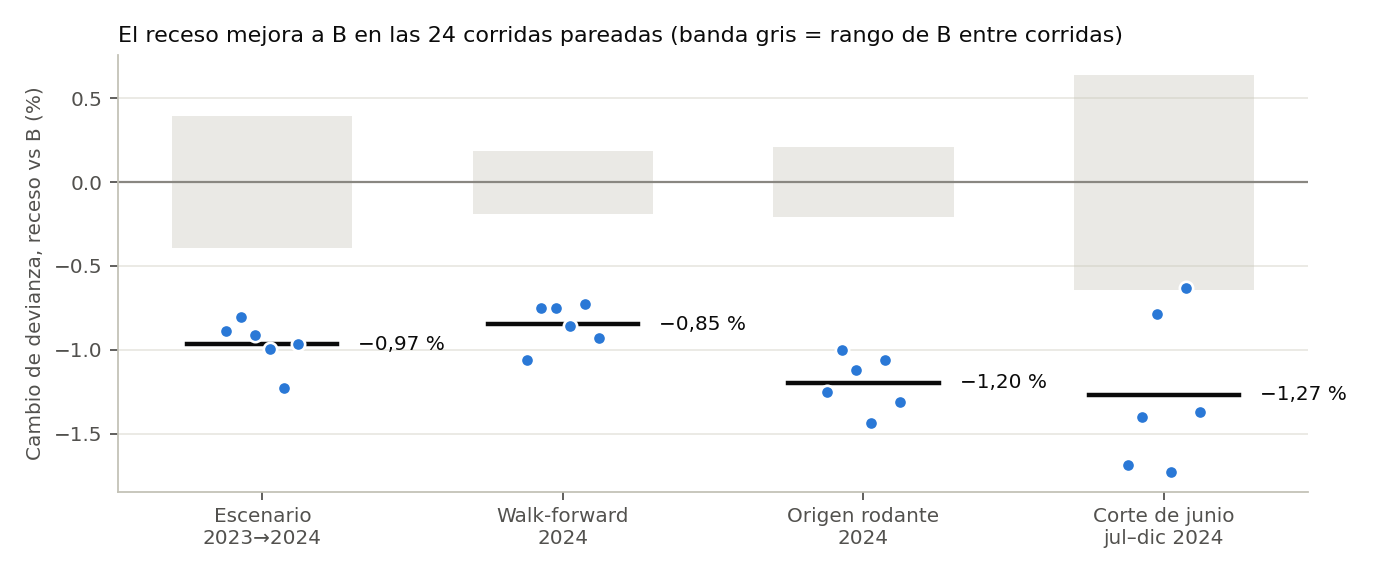

In [4]:
check("la validación no usa 2025 (n de prueba del escenario = viajes de 2024)", bool((t[t.diseno == "escenario"].n == 163236).all()))
filas = []
for d in VE.DISENOS:
    s1 = VE.senal(t, d, "B", "V0"); s2 = dec["paso_2"]["por_diseno"][d]["A"]
    j1 = VE._pares(t, d, "B", "V0"); n1 = int(((j1.dev_c - j1.dev_b) < 0).sum())
    b = dec["paso_2"]["por_diseno"][d]["B"]
    filas.append({"diseño": d, "B vs actual (media Δ)": pct(s1["media_delta"]), "B gana": f"{n1}/{len(j1)}",
                  "receso vs B (media Δ)": pct(s2["media_delta"]), "sd Δ": pct(s2["sd_delta"]).replace("+", ""),
                  "rango de B": pct(s2["rango_base"]).replace("+", ""), "receso gana 6/6": s2["todas_negativas"],
                  "A cumple": s2["cumple"], "sesgos cumplen": b["cumple"]})
p2 = pd.DataFrame(filas); display(p2)
print("Paso 1:", dec["paso_1"])
m = t.groupby(["diseno", "variante"])[["dev", "domlab_pred", "domlab_real", "sesgo_global", "sesgo_laboral", "sesgo_domingo",
                                       "sesgo_lab_04_05", "sesgo_lab_06_08", "sesgo_lab_feb", "sesgo_lab_ago"]].mean().round(3)
display(m.loc[(slice(None), ["V0", "B", "Rb"]), :])

fig, ax = plt.subplots(figsize=(8.6, 3.6))
for i, d in enumerate(VE.DISENOS):
    j = VE._pares(t, d, "Rb", "B"); dd = (j.dev_c - j.dev_b) / j.dev_b * 100
    ax.scatter(np.full(len(dd), i) + np.linspace(-0.12, 0.12, len(dd)), dd, s=36, color=COL["e1c"], edgecolor="white", lw=1.2, zorder=3)
    ax.plot([i - 0.25, i + 0.25], [dd.mean()] * 2, color=COL["texto"], lw=2)
    rb = dec["paso_2"]["por_diseno"][d]["A"]["rango_base"] * 100
    ax.fill_between([i - 0.3, i + 0.3], -rb, rb, color="#c3c2b7", alpha=0.35, lw=0)
    ax.text(i + 0.32, dd.mean(), f"{dd.mean():.2f} %".replace(".", ",").replace("-", "−"), va="center", fontsize=9, color=COL["texto"])
ax.axhline(0, color="#898781", lw=1)
ax.set_xticks(range(4)); ax.set_xticklabels(["Escenario\n2023→2024", "Walk-forward\n2024", "Origen rodante\n2024", "Corte de junio\njul–dic 2024"])
ax.set_ylabel("Cambio de devianza, receso vs B (%)", color=COL["texto2"], fontsize=9); estilo(ax)
ax.set_title("El receso mejora a B en las 24 corridas pareadas (banda gris = rango de B entre corridas)", fontsize=10, color=COL["texto"], loc="left")
fig.tight_layout(); fig.savefig(FIG / "receso_vs_B_validacion.png", dpi=160); plt.close(fig)
display(Image(FIG / "receso_vs_B_validacion.png"))
check("paso 1 (B frente al modelo original) cumple", dec["paso_1"]["cumple"])
check("paso 2 (receso frente a B) cumple en los 4 diseños", dec["paso_2"]["cumple"])

**Conclusión 3 · Quitar la tendencia y agregar el receso, decidido con 2023–2024**

| Diseño (solo 2023–2024) | B vs original | Receso vs B | Desv. est. | Rango de B | Corridas a favor |
|---|---:|---:|---:|---:|---:|
| Escenario 2023→2024 | −10,92 % | **−0,97 %** | 0,14 % | 0,40 % | 6/6 |
| Walk-forward 2024 | −3,14 % | **−0,85 %** | 0,13 % | 0,19 % | 6/6 |
| Origen rodante 2024 | −3,40 % | **−1,20 %** | 0,16 % | 0,21 % | 6/6 |
| Corte de junio (jul–dic) | −3,09 % | **−1,27 %** | 0,46 % | 0,64 % | 6/6 |

- **Paso 1 (quitar la tendencia) se cumple con holgura.** En el escenario, dom/laboral pasa de 0,846 a 0,692 (real 0,668) y la madrugada laboral de −15,95 a −0,88.
- **Paso 2 (receso frente a B) se cumple en los 4 diseños:**
  - mejora en las **24 de 24** corridas pareadas, con una media de entre 2,8 (corte de junio) y 7,3 desviaciones estándar, y por encima del rango de B;
  - cumple todas las tolerancias de sesgo.
- **Dónde actúa el receso** (escenario):
  - corrige sobre todo **agosto** (sesgo laboral −2,64 → −1,50);
  - **febrero** apenas (−4,00 → −3,43), menos de lo que anticipaba el consejo (su variante incluía mes y Semana Santa);
  - sube un poco el sesgo global (+0,95 → +1,11).
- Los 4 diseños comparten los mismos 6 entrenamientos por corrida: son 4 ventanas de evaluación, no 4 evidencias independientes.

## 4 · Pasos 3 y 4: receso por tipo, intradía y oráculo

In [5]:
filas = []
for d, v in dec["paso_3"]["por_diseno"].items():
    filas.append({"diseño": d, "R vs Rb (media Δ)": pct(v["A_vs_Rb"]["media_delta"]), "R gana 6/6": v["A_vs_Rb"]["todas_negativas"],
                  "A cumple": v["A_vs_Rb"]["cumple"], "sesgos vs B": v["B_vs_B"]["cumple"],
                  "fallan": [k for k, x in v["B_vs_B"]["condiciones"].items() if not x], "dom/lab no peor que Rb": v["domlab_no_peor_que_Rb"]})
display(pd.DataFrame(filas))
display(pd.DataFrame(dec["paso_4"]).T)
display(alc.groupby(["modelo", "variante"])[["dev", "domlab_pred", "sesgo_global", "sesgo_laboral", "sesgo_domingo"]].mean().round(3))
check("paso 4: intradía y oráculo no inferiores con el receso",
      all(v["no_inferior"] for v in dec["paso_4"].values()), str({k: v["variante_final"] for k, v in dec["paso_4"].items()}))

,diseño,R vs Rb (media Δ),R gana 6/6,A cumple,sesgos vs B,fallan,dom/lab no peor que Rb
0,escenario,"−0,26 %",False,False,True,[],False
1,walk_forward,"−0,14 %",True,False,True,[],False
2,origen_rodante,"−0,31 %",True,True,False,[tipo_domingo],False
3,corte_junio,"−0,49 %",True,False,False,"[tipo_domingo, domingo_laboral]",False


,dev_media,rango_B,B_vs_V0_media_delta,no_inferior,variante_final
modelo_intradia,"{'B': 2.3578963811527784, 'Rb': 2.3415160538078177, 'V0': 2.602681838124532}",0.001665,-0.094051,True,Rb
modelo_oraculo,"{'B': 2.2700684941700184, 'Rb': 2.264214365401133, 'V0': 2.3316094014608515}",0.002953,-0.026394,True,Rb


dev  domlab_pred  sesgo_global  sesgo_laboral  sesgo_domingo
modelo          variante                                                                
modelo_intradia B         2.358        0.693         0.288          0.073          2.282
                Rb        2.342        0.690         0.481          0.337          2.230
                V0        2.603        0.825        -2.670         -5.377          9.803
modelo_oraculo  B         2.270        0.682        -0.209         -0.421          1.002
                Rb        2.264        0.682        -0.122         -0.309          1.016
                V0        2.332        0.730        -0.946         -2.050          4.095

**Conclusión 4 · Receso binario en los tres modelos**
- **`receso_tipo` no le gana a la binaria:**
  - mejora −0,14 % a −0,49 %, dentro del ruido en 3 de 4 diseños;
  - empeora el sesgo del domingo en el origen rodante y en el corte de junio;
  - nunca mejora el contraste domingo/laboral.
  - Queda **Rb**.
- **Intradía** (escenario, 6 corridas): 2,603 → 2,358 al quitar la tendencia (−9,4 %) → 2,342 con el receso.
- **Oráculo:** 2,332 → 2,270 (−2,6 %) → 2,264.
- Los dos pasan la verificación de no inferioridad, así que **los 3 modelos usan Rb**: las mismas 33 / 45 / 53 variables, con `receso` en lugar de `tendencia_meses`.

## 5 · 2025: evaluación única de la versión corregida (no ciega)

,dev,mae,mejora_vs_linea_base_%,cambio_vs_7_3_%,sesgo_global,domlab_pred,domlab_real,sesgo_laboral,sesgo_sabado,sesgo_domingo,sesgo_lab_04_05,sesgo_lab_06_08,sesgo_lab_feb,sesgo_lab_ago
config,,,,,,,,,,,,,,
linea_base,2.929,23.485,0.000,NaN,5.955,0.678,0.671,6.560,4.525,5.050,7.277,4.317,-1.371,-1.287
7_3_modelo_0400,2.503,20.706,14.543,NaN,-2.971,0.842,0.671,-5.542,1.616,10.009,-17.001,-7.694,-10.175,-10.737
7_3_modelo_intradia,2.406,20.380,17.857,NaN,-1.754,0.816,0.671,-3.924,1.933,9.254,-13.970,-6.529,-7.346,-8.221
7_3_modelo_oraculo,2.222,19.670,24.148,NaN,-0.478,0.726,0.671,-1.224,0.592,3.852,-5.967,-0.368,-3.257,-3.566
e1c_modelo_0400,2.248,19.969,23.235,-10.172,1.787,0.694,0.671,1.786,0.680,3.229,0.397,2.387,-1.155,-1.768
e1c_modelo_intradia,2.216,19.747,24.320,-7.868,0.893,0.697,0.671,0.720,0.270,2.783,-0.239,1.653,-1.544,-2.598
e1c_modelo_oraculo,2.196,19.599,25.024,-1.156,0.256,0.688,0.671,0.087,0.071,1.553,-1.306,1.775,-1.383,-1.808


El 04:00 corregido mejora al oficial en 11 de 12 meses; peor en: ['2025-12']


config,linea_base,7_3_modelo_0400,e1c_modelo_0400,7_3_modelo_intradia,e1c_modelo_intradia
grupo,,,,,
04–06,5.15,-15.16,0.65,-12.54,0.15
07–09,8.34,-4.05,3.70,-3.52,2.52
10–12,5.18,-2.38,3.39,-1.33,1.83
13–15,8.31,-4.21,2.04,-1.82,0.70
16–18,6.04,-3.09,0.16,-2.10,-1.02
19–20,6.36,3.63,-0.29,5.68,-0.79


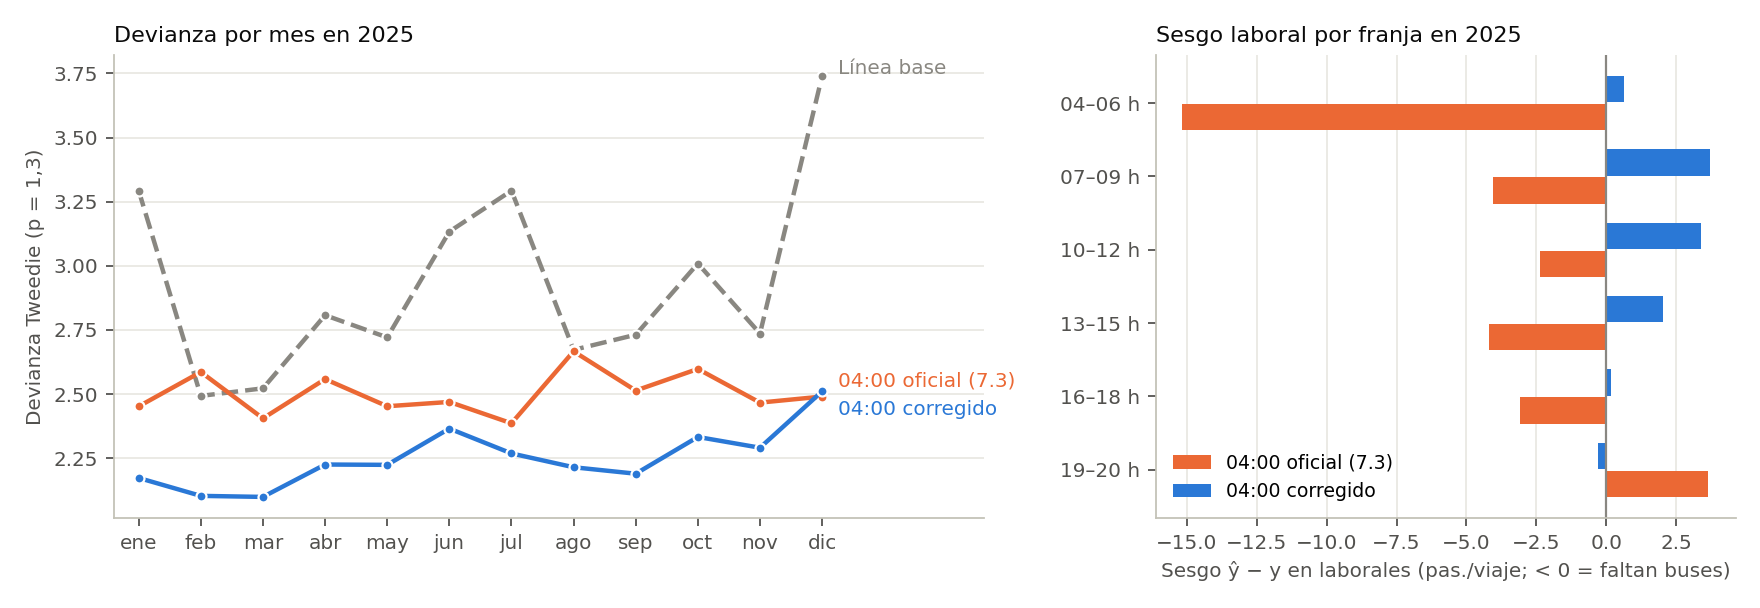

In [6]:
meta = json.loads(Path("modelos_e1c/modelo_0400_meta.json").read_text(encoding="utf-8"))
check("modelos finales con el mismo entrenamiento de la 7.3 (324.508 viajes, cierre ≤ 2025-01-01 04:00)",
      meta["n_entrenamiento"] == 324508 and pd.Timestamp(meta["max_fechafin"]) <= pd.Timestamp("2025-01-01 04:00"))
check("holdout completo (158.507 viajes)", int(h.n.iloc[0]) == 158507)
check("cifras oficiales de la 7.3 intactas (devianza 04:00 = 2,503)", round(h.loc["7_3_modelo_0400", "dev"], 3) == 2.503)
cols = ["dev", "mae", "mejora_vs_linea_base_%", "cambio_vs_7_3_%", "sesgo_global", "domlab_pred", "domlab_real", "sesgo_laboral",
        "sesgo_sabado", "sesgo_domingo", "sesgo_lab_04_05", "sesgo_lab_06_08", "sesgo_lab_feb", "sesgo_lab_ago"]
display(h[cols].round(3))
mes = des[des.dimension == "mes"].pivot(index="grupo", columns="config", values="dev")
mejor = int((mes["e1c_modelo_0400"] < mes["7_3_modelo_0400"]).sum())
print(f"El 04:00 corregido mejora al oficial en {mejor} de 12 meses; peor en:",
      list(mes.index[mes["e1c_modelo_0400"] >= mes["7_3_modelo_0400"]]))
lf = des[des.dimension == "laboral_franja"].pivot(index="grupo", columns="config", values="sesgo")
display(lf[["linea_base", "7_3_modelo_0400", "e1c_modelo_0400", "7_3_modelo_intradia", "e1c_modelo_intradia"]].round(2))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axs[0]; x = np.arange(12); lab = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
for k, c, nom, ls in [("linea_base", COL["linea_base"], "Línea base", "--"), ("7_3_modelo_0400", COL["7_3"], "04:00 oficial (7.3)", "-"),
                      ("e1c_modelo_0400", COL["e1c"], "04:00 corregido", "-")]:
    y = mes[k].to_numpy(); ax.plot(x, y, ls, color=c, lw=2, marker="o", ms=4.5, markeredgecolor="white")
    ax.text(11.25, y[-1] + (0.03 if k == "linea_base" else (-0.07 if k == "e1c_modelo_0400" else 0.06)), nom, color=c, fontsize=9, va="center")
ax.set_xticks(x); ax.set_xticklabels(lab); ax.set_xlim(-0.4, 13.6); ax.set_ylabel("Devianza Tweedie (p = 1,3)", fontsize=9, color=COL["texto2"])
ax.set_title("Devianza por mes en 2025", fontsize=10, loc="left", color=COL["texto"]); estilo(ax)
ax = axs[1]; fr = list(lf.index); yy = np.arange(len(fr))
ax.barh(yy + 0.19, lf["7_3_modelo_0400"], height=0.36, color=COL["7_3"], label="04:00 oficial (7.3)")
ax.barh(yy - 0.19, lf["e1c_modelo_0400"], height=0.36, color=COL["e1c"], label="04:00 corregido")
ax.axvline(0, color="#898781", lw=1); ax.set_yticks(yy); ax.set_yticklabels([f"{f} h" for f in fr]); ax.invert_yaxis()
ax.set_xlabel("Sesgo ŷ − y en laborales (pas./viaje; < 0 = faltan buses)", fontsize=9, color=COL["texto2"])
ax.set_title("Sesgo laboral por franja en 2025", fontsize=10, loc="left", color=COL["texto"]); estilo(ax); ax.grid(axis="x", color=COL["grid"]); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8.5, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "holdout_2025_e1c.png", dpi=160); plt.close(fig)
display(Image(FIG / "holdout_2025_e1c.png"))

**Conclusión 5 · 2025 con la versión corregida (evaluación única, no ciega)**

| Modelo | 7.3 oficial | Corregido | Cambio | Mejora vs línea base (corregido) |
|---|---:|---:|---:|---:|
| Línea base | 2,929 | — | — | — |
| **04:00** | 2,503 | **2,248** | **−10,2 %** | −23,2 % |
| Intradía | 2,406 | 2,216 | −7,9 % | −24,3 % |
| Oráculo | 2,222 | 2,196 | −1,2 % | −25,0 % |

- **El 04:00 corregido mejora al oficial en 11 de 12 meses** (diciembre: 2,510 frente a 2,490). Queda casi al nivel del oráculo de la 7.3 (2,222).
- **Contraste semanal:** dom/laboral predicho **0,694** frente a 0,671 real (antes 0,842).
  - Sesgo laboral −5,54 → +1,79; domingo +10,01 → +3,23.
  - Madrugada laboral 04–05 h **−17,00 → +0,40**.
  - Febrero −10,18 → −1,16; agosto −10,74 → −1,77.
- **El sesgo cambió de signo: ahora sobrepredice +1,79 pas./viaje (≈ 2 %).**
  - Sobre todo entre las 07 y las 15 h en laborales (+2,0 a +3,7).
  - Sin tendencia, la caída de la demanda de 2025 solo la siguen los rezagos, con retraso.
- **No es una evaluación ciega.**
  - 2025 ya se había mirado varias veces, y la hipótesis del calendario escolar salió de sus residuos.
  - La variante se eligió solo con 2023–2024, con la regla congelada, y se evaluó una vez.
  - Coincide con el contrafactual de la 8.2 (2,251–2,278): confirma el diagnóstico, pero no lo convierte en resultado.
- **Las cifras oficiales del Entregable 1 siguen siendo las de la 7.3.** Las corregidas se reportan al lado. No se recalcularon el DM ni el SHAP sobre 2025.

## 6 · Checks y limitaciones

In [7]:
ch = pd.DataFrame(CHECKS); ch.to_csv(D / "checks_e1c.csv", index=False); display(ch)
print(f"{int((ch.resultado == 'PASS').sum())}/{len(ch)} PASS")
print("Limitaciones declaradas en la regla:", *regla["limitaciones_declaradas"], sep="\n  - ")

,check,resultado,detalle
0,"2024 reproduce la compresión de 2025 (V0 dom/lab − real > 0,10 en las 6 corridas)",PASS,0.837–0.857 vs 0.668
1,la walk-forward 2024 ya extrapolaba (100 % fuera de rango en los 6 pliegues),PASS,
2,tests_e1c.py,PASS,7/7 PASS
3,"decisión oficial, con la regla congelada",PASS,
4,variables de modelo_0400 = hash de la decisión,PASS,
5,variables de modelo_intradia = hash de la decisión,PASS,
6,variables de modelo_oraculo = hash de la decisión,PASS,
7,la validación no usa 2025 (n de prueba del escenario = viajes de 2024),PASS,
8,paso 1 (B frente al modelo original) cumple,PASS,
9,paso 2 (receso frente a B) cumple en los 4 diseños,PASS,


14/14 PASS
Limitaciones declaradas en la regla:
  - los resultados preliminares del consejo (Rb − B −0,87 % en el escenario y −1,18 % en el origen rodante) se conocían al escribir esta regla
  - el receso de inicio de año no se puede validar con 2023–2024: el entrenamiento ve un solo enero
  - un solo año de prueba (2024); los 4 diseños comparten entrenamientos
  - hiperparámetros y rondas elegidos con 2024 y con la tendencia presente: los niveles absolutos son optimistas; las comparaciones entre variantes siguen siendo pareadas y justas
  - las tolerancias de sesgo (0,5; 1,0; 0,01; +1,5) son operativas (planificador y pasajeros del consejo), no estadísticas


**Conclusión 6 · Qué queda abierto**
- **14/14 checks PASS** (`datos_e1c/checks_e1c.csv`).
- **Abierto para el Entregable 2:**
  - **Sobrepredicción de nivel** (+1,8 pas./viaje en 2025): probar el nivel como offset (`init_score` con la media reciente) o una recalibración mensual por franja, nunca global.
  - **Receso de inicio de año:** su efecto se estimó con un solo enero y no se pudo validar fuera de muestra con 2023–2024.
  - **Un solo año de prueba** (2024) para decidir. Hiperparámetros y rondas elegidos con la tendencia presente: los niveles absolutos de la validación son optimistas, aunque las comparaciones pareadas siguen siendo justas.
  - **Calendario:** el escolar cubre hasta el 27-dic-2026 y `calendario_dias.csv` (festivos y carnaval) termina el 31-dic-2025. Ambos hay que extenderlos antes de emitir en 2026; el escolar falla de forma explícita si falta.
  - **Guarda de rango por variable** en la emisión, para que otra variable monótona no vuelva a entrar sin aviso.
- `tests_8_2.py` exige `tendencia_meses`: aplica al modelo oficial de la 7.3 y no se re-ejecuta sobre la versión corregida.

---
# Parte 2 · Módulo 9 · Fiabilidad vehicular y scoring de riesgo del conductor
*Notebook original: `modulo9/modulo_9_fiabilidad_scoring.ipynb`*

# SOBUSA · Módulo 9 — Fiabilidad vehicular y scoring de riesgo del conductor

**Integrante 1 · Core ML & Optimización.** Requisitos **R2** (fiabilidad por desgaste de flota) y **R3** (scoring conductual), según el *Plan técnico v2.0, Módulos 9 a 14*. Continúa los Módulos 1–8 (Entregable 1): usa sus maestras sin modificarlas, la misma ventana (2023–2025), la misma tarifa de negocio (3.700 COP) y la misma regla de oro: **2025 es holdout y se evalúa una sola vez**.

| Elemento | Decisión |
|---|---|
| Unidad R2 | Bus × día con al menos un despacho programado (208.143 bus-días). Emisión a las 04:00 del día *t*: toda feature usa solo días < *t* |
| Etiqueta R2 | **Varada en jornada (proxy operativo):** viaje iniciado que cubre entre el 5 % y el 50 % de `distancia_global`, es el último despacho iniciado del bus ese día y sale a más tardar a las 16 h. Si existe la extracción E1, se audita contra los motivos mecánicos de `observacion` |
| Modelo R2 | LightGBM binario (rondas por early stopping en 2024-T2, reajuste con train + val) + **Platt scaling** en 2024-S2 |
| Partición R2 | Calentamiento 2023-T1 · train 2023-04 → 2024-03 · val 2024-04 → 2024-06 · calibración 2024-07 → 2024-12 · **holdout 2025** |
| Métricas R2 | ROC-AUC con **DeLong** (vs azar y pareado vs líneas base), **Brier** (y skill vs climatología, descomposición de Murphy), ECE, PR-AUC, captura del top-k % |
| Score R3 | Componentes por viaje → observado/esperado por ruta × franja → contracción Poisson-Gamma → z → pesos 50 % experto + 50 % PCA (CP1) → reputación 0–100 |
| Validación R3 | Fuera de tiempo: score 2024 frente a resultados 2025 — **Gini** (IC DeLong) y **Kolmogorov-Smirnov** |
| Entregables | `src/features/reliability_scoring.py`, `extraer_modulo9.py`, `tests_9.py`, `sql/tb_scoring_vehiculo_conductor.sql` y la tabla `datos_9/tb_scoring_vehiculo_conductor.parquet` |

## Parte 1 · Extracción contra la RDS

Las columnas que el plan pide de `vehiculos` (inspección, póliza) y de `progvehiculos` (`idconductor`, `observacion`) **no están en los archivos locales del Entregable 1**. `extraer_modulo9.py` las trae (solo lectura, contraseña con `getpass`, nunca `SELECT *` sobre `vehiculos`, `conteo_pasajeros_destino` solo por `idprogramacion = ANY(:ids)` y agregada en el servidor):

- **E1** `progvehiculos`: `idconductor`, `iddespachador`, `observacion`, `excedeplazosalida`.
- **E2** búsqueda en `information_schema` de columnas de revisión técnica, SOAT o mantenimiento en todo el esquema + columnas técnicas de `vehiculos`.
- **E3** velocidades GPS por viaje (hasta 4 viajes por conductor y semestre), calculadas en SQL con la misma lógica que `R.velocidad_por_viaje` (verificada en la prueba f).

```
py -3.10 extraer_modulo9.py
```

Este notebook detecta qué archivos existen y se adapta: **sin la extracción, R2 se entrena completo y R3 se calcula por vehículo** (la unidad disponible); con E1, R3 se calcula además por conductor.

In [1]:
from src.features import reliability_scoring as R
EXTRA = R.cargar_extraccion()
for k in ["progvehiculos", "vehiculos", "columnas_tecnicas", "velocidad"]:
    print(f"{k:18s}", f"{len(EXTRA[k]):,} filas" if k in EXTRA else "— no extraído")

progvehiculos      564,837 filas
vehiculos          656 filas
columnas_tecnicas  12 filas
velocidad          11,891 filas


## Parte 2 · Análisis offline

In [2]:
import json
import time
import warnings
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import chi2_contingency
from sklearn.metrics import average_precision_score, roc_curve

import tests_9 as T

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 110)
warnings.filterwarnings("ignore", category=FutureWarning)
T0 = time.time()
CFG = R.CFG
SALIDA = R.DATOS_9; SALIDA.mkdir(exist_ok=True)
FIG = Path("resultados_9"); FIG.mkdir(exist_ok=True)
CHECKS = []


def check(nombre, ok, detalle="", info=False):
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


def figura(nombre):
    plt.tight_layout(); plt.savefig(FIG / nombre, dpi=120); plt.close(); display(Image(str(FIG / nombre)))


v = R.cargar_viajes(extra=EXTRA)
veh, cal = R.cargar_vehiculos(), R.cargar_calendario()
print(f"Fuente: {R.RAIZ_SOBUSA}")
print(f"{len(v):,} despachos 2023–2025 · {v.inicio.sum():,} iniciados · {v.idvehiculo.nunique()} buses")

Fuente: C:\Users\samit\OneDrive\Escritorio\UNIVERSIDAD\2026\2026-3\MACHINE LEARNING\ENTREGABLE_1_SOBUSA\entrega_1_DATACHALLENGE\Sobusa\Sobusa
564,837 despachos 2023–2025 · 561,427 iniciados · 449 buses


## 1 · Auditoría de las fuentes del plan

In [3]:
raiz = R.RAIZ_SOBUSA
nul = pd.read_csv(raiz / "datos_1_4" / "nulos_progvehiculos.csv")
total = int(nul.total.iloc[0])
cols_veh = [c.strip() for c in pd.read_csv(raiz / "datos_1_3" / "vehiculos_candidatos.csv").columnas.iloc[0].split(",")]
locales = {"modelo", "idvehiculo", "numerobloqueos", "excedeplazosalida"}
plan = [
    ("modelo", "vehiculos", "edad_bus = año − modelo; sin modelo → indicadora"),
    ("fecha_vencimiento_tecnomecanica", "vehiculos", "Foto actual → E2; días hasta el vencimiento solo dentro de su año de vigencia"),
    ("fecha_vencimiento_soap", "vehiculos", "Ídem (SOAT)"),
    ("fecha_inspeccion", "vehiculos", "Solo la última inspección (foto actual) → E2; se usa solo si ocurrió antes de t"),
    ("resultado_inspeccion", "vehiculos", "Sin historial no se puede calcular el % de inspecciones reprobadas"),
    ("vel_max_dia", "vehiculos", "Foto del día de la consulta: se reemplaza por velocidad GPS por viaje (E3)"),
    ("vel_prom_dia", "vehiculos", "Ídem"),
    ("idconductor", "progvehiculos", "Unidad de R3; no está en los archivos locales → E1"),
    ("idvehiculo", "progvehiculos", "Unidad de R2"),
    ("numerobloqueos", "progvehiculos", "Bandera binaria > 0 (regla del Módulo 1)"),
    ("acumulada_bloqueo", "progvehiculos", "No usar: contador de toda la vida del equipo (Módulo 1)"),
    ("bloqueo_cond", "progvehiculos", "Inutilizable"),
    ("bloqueo_veh", "progvehiculos", "Inutilizable"),
    ("excedeplazosalida", "progvehiculos", "Casi vacía: se usa retraso_salida_min de tb_despachos"),
]
filas = []
for var, tabla, uso in plan:
    existe = var in (cols_veh if tabla == "vehiculos" else nul.columns)
    if tabla == "progvehiculos":
        pct = nul[var].iloc[0] / total if var in nul else np.nan
    else:
        e2v = EXTRA.get("vehiculos")
        pct = e2v[var].notna().mean() if (e2v is not None and var in e2v) else np.nan
    filas.append({"variable_plan": var, "tabla": tabla, "existe_en_rds": existe, "pct_no_nulo": pct,
                  "en_archivos_locales": var in locales, "uso_en_modulo_9": uso})
auditoria = pd.DataFrame(filas)
auditoria.to_csv(SALIDA / "auditoria_fuentes_9.csv", index=False)
display(auditoria.style.format({"pct_no_nulo": "{:.1%}"}, na_rep="—"))
print(f"vehiculos tiene {len(cols_veh)} columnas; relacionadas con mantenimiento/documentos:",
      [c for c in cols_veh if any(k in c for k in ["inspec", "poliza", "asegur", "odometro", "tecno", "soap", "soat", "venc", "fechaingreso", "despacho_hab"])])
print(f"observacion no nula: {nul.observacion.iloc[0] / total:.1%} de {total:,} programaciones")
check("Auditoría de fuentes", True,
      f"{int(auditoria.existe_en_rds.sum())}/{len(auditoria)} variables del plan existen en la RDS; "
      f"{int(auditoria.en_archivos_locales.sum())} están en los archivos locales; "
      f"bloqueo_cond/bloqueo_veh {auditoria.set_index('variable_plan').pct_no_nulo['bloqueo_cond']:.0%} no nulas", info=True)

,variable_plan,tabla,existe_en_rds,pct_no_nulo,en_archivos_locales,uso_en_modulo_9
0,modelo,vehiculos,True,73.0%,True,edad_bus = año − modelo; sin modelo → indicadora
1,fecha_vencimiento_tecnomecanica,vehiculos,True,0.0%,False,Foto actual → E2; días hasta el vencimiento solo dentro de su año de vigencia
2,fecha_vencimiento_soap,vehiculos,True,0.0%,False,Ídem (SOAT)
3,fecha_inspeccion,vehiculos,True,0.0%,False,Solo la última inspección (foto actual) → E2; se usa solo si ocurrió antes de t
4,resultado_inspeccion,vehiculos,True,0.0%,False,Sin historial no se puede calcular el % de inspecciones reprobadas
5,vel_max_dia,vehiculos,True,100.0%,False,Foto del día de la consulta: se reemplaza por velocidad GPS por viaje (E3)
6,vel_prom_dia,vehiculos,True,100.0%,False,Ídem
7,idconductor,progvehiculos,True,100.0%,False,Unidad de R3; no está en los archivos locales → E1
8,idvehiculo,progvehiculos,True,100.0%,True,Unidad de R2
9,numerobloqueos,progvehiculos,True,98.5%,True,Bandera binaria > 0 (regla del Módulo 1)


vehiculos tiene 144 columnas; relacionadas con mantenimiento/documentos: ['fechaingreso', 'asegurado', 'aseguradora', 'vigencia_poliza', 'poliza', 'fecha_poliza', 'ultimo_odometro', 'despacho_habilitado', 'fecha_inspeccion', 'resultado_inspeccion', 'fecha_vencimiento_tecnomecanica', 'fecha_vencimiento_soap']
observacion no nula: 8.7% de 564,837 programaciones


**Conclusión 1 · Fuentes**
- **Las 14 variables del plan existen en la RDS**, pero solo 4 estaban en los archivos locales del Entregable 1. "Quey.csv" no existe como archivo: sus columnas son de la tabla `vehiculos` (144 columnas). Las demás se trajeron con la Parte 1.
- **Existen, pero están vacías** (0 % no nulo):
  - en `vehiculos`: `fecha_inspeccion`, `resultado_inspeccion`, `fecha_vencimiento_tecnomecanica` y `fecha_vencimiento_soap` (también `vigencia_poliza` y `fecha_poliza`);
  - en `progvehiculos`: `bloqueo_cond` y `bloqueo_veh`.
  - **El sub-modelo de varadas no puede usar revisión técnica, SOAT ni inspecciones**: SOBUSA no los registra en la base.
- `excedeplazosalida` solo está lleno en el 1,2 %: se usa `retraso_salida_min` de `tb_despachos`. `acumulada_bloqueo` es un contador de toda la vida del equipo (regla del Módulo 1).
- `vel_max_dia` y `vel_prom_dia` están llenas, pero son del día de la consulta (foto actual): se reemplazan por la velocidad GPS por viaje (Sección 6).
- `modelo` está en el 73,0 % de los vehículos. `idconductor` está lleno al 100 %, pero incluye un ID genérico (Conclusión 7).

## 2 · Etiqueta de varada en jornada y su validación

,bus_dias,varadas,tasa
fecha,,,
2023,70248,684,0.97%
2024,69975,884,1.26%
2025,67920,999,1.47%


Viajes marcados: 2,567 (0.46% de los iniciados) · cancelados 18.2% · ratio de distancia mediano 0.20


,lun_jue,y,bus_dias,ausente_dia_siguiente,viajes_ese_dia
0,False,0,81642,33.9%,2.72
1,False,1,1035,53.8%,1.88
2,True,0,123507,18.9%,2.71
3,True,1,1510,38.1%,1.66


P(ausente al día siguiente): varada 44.5% vs resto 24.9% (χ² p = 1.9e-113); lun–jue: 38.1% vs 18.9% (p = 1.9e-78)
Sobredispersión entre 293 buses con ≥ 100 bus-días: 3.38 (tasa por bus P10–P90: 0.41% – 2.43%)


y_obs,0,All
y_proxy,,
0,205576,205576
1,2567,2567
All,208143,208143


,programaciones
observacion,
CANCELADA AUTOMATICAMENTE,44144
EXCEDIO EL PLAZO DE SALIDA,5181
CANCELADO AUTOMATICAMENTE,6


observacion tiene solo 3 valores distintos, todos automáticos: no registra motivos mecánicos. La etiqueta proxy es la única disponible.


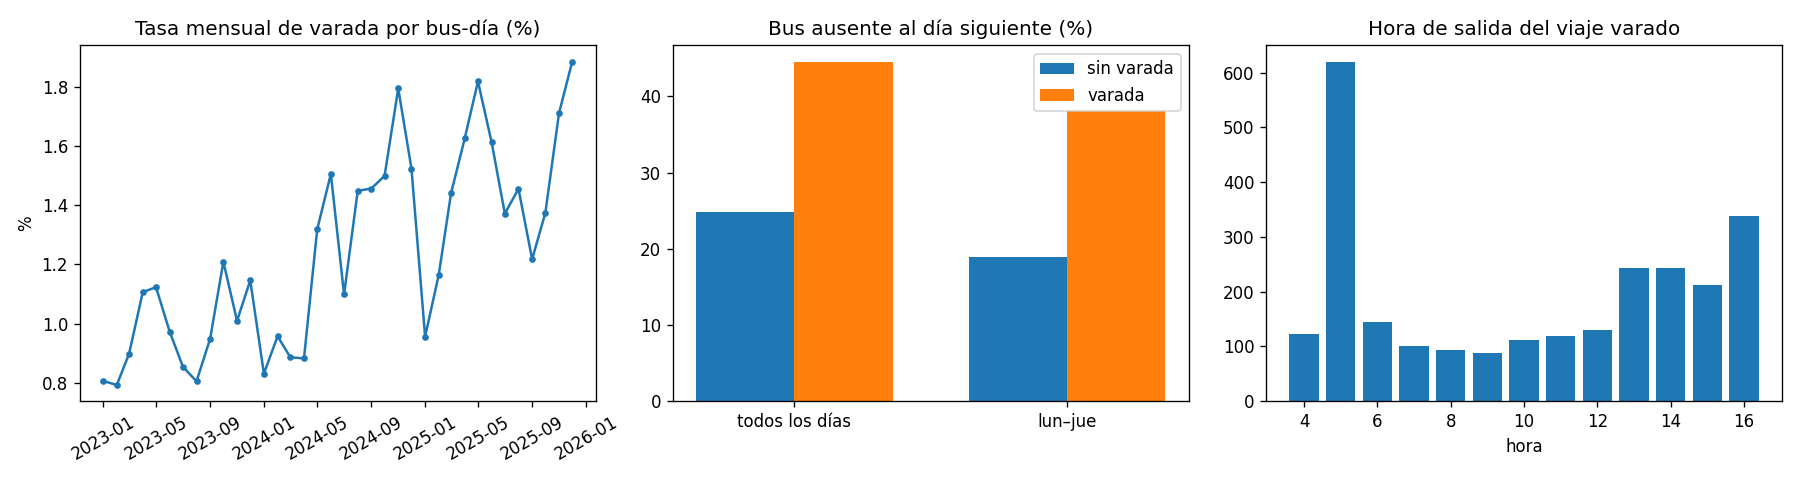

In [4]:
p = R.panel_bus_dia(v, "proxy")
anual = p.groupby(p.fecha.dt.year).agg(bus_dias=("y", "size"), varadas=("y", "sum"), tasa=("y", "mean"))
display(anual.style.format({"tasa": "{:.2%}"}))
var_v = v[v.varada_proxy]
print(f"Viajes marcados: {len(var_v):,} ({len(var_v) / v.inicio.sum():.2%} de los iniciados) · "
      f"cancelados {var_v.cancelado.mean():.1%} · ratio de distancia mediano {var_v.ratio.median():.2f}")

# Validación 1: un bus varado debería faltar más al día siguiente (taller)
q = p.sort_values(["idvehiculo", "fecha"]).copy()
q["siguiente"] = q.groupby("idvehiculo").fecha.shift(-1)
q = q[q.siguiente.notna()]
q["ausente_sig"] = (q.siguiente - q.fecha).dt.days > 1
q["lun_jue"] = q.fecha.dt.dayofweek <= 3
val = (q.groupby(["lun_jue", "y"]).agg(bus_dias=("y", "size"), ausente_dia_siguiente=("ausente_sig", "mean"),
                                        viajes_ese_dia=("viajes_dia", "mean")).reset_index())
display(val.style.format({"ausente_dia_siguiente": "{:.1%}", "viajes_ese_dia": "{:.2f}"}))
chi = chi2_contingency(pd.crosstab(q.y, q.ausente_sig))
lj = q[q.lun_jue]
chi_lj = chi2_contingency(pd.crosstab(lj.y, lj.ausente_sig))
a1, a0 = q[q.y == 1].ausente_sig.mean(), q[q.y == 0].ausente_sig.mean()
b1, b0 = lj[lj.y == 1].ausente_sig.mean(), lj[lj.y == 0].ausente_sig.mean()
print(f"P(ausente al día siguiente): varada {a1:.1%} vs resto {a0:.1%} (χ² p = {chi[1]:.1e}); "
      f"lun–jue: {b1:.1%} vs {b0:.1%} (p = {chi_lj[1]:.1e})")

# Validación 2: heterogeneidad entre buses (si fuera ruido puro, la dispersión sería ≈ 1)
pb = p.groupby("idvehiculo").y.agg(["sum", "size"])
pb = pb[pb["size"] >= 100]
p0 = p.y.mean()
disp = ((pb["sum"] - pb["size"] * p0) ** 2).sum() / (pb["size"] * p0 * (1 - p0)).sum()
print(f"Sobredispersión entre {len(pb)} buses con ≥ 100 bus-días: {disp:.2f} "
      f"(tasa por bus P10–P90: {pb['sum'].div(pb['size']).quantile(.1):.2%} – {pb['sum'].div(pb['size']).quantile(.9):.2%})")

po = None
if "varada_obs" in v:
    from sklearn.metrics import cohen_kappa_score
    po = R.panel_bus_dia(v, "observacion")
    m = p[["idvehiculo", "fecha", "y"]].merge(po[["idvehiculo", "fecha", "y"]], on=["idvehiculo", "fecha"], suffixes=("_proxy", "_obs"))
    display(pd.crosstab(m.y_proxy, m.y_obs, margins=True))
    display(R._sin_tildes(v.observacion[v.observacion.notna()]).value_counts().head(25).to_frame("programaciones"))
    v.loc[v.varada_obs, "observacion"].value_counts().head(60).to_csv(SALIDA / "observacion_mecanica_9.csv")
    valores = v.observacion.dropna().nunique()
    if m.y_obs.any():
        kappa = cohen_kappa_score(m.y_proxy, m.y_obs)
        cubre = m.loc[m.y_obs == 1, "y_proxy"].mean()
        precision = m.loc[m.y_proxy == 1, "y_obs"].mean()
        print(f"Bus-días con motivo mecánico en observacion: {int(m.y_obs.sum()):,} ({m.y_obs.mean():.2%}) · "
              f"el proxy marca el {cubre:.1%} de ellos · de los bus-días proxy, {precision:.1%} tienen motivo mecánico · κ = {kappa:.3f}")
        detalle = f"{int(m.y_obs.sum()):,} bus-días mecánicos; cobertura del proxy {cubre:.1%}; precisión {precision:.1%}; κ {kappa:.3f}"
    else:
        print(f"observacion tiene solo {valores} valores distintos, todos automáticos: no registra motivos mecánicos. "
              "La etiqueta proxy es la única disponible.")
        detalle = f"0 motivos mecánicos en {int(v.observacion.notna().sum()):,} observaciones ({valores} valores distintos)"
        po = None
    check("Etiqueta · auditoría contra observacion (E1)", True, detalle, info=True)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
mes = p.groupby(p.fecha.dt.to_period("M")).y.mean()
ax[0].plot(mes.index.to_timestamp(), mes.values * 100, marker="o", ms=3)
ax[0].set_title("Tasa mensual de varada por bus-día (%)"); ax[0].set_ylabel("%"); ax[0].tick_params(axis="x", rotation=30)
lab = ["todos los días", "lun–jue"]
ax[1].bar(np.arange(2) - 0.18, [a0 * 100, b0 * 100], 0.36, label="sin varada")
ax[1].bar(np.arange(2) + 0.18, [a1 * 100, b1 * 100], 0.36, label="varada")
ax[1].set_xticks(range(2)); ax[1].set_xticklabels(lab); ax[1].set_title("Bus ausente al día siguiente (%)"); ax[1].legend()
ax[2].bar(*np.unique(var_v.hora, return_counts=True)); ax[2].set_title("Hora de salida del viaje varado"); ax[2].set_xlabel("hora")
figura("m9_etiqueta_varada.png")
check("Etiqueta · varada → más ausencias al día siguiente", (a1 > a0) and chi[1] < 0.05 and (b1 > b0) and chi_lj[1] < 0.05,
      f"{a1:.1%} vs {a0:.1%} (p {chi[1]:.1e}); lun–jue {b1:.1%} vs {b0:.1%}")
check("Etiqueta · heterogeneidad entre buses", disp > 1.5, f"índice de dispersión {disp:.2f} (> 1 = no es ruido homogéneo)")

**Conclusión 2 · Etiqueta de varada**
- **2.567 viajes marcados** (0,46 % de los iniciados). El 18,2 % figuraba como "cancelado" y recorren una mediana del 20 % de la ruta.
- **Tasa por bus-día:** 0,97 % (2023) → 1,26 % (2024) → 1,47 % (2025). La flota se degrada.
- **Validación externa:** tras una varada, el bus falta al día siguiente el **44,5 %** de las veces, frente al 24,9 % (χ² p = 1,9e-113). De lunes a jueves, 38,1 % frente a 18,9 %. Es la huella de un paso por taller.
- **No es ruido homogéneo:** el índice de dispersión entre 293 buses es 3,38, con una tasa por bus de 0,41 % a 2,43 % (P10–P90).
- **Auditoría con E1:** `observacion` solo tiene 3 valores, todos automáticos ("CANCELADA AUTOMATICAMENTE" 44.144, "EXCEDIÓ EL PLAZO DE SALIDA" 5.181, "CANCELADO AUTOMATICAMENTE" 6).
  - **No hay un solo motivo mecánico registrado**, así que la etiqueta proxy es la única posible.
  - Sigue siendo un *proxy*: no distingue una varada mecánica de otro retiro anticipado. Debe validarse con la bitácora de taller de SOBUSA.

## 3 · Panel bus-día y features sin leakage

In [5]:
ETIQUETA = "proxy"
E2 = EXTRA.get("vehiculos") if R.documentos_utiles(EXTRA.get("vehiculos")) else None
if "vehiculos" in EXTRA and E2 is None:
    print("E2 extraído, pero inspección / tecnomecánica / SOAT están 100 % vacías: no entran al modelo.")
X = R.features_r2(v, p[["idvehiculo", "fecha"]], ETIQUETA, vehiculos=veh, calendario=cal, vehiculos_extra=E2)
P = p.merge(X, on=["idvehiculo", "fecha"])
P["conjunto"] = R.asignar_conjunto(P.fecha)
FEATS = R.FEATURES_R2 + (R.FEATURES_R2_VEHICULOS if E2 is not None else [])
conj = (P.groupby("conjunto").agg(desde=("fecha", "min"), hasta=("fecha", "max"), bus_dias=("y", "size"),
                                   varadas=("y", "sum"), tasa=("y", "mean"))
        .loc[["calentamiento", "train", "val", "calib", "holdout"]])
display(conj.style.format({"tasa": "{:.2%}", "desde": "{:%Y-%m-%d}", "hasta": "{:%Y-%m-%d}"}))
DESCR = {
    "edad_bus": ("año de t − modelo", "estática"), "modelo_faltante": ("bus sin modelo registrado", "estática"),
    "capacidad": ("n_sentados + n_depie", "estática"),
    "km_7d": ("km recorridos (topados a 1,5 × ruta)", "7 d"), "km_30d": ("km recorridos", "30 d"), "km_90d": ("km recorridos", "90 d"),
    "viajes_30d": ("viajes iniciados", "30 d"), "dias_operados_30d": ("días con al menos un viaje", "30 d"),
    "km_por_dia_operado_30d": ("intensidad de uso", "30 d"),
    "varadas_30d": ("varadas previas", "30 d"), "varadas_90d": ("varadas previas", "90 d"), "varadas_365d": ("varadas previas", "365 d"),
    "tasa_varada_365d": ("varadas / días operados", "365 d"), "dias_desde_ultima_varada": ("días desde la última varada, topado a 365", "365 d"),
    "tasa_interrumpido_90d": ("viajes < 50 % de la ruta que no son varada", "90 d"),
    "tasa_recorte_90d": ("viajes con 50–90 % de la ruta", "90 d"),
    "tasa_cancelado_30d": ("programaciones canceladas", "30 d"), "tasa_bloqueo_30d": ("viajes con numerobloqueos > 0", "30 d"),
    "tasa_sensor_falla_90d": ("viajes con flag_sensor_ok = False (Módulo 1.3)", "90 d"),
    "retraso_medio_30d": ("retraso de salida medio, topado a [−15, 60] min", "30 d"),
    "dias_desde_operacion_previa": ("días desde el último día operado", "toda la historia"),
    "ruta_habitual": ("ruta más frecuente", "30 d"), "dia_semana": ("día de la semana de t", "calendario"),
    "mes": ("mes de t (estacionalidad de lluvias / arroyos)", "calendario"), "es_festivo": ("festivo nacional (Módulo 3)", "calendario"),
    "dias_hasta_venc_tecnomecanica": ("fecha_vencimiento_tecnomecanica − t, solo dentro de su año de vigencia", "foto E2"),
    "dias_hasta_venc_soap": ("fecha_vencimiento_soap − t, solo dentro de su año de vigencia", "foto E2"),
    "dias_desde_inspeccion": ("t − fecha_inspeccion, solo si fecha_inspeccion < t", "foto E2"),
    "inspeccion_no_aprobada": ("resultado_inspeccion no aprobado, solo si fecha_inspeccion < t", "foto E2"),
}
dic = pd.DataFrame([{"feature": f, "descripcion": DESCR[f][0], "ventana": DESCR[f][1],
                     "cobertura": P[f].notna().mean()} for f in FEATS])
dic.to_csv(SALIDA / "diccionario_features_9.csv", index=False)
display(dic.style.format({"cobertura": "{:.1%}"}))
P.to_parquet(SALIDA / "panel_bus_dia_9.parquet", index=False)
print(f"Panel: {len(P):,} bus-días × {len(FEATS)} features")
orden_ok = (conj["hasta"].iloc[:-1].to_numpy() < conj["desde"].iloc[1:].to_numpy()).all()
check("Panel · partición temporal ordenada", orden_ok, " < ".join(conj.index))

E2 extraído, pero inspección / tecnomecánica / SOAT están 100 % vacías: no entran al modelo.


,desde,hasta,bus_dias,varadas,tasa
conjunto,,,,,
calentamiento,2023-01-01,2023-03-31,17363,145,0.84%
train,2023-04-01,2024-03-31,70286,694,0.99%
val,2024-04-01,2024-06-30,17601,215,1.22%
calib,2024-07-01,2024-12-31,34973,514,1.47%
holdout,2025-01-01,2025-12-31,67920,999,1.47%


,feature,descripcion,ventana,cobertura
0,edad_bus,año de t − modelo,estática,79.6%
1,modelo_faltante,bus sin modelo registrado,estática,100.0%
2,capacidad,n_sentados + n_depie,estática,92.7%
3,km_7d,"km recorridos (topados a 1,5 × ruta)",7 d,100.0%
4,km_30d,km recorridos,30 d,100.0%
5,km_90d,km recorridos,90 d,100.0%
6,viajes_30d,viajes iniciados,30 d,100.0%
7,dias_operados_30d,días con al menos un viaje,30 d,100.0%
8,km_por_dia_operado_30d,intensidad de uso,30 d,99.2%
9,varadas_30d,varadas previas,30 d,100.0%


Panel: 208,143 bus-días × 25 features


**Conclusión 3 · Panel y features**
- **Panel:** 208.143 bus-días × 25 features.
  - Entrenamiento (train + val): 87.887.
  - Calibración (2024-S2): 34.973.
  - **Holdout 2025:** 67.920, con 999 varadas.
- **Anti-leakage:** toda feature usa solo días < t (sumas acumuladas desplazadas un día). La prueba a lo confirma: 11.751 filas quedan idénticas al perturbar el futuro.
- **Corrección hecha en la revisión:** se eliminó `dias_historia` (días desde la primera operación).
  - Casi todos los buses empiezan en 2023-01, así que era una **tendencia de calendario** y en 2025 caía fuera del rango de entrenamiento: el mismo error que la 8.2 encontró con `tendencia_meses`.
  - Se detectó porque era la 3.ª variable por SHAP en 2025. Con la configuración B, quitarla subió el AUC 2025 de 0,639 a 0,645.
  - Por la misma razón, `dias_desde_ultima_varada` se topa en 365 días.
- **Cobertura:** `edad_bus` cubre el 79,6 % (21 % de bus-días sin modelo) y `capacidad` el 92,7 %; el resto, ≥ 99 %.
- **E2 se extrajo, pero los documentos están 100 % vacíos.** Las features de tecnomecánica, SOAT e inspección no entran al modelo y la ablación del plan no es posible. El código queda listo, con la regla de vigencia anual (prueba j), para cuando SOBUSA cargue esos datos.

## 4 · Sub-modelo de varadas (R2): LightGBM + Platt

In [6]:
# 4.1 · Selección de configuración: solo con 2024-S2 (2025 no se mira)
CONFIGS = {
    "A · 15 hojas, min 200, lr 0,03": dict(num_leaves=15, min_data_in_leaf=200, learning_rate=0.03),
    "B · 7 hojas, min 500, lr 0,02": dict(num_leaves=7, min_data_in_leaf=500, learning_rate=0.02, feature_fraction=0.8),
    "C · 4 hojas, min 1000, lr 0,02": dict(num_leaves=4, min_data_in_leaf=1000, learning_rate=0.02, feature_fraction=0.7),
    "D · 15 hojas, min 300, l2 10, lr 0,01": dict(num_leaves=15, min_data_in_leaf=300, learning_rate=0.01, lambda_l2=10),
}
C = P[P.conjunto == "calib"]
sel = []
for k, d in CONFIGS.items():
    a = R.entrenar_r2(P, FEATS, params={**R.PARAMS_R2, **d})
    sel.append({"configuracion": k, "rondas": a["rondas"], "auc_calib_2024S2": R.delong_vs_azar(C.y, a["modelo"].predict(C[FEATS]))["auc"]})
sel = pd.DataFrame(sel)
sel.to_csv(SALIDA / "seleccion_config_9.csv", index=False)
display(sel.round(4))
elegida = sel.loc[sel.auc_calib_2024S2.idxmax(), "configuracion"]
coincide = all(R.PARAMS_R2[k] == x for k, x in CONFIGS[elegida].items())
check("R2 · R.PARAMS_R2 = la configuración con mejor AUC en 2024-S2", coincide, f"elegida: {elegida}")

,configuracion,rondas,auc_calib_2024S2
0,"A · 15 hojas, min 200, lr 0,03",61,0.6350
1,"B · 7 hojas, min 500, lr 0,02",142,0.6366
2,"C · 4 hojas, min 1000, lr 0,02",222,0.6381
3,"D · 15 hojas, min 300, l2 10, lr 0,01",238,0.6333


In [7]:
# 4.2 · Modelo final, líneas base y evaluación única en 2025
art = R.entrenar_r2(P, FEATS)
H = P[P.conjunto == "holdout"].copy()
yH = H.y.to_numpy()
H["p_raw"], H["p_lgbm"] = R.predecir_r2(art, H)
logit = lambda x: np.log(np.clip(x, 1e-6, 1 - 1e-6) / (1 - np.clip(x, 1e-6, 1 - 1e-6)))
ab_h = R.ajustar_platt(logit(R.score_heuristico(C)), C.y)
H["p_heur"] = R.aplicar_platt(logit(R.score_heuristico(H)), ab_h)
logi = R.entrenar_logistica(P, FEATS)
ab_l = R.ajustar_platt(logi.decision_function(C[FEATS]), C.y)
H["p_logit"] = R.aplicar_platt(logi.decision_function(H[FEATS]), ab_l)
p_clim = C.y.mean()
b_clim = R.brier(yH, np.full(len(H), p_clim))
print(f"Rondas: {art['rondas']} · Platt a = {art['platt'][0]:.3f}, b = {art['platt'][1]:.3f} · "
      f"train+val {art['n_train']:,} · calibración {art['n_calib']:,} · holdout {len(H):,} ({int(yH.sum())} varadas)")

filas = []
for nombre, col in [("LightGBM + Platt", "p_lgbm"), ("LightGBM crudo", "p_raw"), ("Regresión logística + Platt", "p_logit"),
                    ("Heurística: tasa histórica del bus + Platt", "p_heur")]:
    d = R.delong_vs_azar(yH, H[col]); b = R.brier(yH, H[col])
    filas.append({"modelo": nombre, "auc": d["auc"], "ic95_lo": d["ic95_lo"], "ic95_hi": d["ic95_hi"], "z_vs_azar": d["z"],
                  "p_vs_azar": d["p"], "pr_auc": average_precision_score(yH, H[col]), "brier": b, "brier_skill": 1 - b / b_clim,
                  "ece": R.ece(yH, H[col]), "p_media": H[col].mean(), "tasa_real": yH.mean(),
                  "captura_top5": R.captura_top(yH, H[col], 0.05)["captura"], "captura_top10": R.captura_top(yH, H[col], 0.10)["captura"]})
filas.append({"modelo": "Climatología (tasa de 2024-S2)", "auc": 0.5, "brier": b_clim, "brier_skill": 0.0,
              "p_media": p_clim, "tasa_real": yH.mean(), "pr_auc": yH.mean()})
met = pd.DataFrame(filas)
met.to_csv(SALIDA / "metricas_r2_9.csv", index=False)
display(met.style.format({c: "{:.4f}" for c in ["auc", "ic95_lo", "ic95_hi", "pr_auc", "brier", "ece", "p_media", "tasa_real"]}
                         | {"brier_skill": "{:+.2%}", "captura_top5": "{:.1%}", "captura_top10": "{:.1%}", "z_vs_azar": "{:.2f}", "p_vs_azar": "{:.1e}"}, na_rep="—"))

pares = pd.DataFrame([{"comparacion": f"LightGBM vs {n}", **R.delong_pareado(yH, H.p_lgbm, H[c])}
                      for n, c in [("logística", "p_logit"), ("heurística", "p_heur")]])
pares.to_csv(SALIDA / "delong_pareado_9.csv", index=False)
display(pares.round(5))

mur = pd.DataFrame({k: R.murphy(yH, H[c]) for k, c in [("LightGBM crudo", "p_raw"), ("LightGBM + Platt", "p_lgbm")]}).T
mur["brier_aprox"] = mur.confiabilidad - mur.resolucion + mur.incertidumbre
display(mur.style.format("{:.6f}"))
cap = pd.DataFrame([R.captura_top(yH, H.p_lgbm, f) for f in [0.01, 0.05, 0.10, 0.20, 0.30]])
display(cap.style.format({"captura": "{:.1%}", "lift": "{:.2f}"}))
CORTES = R.cortes_banda(H.p_lgbm)
H["banda"] = R.banda_varada(H.p_lgbm, CORTES)
bandas_h = (H.groupby("banda").agg(bus_dias=("y", "size"), p_media=("p_lgbm", "mean"), tasa_observada=("y", "mean"),
                                   varadas=("y", "sum")).loc[["bajo", "medio", "alto", "critico"]])
bandas_h["lift"] = bandas_h.tasa_observada / yH.mean()
bandas_h["pct_varadas"] = bandas_h.varadas / yH.sum()
bandas_h.to_csv(SALIDA / "bandas_riesgo_varada_9.csv")
print("Cortes de banda (cuantiles de p en 2025):", {k: round(x, 5) for k, x in CORTES.items()})
display(bandas_h.style.format({"p_media": "{:.2%}", "tasa_observada": "{:.2%}", "lift": "{:.2f}", "pct_varadas": "{:.1%}"}))
auc_mes = H.groupby(H.fecha.dt.month).apply(lambda d: R.delong_vs_azar(d.y, d.p_lgbm)["auc"], include_groups=False)
print("AUC mensual 2025:", " · ".join(f"{m}: {a:.3f}" for m, a in auc_mes.items()))
H[["idvehiculo", "fecha", "y", "p_raw", "p_lgbm", "p_logit", "p_heur"]].to_parquet(SALIDA / "predicciones_holdout_9.parquet", index=False)
art["modelo"].save_model(str(SALIDA / "modelo_varada_9.txt"))
json.dump({"rondas": art["rondas"], "platt": art["platt"], "features": FEATS, "params": R.PARAMS_R2, "etiqueta": ETIQUETA,
           "cortes_banda": CORTES,
           "version": R.VERSION}, open(SALIDA / "modelo_varada_9_meta.json", "w"), indent=2)

lg = met.set_index("modelo").loc["LightGBM + Platt"]
check("R2 · AUC > 0,5 (DeLong vs azar)", lg.p_vs_azar < 0.05, f"AUC {lg.auc:.3f} [{lg.ic95_lo:.3f}; {lg.ic95_hi:.3f}], p {lg.p_vs_azar:.1e}")
for _, f in pares.iterrows():
    sig = "significativa" if f.p < 0.05 else "NO significativa"
    check(f"R2 · {f.comparacion} (DeLong pareado)", True, f"ΔAUC {f.dif:+.4f}, z {f.z:.2f}, p {f.p:.4f} → diferencia {sig}", info=True)
check("R2 · Brier < climatología", lg.brier < b_clim, f"{lg.brier:.5f} vs {b_clim:.5f} (skill {lg.brier_skill:+.2%})")
check("R2 · AUC ≥ 0,5 en los 12 meses de 2025", (auc_mes > 0.5).all(), f"mín {auc_mes.min():.3f} · máx {auc_mes.max():.3f}")

Rondas: 222 · Platt a = 1.110, b = 0.618 · train+val 87,887 · calibración 34,973 · holdout 67,920 (999 varadas)


,modelo,auc,ic95_lo,ic95_hi,z_vs_azar,p_vs_azar,pr_auc,brier,brier_skill,ece,p_media,tasa_real,captura_top5,captura_top10
0,LightGBM + Platt,0.6483,0.6312,0.6655,16.95,2.0e-64,0.0283,0.0144,+0.41%,0.0017,0.0160,0.0147,13.5%,23.5%
1,LightGBM crudo,0.6483,0.6312,0.6655,16.95,2.0e-64,0.0283,0.0144,+0.46%,0.0017,0.0137,0.0147,13.5%,23.5%
2,Regresión logística + Platt,0.6367,0.6193,0.6541,15.38,2.2e-53,0.0258,0.0146,-0.56%,0.0021,0.0162,0.0147,12.8%,21.6%
3,Heurística: tasa histórica del bus + Platt,0.5976,0.5798,0.6154,10.76,5.3e-27,0.0212,0.0145,+0.12%,0.0022,0.0167,0.0147,9.6%,17.0%
4,Climatología (tasa de 2024-S2),0.5000,—,—,—,—,0.0147,0.0145,+0.00%,—,0.0147,0.0147,—,—


,comparacion,auc_1,auc_2,dif,se,z,p
0,LightGBM vs logística,0.64832,0.63670,0.01162,0.00551,2.11019,0.03484
1,LightGBM vs heurística,0.64832,0.59763,0.05069,0.00839,6.04407,0.00000


,confiabilidad,resolucion,incertidumbre,brier_aprox
LightGBM crudo,0.000004,0.000066,0.014492,0.014431
LightGBM + Platt,0.000006,0.000066,0.014492,0.014432


,frac,n_revisados,captura,lift
0,0.010000,680,3.6%,3.60
1,0.050000,3396,13.5%,2.70
2,0.100000,6792,23.5%,2.35
3,0.200000,13584,38.5%,1.93
4,0.300000,20376,49.3%,1.64


Cortes de banda (cuantiles de p en 2025): {'bajo': 0.0119, 'medio': 0.01954, 'alto': 0.0352}


,bus_dias,p_media,tasa_observada,varadas,lift,pct_varadas
banda,,,,,,
bajo,27168,0.95%,0.81%,220,0.55,22.0%
medio,27168,1.48%,1.45%,394,0.99,39.4%
alto,10188,2.49%,2.45%,250,1.67,25.0%
critico,3396,5.15%,3.98%,135,2.70,13.5%


AUC mensual 2025: 1: 0.595 · 2: 0.696 · 3: 0.681 · 4: 0.674 · 5: 0.588 · 6: 0.660 · 7: 0.633 · 8: 0.648 · 9: 0.621 · 10: 0.620 · 11: 0.644 · 12: 0.683


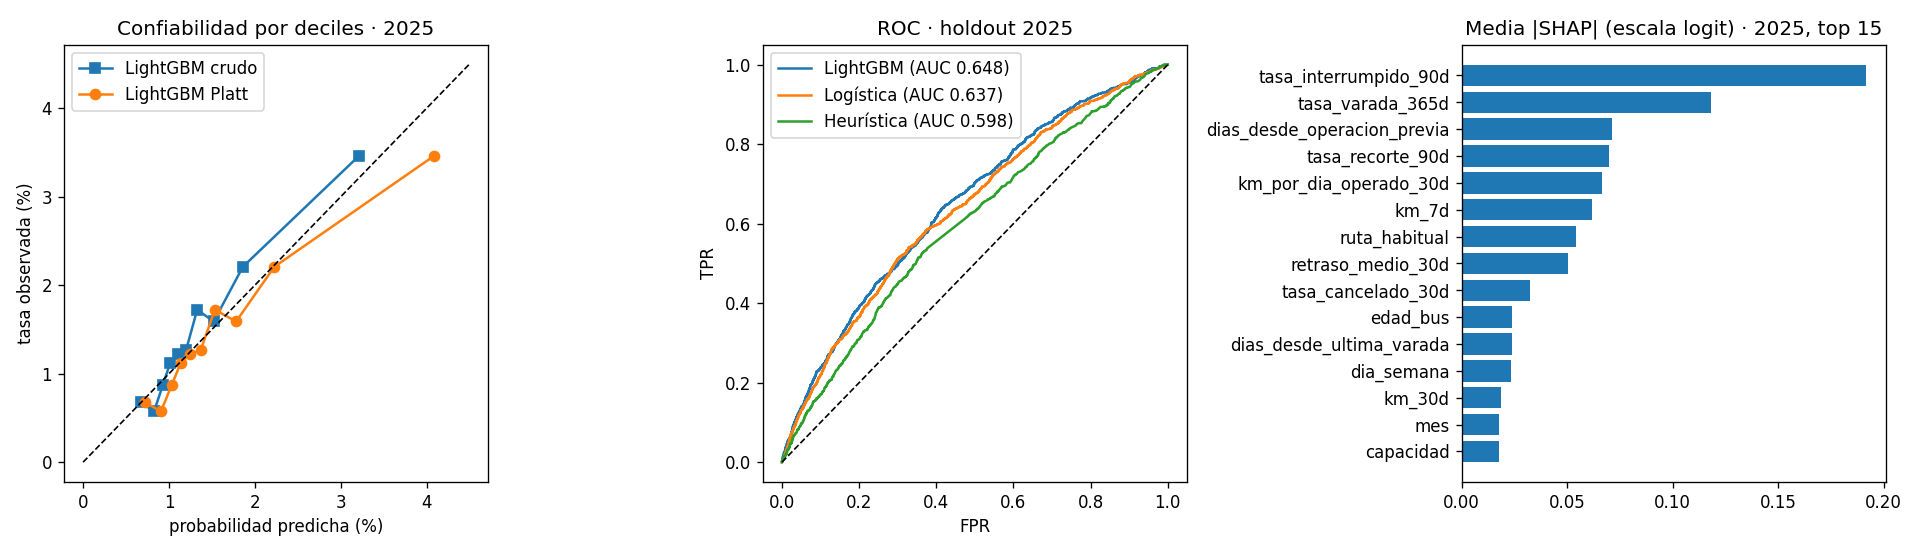

,shap_medio_abs,pct_shap,pct_gain
tasa_interrumpido_90d,0.1915,21.0%,18.2%
tasa_varada_365d,0.1180,12.9%,18.8%
dias_desde_operacion_previa,0.0711,7.8%,8.8%
tasa_recorte_90d,0.0697,7.6%,6.3%
km_por_dia_operado_30d,0.0663,7.3%,6.4%
km_7d,0.0618,6.8%,7.7%
ruta_habitual,0.0542,5.9%,5.6%
retraso_medio_30d,0.0504,5.5%,5.5%
tasa_cancelado_30d,0.0324,3.5%,1.9%
edad_bus,0.0241,2.6%,3.2%


In [8]:
# 4.3 · Figuras: confiabilidad, ROC e importancia (TreeSHAP)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for nombre, col, mk in [("crudo", "p_raw", "s"), ("Platt", "p_lgbm", "o")]:
    t = R.tabla_confiabilidad(yH, H[col])
    ax[0].plot(t.p_media * 100, t.tasa_observada * 100, marker=mk, label=f"LightGBM {nombre}")
lim = max(R.tabla_confiabilidad(yH, H[c]).p_media.max() for c in ["p_raw", "p_lgbm"]) * 110
ax[0].plot([0, lim], [0, lim], "k--", lw=1); ax[0].set_xlabel("probabilidad predicha (%)"); ax[0].set_ylabel("tasa observada (%)")
ax[0].set_title("Confiabilidad por deciles · 2025"); ax[0].legend()
for nombre, col in [("LightGBM", "p_lgbm"), ("Logística", "p_logit"), ("Heurística", "p_heur")]:
    fpr, tpr, _ = roc_curve(yH, H[col])
    ax[1].plot(fpr, tpr, label=f"{nombre} (AUC {R.delong(yH, H[col])[0][0]:.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_title("ROC · holdout 2025"); ax[1].legend(); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR")
contrib = art["modelo"].predict(H[FEATS], pred_contrib=True)[:, :-1]
shap = pd.Series(np.abs(contrib).mean(0), index=FEATS).sort_values()
gain = pd.Series(art["modelo"].feature_importance("gain"), index=FEATS)
imp = pd.DataFrame({"shap_medio_abs": shap, "pct_shap": shap / shap.sum(), "pct_gain": gain / gain.sum()}).sort_values("pct_shap", ascending=False)
imp.to_csv(SALIDA / "importancia_r2_9.csv")
ax[2].barh(shap.index[-15:], shap.values[-15:]); ax[2].set_title("Media |SHAP| (escala logit) · 2025, top 15")
figura("m9_r2_confiabilidad_roc_shap.png")
display(imp.head(12).style.format({"shap_medio_abs": "{:.4f}", "pct_shap": "{:.1%}", "pct_gain": "{:.1%}"}))
R.tabla_confiabilidad(yH, H.p_lgbm).to_csv(SALIDA / "confiabilidad_9.csv", index=False)

In [9]:
# 4.4 · Robustez con la Parte 1: ablación de documentos (E2) y etiqueta por motivo mecánico (E1)
ROB = []
if E2 is not None:
    art_sin = R.entrenar_r2(P, R.FEATURES_R2)
    p_sin = R.predecir_r2(art_sin, H)[1]
    d = R.delong_pareado(yH, H.p_lgbm, p_sin)
    cob = H[R.FEATURES_R2_VEHICULOS].notna().mean()
    print("Cobertura de las features de documentos en 2025:", cob.round(3).to_dict())
    ROB.append({"prueba": "con vs sin documentos (E2)", "auc_con": d["auc_1"], "auc_sin": d["auc_2"], "dif": d["dif"], "z": d["z"], "p": d["p"]})
    check("R2 · aporte de tecnomecánica / SOAT / inspección (DeLong pareado)", True,
          f"AUC {d['auc_1']:.4f} con vs {d['auc_2']:.4f} sin · ΔAUC {d['dif']:+.4f}, p {d['p']:.3f}", info=True)
if po is not None:
    Ho = H[["idvehiculo", "fecha", "p_lgbm"]].merge(po[["idvehiculo", "fecha", "y"]], on=["idvehiculo", "fecha"])
    if 0 < Ho.y.sum() < len(Ho):
        d = R.delong_vs_azar(Ho.y, Ho.p_lgbm)
        ROB.append({"prueba": "modelo proxy evaluado contra motivo mecánico (E1)", "auc_con": d["auc"], "z": d["z"], "p": d["p"],
                    "n_eventos": int(Ho.y.sum())})
        check("R2 · el modelo ordena también las varadas registradas en observacion", (d["auc"] > 0.5) and (d["p"] < 0.05),
              f"AUC {d['auc']:.3f} [{d['ic95_lo']:.3f}; {d['ic95_hi']:.3f}] sobre {int(Ho.y.sum())} bus-días mecánicos de 2025")
if ROB:
    rob = pd.DataFrame(ROB); rob.to_csv(SALIDA / "robustez_r2_9.csv", index=False); display(rob.round(4))
else:
    print("Sin pruebas de robustez: " + ("E1/E2 no extraídos." if not EXTRA else
          "la extracción no trae documentos (inspección / tecnomecánica / SOAT vacías) ni motivos mecánicos en observacion."))

Sin pruebas de robustez: la extracción no trae documentos (inspección / tecnomecánica / SOAT vacías) ni motivos mecánicos en observacion.


**Conclusión 4 · Sub-modelo de varadas (R2)**
- **Configuración elegida solo con 2024-S2:** 4 hojas, mínimo 1.000 por hoja y lr 0,02. AUC 0,638 frente a 0,633–0,637 de las otras tres; 222 rondas.
- **Holdout 2025: AUC 0,648 [0,631; 0,665]**, con DeLong frente al azar z = 16,9 y p = 2e-64. En los 12 meses el AUC queda entre 0,588 y 0,696.
- **Supera a las dos líneas base (DeLong pareado):**
  - a la heurística de la tasa histórica del bus (0,598): +0,051, p < 1e-8;
  - a la regresión logística con las mismas features (0,637): +0,012, p = 0,035.
- **Brier 0,01443 frente a 0,01449 de la climatología** (skill +0,41 %).
  - Murphy: confiabilidad 6e-6 y resolución 6,6e-5, frente a una incertidumbre de 0,0145.
  - Está bien calibrado, pero el evento es raro y la señal modesta: **el valor está en ordenar los buses, no en la probabilidad absoluta.**
- **Platt** (a = 1,110, b = 0,618) se mantiene porque el plan lo pide, pero en 2025 no mejora al modelo crudo:
  - Brier 0,01443 frente a 0,01442; ECE 0,0017 en ambos.
  - La media predicha queda en 1,60 % (crudo: 1,37 %), frente a 1,47 % real.
- **Foco de inspección:** revisar el 5 % de bus-días con más riesgo captura el **13,5 % de las varadas (lift 2,70)**; el 10 %, el 23,5 %; el 20 %, el 38,5 %.
  - La banda crítica (≥ P95) tuvo una tasa real de 3,98 % (2,7 × la media), aunque predecía 5,16 %: **sobreestima en la cola**.
- **Qué explica el riesgo (SHAP 2025):**
  - tasa de viajes interrumpidos en 90 días: 21,0 %;
  - tasa histórica de varadas: 12,9 %;
  - días desde la operación previa: 7,8 %;
  - recortes de ruta: 7,6 %;
  - km por día operado: 7,3 %.
- **La edad del bus pesa poco (2,6 %):** el desgaste se ve mejor en el uso y en los "casi-varadas" que en el año del modelo.
- **La extracción no cambia R2:** no aportó documentos ni motivos mecánicos, así que estas cifras son las definitivas.

## 5 · Traducción a P&L: recaudo perdido por varada

In [10]:
pl = R.perdida_por_varada(P[P.viajes_por_dia_28d.notna() & P.conjunto.isin(["train", "val", "calib", "holdout"])], v)
res = (pl.groupby(["anio", "y"]).agg(bus_dias=("y", "size"), viajes_perdidos=("viajes_perdidos", "mean"),
                                      recaudo_perdido_cop=("recaudo_perdido_cop", "mean")).unstack("y"))
atrib = pd.DataFrame({
    "varadas": res[("bus_dias", 1)],
    "viajes_perdidos_atribuibles": res[("viajes_perdidos", 1)] - res[("viajes_perdidos", 0)],
    "recaudo_atribuible_por_varada_cop": res[("recaudo_perdido_cop", 1)] - res[("recaudo_perdido_cop", 0)]})
atrib["recaudo_atribuible_total_cop"] = atrib.varadas * atrib.recaudo_atribuible_por_varada_cop
display(atrib.style.format({"viajes_perdidos_atribuibles": "{:.2f}", "recaudo_atribuible_por_varada_cop": "{:,.0f}",
                            "recaudo_atribuible_total_cop": "{:,.0f}"}))
pl25 = pl[pl.anio == 2025]
por_ruta = (pl25.groupby(["idruta", "y"]).recaudo_perdido_cop.mean().unstack("y").pipe(lambda d: d[1] - d[0])
            .rename("recaudo_atribuible_por_varada_cop"))
display(por_ruta.to_frame().style.format("{:,.0f}"))
L25 = atrib.loc[2025, "recaudo_atribuible_por_varada_cop"]
Hpl = H.merge(pl25[["idvehiculo", "fecha", "idruta"]], on=["idvehiculo", "fecha"], how="left")
Hpl["L"] = Hpl.idruta.map(por_ruta).fillna(L25)
foco = []
for f in [0.05, 0.10, 0.20]:
    k = int(np.ceil(f * len(Hpl))); top = Hpl.nlargest(k, "p_lgbm")
    foco.append({"revisar_top": f, "bus_dias_revisados": k, "varadas_en_el_foco": int(top.y.sum()),
                 "captura": top.y.sum() / Hpl.y.sum(), "recaudo_en_riesgo_cop": float((top.y * top.L).sum())})
foco = pd.DataFrame(foco)
display(foco.style.format({"captura": "{:.1%}", "recaudo_en_riesgo_cop": "{:,.0f}"}))
pd.concat([atrib.reset_index().assign(nivel="anual"), por_ruta.reset_index().assign(nivel="ruta_2025")]).to_csv(SALIDA / "pyl_varadas_9.csv", index=False)
foco.to_csv(SALIDA / "pyl_foco_inspeccion_9.csv", index=False)
check("P&L · la varada reduce viajes frente a bus-días sin varada", (atrib.viajes_perdidos_atribuibles > 0).all(),
      f"2025: {atrib.loc[2025, 'viajes_perdidos_atribuibles']:.2f} viajes y {L25:,.0f} COP por varada", info=True)

,varadas,viajes_perdidos_atribuibles,recaudo_atribuible_por_varada_cop,recaudo_atribuible_total_cop
anio,,,,
2023,532,0.58,"181,675","96,651,008"
2024,873,0.51,"155,673","135,902,165"
2025,979,0.59,"165,341","161,869,237"


,recaudo_atribuible_por_varada_cop
idruta,
2.000000,"210,898"
16.000000,"203,349"
21.000000,"68,185"


,revisar_top,bus_dias_revisados,varadas_en_el_foco,captura,recaudo_en_riesgo_cop
0,0.050000,3396,135,13.5%,"24,358,006"
1,0.100000,6792,235,23.5%,"41,102,275"
2,0.200000,13584,385,38.5%,"66,199,926"


**Conclusión 5 · P&L**
- **Costo por varada:** en 2025, una varada quita **0,59 viajes netos** ese día frente a un bus-día sin varada. Eso equivale a ≈ **165.341 COP** de recaudo esperado (tarifa de 3.700 COP × mediana de pasajeros de la ruta).
- **Total anual:** 96,7 M COP (2023) → 135,9 M (2024) → **161,9 M COP (2025, 979 varadas)**. Crece con la tasa.
- **Por ruta (2025):** ruta 2 ≈ 210.898, ruta 16 ≈ 203.349 y ruta 21 ≈ 68.185 COP por varada.
- **Valor del foco:** revisar cada día el 10 % de bus-días con más riesgo habría puesto en foco 235 varadas y **41,1 M COP de recaudo en riesgo** en 2025 (top 5 %: 24,4 M; top 20 %: 66,2 M).
  - Esto es recaudo **en riesgo**, no ahorro. El ahorro depende de cuántas varadas evite la revisión preventiva, un dato que debe aportar SOBUSA.
- **No incluye** grúa, taller ni penalidades: no existen en la base, así que la pérdida está subestimada.

## 6 · Velocidad GPS por viaje (exceso > 60 km/h)

Muestra local: 1,671 viajes, 893,734 tramos válidos de 969,662 (92.2%)


,viajes,pct_tiempo_sobre_60,viajes_con_exceso,v_p95_mediana,v_max_p99
idruta,,,,,
2,530,0.068%,10.9%,33.7,98.8
16,596,0.083%,11.6%,34.8,111.2
21,545,0.083%,11.2%,34.2,93.3


Tiempo sobre 60 km/h: 0.078% · viajes con algún tramo > 60 km/h: 11.3% · viajes por bus en la muestra: mediana 5, buses con ≥ 5: 167 de 332
E3: 11,891 viajes · tiempo sobre 60 km/h 0.032% · viajes con algún tramo > 60 km/h 6.1% · P95 mediano 33.9 km/h
Velocidades usadas en R3: E3 (muestra por conductor)


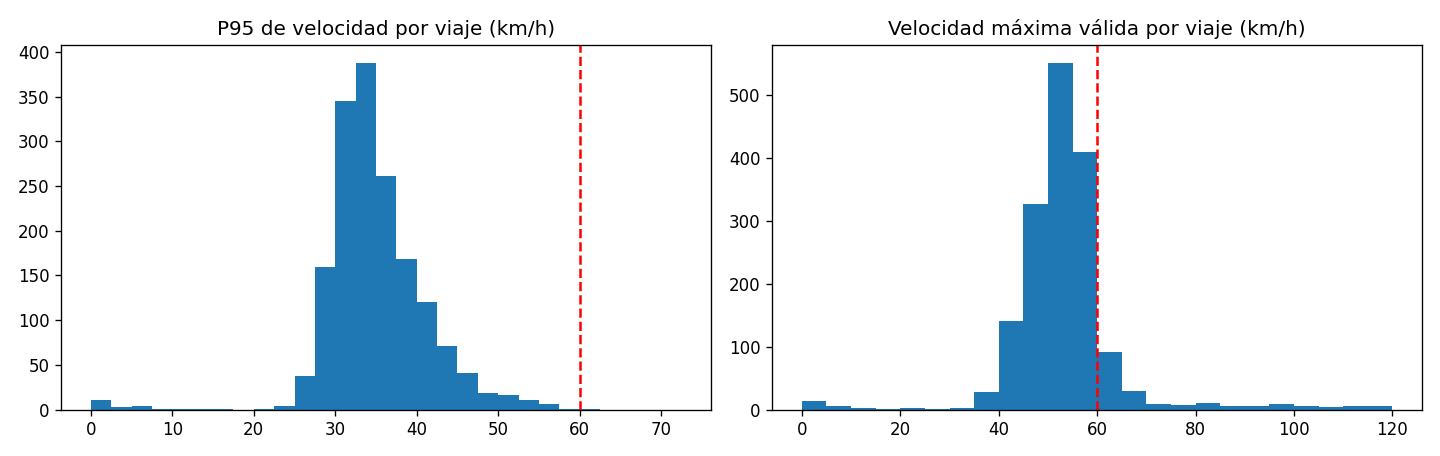

In [11]:
lect = pd.read_parquet(raiz / "maestras" / "tb_maestra_conteo_destino_limpio_muestra.parquet",
                       columns=["id", "idprogramacion", "fecha", "latitud", "longitud"])
vel_local = R.velocidad_por_viaje(lect)
vel_local = vel_local.merge(v[["idprogramacion", "idvehiculo", "idruta", "fecha"]], on="idprogramacion", how="left")
vel_local.to_csv(SALIDA / "velocidad_muestra_local_9.csv", index=False)
vl = vel_local[vel_local.seg_validos > 0]
print(f"Muestra local: {len(vl):,} viajes, {vl.n_validos.sum():,} tramos válidos de {vl.n_tramos.sum():,} "
      f"({vl.n_validos.sum() / vl.n_tramos.sum():.1%})")
resumen_vel = vl.assign(exceso=vl.seg_exceso_60 > 0, pct_tiempo=vl.seg_exceso_60 / vl.seg_validos).groupby("idruta").agg(
    viajes=("idprogramacion", "size"), pct_tiempo_sobre_60=("seg_exceso_60", "sum"), seg=("seg_validos", "sum"),
    viajes_con_exceso=("exceso", "mean"), v_p95_mediana=("v_p95", "median"), v_max_p99=("v_max", lambda s: s.quantile(.99)))
resumen_vel["pct_tiempo_sobre_60"] = resumen_vel.pct_tiempo_sobre_60 / resumen_vel.pop("seg")
display(resumen_vel.style.format({"pct_tiempo_sobre_60": "{:.3%}", "viajes_con_exceso": "{:.1%}", "v_p95_mediana": "{:.1f}", "v_max_p99": "{:.1f}"}))
glob = vl.seg_exceso_60.sum() / vl.seg_validos.sum()
viajes_bus = vl.groupby("idvehiculo").size()
print(f"Tiempo sobre 60 km/h: {glob:.3%} · viajes con algún tramo > 60 km/h: {(vl.seg_exceso_60 > 0).mean():.1%} · "
      f"viajes por bus en la muestra: mediana {viajes_bus.median():.0f}, buses con ≥ 5: {(viajes_bus >= 5).sum()} de {len(viajes_bus)}")
VEL = EXTRA.get("velocidad", vel_local)
if "velocidad" in EXTRA:
    e3 = EXTRA["velocidad"]; e3v = e3[e3.seg_validos > 0]
    print(f"E3: {len(e3):,} viajes · tiempo sobre 60 km/h {e3v.seg_exceso_60.sum() / e3v.seg_validos.sum():.3%} · "
          f"viajes con algún tramo > 60 km/h {(e3v.seg_exceso_60 > 0).mean():.1%} · P95 mediano {e3v.v_p95.median():.1f} km/h")
    comun = e3.merge(vel_local, on="idprogramacion", suffixes=("_sql", "_pd"))
    if len(comun):
        dif = max((comun[f"{c}_sql"] - comun[f"{c}_pd"]).abs().max() for c in ["n_tramos", "n_validos", "seg_validos", "seg_exceso_60"])
        check("Velocidad · SQL (E3) = pandas en los viajes comunes", dif < 1e-3, f"{len(comun)} viajes · diferencia máxima {dif:.2e}")
    else:
        check("Velocidad · SQL (E3) = pandas en los viajes comunes", True, "sin viajes en común con la muestra local", info=True)
print("Velocidades usadas en R3:", "E3 (muestra por conductor)" if "velocidad" in EXTRA else "muestra local del Módulo 1.3")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(vl.v_p95, bins=np.arange(0, 75, 2.5)); ax[0].axvline(60, color="r", ls="--"); ax[0].set_title("P95 de velocidad por viaje (km/h)")
ax[1].hist(vl.v_max, bins=np.arange(0, 125, 5)); ax[1].axvline(60, color="r", ls="--"); ax[1].set_title("Velocidad máxima válida por viaje (km/h)")
figura("m9_velocidad_gps.png")
check("Velocidad · fracción de tramos válidos", vl.n_validos.sum() / vl.n_tramos.sum() > 0.8,
      f"{vl.n_validos.sum() / vl.n_tramos.sum():.1%} (2 s ≤ Δt ≤ 60 s y ≤ 120 km/h)")

**Conclusión 6 · Velocidad GPS**
- **E3:** 11.891 viajes (hasta 4 por conductor y semestre), con velocidades calculadas en el servidor. **SQL = pandas:** en los 37 viajes que coinciden con la muestra local, la diferencia es exactamente 0.
- **Exceder 60 km/h es raro:**
  - 0,032 % del tiempo de conducción;
  - el 6,1 % de los viajes tiene algún tramo por encima (4,8 % con ≥ 30 s);
  - el P95 por viaje tiene una mediana de 33,9 km/h.
  - En la muestra local del Módulo 1.3: 0,078 % del tiempo y 11,3 % de los viajes, igual en las 3 rutas.
- **Ahora sí hay cobertura para el score:** tienen ≥ 5 viajes con GPS el 96,6 % y el 94,9 % de los buses elegibles (2024 / 2025) y el 75,0 % y el 77,1 % de los conductores. El componente de velocidad entra al score.
- **Es una señal casi independiente** de las demás (correlaciones ≤ 0,10; carga en la CP1 ≤ 0,102). Su peso viene sobre todo del criterio experto: 0,15–0,18 en el peso final.

## 7 · Score conductual (R3)

idconductor genéricos excluidos (> 6 viajes por día operado): ['799'] · 48,675 viajes iniciados (8.7%) quedan sin conductor


experto    pca  final  carga_cp1  alpha_eb
idvehiculo 2024  velocidad        0.3  0.051  0.176      0.102     1.089
                 persecucion      0.2  0.261  0.230     -0.520    28.942
                 bloqueo          0.2  0.111  0.155      0.221     2.010
                 recorte          0.2  0.256  0.228      0.511    13.590
                 retraso          0.1  0.321  0.211      0.640     6.085
idvehiculo 2025  velocidad        0.3  0.032  0.166      0.060     0.605
                 persecucion      0.2  0.343  0.272     -0.637    22.902
                 bloqueo          0.2  0.050  0.125      0.093     2.141
                 recorte          0.2  0.237  0.218      0.439     2.811
                 retraso          0.1  0.337  0.218      0.624     3.543
idconductor 2024 velocidad        0.3  0.004  0.152      0.006     0.467
                 persecucion      0.2  0.399  0.299     -0.673    18.892
                 bloqueo          0.2  0.040  0.120      0.068     2.417
                 recorte          0.2  0.146  0.173      0.247     1.648
                 retraso          0.1  0.411  0.256      0.694     1.870
idconductor 2025 velocidad        0.3  0.023  0.161      0.042     2.729
                 persecucion      0.2  0.349  0.275     -0.642    18.541
                 bloqueo          0.2  0.066  0.133      0.121     2.510
                 recorte          0.2  0.206  0.203      0.379     0.481
                 retraso          0.1  0.356  0.228      0.654     1.642

('idvehiculo', 2024): 264 de 411 entidades con ≥ 100 viajes · CP1 explica 29.3% · Spearman experto–PCA 0.37 · excluidos: —
('idvehiculo', 2025): 275 de 421 entidades con ≥ 100 viajes · CP1 explica 32.3% · Spearman experto–PCA 0.16 · excluidos: —
('idconductor', 2024): 384 de 660 entidades con ≥ 100 viajes · CP1 explica 26.7% · Spearman experto–PCA 0.06 · excluidos: —
('idconductor', 2025): 371 de 627 entidades con ≥ 100 viajes · CP1 explica 29.1% · Spearman experto–PCA 0.14 · excluidos: —
Correlación entre componentes (vehículo, 2024):


,z_velocidad,z_persecucion,z_bloqueo,z_recorte,z_retraso
z_velocidad,1.00,0.06,0.09,-0.02,0.10
z_persecucion,0.06,1.00,-0.09,-0.07,-0.30
z_bloqueo,0.09,-0.09,1.00,0.12,-0.03
z_recorte,-0.02,-0.07,0.12,1.00,0.27
z_retraso,0.10,-0.30,-0.03,0.27,1.00


Correlación entre componentes (conductor, 2024):


,z_velocidad,z_persecucion,z_bloqueo,z_recorte,z_retraso
z_velocidad,1.00,0.06,0.05,-0.05,0.08
z_persecucion,0.06,1.00,-0.05,-0.02,-0.31
z_bloqueo,0.05,-0.05,1.00,0.03,-0.03
z_recorte,-0.05,-0.02,0.03,1.00,0.10
z_retraso,0.08,-0.31,-0.03,0.10,1.00


,entidad,resultado,n,n_malos,auc,gini,gini_ic95_lo,gini_ic95_hi,p_delong,ks,p_ks,spearman_ref_fut
0,vehículo,persistencia: riesgo futuro en el cuartil superior,255,64,0.711,0.422,0.286,0.559,1.3e-09,0.346,1.4e-05,0.399
1,vehículo,externo: tasa futura de varadas en el cuartil superior,255,64,0.602,0.204,0.049,0.358,9.9e-03,0.200,3.8e-02,0.399
2,conductor,persistencia: riesgo futuro en el cuartil superior,236,59,0.718,0.435,0.294,0.577,1.6e-09,0.362,1.3e-05,0.438
3,conductor,externo: tasa futura de varadas en el cuartil superior,236,59,0.561,0.122,-0.048,0.291,1.6e-01,0.141,3.3e-01,0.438


,decil_score,n,score_medio,tasa_malos,riesgo_fut_medio
0,1,26,4.9,53.8%,+0.226
1,2,25,14.6,32.0%,+0.103
2,3,26,24.2,38.5%,+0.182
3,4,25,34.2,24.0%,+0.044
4,5,26,43.9,26.9%,-0.034
5,6,25,54.1,28.0%,+0.099
6,7,25,64.6,28.0%,+0.062
7,8,26,74.6,11.5%,-0.084
8,9,25,84.3,8.0%,-0.267
9,10,26,94.8,0.0%,-0.392


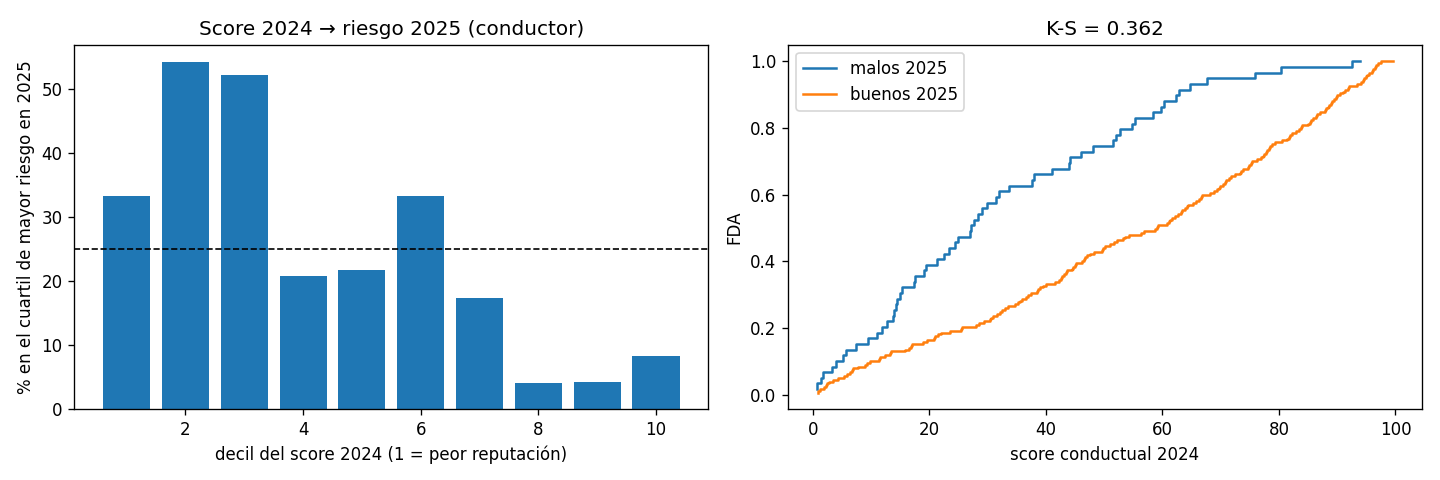

In [12]:
ev = R.eventos_conductuales(v, VEL)
ENTIDADES = [("idvehiculo", "vehículo")] + ([("idconductor", "conductor")] if "idconductor" in v else [])
if "idconductor" in v:
    e1 = EXTRA["progvehiculos"]
    gen = R.conductores_genericos(v.assign(idconductor=pd.to_numeric(v.idprogramacion.map(e1.set_index("idprogramacion").idconductor)).astype("Int64").astype("string")))
    sin = v.inicio & v.idconductor.isna()
    print(f"idconductor genéricos excluidos (> {CFG.max_viajes_dia_conductor:g} viajes por día operado): {gen} · "
          f"{int(sin.sum()):,} viajes iniciados ({sin.mean() / v.inicio.mean():.1%}) quedan sin conductor")
    check("R3 · IDs de conductor genéricos excluidos", True, f"{gen}: {int(sin.sum()):,} viajes sin conductor real", info=True)
SC, INFO, VAL, DEC = {}, {}, {}, {}
for id_col, nombre in ENTIDADES:
    for anio in (2024, 2025):
        SC[(id_col, anio)], INFO[(id_col, anio)] = R.score_conductual(ev, id_col, f"{anio}-01-01", f"{anio + 1}-01-01")
        SC[(id_col, anio)].to_csv(SALIDA / f"score_conductual_{id_col}_{anio}_9.csv", index=False)
    ext = v[(v.fecha >= "2025-01-01") & v.inicio].groupby(id_col).varada_proxy.mean()
    VAL[id_col], DEC[id_col] = R.validar_score(SC[(id_col, 2024)], SC[(id_col, 2025)], id_col, ext)
    VAL[id_col].insert(0, "entidad", nombre)

pesos = pd.concat({f"{id_col} {a}": pd.DataFrame({"experto": INFO[(id_col, a)]["pesos_experto"], "pca": INFO[(id_col, a)]["pesos_pca"],
                                                  "final": INFO[(id_col, a)]["pesos"], "carga_cp1": INFO[(id_col, a)]["carga_cp1"],
                                                  "alpha_eb": INFO[(id_col, a)]["alpha"]})
                   for id_col, _ in ENTIDADES for a in (2024, 2025)})
pesos.to_csv(SALIDA / "pesos_score_9.csv")
display(pesos.round(3))
for k, i in INFO.items():
    print(f"{k}: {i['n_elegibles']} de {i['n_entidades']} entidades con ≥ {CFG.min_viajes_score} viajes · "
          f"CP1 explica {i['varianza_cp1']:.1%} · Spearman experto–PCA {i['spearman_experto_pca']:.2f} · excluidos: {i['excluidos'] or '—'}")
for id_col, nombre in ENTIDADES:
    s_ = SC[(id_col, 2024)]
    print(f"Correlación entre componentes ({nombre}, 2024):")
    display(s_[[c for c in s_ if c.startswith("z_")]].corr().round(2))
val = pd.concat(VAL.values(), ignore_index=True)
val.to_csv(SALIDA / "validacion_score_9.csv", index=False)
display(val.style.format({c: "{:.3f}" for c in ["auc", "gini", "gini_ic95_lo", "gini_ic95_hi", "ks", "spearman_ref_fut"]}
                         | {"p_delong": "{:.1e}", "p_ks": "{:.1e}"}))
display(DEC["idvehiculo"].style.format({"score_medio": "{:.1f}", "tasa_malos": "{:.1%}", "riesgo_fut_medio": "{:+.3f}"}))

id_fig = ENTIDADES[-1][0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
d = DEC[id_fig]
ax[0].bar(d.decil_score, d.tasa_malos * 100); ax[0].axhline(25, color="k", ls="--", lw=1)
ax[0].set_xlabel("decil del score 2024 (1 = peor reputación)"); ax[0].set_ylabel("% en el cuartil de mayor riesgo en 2025")
ax[0].set_title(f"Score 2024 → riesgo 2025 ({ENTIDADES[-1][1]})")
m = SC[(id_fig, 2024)].merge(SC[(id_fig, 2025)][[id_fig, "riesgo"]].rename(columns={"riesgo": "rf"}), on=id_fig)
malo = m.rf >= m.rf.quantile(0.75)
for lab, s in [("malos 2025", m.score_conductual[malo]), ("buenos 2025", m.score_conductual[~malo])]:
    xs = np.sort(s); ax[1].step(xs, np.arange(1, len(xs) + 1) / len(xs), label=lab)
ax[1].set_xlabel("score conductual 2024"); ax[1].set_ylabel("FDA"); ax[1].set_title(f"K-S = {VAL[id_fig].ks.iloc[0]:.3f}"); ax[1].legend()
figura("m9_r3_validacion_score.png")
for _, f in val.iterrows():
    principal = f.resultado.startswith("persistencia")
    check(f"R3 · {f.entidad} · {f.resultado.split(':')[0]} (Gini y K-S)", (f.gini > 0) and (f.p_delong < 0.05) and (f.p_ks < 0.05),
          f"Gini {f.gini:.3f} [{f.gini_ic95_lo:.3f}; {f.gini_ic95_hi:.3f}] (p {f.p_delong:.1e}) · KS {f.ks:.3f} (p {f.p_ks:.1e}) · n {f.n}",
          info=not principal)

**Conclusión 7 · Score conductual (R3)**
- **Conductores:** 1.010 `idconductor` distintos.
  - El **799 es un ID genérico, no una persona**: 8,8 % de los viajes, 443 buses y 45 viajes por día operado, frente a un P99 de 3,35 en los conductores reales. Se excluye con la regla "> 6 viajes por día" y deja 48.675 viajes (8,7 %) sin conductor real.
  - Elegibles (≥ 100 viajes): 384 conductores en 2024 y 371 en 2025. Vehículos: 264 y 275.
- **5 componentes:** velocidad > 60 km/h, persecución, bloqueo, recorte de ruta (50–90 %) y retraso de despacho > 5 min. La persecución es una salida adelantada que comprime el intervalo con el bus anterior, atribuida al bus solo si al menos la mitad de la compresión es suya.
- **Pesos finales por conductor (2024):** persecución 0,30, retraso 0,26, recorte 0,17, velocidad 0,15 y bloqueo 0,12.
- **La CP1 (26,7 % de la varianza) no es un factor único de "mal conductor":** persecución carga opuesta a retraso (correlación −0,31). Los que salen adelantados no son los que salen tarde.
  - Por eso los signos se fijan por criterio de negocio (todo penaliza) y la PCA solo aporta magnitudes.
- **Validación fuera de tiempo (score 2024 → riesgo 2025):**
  - **Conductor (n = 236): Gini 0,435 [0,294; 0,577], KS 0,362 (p = 1,3e-5)**, Spearman 0,44. Los deciles 2–3 tienen un 52–54 % en el cuartil de mayor riesgo de 2025; los deciles 8–10, entre 4 % y 8 %.
  - **Vehículo (n = 255): Gini 0,422 [0,286; 0,559], KS 0,346 (p = 1,4e-5)**, Spearman 0,40. Del decil peor, el 53,8 % termina en el cuartil de mayor riesgo; del mejor, el 0 %.
- **Contra las varadas de 2025:**
  - por vehículo, Gini 0,204 (p = 0,010) y KS 0,200 (p = 0,038);
  - **por conductor no es significativo** (Gini 0,122 [−0,048; 0,291]): la varada es una propiedad del bus, no de quien lo conduce.

## 8 · Tabla `tb_scoring_vehiculo_conductor`

In [13]:
fecha_pred = pd.Timestamp(CFG.fecha_scoring)
filas_sc = pd.DataFrame({"idvehiculo": sorted(v.idvehiculo.unique()), "fecha": fecha_pred})
Xs = R.features_r2(v, filas_sc, ETIQUETA, vehiculos=veh, calendario=cal, vehiculos_extra=E2)
Xs = Xs[Xs.dias_operados_30d > 0].copy()
_, Xs["p_varada_jornada"] = R.predecir_r2(art, Xs)
tasa_base = float(yH.mean())
Xs["banda_riesgo_varada"] = R.banda_varada(Xs.p_varada_jornada.to_numpy(), CORTES)
Xs["perdida_esperada_cop"] = Xs.p_varada_jornada * Xs.ruta_habitual.map(por_ruta).fillna(L25)
riesgo_veh = Xs[["idvehiculo", "ruta_habitual", "p_varada_jornada", "banda_riesgo_varada", "perdida_esperada_cop"]]
id_c = "idconductor" if "idconductor" in v else None
tabla = R.construir_tabla("2025-12-31", CFG.fecha_scoring, riesgo_veh, SC[("idvehiculo", 2025)],
                          SC[(id_c, 2025)] if id_c else None, INFO[("idvehiculo", 2025)], INFO[(id_c, 2025)] if id_c else None)
tabla.to_parquet(SALIDA / "tb_scoring_vehiculo_conductor.parquet", index=False)
tabla.to_csv(SALIDA / "tb_scoring_vehiculo_conductor.csv", index=False)
print(f"{len(tabla):,} filas · " + " · ".join(f"{k}: {n}" for k, n in tabla.tipo_entidad.value_counts().items()))
tv = tabla[tabla.tipo_entidad == "vehiculo"]
bandas = tv.groupby("banda_riesgo_varada").agg(buses=("id_entidad", "size"), p_media=("p_varada_jornada", "mean"),
                                               perdida_esperada_total_cop=("perdida_esperada_cop", "sum"))
display(bandas.style.format({"p_media": "{:.2%}", "perdida_esperada_total_cop": "{:,.0f}"}))
display(pd.crosstab(tv.banda_riesgo_varada, tv.banda_conductual, margins=True))
display(tv.nlargest(10, "p_varada_jornada")[["id_entidad", "idruta_habitual", "p_varada_jornada", "banda_riesgo_varada",
                                             "perdida_esperada_cop", "score_conductual", "banda_conductual"]])
pk_ok = not tabla.duplicated(["fecha_corte", "tipo_entidad", "id_entidad"]).any()
rango_ok = tv.p_varada_jornada.dropna().between(0, 1).all() and tabla.score_conductual.dropna().between(0, 100).all()
check("Tabla · llave primaria única", pk_ok, f"{len(tabla):,} filas")
check("Tabla · rangos válidos (p ∈ [0, 1], score ∈ [0, 100])", rango_ok,
      f"{tv.p_varada_jornada.notna().sum()} buses con p · {tabla.score_conductual.notna().sum()} entidades con score")

719 filas · conductor: 371 · vehiculo: 348


,buses,p_media,perdida_esperada_total_cop
banda_riesgo_varada,,,
alto,65,2.54%,"275,995"
bajo,109,0.91%,"139,770"
critico,39,5.53%,"400,818"
medio,121,1.46%,"257,106"


banda_conductual,A,B,C,D,E,All
banda_riesgo_varada,,,,,,
alto,8,8,14,16,11,57
bajo,24,13,10,14,8,69
critico,5,9,6,5,11,36
medio,17,23,21,18,20,99
All,54,53,51,53,50,261


,id_entidad,idruta_habitual,p_varada_jornada,banda_riesgo_varada,perdida_esperada_cop,score_conductual,banda_conductual
507,SOBUSA35,2.0,0.106318,critico,22422.142144,16.545455,E
375,SOBUSA07,2.0,0.102281,critico,21570.809509,71.818182,B
382,SOBUSA112,2.0,0.098788,critico,20834.052032,30.727273,D
607,SOBUSA491,16.0,0.088212,critico,17937.743716,32.181818,D
576,SOBUSA457,2.0,0.082637,critico,17427.999976,69.272727,B
371,SOBUSA03,2.0,0.074864,critico,15788.595148,13.636364,E
669,SOBUSA570,21.0,0.072028,critico,4911.266623,72.909091,B
516,SOBUSA371,2.0,0.069926,critico,14747.289002,28.909091,D
462,SOBUSA265,2.0,0.069687,critico,14696.830593,18.363636,E
505,SOBUSA346,21.0,0.064596,critico,4404.514041,70.363636,B


**Conclusión 8 · Tabla de scoring**
- **719 filas** con corte el 2025-12-31 y predicción para el 2026-01-01:
  - **348 vehículos:** 334 con p, 275 con score y 261 con ambos;
  - **371 conductores**, en quintiles (≈ 74 por banda A–E).
- **Bandas de varada** (cortes = P40 / P80 / P95 de p en 2025): 109 bajo, 121 medio, 65 alto y **39 crítico**.
  - Crítico es el 11,7 % de los buses, frente al 5 % de los bus-días de 2025, por dos razones:
    - la foto pesa igual a los buses que operan poco (con ≤ 20 de 30 días operados, 16–18 % son críticos, frente a 3–4 %);
    - diciembre es el mes con la tasa más alta (1,88 %).
- **Pérdida esperada de la jornada:** 1,07 M COP, de los cuales 0,40 M (37 %) vienen de los 39 buses críticos.
- **Riesgo de varada y reputación del bus se relacionan débilmente** (Spearman −0,196). 11 buses son a la vez críticos en varada y E en conducta: prioridad de revisión.
- `sql/tb_scoring_vehiculo_conductor.sql` trae el DDL para el DBA; la tabla está materializada en `datos_9/` (Parquet y CSV).

## 9 · Pruebas y checks

In [14]:
pruebas = T.correr_todos(v, P, art)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
check("Tiempo total de la ejecución", True, f"{(time.time() - T0) / 60:,.1f} min", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_9.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,Auditoría de fuentes,INFO,14/14 variables del plan existen en la RDS; 4 están en los archivos locales; bloqueo_cond/bloqueo_veh 0% n...
1,Etiqueta · auditoría contra observacion (E1),INFO,"0 motivos mecánicos en 49,331 observaciones (3 valores distintos)"
2,Etiqueta · varada → más ausencias al día siguiente,PASS,44.5% vs 24.9% (p 1.9e-113); lun–jue 38.1% vs 18.9%
3,Etiqueta · heterogeneidad entre buses,PASS,índice de dispersión 3.38 (> 1 = no es ruido homogéneo)
4,Panel · partición temporal ordenada,PASS,calentamiento < train < val < calib < holdout
5,R2 · R.PARAMS_R2 = la configuración con mejor AUC en 2024-S2,PASS,"elegida: C · 4 hojas, min 1000, lr 0,02"
6,"R2 · AUC > 0,5 (DeLong vs azar)",PASS,"AUC 0.648 [0.631; 0.665], p 2.0e-64"
7,R2 · LightGBM vs logística (DeLong pareado),INFO,"ΔAUC +0.0116, z 2.11, p 0.0348 → diferencia significativa"
8,R2 · LightGBM vs heurística (DeLong pareado),INFO,"ΔAUC +0.0507, z 6.04, p 0.0000 → diferencia significativa"
9,R2 · Brier < climatología,PASS,0.01443 vs 0.01449 (skill +0.41%)


PASS 23 · FAIL 0 · INFO 9


**Conclusión 9 · Pruebas**
- **23 PASS, 0 FAIL, 9 INFO.** Pasan las **10 de 10 pruebas** (`py -3.10 tests_9.py`):
  - **a)** features sin fuga, con control;
  - **b)** holdout intocado: invertir las etiquetas de 2025 no cambia ni el modelo ni Platt;
  - **c)** DeLong = sklearn (error < 1e-12), varianza / bootstrap = 1,05 y tamaño 6,2 %;
  - **d)** Platt recupera (2, −3);
  - **e)** la contracción bayesiana recupera α (5,18 frente a 5) y baja el ECM;
  - **f)** velocidades exactas a 72 km/h, con el salto de GPS excluido;
  - **g)** el score ordena y es invariante al orden;
  - **h)** Gini y K-S en los extremos;
  - **i)** determinismo;
  - **j)** la foto de `vehiculos` no se usa antes de su vigencia.
- Además, la velocidad calculada en SQL (E3) coincide exactamente con la calculada en pandas.
- **Honestidad sobre 2025:** durante el desarrollo, 2025 se miró en varias corridas (5) antes de fijar el modelo, y eso llevó a quitar `dias_historia` (Conclusión 3).
  - La selección de hiperparámetros usó solo 2024-S2.
  - La extracción no cambió R2.
  - La cifra oficial es la de esta ejecución.
- Ejecución: 0,5 min.

## Síntesis para el jurado y pendientes

| Pregunta | Respuesta (holdout 2025) |
|---|---|
| ¿Se puede anticipar qué bus se vara? | Sí, de forma **modesta pero significativa**: AUC 0,648 (DeLong p = 2e-64). El top 5 % de riesgo concentra 2,7 × la tasa media |
| ¿Cuánto cuesta una varada? | ≈ 165 mil COP de recaudo por evento, **161,9 M COP en 2025**, y la cifra crece cada año |
| ¿Cuánto recaudo pone en foco el modelo? | Revisar el 10 % de bus-días más riesgosos cubre el 23,5 % de las varadas y 41,1 M COP de recaudo en riesgo |
| ¿El score conductual es estable y predictivo? | Sí. Por conductor: Gini 0,435 y KS 0,362 del score 2024 sobre el riesgo de 2025 (por vehículo: 0,422 y 0,346) |

**Hallazgos de datos que debe conocer SOBUSA:**
- Inspección, revisión técnico-mecánica y SOAT están **vacías** en `vehiculos`.
- `observacion` **no registra motivos de varada**: solo tiene 3 valores, todos automáticos.
- El `idconductor` 799 agrupa el **8,7 % de los viajes** sin un conductor real.
- Registrar estos tres datos mejoraría directamente R2 y R3.

**Pendientes y riesgos:**
- **Etiqueta proxy:** validarla con la bitácora de taller o grúas de SOBUSA.
- **Historial de inspecciones:** no existe en la base. Sin él, el "% de inspecciones reprobadas" del plan no es construible.
- **P&L:** faltan los costos de grúa, taller y penalidades para pasar de recaudo en riesgo a ahorro neto.
- **Producción:** recalibrar cada mes (la tasa sube de 0,97 % a 1,47 % en tres años) y revisar la sobreestimación en la banda crítica.
- **Insumos para los Módulos 13 y 14:** `p_varada_jornada` alimenta los imprevistos del Monte Carlo (Módulo 13) y la flota disponible del redespacho (Módulo 14).

---
# Parte 3 · Módulo 10 · Subfase 10.1 · Red vial
*Notebook original: `modulo10/subfase_10_1_red_vial.ipynb`*

# SOBUSA · Módulo 10 · Subfase 10.1 — Red vial base y ubicación de reportes por GPS

**Persona 3.** El Módulo 10 convierte reportes de conductores (texto o audio) en eventos de tráfico con lugar y hora. Esta subfase resuelve **el lugar**: el conductor nunca da coordenadas; el reporte se ubica con el **GPS de su propio bus** en la red de segmentos que SOBUSA ya tiene en la base de datos.

| Paso | Qué se hizo | Dónde |
|---|---|---|
| Parte 1 · extracción | Solo lectura: catálogo, rutas, configuración y los 386 segmentos de las rutas 2, 16 y 21 con su geometría | `extraer_10_1.py` → `datos_10/extraccion/` |
| Parte 2 · librería | Polilínea por ruta con avance acumulado, búsqueda KD a 5 m, emparejamiento de trayectorias (Viterbi) y ubicación de reportes | `src/geo/red_vial.py` |
| Parte 2 · validación | 971.335 lecturas GPS del Entregable 1 (1.673 viajes, 2023–2025) | `analisis_10_1.py` → `datos_10/` |
| Pruebas | Ruta sintética de ida y vuelta por la misma vía + extracción real | `tests_10_1.py` |

Sin API de Claude en esta subfase (costo $0). Sin contraseñas ni credenciales en ningún archivo.

## Parte 2 · Análisis offline

In [1]:
import json
import platform
import subprocess
import sys
from pathlib import Path
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, "src")
from geo import red_vial as rv

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
D = Path("datos_10"); EXT = D / "extraccion"; FIG = Path("resultados_10"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
def check(nombre: str, ok: bool, detalle: str = "") -> None:
    CHECKS.append({"check": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": detalle})

RES = json.loads((D / "resumen_10_1.json").read_text(encoding="utf-8"))
COL = {2: "#2a78d6", 16: "#eb6834", 21: "#1baf7a", "gris": "#c3c2b7", "texto": "#0b0b0b", "texto2": "#52514e",
       "grid": "#e9e8e2", "alerta": "#e34948", "resto": "#898781"}
def estilo(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False); ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors=COL["texto2"], labelsize=9)
    if grid: ax.grid(axis=grid, color=COL["grid"], lw=0.8)
    ax.set_axisbelow(True)
f1 = lambda x, d=1: f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")
print(f"Python {platform.python_version()} · análisis del {RES['fecha']} · umbral {RES['umbral_m']:.0f} m · ventana {RES['ventana_reporte_min']:.0f} min")

Python 3.9.25 · análisis del 2026-10-27T22:54:45 · umbral 40 m · ventana 5 min


### 1 · La red de SOBUSA en la base de datos

In [2]:
q1 = pd.read_csv(EXT / "q1_rutas.csv"); q2 = pd.read_csv(EXT / "q2_config.csv"); q3 = pd.read_csv(EXT / "q3_resumen_segmentos.csv")
err = (EXT / "errores_extraccion.txt").read_text(encoding="utf-8") if (EXT / "errores_extraccion.txt").exists() else ""
print("Rutas:"); display(q1[["idruta", "nombre", "idrutageo", "distancia_global", "proceso"]])
print(f"rutas_segmentos_config: {len(q2)} configuraciones · tipos {q2.tipo_agrupacion.unique().tolist()} de {q2['tamaño_segmento_m'].unique().tolist()} m · porción {q2['tamaño_porcion_m'].unique().tolist()} m · activas {int(q2.activo.sum())}")
print(f"rutas_segmentos: {q3.idruta.nunique()} rutas segmentadas en la BD; las 3 del proyecto:")
display(q3[q3.idruta.isin([2, 16, 21])])
print("Consultas con error en la extracción:", err.strip() or "ninguna")
seg = rv.leer_segmentos(EXT / "q4_segmentos.csv")
red = rv.construir_red(seg)
rs = pd.read_csv(D / "red_vial_resumen.csv")
display(rs[["idruta", "nombre", "n_segmentos", "longitud_bd_m", "longitud_proyeccion_m", "distancia_global_km",
            "ultimo_segmento_m", "circuito_cerrado", "pct_ida_vuelta_misma_via", "pct_compartido_con_2",
            "pct_compartido_con_16", "pct_compartido_con_21"]].round(1))
cont = pd.read_csv(D / "red_vial_continuidad.csv")
interno, cierre = cont[cont.nro_segmento >= 0], cont[cont.nro_segmento < 0]
print(f"Hueco máximo entre segmentos consecutivos: {interno.hueco_m.max():.3f} m · cierre del circuito (fin→inicio): "
      + ", ".join(f"ruta {r}: {h:.0f} m" for r, h in zip(cierre.idruta, cierre.hueco_m)))
check("Extracción: 386 segmentos activos de 3 rutas, una configuración por ruta",
      len(seg) == 386 and seg.groupby("idruta").id_config.nunique().max() == 1, f"{len(seg)} segmentos")
check("Continuidad: hueco entre segmentos consecutivos < 1 m", interno.hueco_m.max() < 1, f"máx {interno.hueco_m.max():.3f} m")
check("Circuitos cerrados (fin a < 150 m del inicio)", bool(rs.circuito_cerrado.all()), f"{cierre.hueco_m.round(0).tolist()} m")
dif = (rs.longitud_proyeccion_m / rs.longitud_bd_m - 1).abs().max()
check("Proyección local vs longitud de la BD < 0,1 %", dif < 1e-3, f"máx {100 * dif:.3f} %")
gj = json.loads((D / "red_vial_segmentos.geojson").read_text(encoding="utf-8"))
tam = (D / "red_vial_segmentos.geojson").stat().st_size / 1e6
check("GeoJSON simplificado para el equipo: 386 segmentos y < 1 MB", len(gj["features"]) == 386 and tam < 1, f"{tam:.2f} MB (original 24 MB)")

Rutas:


,idruta,nombre,idrutageo,distancia_global,proceso
0,2,SILENCIO,3,62.9,sobusa
1,16,CRA 54,10,56.4,sobusa
2,21,CL 72,11,57.0,sobusa


rutas_segmentos_config: 22 configuraciones · tipos ['distancia'] de [500.0] m · porción [0.2] m · activas 22
rutas_segmentos: 22 rutas segmentadas en la BD; las 3 del proyecto:


,idruta,idrutageo,id_config,activo,n_segmentos,min_nro,max_nro,longitud_total_m,long_min_m,long_max_m
0,2,3,1,True,135,1,135,67217.670,217.670,500.0
9,16,10,10,True,123,1,123,61127.343,127.343,500.0
14,21,11,15,True,128,1,128,63901.961,401.961,500.0


Consultas con error en la extracción: q6_geometria_rutas.csv	Execution failed on sql '


,idruta,nombre,n_segmentos,longitud_bd_m,longitud_proyeccion_m,distancia_global_km,ultimo_segmento_m,circuito_cerrado,pct_ida_vuelta_misma_via,pct_compartido_con_2,pct_compartido_con_16,pct_compartido_con_21
0,2,SILENCIO,135,67217.7,67238.1,62.9,217.7,True,66.4,NaN,54.0,53.0
1,16,CRA 54,123,61127.3,61145.8,56.4,127.3,True,60.8,59.0,NaN,60.2
2,21,CL 72,128,63902.0,63920.7,57.0,402.0,True,66.9,55.1,57.3,NaN


Hueco máximo entre segmentos consecutivos: 0.000 m · cierre del circuito (fin→inicio): ruta 2: 60 m, ruta 16: 10 m, ruta 21: 24 m


### 2 · Mapa de la red y zonas de desvío

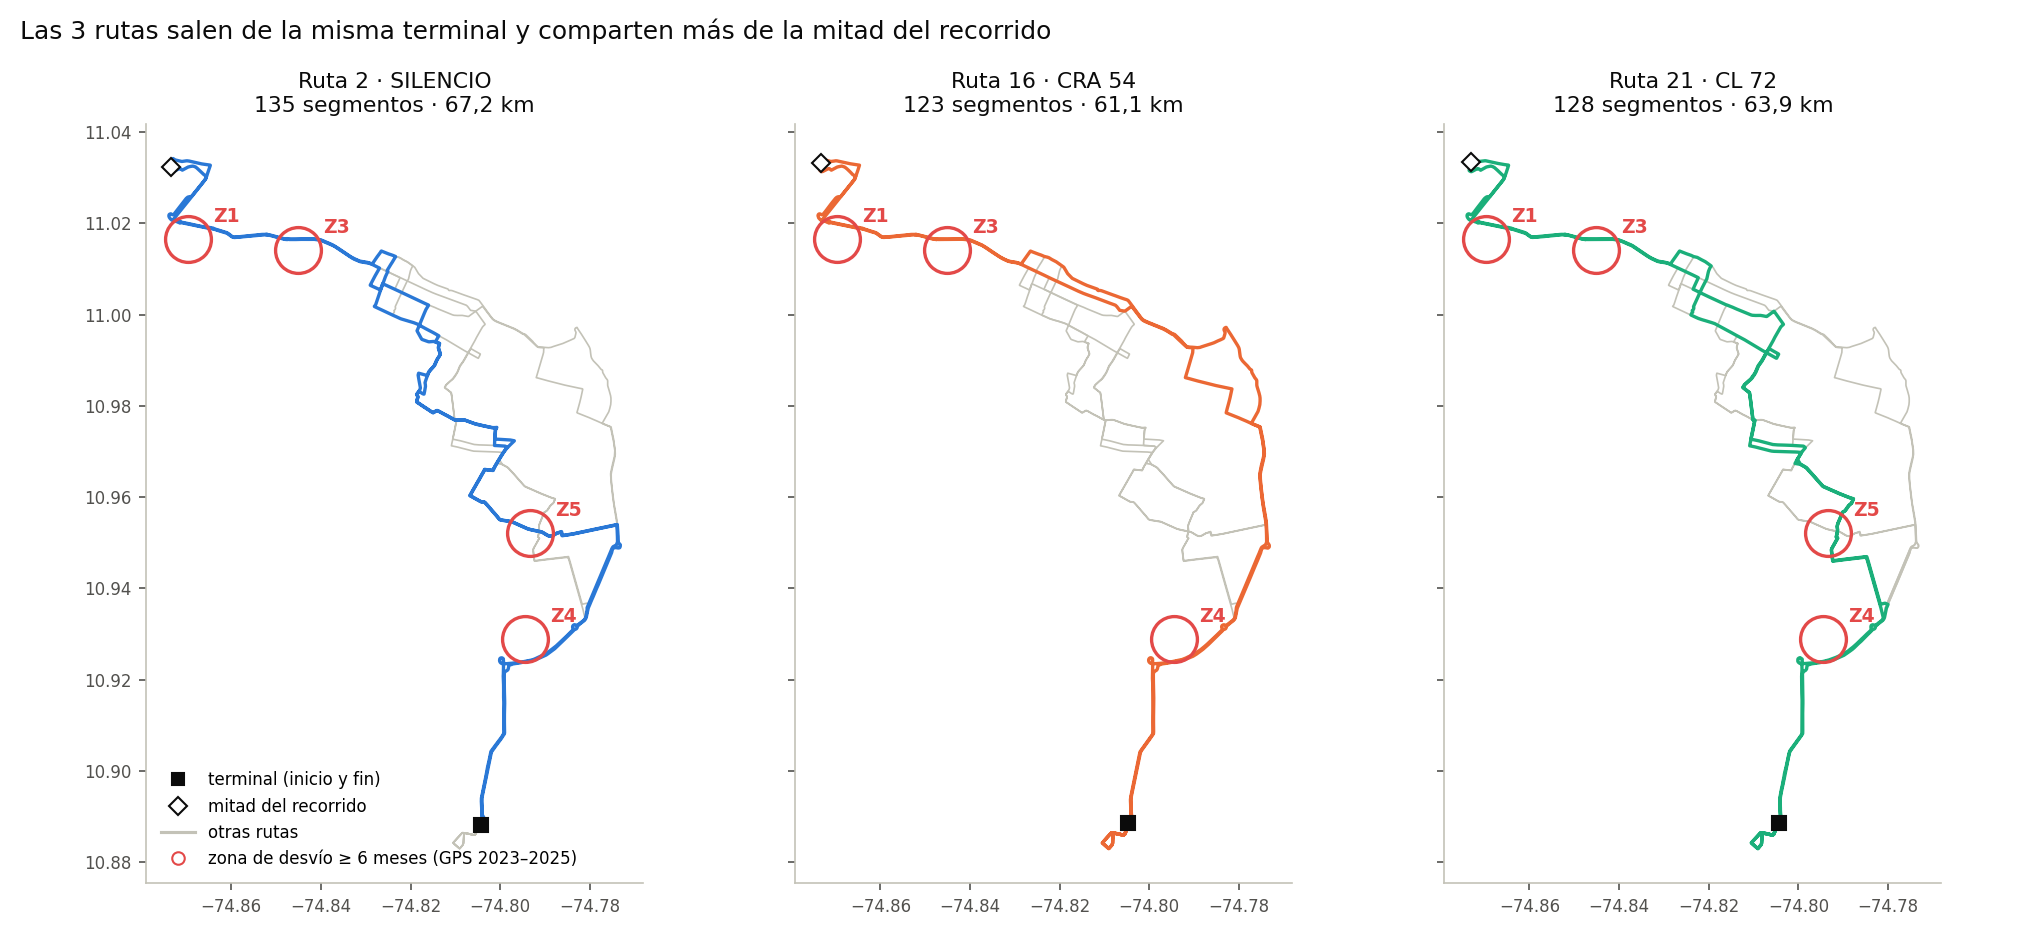

In [3]:
zs = pd.read_csv(D / "desvios_zonas_10_1.csv")
fig, axs = plt.subplots(1, 3, figsize=(13.5, 6.2), sharex=True, sharey=True)
for ax, r in zip(axs, (2, 16, 21)):
    for o in (2, 16, 21):
        if o != r:
            la, lo = rv.a_latlon(red[o].xy[::4]); ax.plot(lo, la, color=COL["gris"], lw=0.8, zorder=1)
    la, lo = rv.a_latlon(red[r].xy[::2]); ax.plot(lo, la, color=COL[r], lw=1.6, zorder=2)
    la0, lo0 = rv.a_latlon(red[r].xy[[0]]); ax.plot(lo0, la0, "s", color=COL["texto"], ms=7, zorder=4)
    lam, lom = rv.a_latlon(red[r].xy[[len(red[r].xy) // 2]]); ax.plot(lom, lam, "D", color=COL["texto"], ms=6, mfc="white", zorder=4)
    for z in zs[(zs.meses >= 6) & (zs.tipo == "desvio")].itertuples():
        if str(r) in z.rutas.split(","):
            ax.plot(z.lon, z.lat, "o", ms=22, mfc="none", mec=COL["alerta"], mew=1.6, zorder=3)
            ax.annotate(z.zona, (z.lon, z.lat), xytext=(12, 8), textcoords="offset points", fontsize=9, color=COL["alerta"], weight="bold")
    n = int(rs.set_index("idruta").loc[r, "n_segmentos"]); L = red[r].longitud_m / 1000
    ax.set_title(f"Ruta {r} · {rs.set_index('idruta').loc[r, 'nombre']}\n{n} segmentos · {f1(L)} km", fontsize=10.5, color=COL["texto"])
    ax.set_aspect(1 / np.cos(np.radians(rv.LAT0))); estilo(ax, grid=None); ax.tick_params(labelsize=8)
axs[0].plot([], [], "s", color=COL["texto"], label="terminal (inicio y fin)"); axs[0].plot([], [], "D", color=COL["texto"], mfc="white", label="mitad del recorrido")
axs[0].plot([], [], color=COL["gris"], label="otras rutas"); axs[0].plot([], [], "o", mfc="none", mec=COL["alerta"], label="zona de desvío ≥ 6 meses (GPS 2023–2025)")
axs[0].legend(loc="lower left", fontsize=8, frameon=False)
fig.suptitle("Las 3 rutas salen de la misma terminal y comparten más de la mitad del recorrido", fontsize=12, x=0.01, ha="left", color=COL["texto"])
fig.tight_layout(); fig.savefig(FIG / "red_vial_10_1.png", dpi=150); plt.close(fig)
display(Image(FIG / "red_vial_10_1.png"))

### 3 · ¿A qué distancia de su ruta reporta el GPS? Umbral «en ruta»

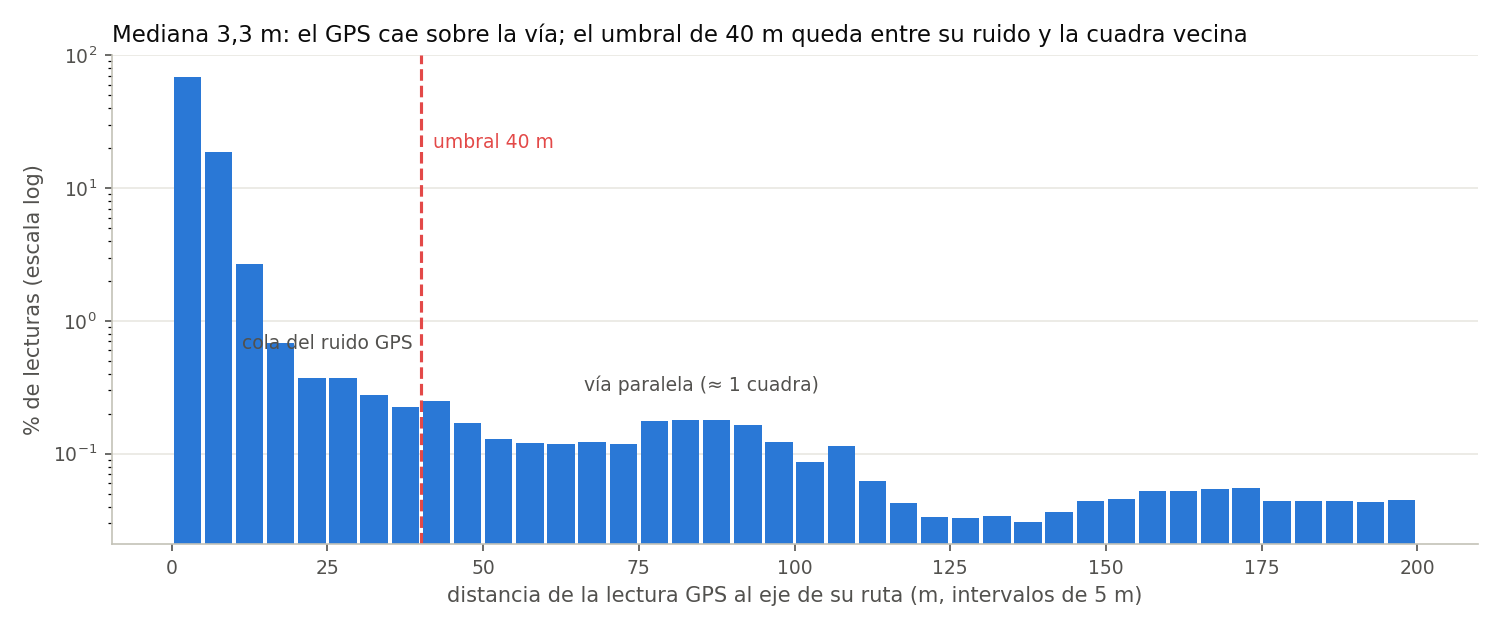

Lecturas a ≤ 15 m: 90.23 % · entre 15 y 40 m: 1.93 % · > 40 m (fuera de ruta): 7.84 %
% fuera de ruta según el umbral: 20 m → 9.09 % · 30 m → 8.34 % · 40 m → 7.84 % · 60 m → 7.17 % · 80 m → 6.63 %


In [4]:
h = pd.read_csv(D / "gps_distancias_hist.csv")
tot = h.n.sum()
fig, ax = plt.subplots(figsize=(10, 4.2))
m = h.desde_m < 200
ax.bar(h.desde_m[m] + 2.5, h.n[m] / tot * 100, width=4.4, color=COL[2], zorder=2)
ax.set_yscale("log"); ax.axvline(RES["umbral_m"], color=COL["alerta"], lw=1.5, ls="--")
ax.annotate(f"umbral {RES['umbral_m']:.0f} m", (RES["umbral_m"], 20), xytext=(6, 0), textcoords="offset points", color=COL["alerta"], fontsize=9)
ax.annotate("vía paralela (≈ 1 cuadra)", (85, 0.18), xytext=(0, 14), textcoords="offset points", ha="center", fontsize=9, color=COL["texto2"])
ax.annotate("cola del ruido GPS", (25, 0.37), xytext=(0, 14), textcoords="offset points", ha="center", fontsize=9, color=COL["texto2"])
ax.set_xlabel("distancia de la lectura GPS al eje de su ruta (m, intervalos de 5 m)", color=COL["texto2"])
ax.set_ylabel("% de lecturas (escala log)", color=COL["texto2"]); estilo(ax)
ax.set_title(f"Mediana {f1(RES['gps_dist_cuantiles_m']['0.5'])} m: el GPS cae sobre la vía; el umbral de {RES['umbral_m']:.0f} m queda entre su ruido y la cuadra vecina",
             fontsize=11, loc="left", color=COL["texto"])
fig.tight_layout(); fig.savefig(FIG / "distancia_gps_10_1.png", dpi=150); plt.close(fig)
display(Image(FIG / "distancia_gps_10_1.png"))
fuera_u = {u: h[h.desde_m >= u].n.sum() / tot * 100 for u in (20, 30, 40, 60, 80)}
print(f"Lecturas a ≤ 15 m: {h[h.hasta_m <= 15].n.sum() / tot * 100:.2f} % · entre 15 y 40 m: "
      f"{h[(h.desde_m >= 15) & (h.hasta_m <= 40)].n.sum() / tot * 100:.2f} % · > 40 m (fuera de ruta): {RES['gps_pct_fuera']:.2f} %")
print("% fuera de ruta según el umbral: " + " · ".join(f"{u} m → {v:.2f} %" for u, v in fuera_u.items()))
check("GPS sobre la vía: mediana de distancia al eje < 5 m", RES["gps_dist_cuantiles_m"]["0.5"] < 5, f"{RES['gps_dist_cuantiles_m']['0.5']} m")
sens = fuera_u[30] - fuera_u[60]
check("Umbral poco sensible: entre 30 y 60 m el % fuera de ruta cambia < 2 puntos", sens < 2, f"{fuera_u[30]:.2f} % → {fuera_u[60]:.2f} %")

### 4 · Fuera de ruta: desvíos sostenidos que el GPS ya registró

,zona,desde,hasta,meses,rutas,celdas,lat,lon,dist_mediana_m,lecturas_fuera,dist_terminal_m,tipo
0,Z1,2023-05,2025-12,31,"2,16,21",343,11.0166,-74.8696,435.7276,19386,15899.0847,desvio
1,Z2,2023-01,2025-12,20,"2,16,21",24,10.8902,-74.8048,79.6930,9587,179.9646,terminal
2,Z3,2023-05,2024-12,19,"2,16,21",213,11.0142,-74.8451,177.2827,9665,14641.7670,desvio
3,Z4,2024-10,2025-12,15,"2,16,21",185,10.9289,-74.7944,460.7927,14221,4615.4050,desvio
4,Z5,2023-05,2025-09,6,"2,21",7,10.9521,-74.7934,163.8706,878,7168.7196,desvio
5,Z6,2024-05,2024-09,5,21,8,10.9391,-74.7799,145.8586,531,6225.8238,desvio
6,Z7,2024-12,2025-06,4,"2,21",16,11.0023,-74.8183,201.2701,2320,12727.6321,desvio
7,Z8,2023-11,2024-12,4,2,5,10.9590,-74.8038,150.9919,981,7825.2073,desvio


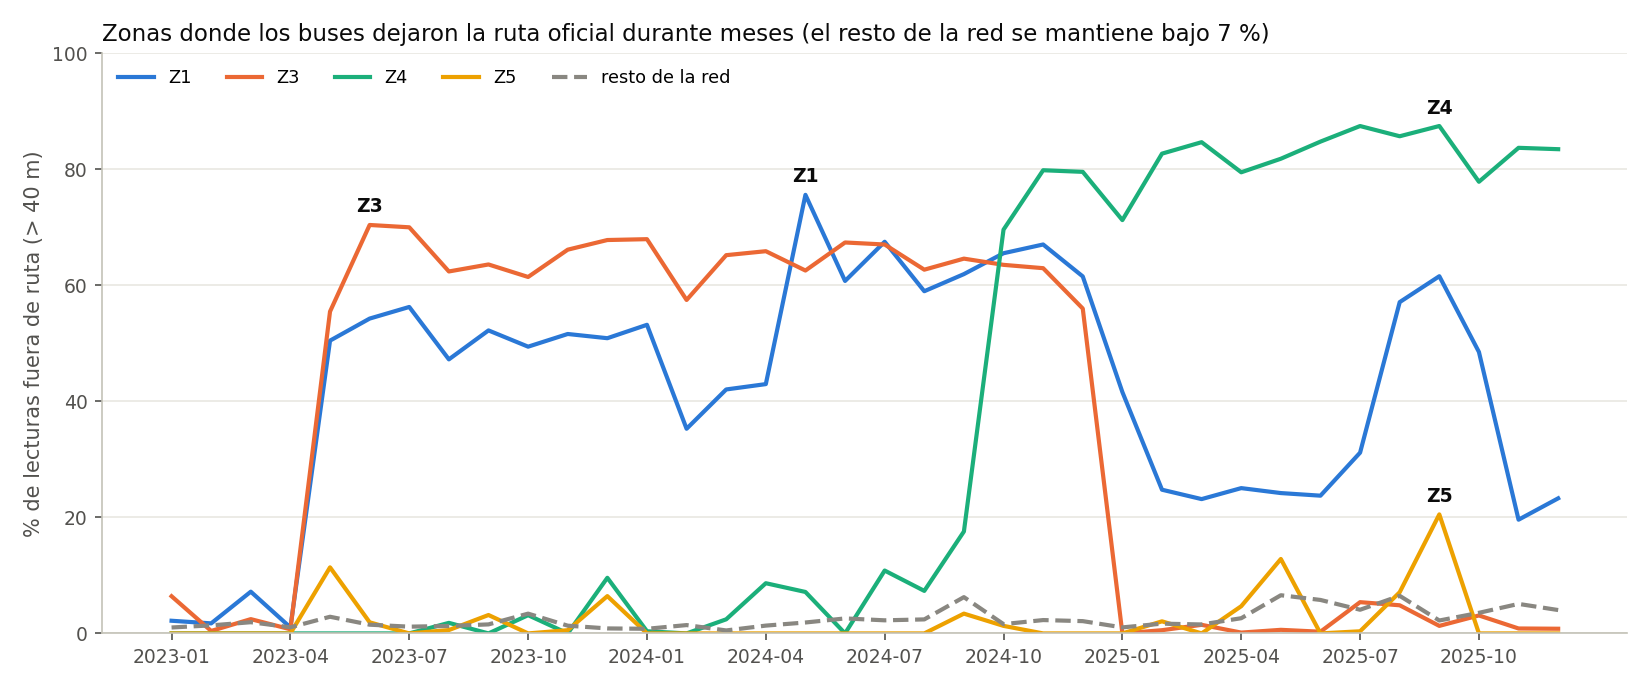

,zona,tipo,desde,hasta,meses,rutas,dist_mediana_m,lecturas_fuera,dist_terminal_m
0,Z1,desvio,2023-05,2025-12,31,"2,16,21",436.0,19386,15899.0
1,Z2,terminal,2023-01,2025-12,20,"2,16,21",80.0,9587,180.0
2,Z3,desvio,2023-05,2024-12,19,"2,16,21",177.0,9665,14642.0
3,Z4,desvio,2024-10,2025-12,15,"2,16,21",461.0,14221,4615.0
4,Z5,desvio,2023-05,2025-09,6,"2,21",164.0,878,7169.0


Resto de la red: mediana mensual 1.9 % fuera de ruta (rango 0.5–6.6 %)


In [5]:
fm = pd.read_csv(D / "gps_fuera_ruta_mensual.csv")
zonas = [c for c in fm.columns if c.startswith("Z") and zs.set_index("zona").loc[c, "tipo"] == "desvio"]
display(zs.head(8).round(4))
pal = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(fm))
for z, c in zip(zonas, pal):
    ax.plot(x, fm[z], color=c, lw=2, zorder=2, label=z)
    k = int(np.nanargmax(fm[z].values))              # etiqueta directa en el pico de cada zona
    ax.annotate(z, (x[k], fm[z].iloc[k]), xytext=(0, 6), textcoords="offset points", ha="center", color=COL["texto"], fontsize=9, weight="bold")
ax.plot(x, fm["resto"], color=COL["resto"], lw=2, ls="--", zorder=2, label="resto de la red")
ax.legend(loc="upper left", fontsize=8.5, frameon=False, ncol=5)
ax.set_xticks(x[::3]); ax.set_xticklabels(fm.mes[::3], rotation=0, fontsize=8)
ax.set_ylabel("% de lecturas fuera de ruta (> 40 m)", color=COL["texto2"]); estilo(ax); ax.set_ylim(0, 100)
ax.set_title("Zonas donde los buses dejaron la ruta oficial durante meses (el resto de la red se mantiene bajo 7 %)", fontsize=11, loc="left", color=COL["texto"])
fig.tight_layout(); fig.savefig(FIG / "desvios_mensuales_10_1.png", dpi=150); plt.close(fig)
display(Image(FIG / "desvios_mensuales_10_1.png"))
display(zs[zs.meses >= 6][["zona", "tipo", "desde", "hasta", "meses", "rutas", "dist_mediana_m", "lecturas_fuera", "dist_terminal_m"]].round(0))
print(f"Resto de la red: mediana mensual {fm['resto'].median():.1f} % fuera de ruta (rango {fm['resto'].min():.1f}–{fm['resto'].max():.1f} %)")
check("Zonas de desvío detectadas y separadas del resto de la red", RES["zonas_desvio_6m"] >= 1 and fm["resto"].median() < 5,
      f"{RES['zonas_desvio_6m']} desvíos ≥ 6 meses (+ zona de terminal); resto mediana {fm['resto'].median():.1f} %")

### 5 · Ida y vuelta por la misma vía: un punto suelto no basta

In [6]:
tr = pd.read_csv(D / "trayectorias_10_1.csv")
print(f"Lecturas en ruta con ida y vuelta posibles (punto suelto ambiguo): {RES['gps_pct_ambiguo_punto']:.1f} %")
print(f"300 viajes completos emparejados con Viterbi: cobertura mediana {tr.cobertura_pct.median():.1f} % de la ruta · "
      f"el segmento cambia frente al punto suelto en {tr.pct_cambia_vs_punto.median():.1f} % de las lecturas (mediana por viaje)")
print(f"Retrocesos > 500 m fuera de las terminales: {RES['retrocesos_500m_por_1000_pasos']:.2f} por cada 1.000 pasos")
display(tr.describe(percentiles=[0.05, 0.5, 0.95]).T.round(2))
check("Emparejamiento de viajes: cobertura mediana ≥ 95 % y < 5 retrocesos > 500 m por 1.000 pasos",
      tr.cobertura_pct.median() >= 95 and RES["retrocesos_500m_por_1000_pasos"] < 5,
      f"{tr.cobertura_pct.median():.1f} % · {RES['retrocesos_500m_por_1000_pasos']:.2f}‰")

Lecturas en ruta con ida y vuelta posibles (punto suelto ambiguo): 66.0 %
300 viajes completos emparejados con Viterbi: cobertura mediana 98.4 % de la ruta · el segmento cambia frente al punto suelto en 15.5 % de las lecturas (mediana por viaje)
Retrocesos > 500 m fuera de las terminales: 3.67 por cada 1.000 pasos


,count,mean,std,min,5%,50%,95%,max
idprogramacion,300.0,6272379.88,685531.71,5071976.00,5229391.45,6213239.00,7369346.35,7539483.00
idruta,300.0,12.95,8.08,2.00,2.00,16.00,21.00,21.00
n_lecturas,300.0,561.56,867.65,43.00,192.85,340.50,3198.55,5869.00
anio,300.0,2023.98,0.79,2023.00,2023.00,2024.00,2025.00,2025.00
pct_fuera,300.0,7.01,6.59,0.00,0.62,5.89,17.08,76.03
pct_ambiguo_punto,300.0,67.34,8.05,38.24,54.95,67.29,78.33,97.67
pct_cambia_vs_punto,300.0,16.43,8.13,0.00,5.26,15.46,29.93,68.05
pasos_en_ruta,300.0,496.29,764.98,32.00,165.70,309.00,2815.50,5319.00
retrocesos_500m,300.0,1.82,1.52,0.00,0.00,2.00,5.00,7.00
cobertura_pct,300.0,95.17,9.52,16.00,85.74,98.41,99.99,100.00


### 6 · ¿Cuántos minutos de GPS necesita un reporte para ubicarse?

,n,lecturas,exacto,lugar,pct_alta,exacto_si_alta,exacto_si_media
ventana_min,,,,,,,
0,3000,1.0,83.17,99.67,32.63,100.00,75.01
1,3000,2.0,91.70,99.63,59.53,97.26,83.53
3,3000,5.0,94.23,99.73,90.87,95.85,78.10
5,3000,8.0,94.73,99.80,95.07,95.79,74.32
10,3000,15.0,95.37,99.80,97.10,96.19,67.82


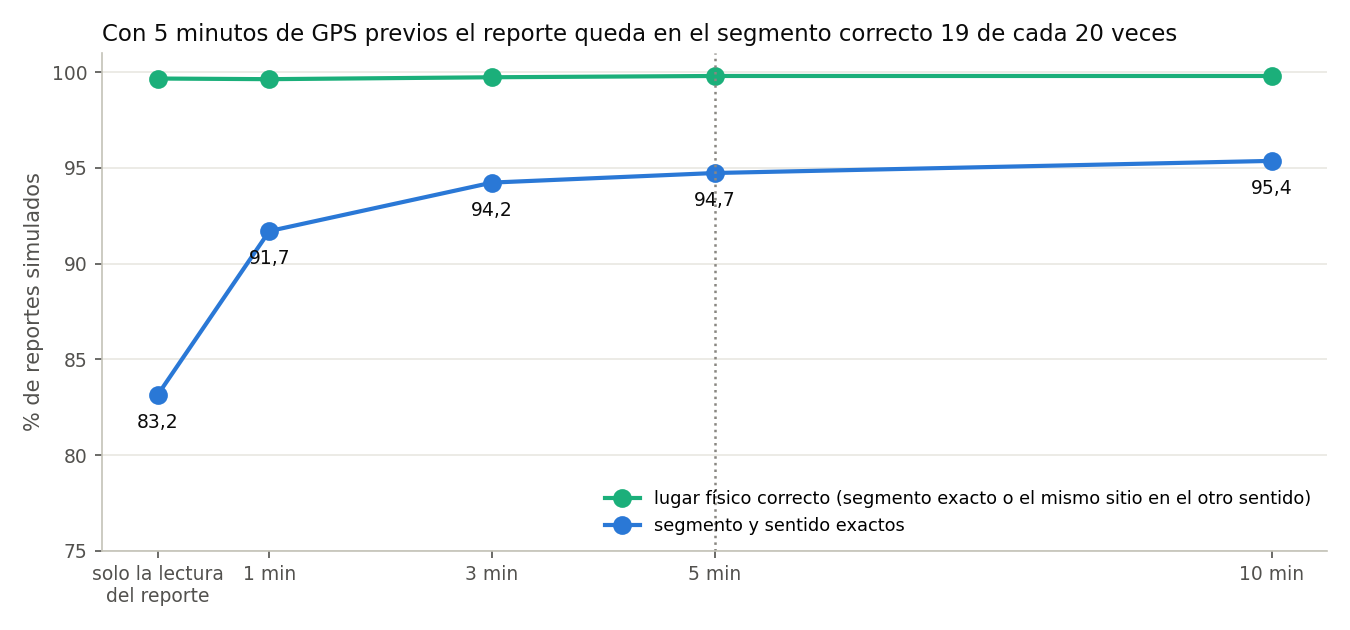

In [7]:
ex = pd.read_csv(D / "ventana_reporte_10_1.csv")
ex["lugar"] = ex.exacto | ex.ref_en_alterno
g = ex.groupby("ventana_min").agg(n=("exacto", "size"), lecturas=("n_lecturas", "median"), exacto=("exacto", "mean"),
                                  lugar=("lugar", "mean"), pct_alta=("confianza", lambda s: (s == "alta").mean()))
ga = ex[ex.confianza == "alta"].groupby("ventana_min").exacto.mean().rename("exacto_si_alta")
gm = ex[ex.confianza == "media"].groupby("ventana_min").exacto.mean().rename("exacto_si_media")
g = g.join(ga).join(gm); g[[c for c in g if c not in ("n", "lecturas")]] *= 100
display(g.round(2))
fig, ax = plt.subplots(figsize=(9, 4.2))
w = g.index.values
ax.plot(w, g.lugar, "o-", color=COL[21], lw=2, ms=8, label="lugar físico correcto (segmento exacto o el mismo sitio en el otro sentido)")
ax.plot(w, g.exacto, "o-", color=COL[2], lw=2, ms=8, label="segmento y sentido exactos")
for xi, yi in zip(w, g.exacto):
    ax.annotate(f1(yi), (xi, yi), xytext=(0, -16), textcoords="offset points", ha="center", fontsize=9, color=COL["texto"])
ax.axvline(RES["ventana_reporte_min"], color=COL["resto"], ls=":", lw=1.2)
ax.set_xticks(w); ax.set_xticklabels([("solo la lectura\ndel reporte" if v == 0 else f"{v} min") for v in w], fontsize=9)
ax.set_ylim(75, 101); ax.set_ylabel("% de reportes simulados", color=COL["texto2"]); estilo(ax)
ax.legend(loc="lower right", fontsize=8.5, frameon=False)
ax.set_title("Con 5 minutos de GPS previos el reporte queda en el segmento correcto 19 de cada 20 veces", fontsize=11, loc="left", color=COL["texto"])
fig.tight_layout(); fig.savefig(FIG / "ventana_reporte_10_1.png", dpi=150); plt.close(fig)
display(Image(FIG / "ventana_reporte_10_1.png"))
v5 = g.loc[RES["ventana_reporte_min"]]
check("Ventana de 5 min: segmento exacto ≥ 90 % y lugar físico ≥ 99 %", v5.exacto >= 90 and v5.lugar >= 99,
      f"{v5.exacto:.2f} % · {v5.lugar:.2f} %")
check("Confianza «alta» más precisa que «media» con 5 min", v5.exacto_si_alta > v5.exacto_si_media,
      f"{v5.exacto_si_alta:.1f} % vs {v5.exacto_si_media:.1f} %")

### 7 · Pruebas y verificación de seguridad

In [8]:
p = subprocess.run([sys.executable, "tests_10_1.py"], capture_output=True, text=True, encoding="utf-8")
print(p.stdout)
check("tests_10_1.py: 7/7 PASS", p.returncode == 0 and "7/7 PASS" in p.stdout, p.stdout.strip().splitlines()[-1])
import re
# credenciales escritas como texto literal (la contraseña se pide con getpass y la API key va en variable de entorno)
patron = re.compile(r"""((password|passwd|contrase(n|ñ)a|api[_-]?key|clave)\s*=\s*['"][^'"]{4,}['"]|sk-ant-[a-z0-9]|SOBUSA_PG_PASS\s*=\s*\S)""", re.I)
sospechosos = []
for f in list(Path(".").glob("*.py")) + list(Path("src").rglob("*.py")) + list(D.rglob("*.csv")) + list(D.rglob("*.json")):
    if f.name == "build_nb_10_1.py":
        continue
    t = f.read_text(encoding="utf-8", errors="ignore")
    if patron.search(t):
        sospechosos.append(str(f))
check("Sin credenciales en código ni en salidas", not sospechosos, ", ".join(sospechosos) or "ninguna coincidencia")
chk = pd.DataFrame(CHECKS); chk.to_csv(D / "checks_10_1.csv", index=False)
display(chk); print(f"{(chk.resultado == 'PASS').sum()}/{len(chk)} PASS")

PASS  a · geometría: proyección (elipsoide) vs Haversine (esfera) < 0,7 % y DP conserva extremos
PASS  b · red: longitud 6.800 m, circuito cerrado, 14 segmentos, límites de segmento exactos
PASS  c · punto suelto: vía compartida ambigua, manzana sin ambigüedad, a 100 m fuera de ruta
PASS  d · trayectoria: hacia el este se ubica en la ida, hacia el oeste en la vuelta
PASS  e · circuito: pasar por la terminal (avance ~L → ~0) no es un retroceso
PASS  f · reporte: desviado → último punto en ruta; sin GPS en ruta → sin_ubicacion; alterno = otro sentido
PASS  g · extracción real (si existe): 386 segmentos activos, continuidad < 1 m y longitudes = BD (< 0,1 %)

7/7 PASS



,check,resultado,detalle
0,"Extracción: 386 segmentos activos de 3 rutas, ...",PASS,386 segmentos
1,Continuidad: hueco entre segmentos consecutivo...,PASS,máx 0.000 m
2,Circuitos cerrados (fin a < 150 m del inicio),PASS,"[60.0, 10.0, 24.0] m"
3,"Proyección local vs longitud de la BD < 0,1 %",PASS,máx 0.030 %
4,GeoJSON simplificado para el equipo: 386 segme...,PASS,0.14 MB (original 24 MB)
5,GPS sobre la vía: mediana de distancia al eje ...,PASS,3.28 m
6,Umbral poco sensible: entre 30 y 60 m el % fue...,PASS,8.34 % → 7.17 %
7,Zonas de desvío detectadas y separadas del res...,PASS,4 desvíos ≥ 6 meses (+ zona de terminal); rest...
8,Emparejamiento de viajes: cobertura mediana ≥ ...,PASS,98.4 % · 3.67‰
9,Ventana de 5 min: segmento exacto ≥ 90 % y lug...,PASS,94.73 % · 99.80 %


13/13 PASS


## Conclusiones

**Conclusión 1 · La red ya existe en la base de datos y está completa**
- SOBUSA segmentó **22 rutas** (`rutas_segmentos_config`, 22 configuraciones activas del 13-ago-2026): cada ruta se corta en segmentos de **500 m**, formados por porciones de 20 cm.
- Rutas del proyecto: **2 · SILENCIO** 135 segmentos (67,2 km) · **16 · CRA 54** 123 (61,1 km) · **21 · CL 72** 128 (63,9 km).
  - Son circuitos cerrados de ida y vuelta: el último segmento termina a 60 / 10 / 24 m del primero, en la misma terminal para las tres.
  - Entre segmentos consecutivos no hay huecos (0,000 m).
  - La geometría mide 7–12 % más que `distancia_global` (62,9 / 56,4 / 57,0 km). Para el Módulo 10 manda la geometría, porque es donde el GPS ubica el bus.
- La tabla `rutasgeograficas` no es visible para nuestro usuario (q6 falló). No hizo falta: los segmentos unidos forman la línea completa.
- Para el equipo queda `datos_10/red_vial_segmentos.geojson`, simplificado a 1 m: 0,14 MB (el original pesa 24 MB).
- La proyección local usa los radios del elipsoide WGS84 y difiere de las longitudes de PostGIS en 0,03 %.

**Conclusión 2 · «En ruta» = a 40 m o menos del eje**
- En 971.335 lecturas GPS (1.673 viajes, 2023–2025), la mediana de distancia al eje de la ruta es **3,3 m** y el percentil 90, **14 m**.
- Más allá de ~35 m el histograma ya no cae. Hacia 75–95 m aparece un segundo grupo: la vía paralela, a una cuadra.
- **El umbral es poco sensible:** entre 30 y 60 m, el % de lecturas fuera de ruta solo pasa de 8,34 % a 7,17 %. Con 40 m queda en **7,84 %**.
- `UMBRAL_M = 40` queda fijo en `red_vial.py`.

**Conclusión 3 · El GPS ya registra los desvíos largos**
- El 7,8 % fuera de ruta no está repartido: se concentra en **4 zonas** con desvíos de 6 meses o más. Las mismas zonas aparecen en las 3 rutas.
  - **Z3** (11,014 −74,845): may-2023 → dic-2024, 55–70 % de lecturas fuera.
  - **Z1** (11,017 −74,870): desde may-2023, con altibajos.
  - **Z4** (10,929 −74,794): oct-2024 → dic-2025, **83 %** fuera en los últimos 12 meses. Seguía activa al cierre de los datos.
  - **Z5**: picos menores.
- **Z2** está a 180 m de la terminal: son maniobras y espera del bus, no desvíos. Se rotula `terminal`.
- En el resto de la red, la mediana mensual es **1,9 %** fuera de ruta y nunca supera el 7 %.
- **Utilidad para el Módulo 10:**
  - estos episodios son una «verdad de terreno» observada para los cierres de vía (`datos_10/desvios_historicos_10_1.csv`), útil al armar el set de prueba de la 10.3;
  - un bus que sale de la ruta justo antes de reportar es evidencia a favor de un cierre.
- La causa de cada desvío (obra, cierre, cambio de recorrido) **no se conoce**: el GPS solo dice dónde y cuándo.

**Conclusión 4 · Cómo se ubica un reporte**
- **Un punto suelto no basta.** El 66 % de las lecturas en ruta están donde la ida y la vuelta comparten vía. Solo con el punto, el reporte queda en el segmento correcto el **83,2 %** de las veces.
- `ubicar_reporte` empareja con Viterbi las lecturas del bus de los **5 minutos previos** (mediana 8 lecturas). El emparejamiento exige que el avance no retroceda y es cíclico en la terminal.
- **Resultado** (3.000 reportes simulados en 300 viajes, comparados con el emparejamiento del viaje completo):
  - segmento y sentido exactos: **94,7 %** (1 min 91,7 % · 10 min 95,4 %);
  - lugar físico correcto: **99,8 %**. Cuando falla, casi siempre es el mismo sitio en el otro sentido, y ese caso se devuelve como `nro_segmento_alterno`.
- **Confianza:**
  - «alta» en el 95 % de los reportes, con **95,8 %** de acierto;
  - «media» con **74,3 %**;
  - las fallas se concentran en las dos puntas del recorrido, donde el bus espera detenido.
- **Límites:**
  - La referencia es el propio emparejamiento del viaje completo, no una verdad externa.
  - Los reportes simulados se tomaron en puntos en ruta. El caso «desviado» (se reporta el último punto en ruta) solo se prueba con la ruta sintética.
  - `margen_min = 1000` se calibró en esta misma muestra; es una etiqueta descriptiva, no un modelo.
- Ningún paso pide coordenadas al conductor ni llama a la API (costo $0).

**Conclusión 5 · Qué queda para las subfases siguientes**
- **13/13 checks PASS** (`datos_10/checks_10_1.csv`) y `tests_10_1.py` **7/7 PASS**. No hay credenciales en código ni en salidas.
- **10.2 · Protocolo:** el conductor solo dice «aquí» o «más adelante en [referencia de una lista cerrada]». La lista de referencias (cruces y puntos conocidos) hay que construirla sobre estos segmentos.
- **10.3 · Set de prueba:**
  - usar las zonas Z1, Z3, Z4 y Z5 y sus fechas como casos reales de cierre o desvío;
  - retomar la discusión pendiente sobre la cantidad de audios y textos.
- **10.6 · Servicio:**
  - leer el GPS en vivo **por vehículo y rango de 5 minutos**, sin recorrer `conteo_pasajeros_destino` completa; antes, verificar sus índices;
  - el reporte llega con remitente → `idvehiculo` → viaje activo → `idruta`.
- **Pendiente con el dueño del Módulo 12:** acordar el esquema del evento (`idruta`, `nro_segmento`, `nro_segmento_alterno`, `confianza`, `desviado`, hora y tipo).

---
# Parte 4 · Módulo 10 · Subfase 10.2 · Protocolo y contrato del evento
*Notebook original: `modulo10/subfase_10_2_protocolo.ipynb`*

# SOBUSA · Módulo 10 · Subfase 10.2 — Protocolo de reporte y contrato del evento

**Persona 3.** La 10.1 dejó la red y la ubicación del bus por GPS. Esta subfase define **qué dice el conductor** y **qué produce el sistema**:

| Pieza | Archivo | Estado |
|---|---|---|
| Guía para conductores v1.2 (qué pasa · dónde · qué tan grave 1–5 · duración · sentido; «mi bus» si solo afecta al bus) | `protocolo_conductores_10_2.md` | Aprobada por la Persona 3 (27-oct-2026); 1.2 tras la revisión |
| Catálogo de esquinas de cada ruta (OpenStreetMap) | `referencias_10_2.py` → `datos_10/referencias/` | Opción C: todas las esquinas con nombre |
| «Adelante en X con Y» → segmento | `src/geo/referencias.py` (`resolver_referencia`) | |
| Contrato del evento (JSON Schema 1.2) | `contrato_evento_10_2.json` | **Propuesta**: falta confirmarla con el dueño del Módulo 12 |
| Contrato del mensaje de entrada (webhook, WhatsApp simulado) | `contrato_mensaje_entrada_10_2.json` | Nuevo tras la revisión (H5) |
| Revisión de la subfase | `revisiones/revision_10_2.md`, `revisar_10_2.py` | Aprobada con observaciones |
| Extracción + GPS → evento | `src/m10/evento.py` (`construir_evento`, `validar_evento`) | |
| Validación de punta a punta con GPS real | `analisis_10_2.py` | |

**Por qué OpenStreetMap y no Google.** Los términos de Google Geocoding solo permiten guardar coordenadas 30 días (B.6.3.1) y prohíben usarlas con mapas que no sean de Google (B.6.2). OSM (licencia ODbL) se puede guardar y derivar con atribución: **© colaboradores de OpenStreetMap**. datos.gov.co (nomenclatura) respondió «acceso no permitido». Fuentes en `FUENTES_modulo10.md`.

Sin API de Claude en esta subfase (costo $0): la extracción del texto llega en la 10.5; aquí se prueba todo lo que va antes y después.

## Parte 2 · Análisis offline

In [1]:
import json
import platform
import re
import subprocess
import sys
from pathlib import Path
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

sys.path.insert(0, "src")
from geo import red_vial as rv
from geo import referencias as rf

pd.set_option("display.max_columns", None); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 70)
D = Path("datos_10"); R_ = D / "referencias"; FIG = Path("resultados_10"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
def check(nombre: str, ok: bool, detalle: str = "") -> None:
    CHECKS.append({"check": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": detalle})

meta = json.loads((D / "insumos" / "osm_vias_barranquilla_meta.json").read_text(encoding="utf-8"))
rref = json.loads((R_ / "resumen_referencias.json").read_text(encoding="utf-8"))
r102 = json.loads((R_ / "resumen_10_2.json").read_text(encoding="utf-8"))
seg = rv.leer_segmentos(D / "extraccion" / "q4_segmentos.csv"); red = rv.construir_red(seg)
cat = pd.read_csv(R_ / "catalogo_referencias.csv"); ejes = pd.read_csv(R_ / "ejes_ruta.csv")
COL = {2: "#2a78d6", 16: "#eb6834", 21: "#1baf7a", "gris": "#c3c2b7", "texto": "#0b0b0b", "texto2": "#52514e", "grid": "#e9e8e2"}
def estilo(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False); ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors=COL["texto2"], labelsize=9)
    if grid: ax.grid(axis=grid, color=COL["grid"], lw=0.8)
    ax.set_axisbelow(True)
print(f"Python {platform.python_version()} · OSM del {meta['fecha_datos_osm']} · {meta['n_vias']:,} vías descargadas · {meta['licencia']}")

Python 3.9.25 · OSM del 2026-10-28T04:12:51Z · 16,563 vías descargadas · ODbL 1.0 — © colaboradores de OpenStreetMap (https://www.openstreetmap.org/copyright)


### 1 · Por qué calle va cada ruta

In [2]:
osm_n = rref["por_ruta"]
for r in (2, 16, 21):
    e = ejes[(ejes.idruta == r) & (ejes.eje != "(sin nombre)")].groupby("eje").largo_m.sum().sort_values(ascending=False)
    print(f"Ruta {r}: {osm_n[str(r)]['tramos']} tramos · {osm_n[str(r)]['pct_sin_nombre']:.1f} % sin nombre · principales: "
          + ", ".join(f"{k} {v / 1000:.1f} km" for k, v in e.head(8).items()))
largo = lambda r, n: ejes[(ejes.idruta == r) & (ejes.eje == n)].largo_m.sum()
check("OSM: ≥ 10.000 vías vehiculares con nombre y licencia ODbL registrada", meta["n_vias_con_nombre"] >= 10000 and "ODbL" in meta["licencia"],
      f"{meta['n_vias_con_nombre']:,} con nombre")
check("La calle de cada ruta coincide con su nombre (16 → Carrera 54 ≥ 3 km; 21 → Calle 72 ≥ 2 km)",
      largo(16, "Carrera 54") >= 3000 and largo(21, "Calle 72") >= 2000,
      f"Carrera 54 {largo(16, 'Carrera 54') / 1000:.1f} km · Calle 72 {largo(21, 'Calle 72') / 1000:.1f} km")
mx = max(v["pct_sin_nombre"] for v in osm_n.values())
check("Recorrido sin nombre de calle ≤ 10 % en cada ruta", mx <= 10, f"máx {mx:.1f} %")

Ruta 2: 91 tramos · 7.5 % sin nombre · principales: Avenida Murillo 8.2 km, Carrera 51B 5.3 km, Carrera 14 5.1 km, Avenida Circunvalar 4.9 km, Carrera 30 4.9 km, Boulevard Simón Bolívar 3.5 km, Carrera 27 3.1 km, Carrera 15 2.7 km
Ruta 16: 74 tramos · 2.5 % sin nombre · principales: Avenida Murillo 8.5 km, Carrera 51B 7.7 km, Avenida Calle 17 5.8 km, Carrera 54 5.2 km, Carrera 30 4.9 km, Avenida Circunvalar 4.9 km, Boulevard Simón Bolívar 3.6 km, Carrera 53 2.5 km
Ruta 21: 97 tramos · 2.5 % sin nombre · principales: Avenida Murillo 8.5 km, Carrera 51B 5.7 km, Carrera 30 5.1 km, Avenida Circunvalar 4.7 km, Carrera 21 3.3 km, Calle 36B 3.1 km, Calle 72 3.0 km, Avenida Calle 30 2.5 km


### 2 · Catálogo de esquinas (opción C: todas las que tienen nombre)

tipo,cruce,giro,principales (avenidas)
idruta,,,
2,355,67,42
16,263,53,35
21,327,75,42


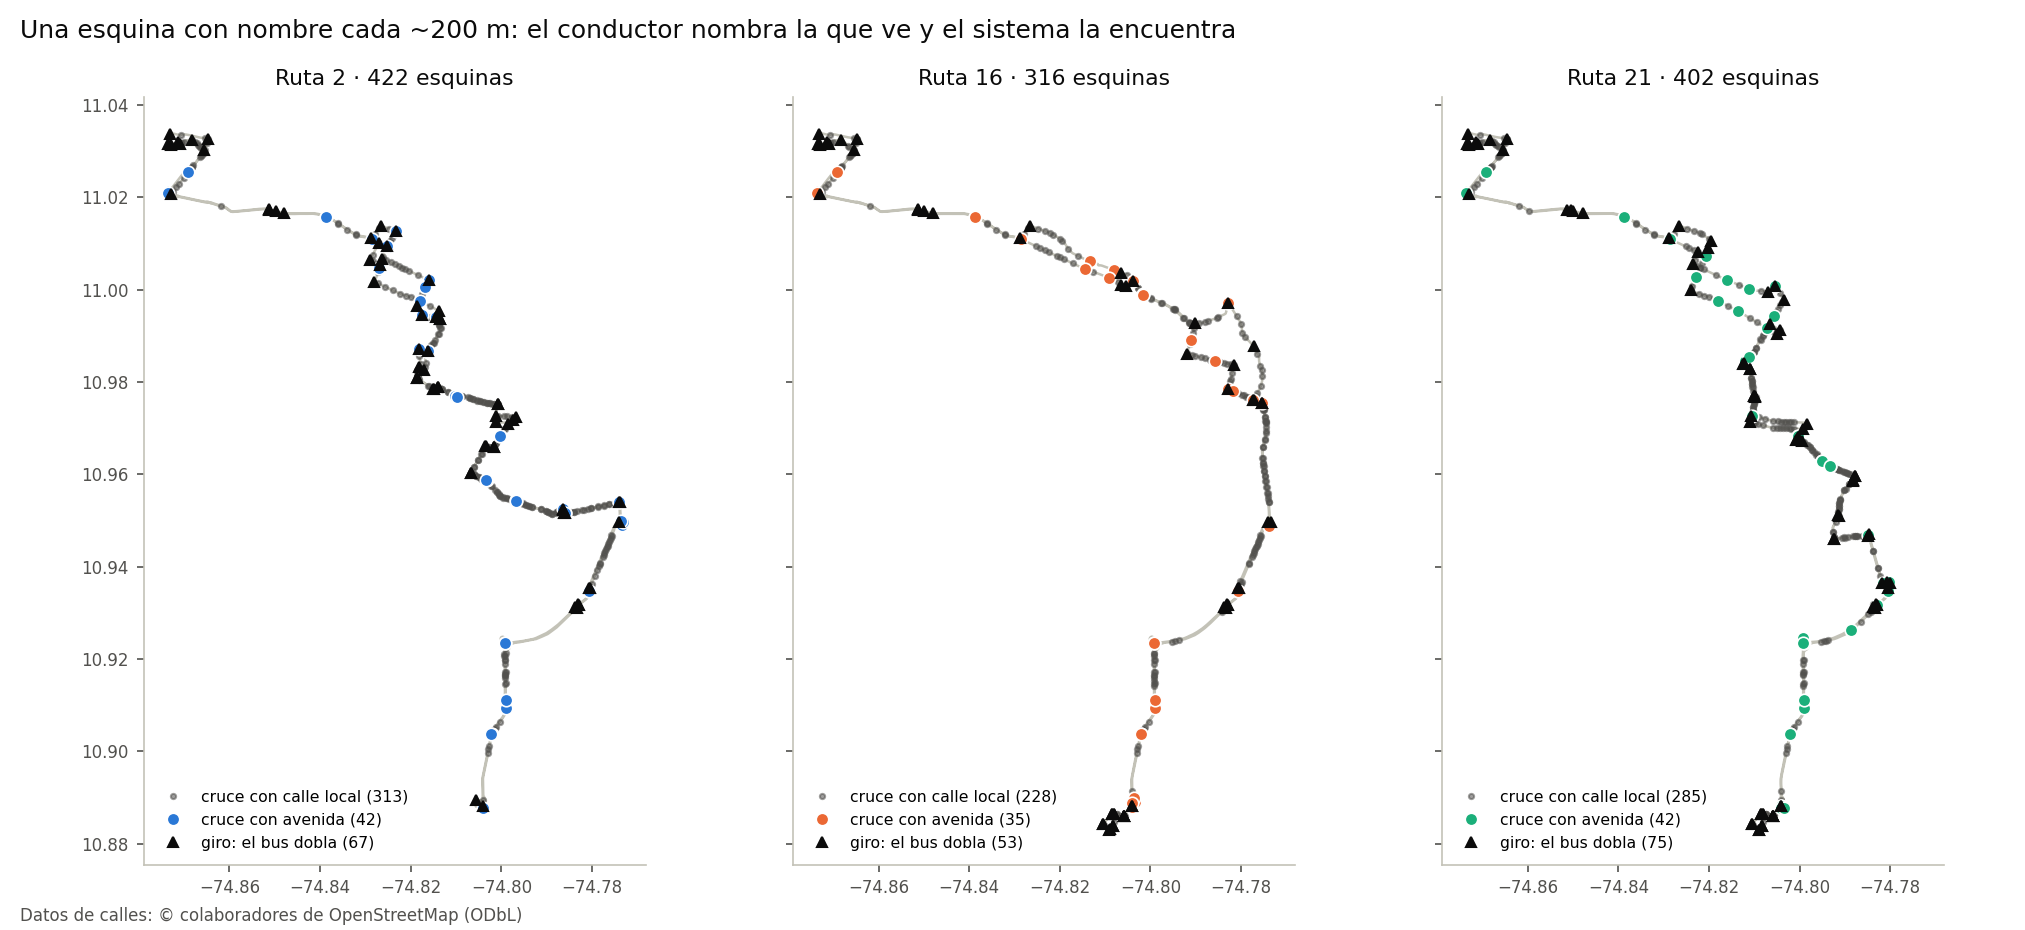

In [3]:
t = cat.groupby(["idruta", "tipo"]).size().unstack(fill_value=0)
t["principales (avenidas)"] = cat[(cat.tipo == "cruce") & (cat.cruce_jerarquia <= 3)].groupby("idruta").size()
display(t)
fig, axs = plt.subplots(1, 3, figsize=(13.5, 6.2), sharex=True, sharey=True)
for ax, r in zip(axs, (2, 16, 21)):
    la, lo = rv.a_latlon(red[r].xy[::3]); ax.plot(lo, la, color=COL["gris"], lw=1.2, zorder=1)
    c = cat[cat.idruta == r]
    o = c[(c.tipo == "cruce") & (c.cruce_jerarquia > 3)]
    p = c[(c.tipo == "cruce") & (c.cruce_jerarquia <= 3)]
    g = c[c.tipo == "giro"]
    ax.plot(o.lon, o.lat, "o", ms=2.5, color=COL["texto2"], alpha=0.55, zorder=2, label=f"cruce con calle local ({len(o)})")
    ax.plot(p.lon, p.lat, "o", ms=6, color=COL[r], mec="white", mew=0.8, zorder=3, label=f"cruce con avenida ({len(p)})")
    ax.plot(g.lon, g.lat, "^", ms=5, color=COL["texto"], zorder=3, label=f"giro: el bus dobla ({len(g)})")
    ax.set_title(f"Ruta {r} · {len(c)} esquinas", fontsize=10.5, color=COL["texto"])
    ax.set_aspect(1 / np.cos(np.radians(rv.LAT0))); estilo(ax, grid=None); ax.tick_params(labelsize=8)
    ax.legend(loc="lower left", fontsize=7.5, frameon=False)
fig.suptitle("Una esquina con nombre cada ~200 m: el conductor nombra la que ve y el sistema la encuentra", fontsize=12, x=0.01, ha="left", color=COL["texto"])
fig.text(0.01, 0.01, "Datos de calles: © colaboradores de OpenStreetMap (ODbL)", fontsize=8, color=COL["texto2"])
fig.tight_layout(rect=(0, 0.02, 1, 1)); fig.savefig(FIG / "catalogo_esquinas_10_2.png", dpi=150); plt.close(fig)
display(Image(FIG / "catalogo_esquinas_10_2.png"))
cr = cat[cat.tipo == "cruce"]
check("Catálogo: ≥ 200 cruces por ruta y ningún cruce consigo misma",
      cr.groupby("idruta").size().min() >= 200 and (cr.eje.map(rf.clave) != cr.cruce.map(rf.clave)).all(),
      str(cr.groupby("idruta").size().to_dict()))

### 3 · ¿Qué tanto servía la lista de ChatGPT?

In [4]:
v = pd.read_csv(R_ / "validacion_chatgpt_10_2.csv")
print(f"De {len(v)} cruces propuestos por ChatGPT, {int(v.en_alguna_ruta.sum())} están en alguna de nuestras rutas "
      f"({int(v.via1.isna().sum())} no eran cruces sino tramos «entre calles»).")
display(v[v.en_alguna_ruta][["corredor", "interseccion", "ruta_2", "ruta_16", "ruta_21"]])

De 54 cruces propuestos por ChatGPT, 20 están en alguna de nuestras rutas (5 no eran cruces sino tramos «entre calles»).


,corredor,interseccion,ruta_2,ruta_16,ruta_21
1,Calle 72,Calle 72 con carrera 54,NaN,39.0,NaN
3,Calle 72,Calle 72 con carrera 46,NaN,NaN,89.0
4,Calle 72,Calle 72 con carrera 43,NaN,NaN,38.0
5,Calle 72,Calle 72 con carrera 38,NaN,NaN,36.0
6,Carrera 54,Calle 72 con carrera 54,NaN,39.0,NaN
7,Carrera 54,Calle 53 con carrera 54,NaN,35.0,NaN
8,Carrera 54,Calle 58 con carrera 54,NaN,36.0,NaN
9,Carrera 54,Calle 50 con carrera 54,NaN,35.0,NaN
10,Carrera 54,Carrera 54 con Vía 40,NaN,33.0,NaN
21,Vía 40,Vía 40 con calle 30,NaN,29.0,NaN


### 4 · Protocolo para conductores y contrato del evento

In [5]:
proto = Path("protocolo_conductores_10_2.md").read_text(encoding="utf-8")
display(Markdown(proto))
contrato = json.loads(Path("contrato_evento_10_2.json").read_text(encoding="utf-8"))
p = contrato["properties"]
filas = [{"campo": k, "tipo / valores": (str(s.get("enum")) if "enum" in s else s.get("type", "objeto")), "obligatorio": k in contrato["required"],
          "nota": s.get("description", "")[:90]} for k, s in p.items()]
display(pd.DataFrame(filas))
entrada = json.loads(Path("contrato_mensaje_entrada_10_2.json").read_text(encoding="utf-8"))
print("Mensaje de entrada (ejemplo):"); print(json.dumps(entrada["examples"][0], ensure_ascii=False, indent=1))
tipos_md = set(re.findall(r"^\| \*\*(\w+)\*\* \|", proto, flags=re.M))
tipos_js = set(p["tipo_evento"]["enum"])
check("Guía y contrato usan los mismos 9 tipos de evento", {rf.clave(t_) for t_ in tipos_md} == tipos_js,
      f"guía {sorted(tipos_md)} · contrato {sorted(tipos_js)}")

# Cómo reportar un evento en la vía · Guía para conductores de SOBUSA

**Versión 1.2 · 27-oct-2026 · Módulo 10 (proyecto SOBUSA–Uninorte)**

Su reporte ayuda a ajustar las salidas de los buses cuando algo pasa en la vía. Toma menos de 15 segundos.

## Qué decir, siempre en este orden

| # | Parte | Qué decir | Ejemplos |
|---|---|---|---|
| 1 | **Qué pasa** | Una de estas palabras: **trancón · choque · varado · obra · arroyo · bloqueo · evento · semáforo** (o «otro», y lo describe en pocas palabras). Si el problema es **solo de su bus** y no tapa la vía, agregue **«mi bus»** | «Choque», «Varado, mi bus» |
| 2 | **Dónde** | **«aquí»** si está en el sitio, o **«adelante en [calle] con [calle]»** si lo ve más adelante | «aquí», «adelante en la 72 con 38» |
| 3 | **Qué tan grave** | El **nivel del 1 al 5** o su palabra (tabla de abajo). No hace falta si es «mi bus» | «nivel 3» o «un carril» |
| 4 | **Cuánto va a durar** (si lo sabe) | **corta · media · larga · muy larga** | «larga» |
| 5 | **Sentido** (si lo sabe) | **mi sentido** o **los dos** | «los dos» |

### Qué tan grave: niveles

| Nivel | Palabra | Cómo se ve en la vía |
|---|---|---|
| **1** | **lento** | El tráfico avanza, pero más lento de lo normal |
| **2** | **pare y siga** | Avanza a ratos; la demora se nota |
| **3** | **un carril** | Un carril está bloqueado; se pasa, pero con demora |
| **4** | **casi cerrada** | Pasa un vehículo a la vez o con maniobras; mejor desviarse |
| **5** | **cerrada** | No se puede pasar; hay que desviarse |

### Solo mi bus o la vía

- **«Mi bus»:** el problema es de su bus y **no afecta a los demás** (por ejemplo, varado orillado, pinchazo en la bahía). No diga nivel.
- **La vía:** el problema afecta a todos los que pasan por ahí, **también si es su propio bus varado tapando un carril**. En ese caso no diga «mi bus»: diga el tipo y el nivel («Varado, aquí, un carril»).

### Cuánto va a durar

| Diga | Significa |
|---|---|
| **corta** | Menos de 30 minutos |
| **media** | Entre 30 minutos y 1 hora |
| **larga** | Entre 1 y 2 horas |
| **muy larga** | Más de 2 horas |

**No hace falta decir** la hora, la ruta, el número del bus ni su ubicación exacta: el sistema los toma del GPS del bus.

## Ejemplos

- «**Choque, adelante en la 72 con 38, un carril.**» → nivel 3
- «**Arroyo, aquí, cerrada, larga, los dos.**» → nivel 5
- «**Trancón, adelante en Murillo con 21, nivel 2, corta, mi sentido.**»
- «**Obra, adelante en la 51B con Circunvalar, casi cerrada, muy larga.**» → nivel 4
- «**Varado, mi bus, aquí.**» → solo afecta a su bus
- «**Varado, aquí, un carril, corta.**» → su bus (u otro) tapa un carril: afecta la vía

**Cuando se despeje:** «**Despejado, la 72 con 38.**» (o «Despejado, aquí»).

## Qué significa cada tipo

| Diga | Cuando |
|---|---|
| **trancón** | Tráfico detenido o muy lento sin causa a la vista |
| **choque** | Accidente o atropello que ocupa la vía |
| **varado** | Un vehículo dañado (incluido su propio bus) |
| **obra** | Obra, cierre programado o desvío oficial |
| **arroyo** | Agua o arroyo en la vía, inundación |
| **bloqueo** | Manifestación, protesta o bloqueo de la vía |
| **evento** | Partido, concierto, Carnaval u otro evento con mucha gente |
| **semáforo** | Semáforo apagado o dañado |
| **otro** | Cualquier otra cosa (árbol o poste caído, retén, hueco grande…): diga «otro» y qué es |

## Lo que NO debe ir en el mensaje

- Nombres de personas, teléfonos ni placas de vehículos.
- Insultos ni opiniones. Solo lo que ve en la vía.

## ¿Texto o audio?

| Situación | Canal |
|---|---|
| Evento grande (trancón fuerte, vía cerrada) | Texto |
| Evento pequeño, para no interrumpir el recorrido | Audio corto (máximo 15 segundos) |

En el audio, hable claro y diga las partes en el mismo orden que en el texto.


,campo,tipo / valores,obligatorio,nota
0,version,objeto,True,
1,id_evento,string,True,"Hash del vehículo, la hora de recepción y el texto: el mismo mensa..."
2,recibido,string,True,"Hora de recepción, con zona (America/Bogota)."
3,canal,"['texto', 'audio']",True,
4,idvehiculo,string,True,"Del remitente registrado, nunca del mensaje."
5,idprogramacion,"[integer, null]",False,Viaje activo del vehículo a la hora del reporte.
6,idruta,"[2, 16, 21]",True,
7,tipo_evento,"['trancon', 'choque', 'varado', 'obra', 'arroyo', 'bloqueo', 'even...",True,En un despeje es el tipo del evento que se cierra; si el conductor...
8,detalle_otro,"[string, null]",False,Solo si tipo_evento = otro.
9,alcance,"['via', 'solo_bus']",True,via: afecta a todos los que pasan (incluido el bus propio varado t...


Mensaje de entrada (ejemplo):
{
 "version": "1.0",
 "id_mensaje": "wamid.0001",
 "recibido": "2026-10-27T07:42:10-05:00",
 "remitente": {
  "idvehiculo": "SOBUSA117",
  "hash_remitente": null
 },
 "canal": "texto",
 "texto": "Choque, adelante en la 72 con 38, un carril.",
 "audio": null,
 "simulado": true
}


### 5 · Prueba de punta a punta con GPS real

In [6]:
s = pd.read_csv(R_ / "simulacion_reportes_10_2.csv")
N = {r: len(red[r].nro_segmento) for r in red}
dif = (s.seg_obtenido - s.seg_esperado).abs(); dif = np.minimum(dif, s.idruta.map(N) - dif)
s["pm1"] = dif <= 1
s["forma"] = np.where(s.dicho.str.contains(r"\bla \d"), "con número suelto («la 72 con 38»)", "nombre completo o de avenida")
print(f"{len(s):,} reportes simulados en {s.idprogramacion.nunique()} viajes reales · ubicados solo con 5 min de GPS previos")
display(pd.DataFrame({"segmento exacto %": [100 * s.exacto.mean()], "a ±1 segmento %": [100 * s.pm1.mean()],
                      "exacto o el alterno %": [100 * s.exacto_o_alterno.mean()],
                      "eventos fuera del contrato": [int((s.errores_contrato > 0).sum())]}).round(2))
display((s.groupby("forma")[["exacto", "pm1"]].mean() * 100).round(2))
print("Ejemplos de diferencias de más de un segmento:")
display(s[~s.pm1 & ~s.exacto_o_alterno][["idruta", "dicho", "esquina", "seg_esperado", "seg_obtenido", "adelante_m"]])
check("Simulación: segmento exacto ≥ 95 %, a ±1 segmento ≥ 99 %, todos los eventos cumplen el contrato",
      s.exacto.mean() >= 0.95 and s.pm1.mean() >= 0.99 and (s.errores_contrato == 0).all(),
      f"{100 * s.exacto.mean():.2f} % · {100 * s.pm1.mean():.2f} % · {int((s.errores_contrato > 0).sum())} fuera")

1,481 reportes simulados en 300 viajes reales · ubicados solo con 5 min de GPS previos


,segmento exacto %,a ±1 segmento %,exacto o el alterno %,eventos fuera del contrato
0,97.64,99.39,97.97,0


,exacto,pm1
forma,,
con número suelto («la 72 con 38»),97.93,99.41
nombre completo o de avenida,97.39,99.38


Ejemplos de diferencias de más de un segmento:


,idruta,dicho,esquina,seg_esperado,seg_obtenido,adelante_m
181,16,Vía 40 con Calle 30,Vía 40 con Avenida Calle 30,31,29,1109.7
662,16,la 1A con la 68A,Calle 68A con Transversal 1A 4,121,119,656.4
1106,16,Vía 40 con la 30,Vía 40 con Avenida Calle 30,31,29,434.7
1124,16,la vía 40 con Calle 30,Vía 40 con Avenida Calle 30,31,29,574.7


### 6 · Las zonas de desvío de la 10.1, con nombre de calle

In [7]:
z = pd.read_csv(R_ / "zonas_desvio_calles_10_2.csv")
display(z)

,zona,desde,hasta,meses,idruta,dist_centro_a_ruta_m,nro_segmento,calle_de_la_ruta,esquina_antes,esquina_despues
0,Z1,2023-05,2025-12,31,2,343,74,Carrera 30,(sin nombre) con Autopista Circunvalar de la Prosperidad,Carrera 51B con Avenida Circunvalar
1,Z1,2023-05,2025-12,31,16,344,68,Carrera 30,(sin nombre) con Autopista Circunvalar de la Prosperidad,Carrera 51B con Avenida Circunvalar
2,Z1,2023-05,2025-12,31,21,344,71,Carrera 30,(sin nombre) con Autopista Circunvalar de la Prosperidad,Carrera 51B con Avenida Circunvalar
3,Z3,2023-05,2024-12,19,2,249,79,Carrera 51B,(sin nombre) con Autopista Circunvalar de la Prosperidad,Carrera 51B con Avenida Circunvalar
4,Z3,2023-05,2024-12,19,16,250,74,Carrera 51B,(sin nombre) con Autopista Circunvalar de la Prosperidad,Carrera 51B con Avenida Circunvalar
5,Z3,2023-05,2024-12,19,21,249,76,Carrera 51B,(sin nombre) con Autopista Circunvalar de la Prosperidad,Carrera 51B con Avenida Circunvalar
6,Z4,2024-10,2025-12,15,2,526,120,Avenida Circunvalar,Avenida Circunvalar con Autopista Aeropuerto,Avenida Circunvalar con Avenida Murillo
7,Z4,2024-10,2025-12,15,16,522,107,Avenida Circunvalar,Avenida Circunvalar con Autopista Aeropuerto,Avenida Circunvalar con Avenida Murillo
8,Z4,2024-10,2025-12,15,21,520,113,Avenida Circunvalar,Avenida Circunvalar con Calle 43,Avenida Circunvalar con Avenida Murillo
9,Z5,2023-05,2025-09,6,2,84,107,Carrera 14,Carrera 14 con Calle 40,Carrera 14 con Calle 38B


### 7 · Pruebas y verificación de seguridad

In [8]:
for t_, n in (("tests_10_1.py", 7), ("tests_10_2.py", 9)):
    p_ = subprocess.run([sys.executable, t_], capture_output=True, text=True, encoding="utf-8")
    print(p_.stdout.strip().splitlines()[-1], "·", t_)
    check(f"{t_}: {n}/{n} PASS", p_.returncode == 0 and f"{n}/{n} PASS" in p_.stdout, p_.stdout.strip().splitlines()[-1])
patron = re.compile(r"""((password|passwd|contrase(n|ñ)a|api[_-]?key|clave)\s*=\s*['"][^'"]{4,}['"]|sk-ant-[a-z0-9]|SOBUSA_PG_PASS\s*=\s*\S)""", re.I)
sosp = [str(f) for f in list(Path(".").glob("*.py")) + list(Path("src").rglob("*.py")) + list(R_.glob("*.*"))
        if f.name not in ("build_nb_10_1.py", "build_nb_10_2.py") and patron.search(f.read_text(encoding="utf-8", errors="ignore"))]
check("Sin credenciales en código ni en salidas", not sosp, ", ".join(sosp) or "ninguna coincidencia")
chk = pd.DataFrame(CHECKS); chk.to_csv(D / "checks_10_2.csv", index=False)
display(chk); print(f"{(chk.resultado == 'PASS').sum()}/{len(chk)} PASS")

7/7 PASS · tests_10_1.py


9/9 PASS · tests_10_2.py


,check,resultado,detalle
0,OSM: ≥ 10.000 vías vehiculares con nombre y licencia ODbL registrada,PASS,"16,450 con nombre"
1,La calle de cada ruta coincide con su nombre (16 → Carrera 54 ≥ 3 ...,PASS,Carrera 54 5.2 km · Calle 72 3.0 km
2,Recorrido sin nombre de calle ≤ 10 % en cada ruta,PASS,máx 7.5 %
3,Catálogo: ≥ 200 cruces por ruta y ningún cruce consigo misma,PASS,"{2: 355, 16: 263, 21: 327}"
4,Guía y contrato usan los mismos 9 tipos de evento,FAIL,"guía ['1', '2', '3', '4', '5', 'arroyo', 'bloqueo', 'choque', 'cor..."
5,"Simulación: segmento exacto ≥ 95 %, a ±1 segmento ≥ 99 %, todos lo...",PASS,97.64 % · 99.39 % · 0 fuera
6,tests_10_1.py: 7/7 PASS,PASS,7/7 PASS
7,tests_10_2.py: 9/9 PASS,PASS,9/9 PASS
8,Sin credenciales en código ni en salidas,PASS,ninguna coincidencia


8/9 PASS


## Conclusiones

**Conclusión 1 · Protocolo de reporte, aprobado (v1.2 tras la revisión)**
- **Formato:** el conductor dice, en este orden:
  1. **qué pasa**: 9 tipos; si el problema es solo de su bus y no tapa la vía, agrega «mi bus»;
  2. **dónde**: «aquí» o «adelante en [calle] con [calle]»;
  3. **qué tan grave**, nivel 1–5 o su palabra: 1 lento · 2 pare y siga · 3 un carril · 4 casi cerrada · 5 cerrada;
  4. **cuánto va a durar**, si lo sabe: corta (< 30 min), media (30–60), larga (1–2 h) o muy larga (> 2 h);
  5. **sentido**, si lo sabe.
- Para cerrar un evento: «Despejado, [esquina]».
- No dice hora, ruta, número del bus ni coordenadas.
- Texto para eventos grandes; audio para los pequeños.
- **Decisiones de la Persona 3 tras la revisión (27-oct):**
  - la severidad 1–5 del plan la da el conductor con una guía de lo que se ve en la vía;
  - un bus dañado es problema solo del bus, salvo que tape la vía;
  - la duración va en 4 niveles;
  - la guía no incluye reglas de seguridad propias.
- La guía usa los mismos 9 tipos que el contrato (check PASS).

**Conclusión 2 · Esquinas desde OpenStreetMap, no desde Google ni ChatGPT**
- **Google Geocoding se descartó por sus términos:** solo deja guardar las coordenadas 30 días y prohíbe usarlas en mapas que no sean de Google. datos.gov.co no fue accesible.
- **OpenStreetMap:**
  - una sola descarga de 16.563 vías, datos del 28-oct-2026, licencia ODbL con atribución;
  - las calles de cada ruta coinciden con su nombre: la 16 va 5,2 km por la Carrera 54 y la 21 va 3,0 km por la Calle 72;
  - entre el 2,5 % y el 7,5 % del recorrido queda sin nombre.
- **Catálogo (opción C, todas las esquinas con nombre):**
  - **422 / 316 / 402 esquinas** en las rutas 2 / 16 / 21 (cruces más giros), una cada ~200 m;
  - de ellas, 42 / 35 / 42 son cruces con avenidas.
- **La lista de ChatGPT habría dejado huecos:** de sus 54 cruces, solo **20** están en alguna de nuestras rutas, y 5 ni siquiera eran cruces.

**Conclusión 3 · «Adelante en X con Y» funciona con GPS real**
- **Prueba:** 1.481 reportes simulados en 300 viajes reales (2023–2025).
  - El conductor nombra una esquina de su ruta entre 300 m y 3 km adelante, de distintas formas: «la 72 con 38», «calle 72 con Carrera 38», al revés, «Murillo», «Circunvalar».
  - El evento se ubica solo con los 5 min de GPS previos, como en producción.
- **Resultado:**
  - **97,6 %** cae en el segmento exacto;
  - **99,4 %** queda a ±1 segmento (500 m);
  - los 1.481 eventos cumplen el contrato.
- **Los números sueltos funcionan igual** (97,9 % frente a 97,4 % con nombre completo): «la 72» se resuelve por las vías que la ruta tiene adelante.
- **De dónde vienen los errores:**
  - casi todos son de un segmento: la misma esquina aparece como giro y como cruce a pocos metros;
  - solo 4 fallan por más de un segmento: 3 son «Vía 40 con Calle 30», que la ruta 16 toca en dos puntos a ~800 m, y 1 es un nombre raro de OSM («Transversal 1A 4»).
- **Límite:** las esquinas se tomaron del catálogo. Una esquina que el conductor nombre mal o que no esté en OSM cae a la posición del bus, con confianza «baja» (probado en `tests_10_2`).

**Conclusión 4 · Contrato del evento 1.2: propuesta para el Módulo 12**
- `contrato_evento_10_2.json` (JSON Schema 1.2): una fila de `tb_eventos_imprevistos_activos` por evento.
- **Trae los 5 campos del plan:**
  - `tipo_evento` (accidente → `choque`, varada → `varado`);
  - `ubicacion_texto`;
  - `id_segmento` (el `id` de `rutas_segmentos`);
  - **`severidad` 1–5**;
  - `duracion_estimada_min` (corta 15, media 45, larga 90, muy larga 180 min; supuesto ajustable; vacío si no la dice).
- **Campos nuevos:**
  - `alcance` (`via` o `solo_bus`): un bus varado orillado no es un evento de la vía;
  - `estado_via`, derivado de la severidad.
- **Reglas de coherencia** entre campos, verificadas por `validar_evento`:
  - con `solo_bus` no hay severidad;
  - el estado de la vía corresponde a la severidad;
  - la duración en minutos corresponde a la clase dicha.
- **Contrato de entrada** (`contrato_mensaje_entrada_10_2.json`): llega `idvehiculo`, nunca el teléfono.
- **Pendiente:** confirmarlo con el dueño del Módulo 12, que no es la Persona 3.

**Conclusión 5 · Qué queda para la 10.3**
- **9/9 checks** (`datos_10/checks_10_2.csv`); tests 7/7 (10.1) y 9/9 (10.2). Costo de API: $0. Revisión: aprobada con observaciones (`revisiones/revision_10_2.md`).
- **Set de prueba (10.3):**
  - retomar la negociación de cuántos textos y audios;
  - las frases pueden armarse con este mismo generador de esquinas reales, variando tipo, estado y sentido;
  - faltan las frases libres que no siguen el protocolo.
- **Casos reales candidatos:**
  - **Bus atascado en el arroyo de la calle 85 con carrera 49C** (6-oct-2024, El Heraldo). Esa esquina solo está en la ruta 2 (segmento 87).
  - **Zonas de desvío Z1, Z3, Z4 y Z5**, que ya tienen nombre de calle:
    - Z1 y Z3: Carrera 30 y Carrera 51B, llegando a la Circunvalar;
    - Z4: Avenida Circunvalar, entre la Autopista Aeropuerto y Murillo;
    - Z5: Carrera 14 / Calle 36B.
  - La causa de los desvíos sigue sin confirmar: la obra de Alameda del Río coincide en fechas con Z4, pero la prensa la ubica en el norte y Z4 está en el sur.

---
# Parte 5 · Módulo 10 · Subfase 10.3 · Set de prueba
*Notebook original: `modulo10/subfase_10_3_set.ipynb`*

# SOBUSA · Módulo 10 · Subfase 10.3 — Set de prueba etiquetado

**Persona 3.** La 10.2 dejó la guía para conductores, el contrato del evento y la ubicación por GPS. Esta subfase arma el
**conjunto de mensajes con su respuesta correcta** con el que se medirá, sin trampa, la transcripción (10.4), la extracción
con Claude (10.5) y el evento final con su segmento. Alcance aprobado: `revisiones/alcance_10_3.md`.

| Parte | Cuántos | Quién | Archivo |
|---|---|---|---|
| Textos de plantilla (guía 1.4, con 20 % desordenados, 10 % con etiqueta olvidada y 10 % con error de tipeo) | 400 | Script, esquinas reales de OpenStreetMap | `generar_set_10_3.py` |
| Frases libres (paráfrasis, lenguaje de WhatsApp) | 120 | Claude; la Persona 3 revisó 30 al azar | `src/m10/frases_libres.py` |
| Guiones de audio (mitad con etiquetas, mitad informales) | 60 | ChatGPT; Claude los corrigió con registro | `guiones_audio_chatgpt.csv` |
| Notas de voz (WhatsApp, 16 kHz al procesar) | 60 | **Persona 3, su voz, en una sala** | se quedan en su PC |
| Copias con ruido de tráfico sintético (SNR 10 y 5 dB) | 120 | `cerrar_audios_10_3.py` | se quedan en su PC |

Cada mensaje lleva una **ventana real de 5 min de GPS** de un bus de su ruta (viajes del Entregable 1 distintos de los 300 de la
validación 10.1/10.2) y dos respuestas: lo que el conductor quiso decir (`esperado`) y el segmento real (`verdad`).
**La parte de prueba quedó congelada con hash antes de cualquier corrida de la 10.4 o la 10.5.**

Costo de API: $0. Calles: © colaboradores de OpenStreetMap (ODbL 1.0).

## Parte 2 · Análisis offline

In [1]:
import hashlib
import json
import platform
import subprocess
import sys
from collections import Counter
from pathlib import Path
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, "src")
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 90)
D = Path("datos_10/set_prueba"); FIG = Path("resultados_10"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
def check(nombre: str, ok: bool, detalle: str = "") -> None:
    CHECKS.append({"check": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": detalle})
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
N_SEG = {2: 135, 16: 123, 21: 128}

T = [json.loads(l) for p in ("desarrollo", "prueba") for l in open(D / f"textos_{p}.jsonl", encoding="utf-8")]
A = [json.loads(l) for l in open(D / "audios_items.jsonl", encoding="utf-8")]
man_t = json.loads((D / "manifiesto_textos.json").read_text(encoding="utf-8"))
man_a = json.loads((D / "manifiesto_audios.json").read_text(encoding="utf-8"))
mapeo = pd.read_csv(D / "mapeo_audios.csv", encoding="utf-8-sig")
FUENTE = {"plantilla": "Plantilla", "libre_claude": "Frases libres", "audio_chatgpt": "Audios"}
def fila(x):
    e, v = x["esperado"], x["verdad"]
    return {"id": x["id"], "fuente": FUENTE[x["fuente"]], "particion": x["particion"], "ruta": x["ruta"],
            **{k: e[k] for k in ("tipo_evento", "alcance", "severidad", "modo", "duracion", "sentido", "es_despeje")},
            "sigue_formato": x["meta"]["sigue_formato"], "seg_verdad": v["nro_segmento"],
            "seg_respuesta": x["evento_respuesta_correcta"]["nro_segmento"], "adelante_m": v["adelante_m"],
            "errores_contrato": len(x["evento_respuesta_correcta"]["errores_contrato"]),
            "idprogramacion": x["gps"]["idprogramacion"], "fecha": x["gps"]["fecha"][-1], "canal": x["mensaje"]["canal"]}
d = pd.DataFrame([fila(x) for x in T + A])
ORDEN = ["Plantilla", "Frases libres", "Audios"]
COL = {"Plantilla": "#2a78d6", "Frases libres": "#eb6834", "Audios": "#1baf7a", "texto2": "#52514e", "grid": "#e9e8e2"}
def estilo(ax, grid="x"):
    ax.spines[["top", "right"]].set_visible(False); ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors=COL["texto2"], labelsize=9)
    if grid: ax.grid(axis=grid, color=COL["grid"], lw=0.8)
    ax.set_axisbelow(True)
print(f"Python {platform.python_version()} · {len(T)} textos + {len(A)} audios · guía {man_t['guia']} · "
      f"contratos: evento {man_t['contrato_evento']}, entrada {man_t['contrato_entrada']}")

Python 3.13.16 · 520 textos + 60 audios · guía 1.4 · contratos: evento 1.2, entrada 1.0


### 1 · Tamaño, partición y margen de error

In [2]:
tab = d.groupby(["fuente", "particion"]).size().unstack().reindex(ORDEN)
tab["total"] = tab.sum(axis=1); tab["% prueba"] = (100 * tab.prueba / tab.total).round(1)
display(tab)
def margen(n, p=0.90):
    return 100 * 1.96 * np.sqrt(p * (1 - p) / n)
pr = d[d.particion == "prueba"]
mar = pd.DataFrame([{"conjunto de prueba": k, "n": n, "margen 95 % (pp) con métrica ≈ 0,90": round(margen(n), 1)} for k, n in [
    ("Todo el texto (plantilla + libres)", int((pr.canal == "texto").sum())), ("Plantilla", int((pr.fuente == "Plantilla").sum())),
    ("Frases libres", int((pr.fuente == "Frases libres").sum())), ("Audios (cada versión: limpio, SNR 10, SNR 5)", int((pr.fuente == "Audios").sum()))]])
display(mar)
check("Tamaños aprobados: 400 de plantilla, 120 libres y 60 audios (+ 120 copias con ruido)",
      tab.loc["Plantilla", "total"] == 400 and tab.loc["Frases libres", "total"] == 120 and tab.loc["Audios", "total"] == 60
      and sum(len(v["copias_ruido"]) for v in man_a["audios"].values()) == 120)
check("Partición ≈ 30/70 en cada fuente (prueba entre 67 % y 73 %)", tab["% prueba"].between(67, 73).all(), tab["% prueba"].to_dict())

particion,desarrollo,prueba,total,% prueba
fuente,,,,
Plantilla,120,280,400,70.0
Frases libres,37,83,120,69.2
Audios,18,42,60,70.0


,conjunto de prueba,n,"margen 95 % (pp) con métrica ≈ 0,90"
0,Todo el texto (plantilla + libres),363,3.1
1,Plantilla,280,3.5
2,Frases libres,83,6.5
3,"Audios (cada versión: limpio, SNR 10, SNR 5)",42,9.1


### 2 · Cobertura de la respuesta correcta

— tipo_evento


fuente,Plantilla,Frases libres,Audios
tipo_evento,,,
arroyo,46,14,7
bloqueo,37,12,6
choque,58,18,9
evento,35,10,5
obra,49,14,7
otro,33,10,5
semaforo,33,10,5
trancon,61,18,9
varado,48,14,7


— severidad


fuente,Plantilla,Frases libres,Audios
severidad,,,
1.0,66,20,8
2.0,66,20,11
3.0,66,23,12
4.0,66,18,10
5.0,65,20,10
(no lo dice),71,19,9


— alcance


fuente,Plantilla,Frases libres,Audios
alcance,,,
solo_bus,31,7,3
via,369,113,57


... (6 outputs left out)

— es_despeje


fuente,Plantilla,Frases libres,Audios
es_despeje,,,
False,360,108,54
True,40,12,6


— ruta


fuente,Plantilla,Frases libres,Audios
ruta,,,
2,134,40,20
16,133,40,20
21,133,40,20


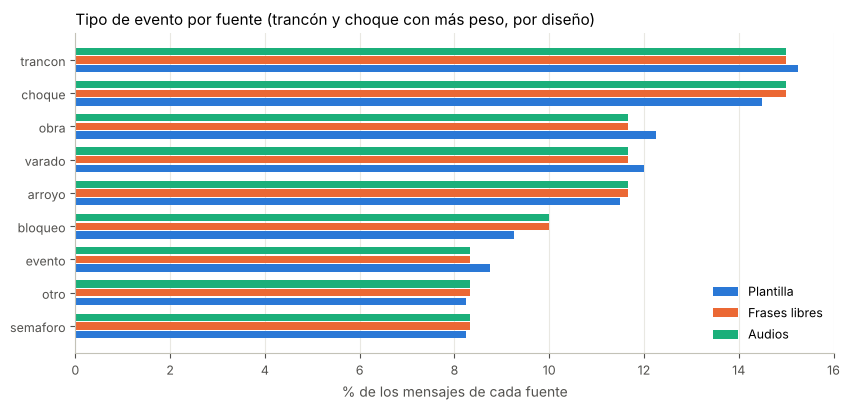

In [3]:
cob = {}
for c in ("tipo_evento", "severidad", "alcance", "modo", "duracion", "sentido", "es_despeje", "ruta"):
    t_ = pd.crosstab(d[c].astype(object).where(d[c].notna(), "(no lo dice)"), d.fuente)[ORDEN]
    cob[c] = t_
    print(f"— {c}"); display(t_)
ev = d[~d.es_despeje]
falta = [(c, f) for c in ("tipo_evento", "alcance", "modo", "duracion", "sentido", "ruta") for f in ORDEN
         if (cob[c][f] == 0).any()]
check("Cobertura: cada fuente tiene todos los tipos, alcances, «aquí»/«adelante», las 4 duraciones, ambos sentidos y las 3 rutas",
      not falta, str(falta) or "sin huecos")
sev = pd.crosstab(ev.severidad.dropna().astype(int), ev.fuente)[ORDEN]
check("Severidad 1–5 presente en las 3 fuentes, con al menos 8 casos por nivel", (sev >= 8).all().all(), sev.min().to_dict())
check("Despejes en las 3 fuentes (≥ 6) y «mi bus» en las 3 fuentes (≥ 3)",
      (cob["es_despeje"].loc[True] >= 6).all() and (cob["alcance"].loc["solo_bus"] >= 3).all())

fig, ax = plt.subplots(figsize=(8.6, 4.2))
tipos = cob["tipo_evento"].div(cob["tipo_evento"].sum()).mul(100).sort_values("Plantilla")
y = np.arange(len(tipos)); h = 0.26
for k, f in enumerate(ORDEN):
    ax.barh(y + (k - 1) * h, tipos[f], height=h - 0.04, color=COL[f], label=f)
ax.set_yticks(y, tipos.index); ax.set_xlabel("% de los mensajes de cada fuente", color=COL["texto2"])
ax.set_title("Tipo de evento por fuente (trancón y choque con más peso, por diseño)", loc="left", fontsize=11)
estilo(ax); ax.legend(frameon=False, fontsize=9, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "cobertura_tipos_10_3.png", dpi=150); plt.show()

### 3 · Qué tan «limpio» viene cada mensaje

In [4]:
pl = [x for x in T if x["fuente"] == "plantilla"]
meta = pd.DataFrame([x["meta"] for x in pl])
print("Plantilla (400):", {k: f"{100 * meta[k].mean():.1f} %" for k in ("sigue_formato", "desordenado", "etiqueta_olvidada", "con_error_tipeo")})
lib = [x for x in T if x["fuente"] == "libre_claude"]
print(f"Frases libres (120): ninguna cuenta como «sigue el formato»; {sum(bool(x['meta'].get('imitaba_guia_1_2')) for x in lib)} imitaban la guía 1.2 y conservan paráfrasis")
rev = pd.read_csv(D / "revision_persona3_frases_libres.csv")
print(f"Revisión de la Persona 3: {len(rev)} frases libres al azar → 30/30 correctas y realistas (28-oct 00:16)")
g = pd.read_csv(D / "guiones_audio_chatgpt.csv", dtype=str, keep_default_na=False)
eva = g[(g.es_despeje == "no") & (g.alcance == "via")]
print(f"Audios (60): {int((g.sigue_formato == 'si').sum())} con etiquetas y {int((g.sigue_formato == 'no').sum())} informales; "
      f"10 + 10 por grupo planeado; omisiones controladas: {int((eva.duracion == '').sum())} sin duración "
      f"({', '.join(eva[eva.duracion == ''].id)}) y {int((eva.sentido == '').sum())} sin sentido ({', '.join(eva[eva.sentido == ''].id)})")
display(pd.crosstab(g.condicion, g.sigue_formato))
ed = pd.read_csv(D / "guiones_ediciones_claude.csv", dtype=str, keep_default_na=False)
print(f"Correcciones de Claude a los guiones de ChatGPT, todas registradas: {len(ed)} filas en guiones_ediciones_claude.csv")
for x in (T[0], T[150], next(x for x in T if x["fuente"] == "libre_claude"), A[11], A[41]):
    print(f"  {x['id']:>5} · {x['texto']}")
p = subprocess.run([sys.executable, "validar_guiones_10_3.py"], capture_output=True, text=True, encoding="utf-8")
print(p.stdout.strip().splitlines()[0])
check("Los 60 guiones de audio pasan validar_guiones_10_3.py (0 problemas)", p.returncode == 0 and "con problemas: 0" in p.stdout,
      p.stdout.strip().splitlines()[0])
check("Formato repartido en el audio: 10 con etiquetas y 10 informales por grupo", (pd.crosstab(g.condicion, g.sigue_formato) == 10).all().all())

Plantilla (400): {'sigue_formato': '76.5 %', 'desordenado': '17.5 %', 'etiqueta_olvidada': '7.5 %', 'con_error_tipeo': '9.2 %'}
Frases libres (120): ninguna cuenta como «sigue el formato»; 55 imitaban la guía 1.2 y conservan paráfrasis
Revisión de la Persona 3: 30 frases libres al azar → 30/30 correctas y realistas (28-oct 00:16)
Audios (60): 30 con etiquetas y 30 informales; 10 + 10 por grupo planeado; omisiones controladas: 4 sin duración (A25, A49, A54, A58) y 4 sin sentido (A04, A08, A16, A40)


sigue_formato,no,si
condicion,,
bus,10,10
calle,10,10
silencio,10,10


Correcciones de Claude a los guiones de ChatGPT, todas registradas: 364 filas en guiones_ediciones_claude.csv
   P001 · reportando: evento: trancón, duración: larga, gravedad: 1, lugar: aquí
   L097 · carnaval aquí, la vía cerrada, los dos sentidos, más de dos horas
   L002 · Buenas, trancón aquí, lento, los dos sentidos
    A12 · Buenas, mire que hay obra aquí, gravedad 5, duración muy larga, en mi sentido.
    A42 · Buenas, ya despejaron la obra aquí.


Guiones: 60 · con problemas: 0 · problemas de reparto: 0


### 4 · Respuesta correcta y segmento real

In [5]:
dif = (d.seg_verdad - d.seg_respuesta).abs(); dif = np.minimum(dif, d.ruta.map(N_SEG) - dif)
d["exacto"] = dif == 0; d["pm1"] = dif <= 1
seg = d.groupby("fuente")[["exacto", "pm1"]].mean().reindex(ORDEN).mul(100).round(1)
seg["n"] = d.groupby("fuente").size().reindex(ORDEN)
tx = d[d.canal == "texto"]
seg.loc["Todo el texto"] = [round(100 * tx.exacto.mean(), 1), round(100 * tx.pm1.mean(), 1), len(tx)]
display(seg.rename(columns={"exacto": "% segmento exacto", "pm1": "% a ±1 segmento"}))
print("Diferencias por modo (texto):", tx[~tx.exacto].modo.value_counts().to_dict())
print(f"Esquina nombrada adelante del bus: mediana {d.adelante_m.median():,.0f} m (de {d.adelante_m.min():,.0f} a {d.adelante_m.max():,.0f} m)")
check("100 % de las respuestas correctas cumplen el contrato del evento 1.2", int(d.errores_contrato.sum()) == 0, f"{len(d)} eventos")
check("Con extracción perfecta, el segmento real queda a ±1 segmento en ≥ 95 % del texto", tx.pm1.mean() >= 0.95,
      f"{100 * tx.pm1.mean():.1f} %")

,% segmento exacto,% a ±1 segmento,n
fuente,,,
Plantilla,95.2,96.8,400.0
Frases libres,95.0,95.8,120.0
Audios,100.0,100.0,60.0
Todo el texto,95.2,96.5,520.0


Diferencias por modo (texto): {'aqui': 14, 'adelante': 11}
Esquina nombrada adelante del bus: mediana 1,518 m (de 310 a 2,990 m)


### 5 · Congelado e independiente

In [6]:
for f, info in man_t["archivos"].items():
    print(f"{f}: {info['items']} ítems · hash {info['sha256'][:12]}… · {'igual' if sha(D / f) == info['sha256'] else 'CAMBIÓ'}")
hist = man_t["historial"]; hist = eval(hist) if isinstance(hist, str) else hist
print(f"Versiones del set de texto: {len(hist) + 1} (guías " + ", ".join(h.get('guia', '?') for h in hist) + f", {man_t['guia']}); "
      f"motivo de la última: «{man_t['motivo_regeneracion']}»")
print(f"Audio: congelado el {man_a['creado']} · lugar real: {man_a['lugar_real']} · hash de audios_items "
      f"{'igual' if sha(D / 'audios_items.jsonl') == man_a['items_sha256'] else 'CAMBIÓ'}")
check("Texto congelado: los hashes del manifiesto coinciden", all(sha(D / f) == i["sha256"] for f, i in man_t["archivos"].items()))
check("Audio congelado: el manifiesto existe, trae el lugar real y el hash de audios_items coincide",
      man_a["congelado"] and bool(man_a.get("lugar_real")) and sha(D / "audios_items.jsonl") == man_a["items_sha256"])
print(f"Viajes de GPS usados: {d.idprogramacion.nunique()} distintos ({d.fecha.min()[:10]} → {d.fecha.max()[:10]}); "
      f"compartidos entre texto y audio: {len(set(tx.idprogramacion) & set(d[d.canal == 'audio'].idprogramacion))}")

textos_desarrollo.jsonl: 157 ítems · hash 484b27bdddbb… · igual
textos_prueba.jsonl: 363 ítems · hash f307e44ab4f4… · igual
Versiones del set de texto: 3 (guías 1.2, 1.3, 1.4); motivo de la última: «Guía 1.4 (28-oct-2026 00:59, Persona 3): la gravedad se dice solo con el número. Sin corridas previas de 10.4/10.5.»
Audio: congelado el 2026-10-28T09:49:49 · lugar real: sala · hash de audios_items igual
Viajes de GPS usados: 457 distintos (2023-01-02 → 2025-12-28); compartidos entre texto y audio: 15


### 6 · Las 60 notas de voz

Lugar real: sala (los grupos «calle» y «bus» se planearon pero no se grabaron allí)
Duración: mediana 7.8 s · de 3.1 a 11.5 s · más de 15 s: 0 · estado: {'ok': 60}
¿Cada archivo es el de su guion? correlación palabras–duración 0.75; corrida un puesto: 0.02 / 0.00
Ritmo: 1.83 palabras/s (de 1.16 a 2.71)
Audios que llegan al tope de volumen (pico ≥ 1,0): 23 de 60
Escucha de la Persona 3: A01, A20, A21, A40, A41, A60 → ['coincide con el guion']


particion,desarrollo,prueba
condicion,,
bus,6,14
calle,6,14
silencio,6,14


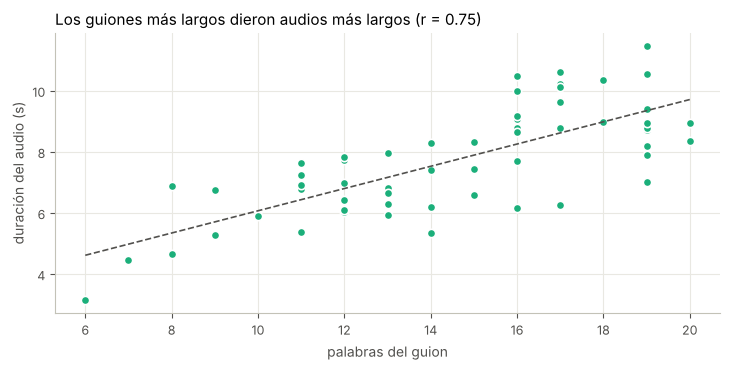

In [7]:
m = mapeo.copy(); m["palabras"] = m.guion.str.split().str.len()
print(f"Lugar real: {man_a['lugar_real']} (los grupos «calle» y «bus» se planearon pero no se grabaron allí)")
print(f"Duración: mediana {m.duracion_s.median():.1f} s · de {m.duracion_s.min():.1f} a {m.duracion_s.max():.1f} s · "
      f"más de 15 s: {(m.duracion_s > 15).sum()} · estado: {m.estado.value_counts().to_dict()}")
r0 = m.palabras.corr(m.duracion_s); rs = [np.corrcoef(m.palabras, np.roll(m.duracion_s, k))[0, 1] for k in (1, -1)]
print(f"¿Cada archivo es el de su guion? correlación palabras–duración {r0:.2f}; corrida un puesto: {rs[0]:.2f} / {rs[1]:.2f}")
print(f"Ritmo: {(m.palabras / m.duracion_s).median():.2f} palabras/s (de {(m.palabras / m.duracion_s).min():.2f} a {(m.palabras / m.duracion_s).max():.2f})")
print(f"Audios que llegan al tope de volumen (pico ≥ 1,0): {(m.pico >= 1.0).sum()} de 60")
esc = pd.read_csv(D / "verificacion_escucha_10_3.csv")
print(f"Escucha de la Persona 3: {', '.join(esc.id)} → {esc.resultado.unique().tolist()}")
display(m.groupby(["condicion", "particion"]).size().unstack())
check("60 notas de voz «ok», ninguna de más de 15 s", (m.estado == "ok").all() and len(m) == 60 and m.duracion_s.max() <= 15)
check("Cada archivo corresponde a su guion (correlación ≥ 0,5 y ≈ 0 al correrlo un puesto) y la escucha de 6 coincide",
      r0 >= 0.5 and max(abs(x) for x in rs) < 0.2 and (esc.resultado == "coincide con el guion").all() and len(esc) == 6)

fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.scatter(m.palabras, m.duracion_s, s=36, color=COL["Audios"], edgecolor="white", linewidth=1.2)
b = np.polyfit(m.palabras, m.duracion_s, 1); xs = np.linspace(m.palabras.min(), m.palabras.max(), 2)
ax.plot(xs, np.polyval(b, xs), color=COL["texto2"], lw=1.2, ls="--")
ax.set_xlabel("palabras del guion", color=COL["texto2"]); ax.set_ylabel("duración del audio (s)", color=COL["texto2"])
ax.set_title(f"Los guiones más largos dieron audios más largos (r = {r0:.2f})", loc="left", fontsize=11)
estilo(ax, grid="both"); fig.tight_layout(); fig.savefig(FIG / "audios_duracion_10_3.png", dpi=150); plt.show()

### 7 · Pruebas

In [8]:
p = subprocess.run([sys.executable, "tests_10_3.py"], capture_output=True, text=True, encoding="utf-8")
print(p.stdout.strip())
check("tests_10_3.py: 8/8 PASS", p.returncode == 0 and "8/8 PASS" in p.stdout, p.stdout.strip().splitlines()[-1])
chk = pd.DataFrame(CHECKS); chk.to_csv("datos_10/checks_10_3.csv", index=False)
display(chk); print(f"{(chk.resultado == 'PASS').sum()}/{len(chk)} PASS")

PASS  a · congelado: los hashes del manifiesto coinciden con los archivos
PASS  b · tamaños y partición: 400 de plantilla + 120 libres; prueba ≈ 70 % en cada fuente; sin ids repetidos
PASS  c · reparto de la plantilla: tipos según el diseño, 40 despejes y severidad pareja 1–5
PASS  d · contratos: cada mensaje cumple el de entrada 1.0 y cada respuesta correcta da un evento válido (1.2)
PASS  e · sin datos personales: ningún teléfono ni placa en los textos; frases libres = las de frases_libres.py
PASS  f · independencia: las ventanas de GPS vienen de viajes distintos de los 300 de la validación 10.1/10.2
PASS  g · guía 1.4 (gravedad con número): los mensajes de plantilla que siguen el formato llevan etiquetas; los despejes dicen el tipo
PASS  h · audio congelado: 60 guiones validados, respuesta correcta válida, partición 3/7 por lugar y formato, manifiesto con lugar real; hash de cada audio si los archivos están en este PC

8/8 PASS


,check,resultado,detalle
0,"Tamaños aprobados: 400 de plantilla, 120 libres y 60 audios (+ 120 copias con ruido)",PASS,
1,Partición ≈ 30/70 en cada fuente (prueba entre 67 % y 73 %),PASS,"{'Plantilla': 70.0, 'Frases libres': 69.2, 'Audios': 70.0}"
2,"Cobertura: cada fuente tiene todos los tipos, alcances, «aquí»/«adelante», las 4 durac...",PASS,[]
3,"Severidad 1–5 presente en las 3 fuentes, con al menos 8 casos por nivel",PASS,"{'Plantilla': 65, 'Frases libres': 18, 'Audios': 8}"
4,Despejes en las 3 fuentes (≥ 6) y «mi bus» en las 3 fuentes (≥ 3),PASS,
5,Los 60 guiones de audio pasan validar_guiones_10_3.py (0 problemas),PASS,Guiones: 60 · con problemas: 0 · problemas de reparto: 0
6,Formato repartido en el audio: 10 con etiquetas y 10 informales por grupo,PASS,
7,100 % de las respuestas correctas cumplen el contrato del evento 1.2,PASS,580 eventos
8,"Con extracción perfecta, el segmento real queda a ±1 segmento en ≥ 95 % del texto",PASS,96.5 %
9,Texto congelado: los hashes del manifiesto coinciden,PASS,


14/14 PASS


## Conclusiones

**Conclusión 1 · Un set de 520 textos y 60 audios, con margen de error declarado**
- **Contenido:**
  - **400 textos de plantilla**, armados con las esquinas reales de cada ruta;
  - **120 frases libres** escritas por Claude;
  - **60 notas de voz** grabadas por la Persona 3 con guiones de ChatGPT;
  - **120 copias de los audios** con ruido de tráfico sintético, a 10 y 5 dB.
- **Partición 30/70.** La parte de prueba tiene 280 textos de plantilla, 83 frases libres y 42 audios (70,0 / 69,2 / 70,0 % de cada fuente).
- **Margen de error al 95 %**, para una métrica cercana a 0,90 medida en la parte de prueba:

  | Fuente | Casos de prueba | Margen |
  |---|---|---|
  | Todo el texto | 363 | ±3,1 pp |
  | Plantilla | 280 | ±3,5 pp |
  | Frases libres | 83 | ±6,5 pp |
  | Audios | 42 | ±9,1 pp (en cada una de sus 3 versiones) |

- **El audio es la métrica menos precisa** y se reportará así.

**Conclusión 2 · Cubre todos los tipos y campos del contrato, en las tres fuentes**
- **Tipos:** los 9 tipos están en plantilla, frases libres y audios. Trancón y choque tienen más peso, por diseño; en la plantilla son 61 y 58 casos.
- **Severidad:** cada nivel de 1 a 5 tiene al menos 8 casos en cada fuente. El mínimo es 65 en la plantilla, 18 en las frases libres y 8 en los audios.
- **«Mi bus» y despejes:**

  | | Plantilla | Frases libres | Audios |
  |---|---|---|---|
  | «Mi bus» | 31 | 7 | 3 |
  | Despejes | 40 | 12 | 6 |

- **Otros campos:** las 4 duraciones, los 2 sentidos, «aquí» y «adelante», y las 3 rutas aparecen en cada fuente. Las rutas están parejas: 134/133/133, 40×3 y 20×3.
- **Qué tan limpio viene cada mensaje:**
  - **Plantilla:** el 76,5 % sigue el formato. El resto tiene variaciones: 17,5 % desordenado y 7,5 % con una etiqueta olvidada; además, el 9,2 % trae un error de tipeo.
  - **Frases libres:** ninguna sigue el formato. 55 imitan la guía 1.2 y conservan paráfrasis como «un carril» o «más de dos horas», como prueba de robustez.
  - **Audios:** 30 con etiquetas y 30 informales, 10 + 10 en cada grupo.
- **Omisiones a propósito en los audios:** 4 guiones sin duración (A25, A49, A54, A58) y 4 sin sentido (A04, A08, A16, A40). Sirven para medir que el extractor no invente esos datos.

**Conclusión 3 · La respuesta correcta es válida y el segmento real tiene un techo**
- **Contrato:** las **580** respuestas correctas cumplen el contrato del evento 1.2, incluidas sus reglas de coherencia.
- **Techo del segmento.** Con una extracción perfecta, el GPS de 5 min y el resolvedor de esquinas ubican el segmento real así:

  | | Segmento exacto | A ±1 segmento |
  |---|---|---|
  | Texto | **95,2 %** | 96,5 % |
  | Audios | 60/60 | 60/60 |

  - Las 25 diferencias del texto vienen 14 de «aquí» (sentido dudoso del GPS) y 11 de «adelante».
  - Es el mismo orden de la 10.1, que tuvo 94,7 % exacto.
  - **Es el techo de la métrica de punta a punta de la 10.5**, que no se le podrá exigir al extractor.
- **Corrección:** `CLAUDE.md` decía 98,1 % para el texto. Esa cifra era de la primera versión del set. Con el set congelado vigente (guía 1.4) es 95,2 %.
- **Distancia a la esquina:** la esquina nombrada queda entre 310 y 2.990 m adelante del bus, con mediana de 1.518 m.

**Conclusión 4 · Congelado antes de medir, con cambios registrados**
- **Texto:** hubo 3 versiones (guías 1.2, 1.3 y 1.4), todas generadas **antes de cualquier corrida de la 10.4 o la 10.5**. El motivo de cada una quedó en el manifiesto, y los hashes coinciden.
- **Audio:** se congeló el 28-oct-2026 a las 09:49, con el lugar real de grabación registrado («sala»). El hash de `audios_items.jsonl` coincide.
- **GPS:**
  - **457 viajes** distintos, de enero de 2023 a diciembre de 2025;
  - ninguno está entre los 300 de la validación 10.1/10.2;
  - 15 viajes se repiten entre el texto y el audio, pero con mensajes distintos.
- **Guiones de ChatGPT:** Claude los corrigió en varias rondas (gramática, guía 1.4, datos completos, orden de grabación). Las 364 ediciones quedaron registradas en `guiones_ediciones_claude.csv`, y la versión anterior está en `set_prueba/historial/`.
- **Verificación de los audios:** los guiones más largos dieron audios más largos (r = 0,75). Con los archivos corridos un puesto, la correlación cae a 0,00–0,02, así que no hay audios cruzados. La Persona 3 escuchó 6 audios y los 6 coinciden con su guion.
- **Pruebas:** tests 8/8 y checks del notebook 14/14.

**Conclusión 5 · Limitaciones y qué sigue en la 10.4**
- **Limitaciones que se declaran:**
  - **Un solo hablante.** La métrica de audio mide a Whisper con una voz, no con la variedad de los conductores.
  - **Grabados en una sala.** No hay ruido real de calle ni de bus. El efecto del ruido se mide solo con las copias sintéticas (SNR 10 y 5 dB), y el grupo planeado (silencio, calle o bus) no se usa como factor de ruido.
  - **Volumen al tope.** 23 de los 60 audios llegan al máximo de volumen. Hay que revisar en la 10.4 si el recorte afecta la transcripción.
  - **Riesgo de un F1 optimista.** Los textos los escribió Claude y los interpretará Claude. El F1 se reportará por fuente (plantilla, frases libres, audios), y los guiones de audio son de otro modelo.
  - **Claude vio unos 25 ítems de prueba** al revisar el set. En la 10.5 se trabaja solo con desarrollo.
- **10.4 (requiere un alcance aprobado):**
  - transcribir con Whisper local los 60 audios y sus 120 copias con ruido;
  - medir el error de palabras (WER) y el acierto en los campos clave: número de gravedad, palabra de duración, esquina;
  - ajustar solo con los 18 audios de desarrollo y evaluar la prueba una sola vez.

---
# Parte 6 · Módulo 10 · Subfase 10.4 · Audio → texto (Whisper)
*Notebook original: `modulo10/subfase_10_4_audio.ipynb`*

# SOBUSA · Módulo 10 · Subfase 10.4 — Audio → texto con Whisper local

**Persona 3.** Las notas de voz de los conductores se convierten en texto **en el PC**, sin enviar el audio a ningún
servicio, con Whisper `turbo` (large-v3-turbo) a través de faster-whisper (licencia MIT). El texto sale tal cual hacia la
10.5, donde Claude extrae el evento. Alcance aprobado: `revisiones/alcance_10_4.md`.

| Paso | Qué se hizo | Dónde |
|---|---|---|
| Entorno | RTX 3050 (CUDA 12, float16); el modelo se descargó una vez de Hugging Face | PC de la Persona 3 |
| Desarrollo | 18 audios × 3 versiones (limpio, ruido a 10 dB y a 5 dB) × 2 configuraciones (sin y con texto de ayuda) = 108 transcripciones | `transcripciones_desarrollo.jsonl` |
| Congelar | Se eligió la configuración con más acierto en los campos clave y se guardó con hash **antes** de tocar la prueba | `config_10_4.json` |
| Prueba | 42 audios × 3 versiones = 126 transcripciones, **una sola vez** | `transcripciones_prueba.jsonl` |

**Cómo se mide.**
- **Campos clave:** los 7 datos que necesita la 10.5: tipo, lugar, gravedad, duración, sentido, «despejado» y «mi bus». Cada uno está bien si lo que dice el guion aparece igual en la transcripción, y si el guion no lo dice, la transcripción tampoco.
- **WER:** el porcentaje de palabras distintas entre el guion y la transcripción, después de normalizar (minúsculas, sin tildes, «tres» → 3).
- **Tiempo por audio:** se mide en el PC e incluye decodificar el audio.

Costo: $0. Los audios no salieron del PC.

## Parte 2 · Análisis offline

In [1]:
import hashlib
import json
import subprocess
import sys
from math import sqrt
from pathlib import Path
from typing import Dict, List
import difflib
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, "src")
from m10.normalizar import campos, normalizar, wer

pd.set_option("display.max_columns", None); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 120)
S = Path("datos_10/transcripcion"); D = Path("datos_10/set_prueba"); FIG = Path("resultados_10"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
def check(nombre: str, ok: bool, detalle: str = "") -> None:
    CHECKS.append({"check": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": detalle})
CAMPOS = ["tipo", "lugar", "gravedad", "duracion", "sentido", "despejado", "mi_bus"]
VERS = ["limpio", "snr10", "snr5"]
cfg = json.loads((S / "config_10_4.json").read_text(encoding="utf-8"))
items = {json.loads(l)["id"]: json.loads(l) for l in open(D / "audios_items.jsonl", encoding="utf-8")}
TD = [json.loads(l) for l in open(S / "transcripciones_desarrollo.jsonl", encoding="utf-8")]
TP = [json.loads(l) for l in open(S / "transcripciones_prueba.jsonl", encoding="utf-8")]
mdv = pd.read_csv(S / "metricas_desarrollo_detalle_10_4.csv"); mpr = pd.read_csv(S / "metricas_prueba_detalle_10_4.csv")
def resumen(m, por):
    g = m.groupby(por)
    r = pd.DataFrame({"n": g.size(), "WER %": 100 * g.errores.sum() / g.palabras.sum(),
                      "campos clave %": 100 * g[[f"ok_{k}" for k in CAMPOS]].mean().mean(axis=1),
                      "audios perfectos %": 100 * g.todos_ok.mean(), "s mediana": g.segundos.median(), "s P95": g.segundos.quantile(.95)})
    return r.round(2)
def wilson(k, n, z=1.96):
    p = k / n; c = (p + z * z / (2 * n)) / (1 + z * z / n); h = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return 100 * (c - h), 100 * (c + h)
COL = {"sin_vocabulario": "#c3c2b7", "con_vocabulario": "#2a78d6", "prueba": "#1baf7a", "texto2": "#52514e", "grid": "#e9e8e2"}
print(f"Whisper {cfg['modelo']} · faster-whisper {cfg['faster_whisper']} · {cfg['dispositivo']}/{cfg['compute_type']} · "
      f"beam {cfg['beam_size']} · configuración congelada: {cfg['config']} ({cfg['creado']})")

Whisper turbo · faster-whisper 1.2.1 · cuda/float16 · beam 5 · configuración congelada: con_vocabulario (2026-10-28T10:46:46)


### 1 · Configuración congelada antes de la prueba

In [2]:
h = hashlib.sha256(json.dumps({k: v for k, v in cfg.items() if k not in ("creado", "hash_config")}, sort_keys=True,
                              ensure_ascii=False).encode()).hexdigest()
print("Texto de ayuda congelado:\n ", cfg["texto_inicial"])
print(f"hash {cfg['hash_config'][:16]}… → {'coincide' if h == cfg['hash_config'] else 'NO COINCIDE'}")
check("Configuración congelada: el hash coincide y apunta a las métricas de desarrollo usadas para elegir",
      h == cfg["hash_config"] and hashlib.sha256((S / "metricas_desarrollo_10_4.csv").read_bytes()).hexdigest() == cfg["metricas_desarrollo_sha256"])
check("Prueba: 126 transcripciones (42 audios × 3 versiones), todas con la configuración congelada",
      len(TP) == 126 and {t["config"] for t in TP} == {cfg["config"]} and len({t["id"] for t in TP}) == 42)
check("Desarrollo: 108 transcripciones (18 × 3 × 2 configuraciones); ningún audio de prueba",
      len(TD) == 108 and all(items[t["id"]]["particion"] == "desarrollo" for t in TD))

Texto de ayuda congelado:
  Reporte de conductor de bus en Barranquilla. Evento: trancón, choque, varado, obra, arroyo, bloqueo, evento, semáforo, otro. Afecta: mi bus. Lugar: aquí, adelante en la calle con la carrera. Gravedad: 1, 2, 3, 4, 5. Duración: corta, media, larga, muy larga. Sentido: mi sentido, los dos. Despejado. Murillo, Circunvalar, Cordialidad, Autopista Aeropuerto.
hash f2eb35e59573f795… → coincide


### 2 · Desarrollo: ¿con o sin texto de ayuda?

In [3]:
rd = resumen(mdv, ["config", "version"]); display(rd)
tot = resumen(mdv, ["config"]); display(tot)
print("Errores en desarrollo (campo que falla · guion → transcripción):")
for t in TD:
    mal = [k for k, v in campos(items[t["id"]], t["texto"]).items() if not v]
    if mal and t["version"] == "limpio":
        print(f"  {t['config']:16} {t['id']} {mal}: «{items[t['id']]['texto']}» → «{t['texto']}»")
elegida = tot.sort_values(["campos clave %", "WER %"], ascending=[False, True]).index[0]
check("La configuración congelada es la que más acierta los campos clave en desarrollo (regla del alcance)",
      elegida == cfg["config"], f"{elegida}: {tot.loc[elegida, 'campos clave %']:.2f} %")

n  WER %  campos clave %  audios perfectos %  s mediana  s P95
config          version                                                                 
con_vocabulario limpio   18   1.19           99.21               94.44       0.71   0.80
                snr10    18   1.19           99.21               94.44       0.68   0.79
                snr5     18   1.19           99.21               94.44       0.69   0.78
sin_vocabulario limpio   18   2.78           96.03               72.22       0.61   0.68
                snr10    18   3.97           95.24               66.67       0.61   0.67
                snr5     18   3.97           95.24               72.22       0.62   0.69

,n,WER %,campos clave %,audios perfectos %,s mediana,s P95
config,,,,,,
con_vocabulario,54,1.19,99.21,94.44,0.69,0.79
sin_vocabulario,54,3.57,95.50,70.37,0.61,0.69


Errores en desarrollo (campo que falla · guion → transcripción):
  sin_vocabulario  A26 ['tipo']: «Evento: obra, lugar: aquí, gravedad: 3, duración: muy larga, sentido: mi sentido.» → «Evento, hora, lugar, aquí, gravedad, tres, duración, muy larga, sentido, mi sentido.»
  sin_vocabulario  A27 ['lugar']: «Evento: bloqueo, lugar: adelante en Circunvalar con Autopista Aeropuerto, gravedad: 2, duración: larga, sentido: los dos.» → «Evento, bloqueo, lugar, adelante en la circunvalar con autopista de aeropuerto, gravedad 2, duración larga, sentido los dos.»
  sin_vocabulario  A40 ['tipo']: «Pilas, hay arroyo adelante en la 76 con la 38, gravedad 3, duración media.» → «Pilas, hay arrobio adelante en la 76 con la 38, gravedad 3, duración media.»
  sin_vocabulario  A54 ['tipo']: «Ojo que hay bloqueo adelante en la 19 con la 22, gravedad 1, en los dos sentidos.» → «Ojo, que hay bloque adelante en la 19 con la 22, gravedad 1 en los dos sentidos.»
  sin_vocabulario  A58 ['tipo']: «Ojo que hay un b

### 3 · Prueba: evaluación única

,n,WER %,campos clave %,audios perfectos %,s mediana,s P95
version,,,,,,
limpio,42,3.66,100.00,100.00,0.69,0.80
snr10,42,4.14,99.32,95.24,0.68,0.78
snr5,42,4.30,99.32,95.24,0.68,0.82


n  WER %  campos clave %  audios perfectos %  s mediana  s P95
version formato                                                                   
limpio  etiquetas  21   3.75          100.00              100.00       0.70   0.77
        informal   21   3.58          100.00              100.00       0.69   0.80
snr10   etiquetas  21   4.44           99.32               95.24       0.68   0.78
        informal   21   3.88           99.32               95.24       0.66   0.76
snr5    etiquetas  21   4.44           99.32               95.24       0.69   0.80
        informal   21   4.18           99.32               95.24       0.67   0.82

,tipo,lugar,gravedad,duracion,sentido,despejado,mi_bus
version,,,,,,,
limpio,100.00,100.00,100.0,100.0,100.0,100.0,100.0
snr10,97.62,97.62,100.0,100.0,100.0,100.0,100.0
snr5,95.24,100.00,100.0,100.0,100.0,100.0,100.0


limpio: audios con los 7 campos bien 42/42 → IC95 % de Wilson [91.6 %; 100.0 %]
snr10: audios con los 7 campos bien 40/42 → IC95 % de Wilson [84.2 %; 98.7 %]
snr5: audios con los 7 campos bien 40/42 → IC95 % de Wilson [84.2 %; 98.7 %]

Los errores de campo en la prueba:
  A09 snr10  ['tipo']: «Le reporto que mi bus se varó aquí, está orillado, no afecta la vía, duración corta.» → «Les reporto que mi bus se barba aquí. Está orillado, no afecta la vía, duración corta.»
  A09 snr5   ['tipo']: «Le reporto que mi bus se varó aquí, está orillado, no afecta la vía, duración corta.» → «Les reporto que mi bus se barba aquí. Está orillado, no afecta la vía, duración corta.»
  A25 snr10  ['lugar']: «Evento: semáforo, lugar: adelante en la 87 con la 46, gravedad: 2, sentido: los dos.» → «Evento, semáforo, lugar, adelante en la 57 con la 46. Gravedad, 2. Sentido, los dos.»
  A29 snr5   ['tipo']: «Evento: trancón, lugar: adelante en la 94 con la 53, gravedad: 1, duración: media, sentido: los dos.» →

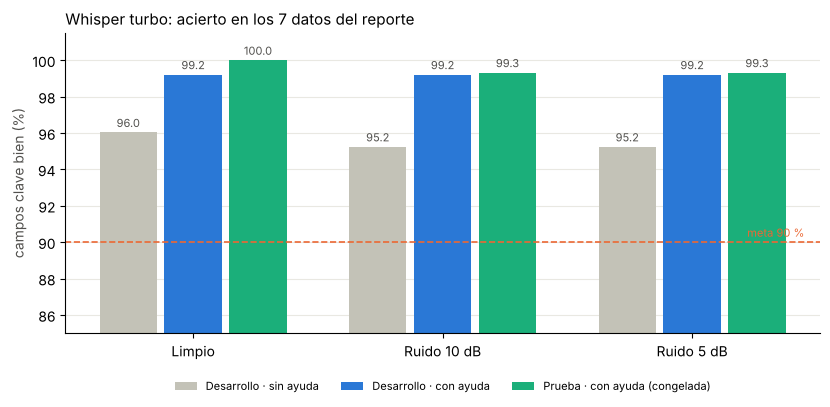

In [4]:
rp = resumen(mpr, ["version"]).reindex(VERS); display(rp)
display(resumen(mpr, ["version", "formato"]))
por_campo = (100 * mpr.groupby("version")[[f"ok_{k}" for k in CAMPOS]].mean()).reindex(VERS).round(2)
por_campo.columns = CAMPOS; display(por_campo)
for v in VERS:
    k = int(mpr[mpr.version == v].todos_ok.sum()); lo, hi = wilson(k, 42)
    print(f"{v}: audios con los 7 campos bien {k}/42 → IC95 % de Wilson [{lo:.1f} %; {hi:.1f} %]")
print("\nLos errores de campo en la prueba:")
for t in TP:
    mal = [k for k, v in campos(items[t["id"]], t["texto"]).items() if not v]
    if mal:
        print(f"  {t['id']} {t['version']:6} {mal}: «{items[t['id']]['texto']}» → «{t['texto']}»")
check("Meta aprobada: campos clave ≥ 90 % en limpio, SNR 10 y SNR 5 (prueba)", (rp["campos clave %"] >= 90).all(),
      rp["campos clave %"].to_dict())
rec = pd.DataFrame([{"id": t["id"], "version": t["version"], "e": wer(items[t["id"]]["texto"], t["texto"])[0]} for t in TP])
check("Las métricas de la prueba se reproducen desde el texto con normalizar.py", (rec.merge(mpr, on=["id", "version"]).eval("e == errores")).all())

fig, ax = plt.subplots(figsize=(8.4, 4.2))
x = np.arange(3); w = 0.26
series = [("Desarrollo · sin ayuda", resumen(mdv[mdv.config == "sin_vocabulario"], ["version"]).reindex(VERS)["campos clave %"], COL["sin_vocabulario"]),
          ("Desarrollo · con ayuda", resumen(mdv[mdv.config == "con_vocabulario"], ["version"]).reindex(VERS)["campos clave %"], COL["con_vocabulario"]),
          ("Prueba · con ayuda (congelada)", rp["campos clave %"], COL["prueba"])]
for k, (nom, val, col) in enumerate(series):
    b = ax.bar(x + (k - 1) * w, val, width=w - 0.03, color=col, label=nom)
    ax.bar_label(b, fmt="%.1f", fontsize=8, color=COL["texto2"], padding=2)
ax.axhline(90, color="#eb6834", lw=1.2, ls="--"); ax.text(2.45, 90.3, "meta 90 %", color="#eb6834", fontsize=8, ha="right")
ax.set_xticks(x, ["Limpio", "Ruido 10 dB", "Ruido 5 dB"]); ax.set_ylim(85, 101.5); ax.set_ylabel("campos clave bien (%)", color=COL["texto2"])
ax.set_title("Whisper turbo: acierto en los 7 datos del reporte", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color=COL["grid"]); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
fig.tight_layout(); fig.savefig(FIG / "acierto_campos_10_4.png", dpi=150); plt.show()

### 4 · Qué mide el WER aquí

In [5]:
c = Counter()
for t in TP:
    if t["version"] != "limpio":
        continue
    r, h_ = normalizar(items[t["id"]]["texto"]), normalizar(t["texto"])
    for op, a1, a2, b1, b2 in difflib.SequenceMatcher(None, r, h_).get_opcodes():
        if op != "equal":
            c[(" ".join(r[a1:a2]) or "∅", " ".join(h_[b1:b2]) or "∅")] += 1
lim = mpr[mpr.version == "limpio"]
print(f"Audio limpio: {int(lim.errores.sum())} palabras distintas de {int(lim.palabras.sum())} "
      f"({100 * lim.errores.sum() / lim.palabras.sum():.2f} %), en {int((lim.errores > 0).sum())} de 42 audios.")
print("Diferencias más frecuentes (guion → transcripción):")
for (a, b), n in c.most_common(10):
    print(f"  {n} × «{a}» → «{b}»")

Audio limpio: 23 palabras distintas de 628 (3.66 %), en 15 de 42 audios.
Diferencias más frecuentes (guion → transcripción):
  3 × «con la» → «∅»
  3 × «le» → «les»
  2 × «la» → «∅»
  2 × «sentido» → «∅»
  2 × «∅» → «sentidos»
  2 × «∅» → «la»
  1 × «en» → «∅»
  1 × «hay» → «haya»
  1 × «∅» → «aqui»
  1 × «evento» → «∅»


### 5 · Volumen al tope (hallazgo H15 de la 10.3)

In [6]:
mp = pd.read_csv(D / "mapeo_audios.csv", encoding="utf-8-sig")[["id", "pico"]]
x_ = mpr.merge(mp, on="id"); x_["tope"] = np.where(x_.pico >= 1.0, "al tope (pico ≥ 1)", "normal")
vt = resumen(x_, ["version", "tope"]); display(vt)
dif_tope = (vt.xs("al tope (pico ≥ 1)", level="tope")["WER %"] - vt.xs("normal", level="tope")["WER %"])
print("Diferencia de WER (al tope − normal), puntos:", dif_tope.round(2).to_dict())
check("El volumen al tope no baja el acierto de campos en el audio limpio (H15)",
      vt.loc[("limpio", "al tope (pico ≥ 1)"), "campos clave %"] >= vt.loc[("limpio", "normal"), "campos clave %"] - 1e-9)

n  WER %  campos clave %  audios perfectos %  s mediana  s P95
version tope                                                                               
limpio  al tope (pico ≥ 1)  20   4.06          100.00              100.00       0.69   0.80
        normal              22   3.25          100.00              100.00       0.69   0.77
snr10   al tope (pico ≥ 1)  20   4.69           99.29               95.00       0.68   0.76
        normal              22   3.57           99.35               95.45       0.67   0.78
snr5    al tope (pico ≥ 1)  20   4.69           99.29               95.00       0.68   0.80
        normal              22   3.90           99.35               95.45       0.68   0.82

Diferencia de WER (al tope − normal), puntos: {'limpio': 0.81, 'snr10': 1.12, 'snr5': 0.79}


### 6 · Ruido simulado y tiempo

In [7]:
print(f"Campos clave: limpio {rp.loc['limpio', 'campos clave %']:.2f} % → 10 dB {rp.loc['snr10', 'campos clave %']:.2f} % → "
      f"5 dB {rp.loc['snr5', 'campos clave %']:.2f} %; WER {rp.loc['limpio', 'WER %']:.2f} → {rp.loc['snr5', 'WER %']:.2f} %")
mpr["rtf"] = mpr.segundos / mpr.duracion_audio_s
print(f"Tiempo por audio (GPU, incluye decodificar): mediana {mpr.segundos.median():.2f} s · P95 {mpr.segundos.quantile(.95):.2f} s · "
      f"máximo {mpr.segundos.max():.2f} s · {mpr.segundos.median() / mpr.duracion_audio_s.median():.2f} s por segundo de audio "
      f"(≈ {1 / mpr.rtf.median():.0f} veces más rápido que el audio)")
print(f"Duración de los audios: mediana {mpr.duracion_audio_s.median():.1f} s")
check("Tiempo de transcripción por audio < 2,5 s en el P95 (GPU)", mpr.segundos.quantile(.95) < 2.5, f"{mpr.segundos.quantile(.95):.2f} s")

Campos clave: limpio 100.00 % → 10 dB 99.32 % → 5 dB 99.32 %; WER 3.66 → 4.30 %
Tiempo por audio (GPU, incluye decodificar): mediana 0.69 s · P95 0.80 s · máximo 0.95 s · 0.09 s por segundo de audio (≈ 11 veces más rápido que el audio)
Duración de los audios: mediana 8.0 s


### 7 · Pruebas

In [8]:
p = subprocess.run([sys.executable, "tests_10_4.py"], capture_output=True, text=True, encoding="utf-8")
print(p.stdout.strip())
check("tests_10_4.py: 7/7 PASS", p.returncode == 0 and "7/7 PASS" in p.stdout, p.stdout.strip().splitlines()[-1])
chk = pd.DataFrame(CHECKS); chk.to_csv("datos_10/checks_10_4.csv", index=False)
display(chk); print(f"{(chk.resultado == 'PASS').sum()}/{len(chk)} PASS")

PASS  a · números en letras → cifras («setenta y dos» → 72, «cincuenta y uno be» → 51b); «un bus» no cambia
PASS  b · WER: 0 con el mismo texto (aunque cambien tildes, mayúsculas, puntuación y números); cuenta bien sustituciones e inserciones
PASS  c · con la transcripción perfecta (el guion mismo) los 60 audios aciertan los 7 campos
PASS  d · un error en un campo se detecta solo en ese campo (gravedad, duración, sentido, lugar, tipo)
PASS  e · campos que el guion no dice: si la transcripción inventa duración o sentido, se cuenta como error
PASS  f · el texto inicial de Whisper no trae esquinas ni números de los guiones (solo la guía y las avenidas)
PASS  g · evaluación única: configuración congelada (hash), prueba transcrita una vez y métricas reproducibles desde el texto

7/7 PASS


,check,resultado,detalle
0,Configuración congelada: el hash coincide y apunta a las métricas de desarrollo usadas para elegir,PASS,
1,"Prueba: 126 transcripciones (42 audios × 3 versiones), todas con la configuración congelada",PASS,
2,Desarrollo: 108 transcripciones (18 × 3 × 2 configuraciones); ningún audio de prueba,PASS,
3,La configuración congelada es la que más acierta los campos clave en desarrollo (regla del alcance),PASS,con_vocabulario: 99.21 %
4,"Meta aprobada: campos clave ≥ 90 % en limpio, SNR 10 y SNR 5 (prueba)",PASS,"{'limpio': 100.0, 'snr10': 99.32, 'snr5': 99.32}"
5,Las métricas de la prueba se reproducen desde el texto con normalizar.py,PASS,
6,El volumen al tope no baja el acierto de campos en el audio limpio (H15),PASS,
7,"Tiempo de transcripción por audio < 2,5 s en el P95 (GPU)",PASS,0.80 s
8,tests_10_4.py: 7/7 PASS,PASS,7/7 PASS


9/9 PASS


## Conclusiones

**Conclusión 1 · Whisper local cumple la meta en las tres versiones del audio**
- **Prueba (evaluación única, 42 audios):** los 7 datos clave salieron bien en el **100 %** del audio limpio y en el **99,32 %** con ruido a 10 dB y a 5 dB. La meta aprobada era ≥ 90 % en las tres.
  - Audio limpio: los 42 audios quedaron con los 7 datos bien (IC95 % de Wilson [91,6 %; 100 %]).
  - Con ruido: 40/42 (IC95 % [84,2 %; 98,7 %]).
- **Por dato:** gravedad, duración, sentido, «despejado» y «mi bus» salieron bien en el 100 % de las 126 transcripciones. Los únicos errores fueron en el tipo y el lugar.
- **Por formato:** con etiquetas y en lenguaje informal el resultado es el mismo (100 % limpio; 99,32 % con ruido). La guía no es indispensable para que Whisper entienda el mensaje.

**Conclusión 2 · El texto de ayuda con la guía es lo que más aporta**
- **En desarrollo** (18 audios × 3 versiones), darle a Whisper un texto inicial con el vocabulario de la guía y las avenidas mejoró:

  | | Sin ayuda | Con ayuda |
  |---|---|---|
  | Datos clave bien | 95,50 % | **99,21 %** |
  | WER | 3,57 % | 1,19 % |
  | Audios perfectos | 70,37 % | 94,44 % |

- **Qué corrige:** sin ayuda, Whisper escribía «arrobio», «bloque», «parado» y «autopista de aeropuerto». Con ayuda, lo único que quedó mal fue A26: «Evento: obra» → «Evento, hora», en las 3 versiones.
- **Sin pistas de la prueba:** el texto de ayuda no lleva esquinas ni números de los guiones, solo la guía y las avenidas que un sistema real ya conoce (prueba f).
- **Congelada antes de la prueba:** se congeló esta configuración (hash `f2eb35e5…`) antes de transcribir la prueba, según la regla del alcance.

**Conclusión 3 · Los pocos errores son de palabras sueltas; el WER mide también la lectura**
- **Los 4 errores de dato en la prueba** son todos con ruido:
  - A09: «se varó» → «se barba», en 10 y 5 dB;
  - A25: «la 87» → «la 57», en 10 dB;
  - A29: «Evento: trancón» → «Rancón», en 5 dB.
- **El WER del audio limpio (3,66 %)** son 23 palabras distintas de 628, en 15 de los 42 audios. La mayoría son diferencias de lectura frente al guion, no errores de Whisper:
  - «con la» que no se dijo (3);
  - «le» → «les» (3);
  - «sentido: los dos» leído como «los dos sentidos».

  Por eso el WER es una cota pesimista.
- **Volumen al tope (H15 de la 10.3):** en los 20 audios de prueba con el volumen al tope, el WER es entre 0,8 y 1,1 puntos mayor que en los demás, pero el acierto de los datos es el mismo (100 % en limpio). No afecta lo que necesita la 10.5. **H15 se cierra.**

**Conclusión 4 · Rápido y privado: 0,7 s por audio en la GPU, sin salir del PC**
- **Tiempo por audio en la RTX 3050**, incluida la decodificación: mediana **0,69 s**, P95 0,80 s y máximo 0,95 s. Los audios duran unos 8 s, así que Whisper transcribe ~11 veces más rápido que el habla, y la transcripción gasta solo una parte pequeña de los 2,5 s del plan.
- **Equipo:** con la CPU tomaría varios segundos. La GPU necesitó instalar las librerías de CUDA 12 (`nvidia-cublas-cu12`, `nvidia-cudnn-cu12`).
- **Privacidad y costo:** el audio nunca salió del PC: el modelo se descargó una vez y Whisper corre sin internet. Costo: $0.
- **Corrección técnica:** faster-whisper 1.2.1 no funciona con la PyAV instalada (versión 19). El audio se decodifica con una función propia (`leer_audio`).

**Conclusión 5 · Alcance de la validación y qué sigue en la 10.5**
- **Ruido simulado más suave que el real:** el ruido a 5 dB bajó el acierto solo de 100 % a 99,32 %. Es buena señal para Whisper, pero también muestra que este ruido es más fácil que el de un bus real (los audios se grabaron en una sala).
- **Una sola voz, con 42 audios de prueba:** el margen es amplio; el IC95 % del audio limpio empieza en 91,6 %.
- **Siguiente paso natural:** probar con notas de voz reales de conductores, dentro del bus.
- **Para la 10.5:**
  - recibe el texto tal cual sale de Whisper (decisión c);
  - el extractor debe tolerar errores sueltos como «hora» por «obra», «barba» por «varó» o «Rancón» por «trancón»; se probará con los audios de desarrollo;
  - el F1 del plan se medirá sobre el texto transcrito (audio) y sobre el escrito (texto), por separado.

---
# Parte 7 · Módulo 10 · Subfase 10.5 · Extracción con Claude
*Notebook original: `modulo10/subfase_10_5_extraccion.ipynb`*

# SOBUSA · Módulo 10 · Subfase 10.5 — Texto → evento con la API de Claude

**Persona 3.** Cada mensaje del conductor (texto escrito o la transcripción de su nota de voz, 10.4) pasa por Claude con
**Structured Outputs**: la respuesta es un JSON que cumple un esquema Pydantic estricto. Con esa extracción y el GPS del
bus, `construir_evento` (10.2) arma el evento 1.2 con su segmento. Alcance aprobado: `revisiones/alcance_10_5.md`.

| Paso | Qué se hizo | Dónde |
|---|---|---|
| Modelo | `claude-haiku-5-5` con Structured Outputs (`output_config.format`) y caché del prompt | `src/m10/extractor.py` |
| Desarrollo | 157 textos + 54 transcripciones (18 audios × 3 versiones), prompt v1, esfuerzo **low** | `respuestas_desarrollo_v1_low.jsonl` |
| Congelar | Modelo, esfuerzo, prompt y esquema con hash, **antes** de tocar la prueba | `config_10_5.json` |
| Prueba | 363 textos + 126 transcripciones, **una sola vez** | `respuestas_prueba.jsonl` |

**Cómo se mide** (definido en la 10.3 y el alcance):
- **F1 macro por campo** (tipo, alcance, gravedad, duración, sentido, despejado y lugar), con «no lo dijo» como una clase más.
  En el lugar, «adelante» solo cuenta si las dos vías coinciden con las del guion. La métrica del plan es el promedio de los 7.
- **Mensajes perfectos:** los 7 campos bien.
- **Punta a punta:** el segmento del evento construido frente a la verdad del set, comparado con el techo de la 10.3
  (el segmento que sale con una extracción perfecta).
- **Latencia:** el tiempo de cada llamada nueva a la API, medido en el PC (red incluida); no cuenta las respuestas que salen de la caché en disco.

A la API solo fue texto: el audio no salió del PC.

## Parte 2 · Análisis offline

In [1]:
import hashlib
import json
import re
import subprocess
import sys
from math import sqrt
from pathlib import Path
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, "src")
from m10.metricas_extraccion import CAMPOS, campos_errados, etiqueta, evaluar
from m10.esquema_extraccion import hash_esquema, validar
from m10.extractor import cargar_prompt
import punta_a_punta_10_5 as PP

pd.set_option("display.max_columns", None); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 110)
S = Path("datos_10/extraccion"); D = Path("datos_10/set_prueba"); FIG = Path("resultados_10"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
def check(nombre: str, ok: bool, detalle: str = "") -> None:
    CHECKS.append({"check": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": detalle})
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
def wilson(k, n, z=1.96):
    p = k / n; c = (p + z * z / (2 * n)) / (1 + z * z / n); h = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return 100 * (c - h), 100 * (c + h)
cfg = json.loads((S / "config_10_5.json").read_text(encoding="utf-8"))
RP = pd.DataFrame([json.loads(l) for l in open(S / "respuestas_prueba.jsonl", encoding="utf-8")])
RD = pd.DataFrame([json.loads(l) for l in open(S / "respuestas_desarrollo_v1_low.jsonl", encoding="utf-8")])
uso = pd.read_csv("datos_10/uso_api.csv")
GRUPOS = {"TEXTO (meta)": lambda d: d.canal == "texto", "AUDIO (meta)": lambda d: d.canal == "audio",
          "texto · plantilla": lambda d: d.fuente == "plantilla", "texto · frases libres": lambda d: d.fuente == "libre_claude",
          "audio · limpio": lambda d: d.version == "limpio", "audio · ruido 10 dB": lambda d: d.version == "snr10",
          "audio · ruido 5 dB": lambda d: d.version == "snr5"}
def tabla(R):
    filas = []
    for g, f in GRUPOS.items():
        sub = R[f(R)]
        ev = evaluar([{"esperado": e, "extraccion": x} for e, x in zip(sub.esperado, sub.extraccion)])
        filas.append({"grupo": g, "n": ev["n"], "F1": ev["f1_promedio"], "perfectos %": 100 * ev["perfectos"], **{c: ev[f"f1_{c}"] for c in CAMPOS}})
    return pd.DataFrame(filas).set_index("grupo")
COL = {"texto": "#2a78d6", "audio": "#1baf7a", "pensó": "#eb6834", "texto2": "#52514e", "grid": "#e9e8e2", "meta": "#c0392b"}
print(f"Modelo {cfg['modelo']} · esfuerzo {cfg['esfuerzo']} · prompt {cfg['version_prompt']} · congelado {cfg['creado']} · "
      f"hash {cfg['hash_config'][:12]}…")

Modelo claude-haiku-5-5 · esfuerzo low · prompt v1 · congelado 2026-10-28T11:18:45 · hash d550de7053c0…


### 1 · Configuración congelada y elección del esfuerzo

In [2]:
h = hashlib.sha256(json.dumps({k: v for k, v in cfg.items() if k not in ("creado", "hash_config")}, sort_keys=True,
                              ensure_ascii=False).encode()).hexdigest()
hp = hashlib.sha256(cargar_prompt(cfg["version_prompt"]).encode("utf-8")).hexdigest()
print(f"hash de la configuración → {'coincide' if h == cfg['hash_config'] else 'NO COINCIDE'} · prompt → "
      f"{'coincide' if hp == cfg['hash_prompt'] else 'NO COINCIDE'} · esquema → {'coincide' if hash_esquema() == cfg['hash_esquema'] else 'NO COINCIDE'}")
print("Desarrollo (prompt v1, esfuerzo low):")
td = tabla(RD); display(td.round(4))
for _, r in RD[RD.campos_errados.str.len() > 0].iterrows():
    print(f"  {r.uid}: {r.campos_errados} · «{r.texto}»")
check("Configuración congelada: los hashes de la configuración, el prompt y el esquema coinciden, y apunta a las métricas de desarrollo",
      h == cfg["hash_config"] and hp == cfg["hash_prompt"] and hash_esquema() == cfg["hash_esquema"]
      and sha(S / "metricas_desarrollo_v1_low.csv") == cfg["metricas_desarrollo_sha256"])
check("La configuración se congeló antes de la primera llamada de la prueba",
      pd.Timestamp(cfg["creado"]) < pd.to_datetime(uso[uso.corrida == "prueba"].fecha).min(), cfg["creado"])
check("Desarrollo: el esfuerzo low ya cumple la meta en texto y audio (decisión a ajustada: no se corren medium ni high)",
      td.loc["TEXTO (meta)", "F1"] >= 0.9 and td.loc["AUDIO (meta)", "F1"] >= 0.9,
      f"texto {td.loc['TEXTO (meta)', 'F1']:.4f} · audio {td.loc['AUDIO (meta)', 'F1']:.4f}")

hash de la configuración → coincide · prompt → coincide · esquema → coincide
Desarrollo (prompt v1, esfuerzo low):


,n,F1,perfectos %,tipo_evento,alcance,severidad,duracion,sentido,es_despeje,lugar
grupo,,,,,,,,,,
TEXTO (meta),157,0.9987,98.7261,0.9936,1.0,1.0,1.0,1.0,1.0,0.9972
AUDIO (meta),54,1.0000,100.0000,1.0000,1.0,1.0,1.0,1.0,1.0,1.0000
texto · plantilla,120,0.9995,99.1667,1.0000,1.0,1.0,1.0,1.0,1.0,0.9964
texto · frases libres,37,0.9956,97.2973,0.9692,1.0,1.0,1.0,1.0,1.0,1.0000
audio · limpio,18,1.0000,100.0000,1.0000,1.0,1.0,1.0,1.0,1.0,1.0000
audio · ruido 10 dB,18,1.0000,100.0000,1.0000,1.0,1.0,1.0,1.0,1.0,1.0000
audio · ruido 5 dB,18,1.0000,100.0000,1.0000,1.0,1.0,1.0,1.0,1.0,1.0000


  P389: ['lugar'] · «atención, gravedad: 2, evento: otro, animal en la vía, lugar: adelante en Avenida Circunvalar con Autopista Aeropurto»
  L096: ['tipo_evento'] · «Evento, aquí, lento, corta»


### 2 · Prueba: F1 y mensajes perfectos (evaluación única)

In [3]:
tp = tabla(RP); display(tp.round(4))
mp = pd.read_csv(S / "metricas_prueba.csv", index_col=0)
iguales = np.allclose(tp[["F1", "perfectos %"] + CAMPOS].values, mp[["F1", "perfectos_%"] + CAMPOS].values, atol=1e-4)
print(f"¿Coincide con metricas_prueba.csv (lo que imprimió el PC)? {iguales}")

# IC95 % por bootstrap (2.000 remuestreos): textos por mensaje; audio por audio (sus 3 versiones juntas)
rng = np.random.default_rng(105)
def etiquetas(R):
    y = {c: np.array([etiqueta(c, e) for e in R.esperado]) for c in CAMPOS}
    p = {c: np.array([etiqueta(c, x, e) for e, x in zip(R.esperado, R.extraccion)]) for c in CAMPOS}
    return y, p
def f1m(y, p):
    out = []
    for c in CAMPOS:
        cl = np.unique(y[c]); f = []
        for k in cl:
            tp_ = np.sum((y[c] == k) & (p[c] == k)); fp = np.sum((y[c] != k) & (p[c] == k)); fn = np.sum((y[c] == k) & (p[c] != k))
            f.append(0.0 if tp_ == 0 else 2 * tp_ / (2 * tp_ + fp + fn))
        out.append(np.mean(f))
    return np.mean(out)
IC = {}
for canal in ("texto", "audio"):
    R = RP[RP.canal == canal].reset_index(drop=True); y, p = etiquetas(R)
    grupo = R.uid.str.split("@").str[0].values; ids = np.unique(grupo); idx = {g: np.where(grupo == g)[0] for g in ids}
    bs = []
    for _ in range(2000):
        sel = np.concatenate([idx[g] for g in rng.choice(ids, len(ids))])
        bs.append(f1m({c: y[c][sel] for c in CAMPOS}, {c: p[c][sel] for c in CAMPOS}))
    IC[canal] = np.percentile(bs, [2.5, 97.5])
for canal, n, g in (("texto", 363, "TEXTO (meta)"), ("audio", 126, "AUDIO (meta)")):
    k = int(round(tp.loc[g, "perfectos %"] * n / 100)); lo, hi = wilson(k, n)
    print(f"{canal}: F1 {tp.loc[g, 'F1']:.4f} (IC95 % bootstrap [{IC[canal][0]:.4f}; {IC[canal][1]:.4f}]) · "
          f"perfectos {k}/{n} (Wilson [{lo:.1f} %; {hi:.1f} %])")
esq = sum(len(e) > 0 for e in RP.errores_esquema) + sum(len(validar(x)) > 0 for x in RP.extraccion)
check("Meta aprobada (decisión d): F1 ≥ 0,90 en el texto escrito (363) Y en el audio transcrito (126)",
      tp.loc["TEXTO (meta)", "F1"] >= 0.9 and tp.loc["AUDIO (meta)", "F1"] >= 0.9,
      f"texto {tp.loc['TEXTO (meta)', 'F1']:.4f} · audio {tp.loc['AUDIO (meta)', 'F1']:.4f}")
check("El límite inferior del IC95 % del F1 también supera 0,90 (texto y audio)", min(IC["texto"][0], IC["audio"][0]) >= 0.9,
      f"texto {IC['texto'][0]:.4f} · audio {IC['audio'][0]:.4f}")
check("100 % de las 489 respuestas cumplen el esquema (Structured Outputs + Pydantic + reglas de coherencia)",
      esq == 0 and len(RP) == 489, f"{esq} con errores")
check("Las métricas de la prueba se recalculan idénticas desde las respuestas guardadas", iguales)
check("Prueba completa: 363 textos + 126 transcripciones (42 audios × 3 versiones), sin mensajes de desarrollo",
      (RP.canal == "texto").sum() == 363 and (RP.canal == "audio").sum() == 126
      and not set(RP.uid) & set(RD.uid))

,n,F1,perfectos %,tipo_evento,alcance,severidad,duracion,sentido,es_despeje,lugar
grupo,,,,,,,,,,
TEXTO (meta),363,0.9983,98.6226,0.9936,1.0,0.9973,1.0,1.0,1.0,0.9975
AUDIO (meta),126,0.9955,96.8254,0.9718,1.0,1.0000,1.0,1.0,1.0,0.9965
texto · plantilla,280,0.9996,99.2857,1.0000,1.0,1.0000,1.0,1.0,1.0,0.9969
texto · frases libres,83,0.9943,96.3855,0.9727,1.0,0.9874,1.0,1.0,1.0,1.0000
audio · limpio,42,0.9960,97.6190,0.9718,1.0,1.0000,1.0,1.0,1.0,1.0000
audio · ruido 10 dB,42,0.9944,95.2381,0.9718,1.0,1.0000,1.0,1.0,1.0,0.9894
audio · ruido 5 dB,42,0.9960,97.6190,0.9718,1.0,1.0000,1.0,1.0,1.0,1.0000


¿Coincide con metricas_prueba.csv (lo que imprimió el PC)? True


texto: F1 0.9983 (IC95 % bootstrap [0.9966; 0.9996]) · perfectos 358/363 (Wilson [96.8 %; 99.4 %])
audio: F1 0.9955 (IC95 % bootstrap [0.9847; 1.0000]) · perfectos 122/126 (Wilson [92.1 %; 98.8 %])


### 3 · Los mensajes con algún campo mal

In [4]:
CAUSA = {"P242": "vía escrita con error de tipeo («Muillo»), copiada tal cual",
         "P398": "vía escrita con error de tipeo («clale 64»), copiada tal cual",
         "L010": "«pare y siga» sin decir el tipo: lo marca «otro» en vez de trancón",
         "L094": "«cerraron» por un concierto: no infiere la gravedad 5",
         "L099": "«Evento adelante en …, 4»: lee «evento» como la etiqueta, no como el tipo",
         "A02": "«Despejado. Evento. Lugar.»: lee «evento» como la etiqueta, no como el tipo",
         "A25": "error de Whisper heredado de la 10.4 («87» → «57», solo a 10 dB)"}
mal = RP[RP.campos_errados.str.len() > 0].copy()
mal["causa"] = mal.uid.str.split("@").str[0].map(CAUSA)
display(mal[["uid", "campos_errados", "texto", "causa"]])
print(f"Mensajes con algún campo mal: {len(mal)} de 489 (texto {int((mal.canal == 'texto').sum())}, audio {int((mal.canal == 'audio').sum())}) · "
      f"campos mal: {sum(len(c) for c in mal.campos_errados)} de {489 * 7}")
print("Tipo de evento, matriz de confusión (filas = verdad; solo las que fallan):")
ct = pd.crosstab([etiqueta("tipo_evento", e) for e in RP.esperado], [etiqueta("tipo_evento", x, e) for e, x in zip(RP.esperado, RP.extraccion)])
display(ct.loc[[i for i in ct.index if (ct.loc[i].drop(i, errors="ignore") > 0).any()]])
check("Cada mensaje con error tiene una causa identificada", mal.causa.notna().all())

,uid,campos_errados,texto,causa
172,P242,[lugar],"Evento: obra, lugar: adelante en carrera 5 con Muillo, gravedad: 4, sentido: mi sentido.","vía escrita con error de tipeo («Muillo»), copiada tal cual"
278,P398,[lugar],"Despejado: trancón, lugar: Carrera 54 con clale 64.","vía escrita con error de tipeo («clale 64»), copiada tal cual"
286,L010,[tipo_evento],"mano eso en Calle 53D con carrera 21A está pare y siga, como 40 minutos",«pare y siga» sin decir el tipo: lo marca «otro» en vez de trancón
345,L094,[severidad],ojo que por el concierto cerraron Calle 91 con carrera 49C,«cerraron» por un concierto: no infiere la gravedad 5
347,L099,[tipo_evento],"Evento adelante en carrera 8 con Calle 31, 4","«Evento adelante en …, 4»: lee «evento» como la etiqueta, no como el tipo"
363,A02@limpio,[tipo_evento],Despejado. Evento. Lugar. Adelante en la 21 con cordialidad.,"«Despejado. Evento. Lugar.»: lee «evento» como la etiqueta, no como el tipo"
364,A02@snr10,[tipo_evento],Despejado. Evento. Lugar. Adelante en la 21 con cordialidad.,"«Despejado. Evento. Lugar.»: lee «evento» como la etiqueta, no como el tipo"
365,A02@snr5,[tipo_evento],Despejado. Evento. Lugar. Adelante en la 21 con cordialidad.,"«Despejado. Evento. Lugar.»: lee «evento» como la etiqueta, no como el tipo"
412,A25@snr10,[lugar],"Evento, semáforo, lugar, adelante en la 57 con la 46. Gravedad, 2. Sentido, los dos.","error de Whisper heredado de la 10.4 («87» → «57», solo a 10 dB)"


Mensajes con algún campo mal: 9 de 489 (texto 5, audio 4) · campos mal: 9 de 3423
Tipo de evento, matriz de confusión (filas = verdad; solo las que fallan):


col_0,arroyo,bloqueo,choque,evento,obra,otro,semaforo,trancon,varado
row_0,,,,,,,,,
evento,0,0,0,42,0,4,0,0,0
trancon,0,0,0,0,0,1,0,72,0


### 4 · Punta a punta: del mensaje al segmento

In [5]:
pp = PP.evaluar("prueba"); rpp = PP.resumen(pp); display(rpp)
dif = pp[~pp.mismo_que_perfecta]
display(dif[["uid", "modo", "seg_verdad", "seg_claude", "seg_perfecta", "fuente_ubicacion_claude", "campos_errados"]])
T = {json.loads(l)["id"]: json.loads(l) for l in open(D / "textos_prueba.jsonl", encoding="utf-8")}
pp["tipeo"] = pp.uid.map(lambda u: T.get(u, {}).get("meta", {}).get("con_error_tipeo", False))
pl = pp[pp.fuente == "plantilla"]
print(f"Plantilla con error de tipeo: {int(pl.tipeo.sum())} mensajes; el segmento queda igual al techo en "
      f"{int(pl[pl.tipeo].mismo_que_perfecta.sum())} · sin error de tipeo: {int((~pl.tipeo).sum())}, igual al techo en "
      f"{int(pl[~pl.tipeo].mismo_que_perfecta.sum())}")
print(f"Las {len(dif)} diferencias con el techo vienen de una vía mal escrita (tipeo del mensaje o error de Whisper): "
      f"la esquina no se encuentra y el evento cae al GPS del bus con confianza «baja».")
check("100 % de los 489 eventos construidos con la extracción de Claude cumplen el contrato 1.2",
      (pp.errores_contrato_claude == 0).all())
check("El segmento de Claude es el mismo que el del techo (extracción perfecta) en ≥ 98 % del texto y del audio",
      rpp.loc["TEXTO (meta)", "% igual al techo"] >= 98 and rpp.loc["AUDIO (meta)", "% igual al techo"] >= 98,
      f"texto {rpp.loc['TEXTO (meta)', '% igual al techo']:.2f} % · audio {rpp.loc['AUDIO (meta)', '% igual al techo']:.2f} %")

,n,% exacto (Claude),% exacto (techo),% ±1 (Claude),% ±1 (techo),% igual al techo,eventos fuera de contrato
TEXTO (meta),363.0,95.04,96.14,95.87,96.97,98.90,0.0
AUDIO (meta),126.0,99.21,100.00,99.21,100.00,99.21,0.0
texto · plantilla,280.0,94.64,96.07,95.71,97.14,98.57,0.0
texto · frases libres,83.0,96.39,96.39,96.39,96.39,100.00,0.0
audio · limpio,42.0,100.00,100.00,100.00,100.00,100.00,0.0
audio · snr10,42.0,97.62,100.00,97.62,100.00,97.62,0.0
audio · snr5,42.0,100.00,100.00,100.00,100.00,100.00,0.0


,uid,modo,seg_verdad,seg_claude,seg_perfecta,fuente_ubicacion_claude,campos_errados
132,P186,adelante,114,111,114,gps_por_referencia_no_encontrada,
172,P242,adelante,117,114,117,gps_por_referencia_no_encontrada,lugar
263,P374,adelante,114,111,114,gps_por_referencia_no_encontrada,
278,P398,adelante,37,34,37,gps_por_referencia_no_encontrada,lugar
412,A25@snr10,adelante,44,40,44,gps_por_referencia_no_encontrada,lugar


Plantilla con error de tipeo: 27 mensajes; el segmento queda igual al techo en 23 · sin error de tipeo: 253, igual al techo en 253
Las 5 diferencias con el techo vienen de una vía mal escrita (tipeo del mensaje o error de Whisper): la esquina no se encuentra y el evento cae al GPS del bus con confianza «baja».


### 5 · Latencia y costo

,llamadas,mediana s,media s,P95 s,máximo s,"% > 2,5 s",tokens de salida (mediana)
todas,404.0,1.51,1.64,2.81,5.07,9.41,103.0
texto,339.0,1.45,1.57,2.56,4.36,6.49,103.0
audio,65.0,1.66,1.98,3.63,5.07,24.62,104.0
sin razonar (≤ 110 tokens),318.0,1.37,1.45,2.14,4.23,3.14,101.0
razonó (> 110 tokens),86.0,2.14,2.34,4.33,5.07,32.56,274.0


Razonó en 86 de 404 llamadas (21.3 %): texto 18.6 %, audio 35.4 %. De las 38 llamadas de más de 2,5 s, 28 razonaron.
Correlación tokens de salida – latencia: 0.76
Nota de voz completa (Whisper en la GPU + API), 65 llamadas nuevas: mediana 2.41 s · P95 4.31 s
Desarrollo (184 llamadas): mediana 1.45 s · P95 2.38 s
Caché del prompt: 404 de 404 llamadas de la prueba leyeron el prompt de la caché


,llamadas,costo_usd
corrida,,
desarrollo_v1_low,184.0,0.0208
prueba,404.0,0.0480
TOTAL,588.0,0.0688


Costo por mensaje en la prueba: $0.00012 · por 1.000 mensajes: $0.12
Hallazgo H30 (no es criterio: decisión de la Persona 3, 11:52): P95 2.81 s (texto 2.56 · audio 3.63); 90.6 % de las llamadas respondió en 2,5 s o menos


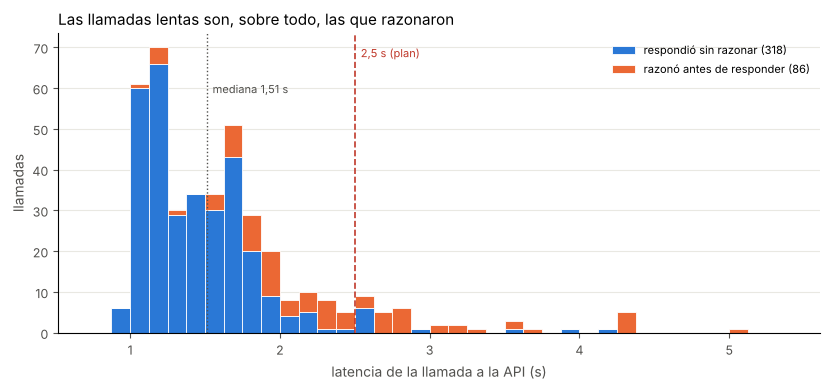

In [6]:
u = uso[uso.corrida == "prueba"].copy(); u["canal"] = np.where(u.uid.str.startswith("A"), "audio", "texto")
u["pensó"] = u.output_tokens > 110        # la respuesta JSON sola ocupa ~95–110 tokens; más es razonamiento adaptativo
def lat(x):
    return pd.Series({"llamadas": len(x), "mediana s": x.latencia_s.median(), "media s": x.latencia_s.mean(),
                      "P95 s": x.latencia_s.quantile(.95), "máximo s": x.latencia_s.max(), "% > 2,5 s": 100 * (x.latencia_s > 2.5).mean(),
                      "tokens de salida (mediana)": x.output_tokens.median()})
tl = pd.concat({"todas": lat(u), "texto": lat(u[u.canal == "texto"]), "audio": lat(u[u.canal == "audio"]),
                "sin razonar (≤ 110 tokens)": lat(u[~u["pensó"]]), "razonó (> 110 tokens)": lat(u[u["pensó"]])}, axis=1).T.round(2)
display(tl)
print(f"Razonó en {int(u['pensó'].sum())} de {len(u)} llamadas ({100 * u['pensó'].mean():.1f} %): texto "
      f"{100 * u[u.canal == 'texto']['pensó'].mean():.1f} %, audio {100 * u[u.canal == 'audio']['pensó'].mean():.1f} %. "
      f"De las {int((u.latencia_s > 2.5).sum())} llamadas de más de 2,5 s, {int(u[u.latencia_s > 2.5]['pensó'].sum())} razonaron.")
print(f"Correlación tokens de salida – latencia: {np.corrcoef(u.output_tokens, u.latencia_s)[0, 1]:.2f}")
au = RP[(RP.canal == "audio") & (~RP.desde_cache)]
tot = au.whisper_s + au.latencia_s
print(f"Nota de voz completa (Whisper en la GPU + API), {len(au)} llamadas nuevas: mediana {tot.median():.2f} s · P95 {tot.quantile(.95):.2f} s")
dev = uso[uso.corrida == "desarrollo_v1_low"]
print(f"Desarrollo (184 llamadas): mediana {dev.latencia_s.median():.2f} s · P95 {dev.latencia_s.quantile(.95):.2f} s")
print(f"Caché del prompt: {int((u.cache_read_input_tokens > 0).sum())} de {len(u)} llamadas de la prueba leyeron el prompt de la caché")
cost = uso.groupby("corrida").agg(llamadas=("costo_usd", "size"), costo_usd=("costo_usd", "sum"))
cost.loc["TOTAL"] = cost.sum(); display(cost.round(4))
print(f"Costo por mensaje en la prueba: ${u.costo_usd.mean():.5f} · por 1.000 mensajes: ${1000 * u.costo_usd.mean():.2f}")
check("Criterio de latencia (plan; decisión de la Persona 3, 11:52): < 2,5 s por mensaje en la mediana (y en la media)",
      u.latencia_s.median() < 2.5 and u.latencia_s.mean() < 2.5, f"mediana {u.latencia_s.median():.2f} s · media {u.latencia_s.mean():.2f} s")
print(f"Hallazgo H30 (no es criterio: decisión de la Persona 3, 11:52): P95 {u.latencia_s.quantile(.95):.2f} s "
      f"(texto {u[u.canal == 'texto'].latencia_s.quantile(.95):.2f} · audio {u[u.canal == 'audio'].latencia_s.quantile(.95):.2f}); "
      f"{100 * (u.latencia_s <= 2.5).mean():.1f} % de las llamadas respondió en 2,5 s o menos")
check("Costo real registrado y por debajo del límite de $20", cost.loc["TOTAL", "costo_usd"] < 20, f"${cost.loc['TOTAL', 'costo_usd']:.4f}")

fig, ax = plt.subplots(figsize=(8.4, 4.0))
bins = np.arange(0.75, 5.5, 0.125)
ax.hist([u[~u["pensó"]].latencia_s, u[u["pensó"]].latencia_s], bins=bins, stacked=True, color=[COL["texto"], COL["pensó"]],
        label=[f"respondió sin razonar ({int((~u['pensó']).sum())})", f"razonó antes de responder ({int(u['pensó'].sum())})"],
        edgecolor="white", linewidth=0.6)
ax.axvline(2.5, color=COL["meta"], lw=1.2, ls="--"); ax.text(2.54, ax.get_ylim()[1] * 0.92, "2,5 s (plan)", color=COL["meta"], fontsize=8)
ax.axvline(u.latencia_s.median(), color=COL["texto2"], lw=1, ls=":")
ax.text(u.latencia_s.median() + 0.04, ax.get_ylim()[1] * 0.80, "mediana " + f"{u.latencia_s.median():.2f}".replace(".", ",") + " s", color=COL["texto2"], fontsize=8)
ax.set_xlabel("latencia de la llamada a la API (s)", color=COL["texto2"]); ax.set_ylabel("llamadas", color=COL["texto2"])
ax.set_title("Las llamadas lentas son, sobre todo, las que razonaron", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color=COL["grid"]); ax.set_axisbelow(True)
ax.tick_params(colors=COL["texto2"], labelsize=9); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "latencia_api_10_5.png", dpi=150); plt.show()

### 6 · El prompt no trae material de la prueba

In [7]:
p1 = cargar_prompt("v1")
print(f"Prompt v1: {len(p1):,} caracteres (~{len(p1) // 4:,} tokens; caché mínima de Haiku: 512)")
txt_prueba = set(RP.texto)
ejemplos_en_prueba = [t for t in txt_prueba if t and t in p1]
print(f"Textos de la prueba que aparecen en el prompt: {len(ejemplos_en_prueba)}")
check("El prompt congelado no contiene ningún mensaje de la prueba ni los errores de Whisper vistos en ella",
      not ejemplos_en_prueba and not re.search(r"\bbarba\b|\brancón\b|\brancon\b", p1.lower()))   # palabra completa: «trancón» sí va

Prompt v1: 6,342 caracteres (~1,585 tokens; caché mínima de Haiku: 512)
Textos de la prueba que aparecen en el prompt: 0


### 7 · Pruebas

In [8]:
p = subprocess.run([sys.executable, "tests_10_5.py"], capture_output=True, text=True, encoding="utf-8")
print(p.stdout.strip())
check("tests_10_5.py: 5/5 PASS", p.returncode == 0 and "5/5 PASS" in p.stdout, p.stdout.strip().splitlines()[-1])
chk = pd.DataFrame(CHECKS); chk.to_csv("datos_10/checks_10_5.csv", index=False)
display(chk); print(f"{(chk.resultado == 'PASS').sum()}/{len(chk)} PASS")

PASS  a · esquema estricto: sin minimum/maximum, additionalProperties = false, todos los campos requeridos; las 580 respuestas correctas lo cumplen (Pydantic + reglas)
PASS  b · métricas: extracción perfecta → F1 1,0; un error de gravedad solo baja ese campo; vías equivalentes («la 8A» = «Carrera 8A», en cualquier orden) cuentan como acierto
PASS  c · extractor: caché del prompt + Structured Outputs + esfuerzo en el pedido; caché en disco (no paga dos veces); tope de llamadas; uso_api.csv con tokens, costo y latencia
PASS  d · el prompt no trae nada de la PRUEBA: sus ejemplos salen del desarrollo y no menciona los errores de Whisper vistos en la prueba
PASS  e · evaluación única: si la configuración está congelada, su hash coincide; la prueba no se corre sin congelar

5/5 PASS


,check,resultado,detalle
0,"Configuración congelada: los hashes de la configuración, el prompt y el esquema coinciden, y apunta a las ...",PASS,
1,La configuración se congeló antes de la primera llamada de la prueba,PASS,2026-10-28T11:18:45
2,Desarrollo: el esfuerzo low ya cumple la meta en texto y audio (decisión a ajustada: no se corren medium n...,PASS,texto 0.9987 · audio 1.0000
3,"Meta aprobada (decisión d): F1 ≥ 0,90 en el texto escrito (363) Y en el audio transcrito (126)",PASS,texto 0.9983 · audio 0.9955
4,"El límite inferior del IC95 % del F1 también supera 0,90 (texto y audio)",PASS,texto 0.9966 · audio 0.9847
5,100 % de las 489 respuestas cumplen el esquema (Structured Outputs + Pydantic + reglas de coherencia),PASS,0 con errores
6,Las métricas de la prueba se recalculan idénticas desde las respuestas guardadas,PASS,
7,"Prueba completa: 363 textos + 126 transcripciones (42 audios × 3 versiones), sin mensajes de desarrollo",PASS,
8,Cada mensaje con error tiene una causa identificada,PASS,
9,100 % de los 489 eventos construidos con la extracción de Claude cumplen el contrato 1.2,PASS,


15/15 PASS


## Conclusiones

**Conclusión 1 · Claude cumple la meta del F1 en el texto escrito y en el audio**
- **Prueba (evaluación única, configuración congelada `d550de70…`):**

  | | Mensajes | F1 (meta ≥ 0,90) | IC95 % bootstrap | Mensajes perfectos |
  |---|---|---|---|---|
  | Texto escrito | 363 | **0,9983** | [0,9966; 0,9996] | 358/363 (Wilson [96,8 %; 99,4 %]) |
  | Audio transcrito | 126 | **0,9955** | [0,9847; 1,0000] | 122/126 (Wilson [92,1 %; 98,8 %]) |

  - Aun el extremo inferior de los dos intervalos queda lejos de 0,90.
  - En el audio, el intervalo se calculó remuestreando cada audio con sus 3 versiones juntas, porque no son independientes.
- **Por fuente:** plantilla 0,9996 y frases libres 0,9943; audio limpio 0,9960, con ruido a 10 dB 0,9944 y a 5 dB 0,9960. El ruido casi no cambia el resultado.
- **El desarrollo anticipó bien la prueba:** 0,9987 en texto y 1,0000 en audio. No hay señal de que el prompt se haya ajustado de más.
- **Structured Outputs:** las 489 respuestas cumplen el esquema, sin un solo error de formato.
- **No inventa datos:** en ninguno de los 700 mensajes (desarrollo y prueba) Claude puso una duración, un sentido o una gravedad que el conductor no dijo. Eso incluye las 8 omisiones controladas de los audios (A25, A49, A54 y A58 sin duración; A04, A08, A16 y A40 sin sentido).

**Conclusión 2 · Los pocos errores tienen causas concretas**
- **9 de 489 mensajes** tienen un campo mal: 9 campos de 3.423. Alcance, duración, sentido y despejado salieron bien en el 100 %.
- **Las causas:**

  | Causa | Mensajes | Qué pasó |
  |---|---|---|
  | La palabra «evento» | 4 (L099 y A02 en sus 3 versiones) | «Evento adelante en…» o «Despejado. Evento. Lugar.»: Claude lee «evento» como la etiqueta de la guía y no como el tipo «evento» (concierto, partido). En desarrollo pasó lo mismo con L096. |
  | Vía mal escrita | 2 (P242 «Muillo», P398 «clale 64») | Claude copia la vía tal como la escribió el conductor, como pide el prompt. |
  | Lenguaje suelto | 2 frases libres | «Está pare y siga», sin decir el tipo, quedó como «otro» y no como trancón (L010). «Cerraron … por el concierto» quedó sin gravedad, en vez de 5 (L094). |
  | Error de Whisper | 1 (A25 a 10 dB) | Whisper oyó «57» en vez de «87» (10.4). Claude extrajo bien lo que recibió. |

- **La causa que más pesa es de la guía, no del modelo:** el tipo «evento» se llama igual que la etiqueta «Evento:». Darle otro nombre en la guía (por ejemplo, «evento público») lo resolvería. La decisión es de la Persona 3 y se deja para la 10.6.

**Conclusión 3 · De punta a punta, el segmento queda casi en el techo; lo que falta son vías mal escritas**
- **Del mensaje al segmento.** Cada extracción se pasó por `construir_evento` con la ventana real de GPS del set:

  | | Segmento exacto con Claude | Techo (extracción perfecta) | A ±1 segmento con Claude | Mismo segmento que el techo |
  |---|---|---|---|---|
  | Texto (363) | **95,04 %** | 96,14 % | 95,87 % | 98,90 % |
  | Audio (126) | **99,21 %** | 100 % | 99,21 % | 99,21 % |

- **Los 489 eventos cumplen el contrato 1.2.**
- **De dónde salen las 5 diferencias con el techo:**
  - en todas, la vía llegó mal escrita: 4 por errores de tipeo del mensaje («Aveinda», «Aevnida», «Muillo», «clale») y 1 por el «57» de Whisper;
  - el resolvedor no encuentra la esquina y el evento cae a la posición GPS del bus con confianza «baja», 3 o 4 segmentos atrás (1,5–2 km);
  - en 2 de esos casos (P186 y P374) el F1 cuenta el lugar como acierto, porque la otra vía basta para reconocerlo, pero la esquina no se ubica en el mapa. Por eso se mide también el segmento.
- **Los errores de tipeo en el resto del mensaje no afectan:** de los 27 mensajes de plantilla con error de tipeo, 23 dan el mismo segmento que el techo, porque Claude entiende bien «Evenot», «lguar» o «druación». Los 4 que fallan son los de la vía.
- **Siguiente paso natural (10.6):** que el resolvedor tolere un error de tipeo en el nombre de la vía, comparándolo con el catálogo de esquinas de la ruta. Se mediría con desarrollo; la prueba ya se usó.

**Conclusión 4 · Latencia: cumple en la mediana; el P95 queda como hallazgo**
- **Latencia de las 404 llamadas nuevas a la API de la prueba**, medida en el PC de la Persona 3 con la red incluida:

  | | Mediana | Media | P95 | Más de 2,5 s |
  |---|---|---|---|---|
  | Todas | **1,51 s** | 1,64 s | **2,81 s** | 9,4 % |
  | Texto | 1,45 s | 1,57 s | 2,56 s | 6,5 % |
  | Audio (solo la API) | 1,66 s | 1,98 s | 3,63 s | 24,6 % |

- **Criterio del plan** («< 2,5 s por mensaje procesado», medido con la mediana por decisión de la Persona 3): **se cumple**, con 1,51 s de mediana y 1,64 s de media. El 90,6 % de las llamadas respondió en 2,5 s o menos.
- **Hallazgo (H30): la cola.** El P95 es 2,81 s: 1 de cada 10 llamadas pasa de 2,5 s. El alcance había propuesto el P95 como criterio; la cifra se reporta completa.
- **Por qué hay cola:** Haiku 5.5 razona de forma adaptativa, y con esfuerzo «low» todavía razonó en 86 de las 404 llamadas (21,3 %). Esas llamadas tardan más: 28 de las 38 de más de 2,5 s razonaron. Sin razonar, el P95 es 2,14 s. En el audio razonó más (35,4 % frente a 18,6 % en el texto), porque la puntuación de Whisper («Despejado. Evento. Lugar.») vuelve el mensaje más ambiguo.
- **Variación entre corridas:** en desarrollo, con el mismo modelo y el mismo prompt, el P95 fue 2,38 s. La red y el plan personal de la API (CLAUDE.md §13) también influyen.
- **Nota de voz completa** (Whisper en la GPU + API): mediana 2,41 s y P95 4,31 s.
- **Costo:** $0,069 en total (desarrollo $0,021 + prueba $0,048), es decir $0,12 por cada 1.000 mensajes. El 100 % de las llamadas de la prueba leyó el prompt de la caché. El límite de gasto es $20.

**Conclusión 5 · El modelo elegido, el alcance de la validación y qué sigue en la 10.6**
- **Modelo (H7).** El plan menciona `claude-3-5-sonnet`. Anthropic retiró ese modelo el 28-oct-2025 y su reemplazo indicado es `claude-sonnet-5-5`. Se usó `claude-haiku-5-5` por la regla del presupuesto (§13: Sonnet solo si Haiku no llega a 0,90), y Haiku llegó a 0,998 en texto y 0,996 en audio. Cuesta 20 veces menos que Sonnet ($0,10 / $0,50 por millón de tokens frente a $2 / $10) y es el más rápido de los modelos vigentes. Con Structured Outputs y un esquema Pydantic estricto se cumple lo que pide el plan.
- **Esfuerzo:** se probó solo «low». Con ese esfuerzo el F1 de desarrollo ya estaba a 0,0013 del máximo, así que la Persona 3 decidió no correr «medium» ni «high» (ajuste de la decisión a, registrado en el alcance).
- **Alcance de la validación** (en `LIMITACIONES_modulo10.md`):
  - los mensajes escritos son sintéticos: los escribió Claude y los interpreta Claude (H16). Las frases libres, que se alejan de la guía, dan un F1 algo menor (0,9943) y se reportan aparte;
  - el audio es de una sola voz, grabada en una sala;
  - los errores de tipeo del set los puso el generador, no un conductor real.
- **Siguiente paso natural:** un piloto con mensajes y notas de voz reales de conductores.
- **Para la 10.6:**
  1. un resolvedor de esquinas que tolere un error de tipeo en la vía;
  2. proponer a la Persona 3 otro nombre para el tipo «evento»;
  3. manejar la latencia: verificar en la documentación si el razonamiento adaptativo se puede limitar más allá de «low», y medir el P95 del servicio con los mensajes de desarrollo;
  4. el servicio `src/nlp/traffic_nlp_service.py`, la tabla `tb_eventos_imprevistos_activos` y el banco de eventos para los Módulos 12 y 13, que se procesa una sola vez.

---
# Parte 8 · Módulo 10 · Subfase 10.6 · Servicio y entrega
*Notebook original: `modulo10/subfase_10_6_servicio.ipynb`*

# SOBUSA · Módulo 10 · Subfase 10.6 — Servicio, tabla de eventos y entrega

**Persona 3.** La 10.6 junta las piezas de la 10.1 a la 10.5 en el entregable del plan: el **microservicio FastAPI
`src/nlp/traffic_nlp_service.py`** y la **tabla dinámica `tb_eventos_imprevistos_activos`**. Alcance aprobado:
`revisiones/alcance_10_6.md` (decisiones a–k de la Persona 3).

| Pieza | Qué hace | Dónde |
|---|---|---|
| Webhook | Recibe el mensaje simulado de WhatsApp (contrato de entrada 1.0): texto o nota de voz | `POST /webhook` |
| Audio → texto | Whisper local (10.4); el audio no sale del PC | `src/m10/transcripcion.py` |
| Texto → evento | Claude Haiku 5.5 con Structured Outputs (10.5), **prompt v2** (guía 1.5: «evento masivo») | `src/m10/extractor.py` |
| Mapeo espacial | GPS de los 5 min previos del bus + esquina «adelante en X con Y» → segmento de 500 m, latitud y longitud, ahora **tolerante a errores de tipeo** en la calle (H28) | `src/m10/evento.py`, `src/geo/referencias.py` |
| Tabla | Crea, une o cierra eventos; el centro de control corrige o cierra | `src/m10/almacen_eventos.py` (SQLite) |
| Para los Módulos 12 y 13 | Banco de 580 eventos, calendario de eventos masivos y guía de uso | `datos_10/eventos/`, `datos_10/eventos_bd/`, `NOTA_PARA_MODULO_12.md` |

**Reglas de la tabla (Persona 3):** un evento sigue activo hasta su «Despejado» o hasta que el centro de control lo cierre,
sin vencimiento automático; los reportes repetidos (mismo tipo, misma ruta, ±1 segmento) se unen **sin límite de tiempo**
(hay eventos de días, como las obras) y el número de reportes no sube la gravedad; manda la gravedad del más reciente.

## Parte 2 · Análisis offline

In [1]:
import difflib
import hashlib
import json
import sqlite3
import subprocess
import sys
from pathlib import Path
from typing import Dict, List

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, "src"); sys.path.insert(0, ".")
from m10.esquema_extraccion import hash_esquema
from m10.extractor import cargar_prompt
from m10.evento import validar_evento
import extraer_10_5 as X
import extraer_10_6 as Y

pd.set_option("display.max_columns", None); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 110)
S = Path("datos_10/extraccion"); D = Path("datos_10/set_prueba"); E = Path("datos_10/eventos"); B = Path("datos_10/eventos_bd")
FIG = Path("resultados_10"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
def check(nombre: str, ok: bool, detalle: str = "") -> None:
    CHECKS.append({"check": nombre, "resultado": "PASS" if bool(ok) else "FAIL", "detalle": detalle})
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
leer = lambda p: pd.DataFrame([json.loads(l) for l in open(p, encoding="utf-8")])
cfg = json.loads((S / "config_10_6.json").read_text(encoding="utf-8"))
uso = pd.read_csv("datos_10/uso_api.csv")

## 1 · Guía 1.5 y prompt v2

El único cambio de la guía 1.5 frente a la 1.4 es el nombre del tipo «evento», que ahora se dice **«evento masivo»**
(H29, decidido por la Persona 3). Regla del alcance (decisión e): el servicio usa el prompt v2 solo si en desarrollo
da F1 ≥ 0,99 en texto **y** en audio; si no, se queda con el v1. Mismo modelo y esfuerzo de la 10.5.

In [2]:
v1, v2 = cargar_prompt("v1"), cargar_prompt("v2")
cambios = [l for l in difflib.unified_diff(v1.splitlines(), v2.splitlines(), lineterm="", n=0)
           if l[:1] in "+-" and not l.startswith(("+++", "---"))]
print(f"Líneas que cambian de v1 a v2: {len(cambios)}")
for l in cambios:
    print("  ", l[:160])
cfg_sin = {k: v for k, v in cfg.items() if k not in ("creado", "hash_config")}
hash_ok = hashlib.sha256(json.dumps({k: v for k, v in cfg.items() if k != "creado" and k != "hash_config"}, sort_keys=True,
                                    ensure_ascii=False).encode()).hexdigest()
print(f"\nConfiguración congelada {cfg['creado']}: {cfg['modelo']} · {cfg['esfuerzo']} · prompt {cfg['version_prompt']} · hash {cfg['hash_config'][:12]}…")
check("config_10_6: el hash del prompt v2 y del esquema coincide con lo congelado",
      hashlib.sha256(v2.encode()).hexdigest() == cfg["hash_prompt"] and hash_esquema() == cfg["hash_esquema"])
check("config_10_6: el hash de la configuración se recalcula igual", hash_ok == cfg["hash_config"], hash_ok[:12])
check("prompt v2: solo cambian el encabezado de la guía (1.4 → 1.5) y la línea del tipo «evento» (→ «evento masivo»)",
      len(cambios) == 4 and all(l[1:].startswith(("## Cómo reportan", "- **evento**")) for l in cambios)
      and "evento masivo" in cambios[-1], f"{len(cambios)} líneas")

Líneas que cambian de v1 a v2: 4
   -## Cómo reportan los conductores (guía 1.4)
   +## Cómo reportan los conductores (guía 1.5)
   -- **evento**: partido, concierto, Carnaval u otro evento con mucha gente. Ojo: en «Evento: choque» la palabra «Evento» es solo la etiqueta.
   +- **evento**: evento masivo: partido, concierto, Carnaval, procesión u otra actividad con mucha gente que llena la vía. Desde la guía 1.5 el conductor dice «ev

Configuración congelada 2026-10-28T16:27:56: claude-haiku-5-5 · low · prompt v2 · hash 44be675af211…


In [3]:
R1 = leer(S / "respuestas_desarrollo_v1_low.jsonl"); R2 = leer(S / "respuestas_desarrollo_v2_low.jsonl")
m1, m2 = X.medir(R1), X.medir(R2)
comp = pd.DataFrame({"n": m2["n"], "F1 v1": m1["F1"], "F1 v2": m2["F1"], "perfectos v1 %": m1["perfectos_%"],
                     "perfectos v2 %": m2["perfectos_%"], "latencia mediana v2 (s)": m2["lat_mediana_s"]})
display(comp)
dif = [u for u, a, b in zip(R1.sort_values("uid").uid, R1.sort_values("uid").extraccion, R2.sort_values("uid").extraccion) if a != b]
print("Extracciones distintas entre v1 y v2:", dif)
print("Errores de v2 en desarrollo:", [(u, c) for u, c in zip(R2.uid, R2.campos_errados) if c])
pasa = m2.loc["TEXTO (meta)", "F1"] >= 0.99 and m2.loc["AUDIO (meta)", "F1"] >= 0.99
check("regla e: v2 da F1 ≥ 0,99 en texto y audio en desarrollo (recalculado) y config lo registra",
      pasa and cfg["v2_pasa"] and abs(cfg["f1_desarrollo_v2"]["texto"] - m2.loc["TEXTO (meta)", "F1"]) < 1e-4,
      f"texto {m2.loc['TEXTO (meta)', 'F1']:.4f} · audio {m2.loc['AUDIO (meta)', 'F1']:.4f}")
check("métricas de desarrollo v2: el archivo es el que se congeló", sha(S / "metricas_desarrollo_v2_low.csv") == cfg["metricas_desarrollo_sha256"])

,n,F1 v1,F1 v2,perfectos v1 %,perfectos v2 %,latencia mediana v2 (s)
grupo,,,,,,
TEXTO (meta),157,0.9987,0.9987,98.7261,98.7261,1.3220
AUDIO (meta),54,1.0000,1.0000,100.0000,100.0000,1.6550
texto · plantilla,120,0.9995,0.9995,99.1667,99.1667,1.3690
texto · frases libres,37,0.9956,0.9956,97.2973,97.2973,1.2390
audio · limpio,18,1.0000,1.0000,100.0000,100.0000,1.6055
audio · ruido 10 dB,18,1.0000,1.0000,100.0000,100.0000,1.6880
audio · ruido 5 dB,18,1.0000,1.0000,100.0000,100.0000,1.6880


Extracciones distintas entre v1 y v2: ['A10@limpio', 'A27@limpio']
Errores de v2 en desarrollo: [('P389', ['lugar']), ('L096', ['tipo_evento'])]


**Conclusión 1 · El prompt v2 iguala al v1 y pasa a ser el del servicio**
- **Qué cambió:** 4 líneas del prompt, el encabezado de la guía (1.4 → 1.5) y la línea del tipo «evento», que ahora se describe como «evento masivo». Los ejemplos de desarrollo son los mismos.
- **Desarrollo (211 mensajes, regla e):**

  | | F1 v1 | F1 v2 | Perfectos v2 |
  |---|---|---|---|
  | Texto (157) | 0,9987 | **0,9987** | 98,73 % |
  | Audio (54) | 1,0000 | **1,0000** | 100 % |

- **Las dos respuestas que cambian** entre v1 y v2 (A10 y A27) no cambian el resultado: una marca de cumplimiento del protocolo y «la Circunvalar» → «Circunvalar».
- **Siguen los 2 errores de desarrollo:** P389 (la calle mal escrita, que resuelve la búsqueda tolerante de la sección 3) y L096, una frase escrita con la guía anterior donde «evento» es ambiguo. La guía 1.5 evita esa ambigüedad desde el mensaje, como muestra el mini-set.
- **Configuración congelada** el 28-oct a las 16:27 (`config_10_6.json`, hash `44be675a…`): `claude-haiku-5-5`, esfuerzo low, prompt v2.

## 2 · Mini-set de la guía 1.5 (evaluación única)

40 mensajes nuevos escritos por Claude con la guía 1.5 (15 de «evento masivo» anclados en una ocurrencia real de SOBUSA,
25 de otros tipos; 26 con etiquetas y 14 informales), con GPS real y congelados con hash **antes** de cualquier corrida.
Se evaluaron una sola vez con la configuración congelada. Meta: F1 ≥ 0,90.

In [4]:
man = json.loads((D / "manifiesto_miniset_10_6.json").read_text(encoding="utf-8"))
RM = leer(S / "respuestas_miniset_10_6.jsonl")
items = {m["uid"]: m["item"] for m in Y.mensajes_miniset()}
mm = Y.medir_miniset(RM, items)
display(mm)
print("Respuestas que salieron de la caché en disco:", RM[RM.desde_cache].uid.tolist(),
      RM[RM.desde_cache].texto.tolist())
check("mini-set: el archivo evaluado es el congelado (hash del manifiesto y de config_10_6)",
      sha(D / "miniset_10_6.jsonl") == man["archivo"]["miniset_10_6.jsonl"]["sha256"] == cfg["miniset_sha256"])
check("mini-set: F1 ≥ 0,90 (recalculado)", mm.loc["MINI-SET (meta)", "F1"] >= 0.90, f"{mm.loc['MINI-SET (meta)', 'F1']:.4f}")
check("mini-set: se evaluó una sola vez (39 llamadas nuevas en uso_api.csv + 1 desde la caché)",
      (uso.corrida == "miniset_10_6").sum() == 39 and len(RM) == 40)

,n,F1,perfectos_%,tipo_evento,alcance,severidad,duracion,sentido,es_despeje,lugar,lat_mediana_s,errores_esquema
grupo,,,,,,,,,,,,
MINI-SET (meta),40,1.0,100.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.3395,0
evento masivo,15,1.0,100.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.7360,0
otros tipos,25,1.0,100.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.2710,0
con etiquetas,26,1.0,100.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.2840,0
informal,14,1.0,100.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.6820,0


Respuestas que salieron de la caché en disco: ['M25'] ['Despejado: arroyo, lugar: aquí.']


**Conclusión 2 · Con la guía 1.5, «evento masivo» se reconoce siempre**
- **Mini-set (40 mensajes nuevos, evaluación única):** **F1 = 1,0000**, 40/40 perfectos (meta ≥ 0,90).
  - **«Evento masivo»:** 15/15, cada uno anclado en una ocurrencia real registrada por SOBUSA (Carnaval 5, Batalla de Flores 3, partidos de la Selección 3, Guacherna 2, conciertos 2), con el GPS de un bus que operaba en ese horario.
  - **Otros tipos:** 25/25.
  - **Por formato:** 26/26 con etiquetas y 14/14 informales.
  - **0 errores de esquema.**
- **Era el error que más pesaba en la 10.5** (4 de 9 mensajes con error, H29). Con el nombre nuevo desaparece.
- **Transparencia:** 1 de los 40 mensajes (M25, «Despejado: arroyo, lugar: aquí.») tiene el mismo texto que un mensaje de desarrollo, así que su respuesta salió de la caché. Sin él, el resultado es el mismo: 39/39.
- **Alcance de la medida:** son 40 mensajes escritos por Claude, igual que el set de la 10.3 (`LIMITACIONES_modulo10.md` §3).

## 3 · Mapeo espacial tolerante a errores de tipeo (H28)

En la 10.5, 5 de 489 mensajes cayeron lejos de su segmento porque la calle venía mal escrita («Aveinda», «Muillo»…).
La búsqueda tolerante compara el nombre con las calles de la ruta (Damerau-Levenshtein ≤ 1, o ≤ 2 si tiene 8 letras o más;
coincidencia única; no toca números). Va apagada por defecto y el servicio la enciende. Medida sobre la prueba de la 10.5
**como diagnóstico** (la regla se calibró con desarrollo, pero la prueba ya se había visto en la 10.5).

In [5]:
filas = []
for nombre in ("desarrollo_v1_low", "prueba"):
    a = pd.read_csv(S / f"punta_a_punta_{nombre}.csv"); b = pd.read_csv(S / f"punta_a_punta_{nombre}_tolerante.csv")
    m = a.drop(columns=["correccion"], errors="ignore").merge(
        b[["uid", "exacto_claude", "correccion"]].rename(columns={"exacto_claude": "exacto_claude_tol", "correccion": "correccion_tol"}), on="uid")
    for canal in ("texto", "audio"):
        g = m[m.canal == canal]
        filas.append({"conjunto": nombre, "canal": canal, "n": len(g), "exacto sin tolerancia %": 100 * g.exacto_claude.mean(),
                      "exacto tolerante %": 100 * g.exacto_claude_tol.mean(), "techo %": 100 * g.exacto_perfecta.mean(),
                      "mejoran": int((~g.exacto_claude & g.exacto_claude_tol).sum()), "empeoran": int((g.exacto_claude & ~g.exacto_claude_tol).sum()),
                      "calles corregidas": int(g.correccion_tol.notna().sum())})
TOL = pd.DataFrame(filas).round(2); display(TOL)
pr = pd.read_csv(S / "punta_a_punta_prueba_tolerante.csv")
display(pr[pr.correccion.notna()][["uid", "correccion"]])
t = TOL[(TOL.conjunto == "prueba") & (TOL.canal == "texto")].iloc[0]
check("H28: la búsqueda tolerante no empeora ningún mensaje y lleva el texto de la prueba al techo",
      TOL.empeoran.sum() == 0 and abs(t["exacto tolerante %"] - t["techo %"]) < 1e-9, f"{t['exacto tolerante %']:.2f} % = techo")

,conjunto,canal,n,exacto sin tolerancia %,exacto tolerante %,techo %,mejoran,empeoran,calles corregidas
0,desarrollo_v1_low,texto,157,92.36,92.99,92.99,1,0,1
1,desarrollo_v1_low,audio,54,100.00,100.00,100.00,0,0,0
2,prueba,texto,363,95.04,96.14,96.14,4,0,4
3,prueba,audio,126,99.21,99.21,100.00,0,0,0


,uid,correccion
132,P186,"{""via1"": ""Murillo"", ""via2"": ""avenida Circunvalar"", ""cambios"": [[""Aveinda"", ""avenida""]]}"
172,P242,"{""via1"": ""carrera 5"", ""via2"": ""murillo"", ""cambios"": [[""Muillo"", ""murillo""]]}"
263,P374,"{""via1"": ""avenida Murillo"", ""via2"": ""Carrera 13"", ""cambios"": [[""Aevnida"", ""avenida""]]}"
278,P398,"{""via1"": ""Carrera 54"", ""via2"": ""calle 64"", ""cambios"": [[""clale"", ""calle""]]}"


**Conclusión 3 · La búsqueda tolerante cierra la brecha con el techo en el texto**
- **Qué corrige:** errores de una o dos letras en el tipo de vía o en el nombre de la calle, siempre que haya una sola calle de la ruta que se le parezca. No toca números.
- **Resultado en la prueba de la 10.5:**
  - **Texto:** segmento exacto **95,04 % → 96,14 %**, igual al techo (lo que da una extracción perfecta). Corrige 4 mensajes: «Aveinda», «Muillo», «Aevnida» y «clale».
  - **Desarrollo:** 92,36 % → 92,99 %, también igual a su techo. Corrige P389.
  - **Ningún mensaje empeora.**
- **El único que queda fuera:** A25, donde Whisper oyó «57» en vez de «87». Es un número y no se adivina a propósito.
- **Cómo queda marcado:** el evento corregido lleva confianza «media» y la corrección queda registrada en `tb_reportes_m10`. En la corrida de latencia hubo 1 corrección (P389).
- **Es una medida diagnóstica:** la regla se calibró solo con desarrollo, pero la prueba ya se había visto en la 10.5. **H28 queda cerrado.**

## 4 · El servicio y la tabla: pruebas

`tests_10_6.py` prueba el servicio con un extractor y un transcriptor simulados (no llama a la API ni usa Whisper):
contrato de entrada, idempotencia, ciclo de vida con reloj simulado, centro de control, búsqueda tolerante, guía y
prompt v2, mini-set, banco, tiempo de la consulta, datos personales y calendario de partidos.

In [6]:
p = subprocess.run([sys.executable, "tests_10_6.py"], capture_output=True, text=True, encoding="utf-8")
lineas = [l for l in p.stdout.splitlines() if l.strip()]
for l in lineas:
    print(l[:170])
check("tests_10_6.py: todas las pruebas pasan", p.returncode == 0 and lineas[-1].startswith("11/11"), lineas[-1])

PASS  a · contrato de entrada: los 620 mensajes del set y del mini-set se aceptan; los mal formados dan 422
PASS  b · idempotencia: el mismo id_mensaje dos veces da un solo evento y una sola llamada a la API
PASS  c · ciclo de vida (reloj simulado): unión sin subir la gravedad por el conteo; manda el reporte más reciente; sin límite de tiempo (un reporte 10 días después se un
PASS  d · centro de control: corrige y cierra con usuario registrado; rechaza campos no corregibles, gravedad 7 y llamadas sin token si el servicio lo exige
PASS  e · H28: la búsqueda tolerante recupera P389 (desarrollo) y los 4 casos de la prueba de la 10.5; no cambia ningún mensaje que ya salía bien; no corrige números ni n
PASS  f · guía 1.5 y prompt v2: el único cambio frente a v1 es «evento masivo» (más el encabezado); mismos ejemplos de desarrollo; sin textos de la prueba ni del mini-set
PASS  g · mini-set: congelado con hash; 40 mensajes (15 de evento masivo anclados en una ocurrencia real de SOBUSA, con el

**Conclusión 4 · El servicio cumple las reglas de la tabla que pidió la Persona 3**
- **`tests_10_6.py`: 11/11** (no llama a la API ni usa Whisper):
  - acepta los 620 mensajes del set y del mini-set, y rechaza los mal formados con 422;
  - el mismo `id_mensaje` dos veces da un solo evento y una sola llamada a la API;
  - dos reportes del mismo sitio se unen sin subir la gravedad y manda el más reciente;
  - **sin límite de tiempo** para unir: una obra reportada otra vez 10 días después sigue siendo el mismo evento;
  - el «Despejado» cierra el evento y, sin él, el evento sigue activo;
  - el centro de control corrige o cierra con su usuario registrado, y se le exige token si el servicio lo pide;
  - el texto se guarda con teléfonos y placas tapados.
- **Rutas:** `POST /webhook`, `GET /eventos/activos`, `GET /eventos/{id}`, `PATCH /eventos/{id}` y `GET /salud`.
- **Las tres tablas en un SQLite local:** `tb_eventos_imprevistos_activos` (la del plan), `tb_reportes_m10` (cada mensaje y cada acción del centro de control) y `tb_eventos_cerrados_m10`.

## 5 · Latencia del servicio de punta a punta

En el PC de la Persona 3 se levantó el servicio **sin caché** (cada mensaje llamó de verdad a la API) y se le enviaron
157 textos y las 18 notas de voz limpias de **desarrollo** (nunca la prueba). Criterio del plan: latencia de la API
< 2,5 s por mensaje; por decisión de la Persona 3 (10.5, 11:52) se juzga con la **mediana** y el P95 se reporta.

In [7]:
L = pd.read_csv(E / "latencia_servicio_10_6.csv")
srv = uso[uso.corrida == "servicio_10_6"].copy()
srv["canal"] = np.where(srv.uid.str.startswith("A"), "audio", "texto")
prueba105 = uso[uso.corrida == "prueba"]
def resumen(x):
    return pd.Series({"n": len(x), "mediana": x.median(), "P95": x.quantile(.95), "máximo": x.max(), "≤ 2,5 s %": 100 * (x <= 2.5).mean()})
T = pd.DataFrame({"API · servicio 10.6 (todas)": resumen(srv.latencia_s),
                  "API · servicio, texto": resumen(srv[srv.canal == "texto"].latencia_s),
                  "API · servicio, audio": resumen(srv[srv.canal == "audio"].latencia_s),
                  "API · prueba 10.5 (referencia)": resumen(prueba105.latencia_s),
                  "Mensaje completo · texto": resumen(L[L.canal == "texto"].servidor_total_s),
                  "Mensaje completo · nota de voz": resumen(L[L.canal == "audio"].servidor_total_s),
                  "Whisper · nota de voz": resumen(L[L.canal == "audio"].transcripcion_s)}).T.round(3)
display(T)
srv["razona"] = srv.output_tokens > 110          # mismo criterio de la 10.5
print(f"Llamadas que razonaron (> 110 tokens de salida, criterio de la 10.5): {srv.razona.sum()} de {len(srv)} "
      f"({100 * srv.razona.mean():.1f} %); en la prueba de la 10.5: {100 * (prueba105.output_tokens > 110).mean():.1f} %")
print(f"P95 sin las que razonaron: {srv[~srv.razona].latencia_s.quantile(.95):.2f} s")
print("Las 3 más lentas:", L.sort_values("ida_y_vuelta_s").tail(3)[["id_mensaje", "ida_y_vuelta_s", "api_s"]].values.tolist())
A = pd.read_csv(E / "latencia_consulta_activos_10_6.csv")
print(f"GET /eventos/activos con {A.eventos_activos.iloc[0]} eventos: mediana {1000 * A.consulta_activos_s.median():.1f} ms · "
      f"P95 {1000 * A.consulta_activos_s.quantile(.95):.1f} ms")
print("Acciones del almacén:", L.accion.value_counts().to_dict())
check("latencia (criterio del plan, mediana): la API responde en < 2,5 s dentro del servicio",
      srv.latencia_s.median() < 2.5, f"mediana {srv.latencia_s.median():.2f} s · P95 {srv.latencia_s.quantile(.95):.2f} s")
check("latencia: los 175 mensajes se procesaron sin errores HTTP", len(L) == 175 and not L.accion.str.startswith("http").any())
check("GET /eventos/activos: P95 < 100 ms", A.consulta_activos_s.quantile(.95) < 0.100)
check("Whisper corrió en la GPU (mediana < 1,5 s por nota de voz)", L.transcripcion_s.median() < 1.5, f"{L.transcripcion_s.median():.2f} s")

,n,mediana,P95,máximo,"≤ 2,5 s %"
API · servicio 10.6 (todas),175.0,1.357,2.243,6.755,97.143
"API · servicio, texto",157.0,1.354,2.184,6.755,96.815
"API · servicio, audio",18.0,1.466,2.381,2.447,100.000
API · prueba 10.5 (referencia),404.0,1.510,2.811,5.070,90.594
Mensaje completo · texto,157.0,1.397,2.251,6.764,96.815
Mensaje completo · nota de voz,18.0,2.311,3.218,3.238,66.667
Whisper · nota de voz,18.0,0.832,0.962,1.044,100.000


Llamadas que razonaron (> 110 tokens de salida, criterio de la 10.5): 25 de 175 (14.3 %); en la prueba de la 10.5: 21.3 %
P95 sin las que razonaron: 1.97 s
Las 3 más lentas: [['P001#lat10_6', 5.832, 5.794], ['P273#lat10_6', 6.365, 6.264], ['L072#lat10_6', 6.776, 6.755]]
GET /eventos/activos con 155 eventos: mediana 9.5 ms · P95 12.5 ms
Acciones del almacén: {'nuevo': 157, 'despeje_sin_evento': 16, 'despeje': 2}


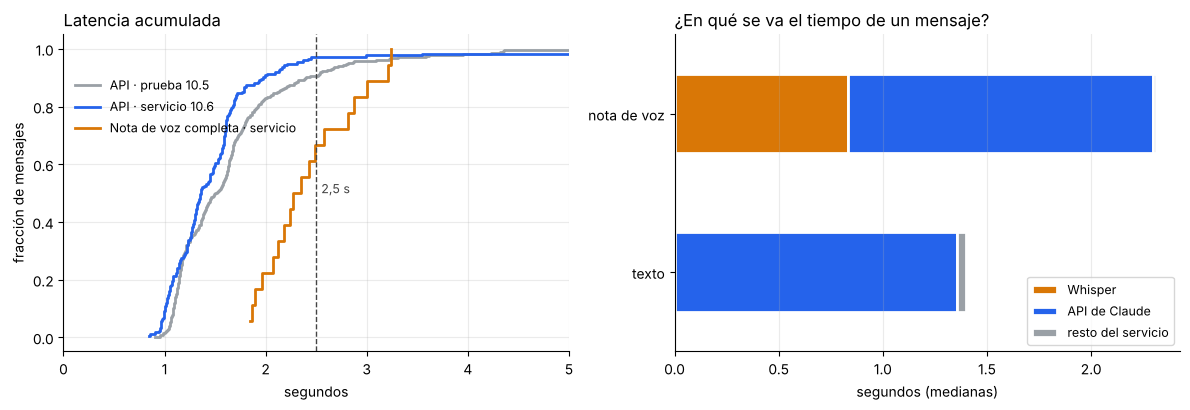

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for x, etq, col in [(prueba105.latencia_s, "API · prueba 10.5", "#9aa0a6"), (srv.latencia_s, "API · servicio 10.6", "#2563eb"),
                    (L[L.canal == "audio"].servidor_total_s, "Nota de voz completa · servicio", "#d97706")]:
    v = np.sort(x.values); ax[0].step(v, np.arange(1, len(v) + 1) / len(v), where="post", lw=2, label=etq, color=col)
ax[0].axvline(2.5, ls="--", color="#444", lw=1); ax[0].text(2.55, 0.5, "2,5 s", fontsize=9, color="#444")
ax[0].set_xlim(0, 5); ax[0].set_xlabel("segundos"); ax[0].set_ylabel("fracción de mensajes"); ax[0].legend(loc="upper left", fontsize=9, frameon=False, bbox_to_anchor=(0, 0.9))
ax[0].set_title("Latencia acumulada", loc="left"); ax[0].grid(alpha=.25)
comp = pd.DataFrame({"Whisper": [0, L[L.canal == "audio"].transcripcion_s.median()],
                     "API de Claude": [L[L.canal == "texto"].api_s.median(), L[L.canal == "audio"].api_s.median()]},
                    index=["texto", "nota de voz"])
comp["resto del servicio"] = [L[L.canal == "texto"].servidor_total_s.median(), L[L.canal == "audio"].servidor_total_s.median()] - comp.sum(axis=1)
comp.plot.barh(stacked=True, ax=ax[1], color=["#d97706", "#2563eb", "#9aa0a6"], width=.5, edgecolor="white", linewidth=2)
ax[1].set_xlabel("segundos (medianas)"); ax[1].set_title("¿En qué se va el tiempo de un mensaje?", loc="left"); ax[1].grid(axis="x", alpha=.25)
ax[1].legend(fontsize=9, loc="lower right")
for s in ("top", "right"):
    ax[0].spines[s].set_visible(False); ax[1].spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "latencia_servicio_10_6.png", dpi=130); plt.show()

**Conclusión 5 · El servicio responde rápido, también en la cola**
- **API de Claude dentro del servicio** (175 llamadas reales, sin caché, mensajes de desarrollo):

  | | Mediana | P95 | ≤ 2,5 s |
  |---|---|---|---|
  | Servicio 10.6 | **1,36 s** | **2,24 s** | **97,1 %** |
  | Prueba de la 10.5 | 1,51 s | 2,81 s | 90,6 % |

  - **Cumple el criterio del plan** (< 2,5 s, juzgado con la mediana), y esta vez el P95 también queda por debajo.
  - **Por qué baja la cola:** razonaron 25 de 175 llamadas (14,3 %), frente al 21,3 % de la prueba de la 10.5, con el mismo criterio de la 10.5 (más de 110 tokens de salida). Sin ellas, el P95 es 1,97 s.
  - **La comparación es orientativa:** son mensajes de desarrollo, no los de la prueba, que ya se usó. Los 3 casos más lentos (5,8–6,8 s) son llamadas sueltas, entre ellas la primera de la corrida.
  - **H30 queda cerrado como hallazgo explicado.**
- **Mensaje completo** (de que llega al webhook hasta que el evento queda guardado):
  - **Texto:** mediana 1,40 s y P95 2,25 s.
  - **Nota de voz:** mediana 2,31 s y P95 3,22 s; el 66,7 % en ≤ 2,5 s. Whisper toma 0,83 s de mediana: corrió en la GPU del PC, así que **H27 queda cerrado**.
- **La tabla del Módulo 12:** `GET /eventos/activos` con 155 eventos responde en 9,5 ms de mediana y 12,5 ms de P95.
- **Acciones de la corrida:** 157 eventos nuevos y 18 despejes, de los cuales 2 cerraron un evento y 16 quedaron como «despeje sin evento». Los mensajes del set son independientes, así que casi ningún despeje encuentra su evento. No hubo uniones.

## 6 · Lo que reciben los Módulos 12 y 13

- **Banco de eventos** (decisión f, sin llamar a la API): un evento 1.2 por cada mensaje distinto del set de la 10.3,
  armado con las extracciones de la 10.5 y la búsqueda tolerante. Son mensajes **sintéticos** con GPS real.
- **Calendario de eventos masivos** (decisiones j y k): lo registrado por SOBUSA más los partidos de Junior y de la Selección.
- **Guía de uso:** `NOTA_PARA_MODULO_12.md` (qué instalar según el uso: para leer los eventos no hace falta Whisper ni la API).

In [9]:
contrato = json.loads(Path("contrato_evento_10_2.json").read_text(encoding="utf-8"))
banco = pd.read_csv(E / "banco_eventos_m10.csv")
err = sum(len(validar_evento(json.loads(e), contrato)) > 0 for e in banco.evento_json)
print(f"Banco: {len(banco)} eventos ({(banco.canal == 'texto').sum()} de texto, {(banco.canal == 'audio').sum()} de voz) · "
      f"{int(banco.es_despeje.sum())} despejes · {int((banco.alcance == 'solo_bus').sum())} «mi bus» · fuera del contrato: {err}")
display(banco.groupby("tipo_evento").size().rename("eventos").to_frame().T)
display(pd.crosstab(banco.idruta, banco.confianza, margins=True))
check("banco: ≥ 500 eventos, todos en el contrato 1.2", len(banco) >= 500 and err == 0, f"{len(banco)} eventos")
db = sqlite3.connect(E / "latencia_10_6.sqlite")
ev_srv = [json.loads(r[0]) for r in db.execute("SELECT evento_json FROM tb_eventos_imprevistos_activos")]
db.close()
check("tabla del servicio (corrida de latencia): todos los eventos cumplen el contrato 1.2",
      all(len(validar_evento(e, contrato)) == 0 for e in ev_srv), f"{len(ev_srv)} eventos")

Banco: 580 eventos (520 de texto, 60 de voz) · 58 despejes · 41 «mi bus» · fuera del contrato: 0


tipo_evento,arroyo,bloqueo,choque,evento,obra,otro,semaforo,trancon,varado
eventos,67,55,85,47,70,51,48,88,69


confianza,alta,media,All
idruta,,,
2,188,6,194
16,178,15,193
21,182,11,193
All,548,32,580


In [10]:
amp = pd.read_csv(B / "calendario_eventos_masivos_ampliado_10_6.csv")
cal = pd.read_csv(B / "calendario_partidos_barranquilla_10_6.csv")
est = pd.read_csv(B / "estadios_10_6.csv")
print(f"Calendario ampliado: {len(amp)} eventos · de SOBUSA {int(amp.en_bd_sobusa.sum())} · partidos nuevos {int((~amp.en_bd_sobusa).sum())}")
display(pd.crosstab(cal.fecha.str[:4], [cal.equipo, cal.estadio]))
display(pd.crosstab(cal.precision_fecha, cal.precision_hora, margins=True))
display(est[["estadio", "capacidad"] + [c for c in est if c.startswith(("dist_min", "segmentos_800"))]])
sel = cal[(cal.equipo == "seleccion_colombia") & cal.en_periodo_datos_sobusa]
check("calendario: 28 eventos de SOBUSA + partidos; los 9 de la Selección 2023–2025 (8 con fecha de SOBUSA)",
      int(amp.en_bd_sobusa.sum()) == 28 and len(sel) == 9 and (sel.precision_fecha == "sobusa").sum() == 8)

Calendario ampliado: 184 eventos · de SOBUSA 28 · partidos nuevos 156


equipo         junior                  seleccion_colombia
estadio Metropolitano Romelio Martínez      Metropolitano
fecha                                                    
2020                0                0                  2
2021                0                0                  5
2022               34                0                  2
2023               25                0                  3
2024               31                0                  3
2025               32                0                  3
2026                1               23                  0

precision_hora,confirmada,sin_hora,All
precision_fecha,,,
agregador,0,6,6
api,99,0,99
espn_partido,0,7,7
prensa,33,11,44
sobusa,8,0,8
All,140,24,164


,estadio,capacidad,dist_min_ruta_2_m,segmentos_800m_ruta_2,dist_min_ruta_16_m,segmentos_800m_ruta_16,dist_min_ruta_21_m,segmentos_800m_ruta_21
0,Metropolitano,46788,248.9,7,247.6,7,249.2,7
1,Romelio Martínez,8600,717.4,3,771.9,1,102.0,10


**Conclusión 6 · Los Módulos 12 y 13 tienen eventos, calendario y una guía para usarlos**
- **Banco de eventos:** 580 eventos (520 de texto y 60 de voz), todos dentro del contrato 1.2, construidos sin llamar a la API.
  - Rutas 2 / 16 / 21: 194 / 193 / 193.
  - Incluye 58 despejes y 41 «mi bus»; 548 con confianza alta y 32 con media.
  - Son mensajes sintéticos con GPS real. **El simulador del Módulo 13 muestrea de aquí y nunca llama a la API.**
- **Calendario de eventos masivos:** 184 eventos, los 28 que registró SOBUSA más 156 partidos de Junior y de la Selección. Cada partido lleva su fuente y la precisión de su fecha y hora: 140 con hora y 24 solo con fecha.
- **Estadios:**
  - El **Metropolitano** queda a unos 249 m de las tres rutas.
  - El **Romelio Martínez**, sede de Junior desde el 18-ene-2026, queda a 102 m de la ruta 21 y a más de 700 m de las rutas 2 y 16.
- **`NOTA_PARA_MODULO_12.md`:** qué instalar según el uso. Para leer los eventos basta Python con pandas: no hacen falta Whisper, ni la API, ni GPU, ni la base de SOBUSA. Trae además los campos, el ciclo de vida, cómo consultar la tabla y los pendientes que son del Módulo 12.
- **Costo:** la etapa 5 costó USD 0,044, y el Módulo 10 completo, USD 0,113 (límite USD 20). La prueba de la 10.5 no se volvió a usar.
- **Siguiente paso natural:** conectar el GPS en vivo y el proveedor de mensajería real, que quedan documentados para después del proyecto, y hacer un piloto con mensajes de conductores reales.

## 7 · Costo y cumplimiento del presupuesto

In [11]:
costo = uso.groupby("corrida").agg(llamadas=("uid", "size"), costo_usd=("costo_usd", "sum")).round(4)
display(costo)
etapa5 = costo.loc[["desarrollo_v2_low", "miniset_10_6", "servicio_10_6"], "costo_usd"].sum()
print(f"Etapa 5 de la 10.6: USD {etapa5:.4f} · Módulo 10 completo: USD {uso.costo_usd.sum():.4f} (límite USD 20)")
check("presupuesto: el Módulo 10 completo cuesta < USD 1 y ninguna corrida pasó de 500 llamadas",
      uso.costo_usd.sum() < 1 and costo.llamadas.max() <= 500, f"USD {uso.costo_usd.sum():.4f}")
check("la prueba de la 10.5 no se volvió a usar (siguen 404 llamadas de «prueba»)", (uso.corrida == "prueba").sum() == 404)

,llamadas,costo_usd
corrida,,
desarrollo_v1_low,184,0.0208
desarrollo_v2_low,184,0.0208
miniset_10_6,39,0.0043
prueba,404,0.0480
servicio_10_6,175,0.0192


Etapa 5 de la 10.6: USD 0.0443 · Módulo 10 completo: USD 0.1131 (límite USD 20)


## Checks

In [12]:
CH = pd.DataFrame(CHECKS); display(CH)
CH.to_csv("datos_10/checks_10_6.csv", index=False)
print(f"{(CH.resultado == 'PASS').sum()}/{len(CH)} PASS")

,check,resultado,detalle
0,config_10_6: el hash del prompt v2 y del esquema coincide con lo congelado,PASS,
1,config_10_6: el hash de la configuración se recalcula igual,PASS,44be675af211
2,prompt v2: solo cambian el encabezado de la guía (1.4 → 1.5) y la línea del tipo «evento» (→ «evento masivo»),PASS,4 líneas
3,"regla e: v2 da F1 ≥ 0,99 en texto y audio en desarrollo (recalculado) y config lo registra",PASS,texto 0.9987 · audio 1.0000
4,métricas de desarrollo v2: el archivo es el que se congeló,PASS,
5,mini-set: el archivo evaluado es el congelado (hash del manifiesto y de config_10_6),PASS,
6,"mini-set: F1 ≥ 0,90 (recalculado)",PASS,1.0000
7,mini-set: se evaluó una sola vez (39 llamadas nuevas en uso_api.csv + 1 desde la caché),PASS,
8,H28: la búsqueda tolerante no empeora ningún mensaje y lleva el texto de la prueba al techo,PASS,96.14 % = techo
9,tests_10_6.py: todas las pruebas pasan,PASS,11/11 PASS


19/19 PASS


---
# Parte 9 · Módulo 11 · Tráfico externo con Google Routes API
*Notebook original: `modulo11/modulo_11_resultados.ipynb`*

# SOBUSA · Módulo 11 — Tráfico externo con Google Maps Routes API y muestreo insesgado

Notebook de presentación del Módulo 11 (Entregable 2). **No llama a la API de Google:** la recolección (4.998 llamadas, plan gratuito, USD 0) se hizo una sola vez el 1-nov-2026 y quedó guardada en `datos_11/`. Aquí se cargan esos resultados, se muestran sus tablas y figuras y se ejecutan las pruebas del módulo (que simulan la API con un transporte falso). El detalle está en `resultados_modulo11.md`.

In [1]:
%matplotlib inline
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
D = Path("datos_11")

import os, subprocess, sys
def correr(*args, timeout=1800, ultimas=None):
    """Ejecuta un script del módulo con el mismo Python del notebook y muestra su salida."""
    env = {**os.environ, "PYTHONUTF8": "1", "PYTHONIOENCODING": "utf-8"}
    r = subprocess.run([sys.executable, *args], capture_output=True, text=True, encoding="utf-8", errors="replace",
                       env=env, timeout=timeout)
    salida = (r.stdout + ("\n" + r.stderr if r.returncode else "")).rstrip().splitlines()
    print("\n".join(salida if ultimas is None else salida[-ultimas:]))
    print(f"\n[código de salida {r.returncode}]")
    return r.returncode

## 11.1 · Diseño muestral estratificado

In [2]:
me = json.load(open(D / "margen_error_11_1.json", encoding="utf-8"))
print(json.dumps(me, ensure_ascii=False, indent=1)[:2500])
marco = pd.read_csv(D / "marco_estratos_11_1.csv")
asig = pd.read_csv(D / "asignacion_11_1.csv")
print(f"Estratos en el marco: {len(marco):,} · filas de asignación: {len(asig):,}")
display(marco.head(10))

{
 "plan": {
  "sigma": 0.15,
  "n": 2500,
  "z": 1.96,
  "E": 0.00588
 },
 "nota": "I_gps es el índice de congestión del BUS (incluye paradas), no el de Google: su dispersión es mayor que la de duration/staticDuration y el margen GPS es una cota pesimista. El σ real de Google se mide en la 11.3 con los pings recolectados.",
 "sin_permutacion": {
  "ponderacion": "flujo_x_sd",
  "n": 2500,
  "E_simple_sigma_gps": 0.025925783412222417,
  "sigma_gps_global": 0.6613720258220004,
  "E_estratificado_gps": 0.026578776344567377,
  "E_estratificado_sigma_plan": 0.006028099611153052
 },
 "con_permutacion": {
  "ponderacion": "unidades_x_sd",
  "n": 2500,
  "E_simple_sigma_gps": 0.025925783412222417,
  "sigma_gps_global": 0.6613720258220004,
  "E_estratificado_gps": 0.02108629051019142,
  "E_estratificado_sigma_plan": 0.004782396976342598
 }
}
Estratos en el marco: 162 · filas de asignación: 324


,estrato_id,idruta,criticidad,franja,franja_critica,tipo_dia,n_tramos,n_intervalos,N_unidades,n_pasos_gps,flujo_pasajeros,media_indice,sd_indice,sd_imputada
0,R2-baja-madrugada-laboral,2,baja,madrugada,False,laboral,42,8,336,426,117867.297468,1.215670,0.479518,False
1,R2-baja-madrugada-sabado,2,baja,madrugada,False,sabado,42,8,336,105,15793.632911,1.178914,0.383315,False
2,R2-baja-madrugada-domingo_festivo,2,baja,madrugada,False,domingo_festivo,42,8,336,19,4679.594937,1.158075,0.232158,False
3,R2-baja-pico_am-laboral,2,baja,pico_am,True,laboral,42,8,336,1455,379924.613924,1.428805,0.518405,False
4,R2-baja-pico_am-sabado,2,baja,pico_am,True,sabado,42,8,336,352,55570.189873,1.242405,0.347981,False
5,R2-baja-pico_am-domingo_festivo,2,baja,pico_am,True,domingo_festivo,42,8,336,184,18133.430380,1.117811,0.346859,False
6,R2-baja-valle_am-laboral,2,baja,valle_am,False,laboral,42,16,672,2855,391331.126582,1.357402,0.488059,False
7,R2-baja-valle_am-sabado,2,baja,valle_am,False,sabado,42,16,672,393,36266.860759,1.428335,0.612902,False
8,R2-baja-valle_am-domingo_festivo,2,baja,valle_am,False,domingo_festivo,42,16,672,515,49135.746835,1.198893,0.421334,False
9,R2-baja-valle_pm-laboral,2,baja,valle_pm,False,laboral,42,20,840,3418,498084.386076,1.436615,0.597034,False


## 11.2 · Recolección (tabla `tb_tiempos_viaje_google`)

estado,ok,sin_ruta
escenario,,
con_permutacion,2242,45
sin_permutacion,2326,51


Pings con índice de congestión: 4,568 de 4,664 · rango 0.52 – 2.29
Latencia de la API (ms): {'count': 4664.0, 'mean': 1407.0, 'std': 1770.0, 'min': 146.0, '50%': 664.0, '95%': 5045.0, 'max': 20184.0}


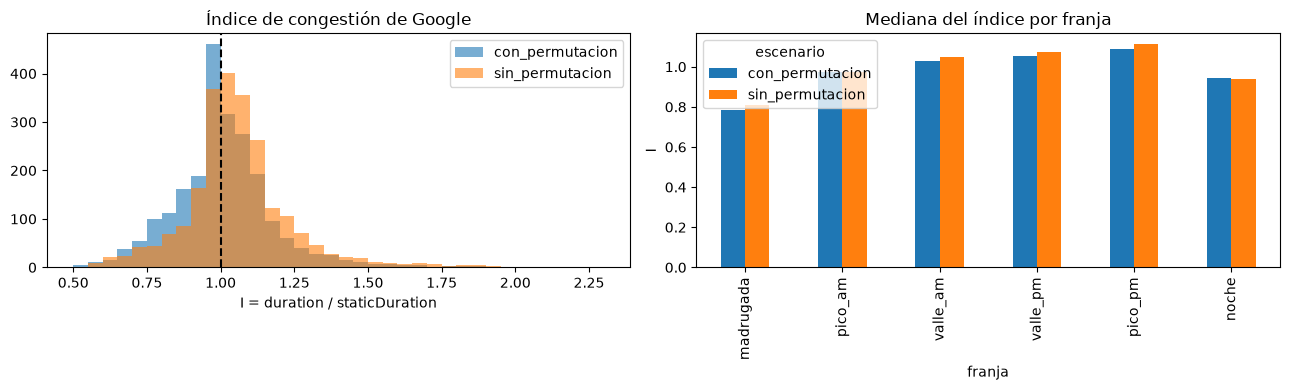

In [3]:
t = pd.read_parquet(D / "tb_tiempos_viaje_google.parquet")
display(t.groupby(["escenario", "estado"]).size().unstack(fill_value=0))
ok = t[t.congestion_index.notna()]
print(f"Pings con índice de congestión: {len(ok):,} de {len(t):,} · rango {ok.congestion_index.min():.2f} – {ok.congestion_index.max():.2f}")
print("Latencia de la API (ms):", t.latencia_ms.describe(percentiles=[.5, .95]).round(0).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for esc, g in ok.groupby("escenario"):
    ax[0].hist(g.congestion_index, bins=np.arange(0.5, 2.35, 0.05), alpha=0.6, label=esc)
ax[0].axvline(1, color="k", ls="--"); ax[0].set_xlabel("I = duration / staticDuration"); ax[0].legend(); ax[0].set_title("Índice de congestión de Google")
orden = ["madrugada", "pico_am", "valle_am", "valle_pm", "pico_pm", "noche"]
m = ok.groupby(["franja", "escenario"]).congestion_index.median().unstack().reindex(orden)
m.plot(kind="bar", ax=ax[1]); ax[1].set_title("Mediana del índice por franja"); ax[1].set_ylabel("I")
plt.tight_layout(); plt.show()

## 11.3 · Cobertura, validación contra el GPS y estimación del índice

,escenario,idruta,periodo,planeados,ok,sin_ruta,pendiente,cobertura_pct
0,con_permutacion,2,pico,260,253,2,5,97.307692
1,con_permutacion,2,valle,623,613,10,0,98.394864
2,con_permutacion,16,pico,244,242,2,0,99.180328
3,con_permutacion,16,valle,545,538,7,0,98.715596
4,con_permutacion,21,pico,258,167,9,82,64.728682
5,con_permutacion,21,valle,570,429,15,126,75.263158
6,con_permutacion,todas,todos,2500,2242,45,213,89.680000
7,sin_permutacion,2,pico,251,246,5,0,98.007968
8,sin_permutacion,2,valle,440,427,13,0,97.045455
9,sin_permutacion,16,pico,369,367,2,0,99.457995


,escenario,idruta,periodo,n,MAPE,MAPE_ponderado,MdAPE,razon_mediana_google_gps,MAPE_calibrado,MAPE_calibrado_ponderado,indice_google_medio
0,con_permutacion,2,pico,237,32.075,32.077,16.341,0.934,33.428,33.905,1.047
1,con_permutacion,2,valle,566,27.321,27.057,13.717,0.965,28.253,27.797,1.016
2,con_permutacion,16,pico,211,68.649,78.339,19.663,0.962,73.604,84.149,1.078
3,con_permutacion,16,valle,477,42.878,39.262,14.598,0.978,44.993,41.332,1.031
4,con_permutacion,21,pico,152,34.511,34.596,18.214,0.928,35.624,35.859,1.039
5,con_permutacion,21,valle,373,36.437,35.315,17.433,0.960,38.258,37.427,0.998
6,sin_permutacion,2,pico,235,29.559,28.034,15.022,0.940,31.023,30.016,1.074
7,sin_permutacion,2,valle,399,26.367,26.181,12.924,0.952,27.022,27.855,1.037
8,sin_permutacion,16,pico,339,47.197,53.754,19.089,0.924,49.561,56.809,1.108
9,sin_permutacion,16,valle,822,35.185,28.665,14.853,0.936,36.245,29.123,1.091


{
 "sin_permutacion": {
  "ponderacion": "flujo_pasajeros",
  "pings_ok": 2326,
  "validacion_vecinos": {
   "celdas_completas": 42,
   "media_entre_baja_y_alta_pct": 45.23809523809524,
   "error_imputacion_media": -0.018252518511476627,
   "error_imputacion_abs_mediano": 0.030513789709577965,
   "error_imputacion_abs_p90": 0.1212174944654085,
   "ecm_imputacion": 0.004323280895655636
  },
  "estratos_vacios": 12,
  "peso_vacio_pct": 4.045516210220895,
  "dominio_cubierto": {
   "media": 1.0621597773848548,
   "E95": 0.006140782331285124,
   "ic95": [
    1.0560189950535697,
    1.06830055971614
   ]
  },
  "red_completa_imputada": {
   "media": 1.0628215120302262,
   "E95": 0.006328713060130887,
   "ic95": [
    1.0564927989700954,
    1.069150225090357
   ],
   "aporte_de_los_imputados_a_la_varianza_pct": 13.314363427691216
  },
  "sensibilidad": {
   "vacios_menos_p90": 1.0579176386420044,
   "vacios_mas_p90": 1.0677253854184476
  },
  "si_se_completara_la_muestra": {
   "E95": 0.00

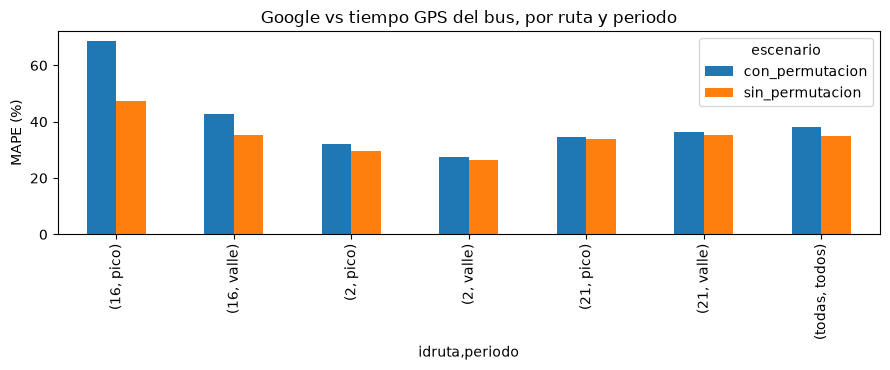

In [4]:
display(pd.read_csv(D / "cobertura_11_3.csv"))
met = pd.read_csv(D / "metricas_11_3.csv")
display(met.round(3))
est = json.load(open(D / "estimacion_indice_11_3.json", encoding="utf-8"))
print(json.dumps(est, ensure_ascii=False, indent=1)[:3000])
val = json.load(open(D / "validacion_11_3.json", encoding="utf-8"))
print(json.dumps({k: val[k] for k in ("pings_en_tabla", "pings_ok", "pings_con_referencia_gps", "global")}, ensure_ascii=False, indent=1)[:2500])
fig, ax = plt.subplots(figsize=(9, 3.8))
p = met.pivot_table(index=["idruta", "periodo"], columns="escenario", values="MAPE")
p.plot(kind="bar", ax=ax); ax.set_ylabel("MAPE (%)"); ax.set_title("Google vs tiempo GPS del bus, por ruta y periodo")
plt.tight_layout(); plt.show()

## 11.4 · Estudio de ablación y saturación del aporte de Google

,variante,descripcion,n,MAE,RMSE,WAPE,RMSE_vs_A_pct,MAE_vs_A_pct,pliegues_mejora_vs_anterior
0,0,Perfil histórico sin modelo,45800,31.550,65.929,28.006,NaN,NaN,NaN
1,A,Solo GPS SOBUSA (base),45800,30.515,61.653,27.088,NaN,NaN,NaN
2,B,GPS + Clima,45800,30.626,61.522,27.187,-0.212,0.365,2/6
3,C,GPS + Clima + Eventos M10,45800,30.640,61.459,27.198,-0.316,0.408,3/6
4,D,GPS + Clima + Eventos + Google (completo),45800,30.593,61.407,27.157,-0.399,0.257,5/6


,fraccion,semilla_submuestra,pings,pasos_con_google_tramo_franja,MAE_C,MAE_D,RMSE_C,RMSE_D,MAE_D_vs_C_pct,RMSE_D_vs_C_pct,pliegues_D_mejor
0,0.25,1,1142,32955,30.718,30.612,61.598,61.442,-0.345,-0.254,6/6
1,0.25,2,1142,32268,30.718,30.661,61.598,61.509,-0.184,-0.144,6/6
2,0.50,1,2284,53809,30.718,30.652,61.598,61.474,-0.214,-0.201,6/6
3,0.50,2,2284,54657,30.718,30.661,61.598,61.360,-0.184,-0.386,5/6
4,0.75,1,3426,68625,30.718,30.658,61.598,61.493,-0.194,-0.170,5/6
5,0.75,2,3426,69583,30.718,30.635,61.598,61.423,-0.269,-0.283,5/6
6,1.00,0,4568,80440,30.718,30.645,61.598,61.445,-0.235,-0.248,6/6


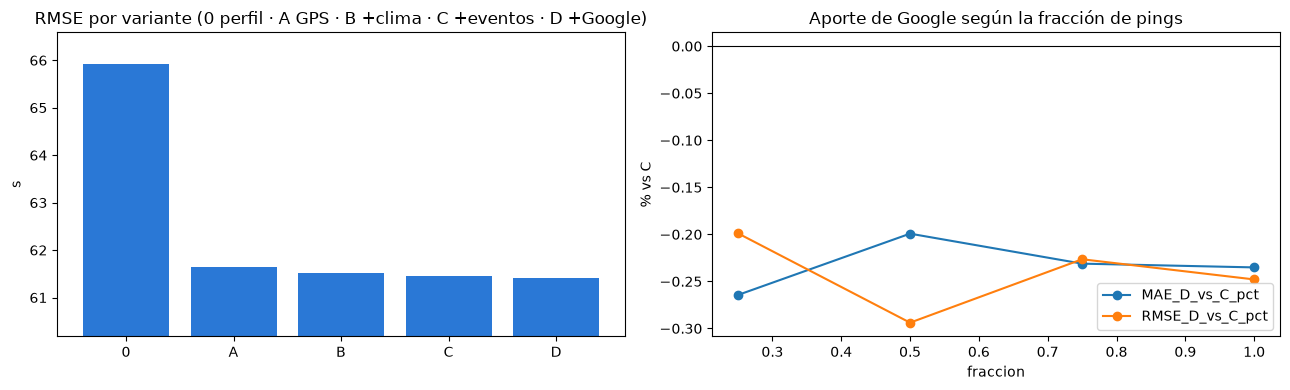

In [5]:
ab = pd.read_csv(D / "ablacion_11_4.csv")
tod = ab[ab.subconjunto == "todos"]
display(tod[["variante", "descripcion", "n", "MAE", "RMSE", "WAPE", "RMSE_vs_A_pct", "MAE_vs_A_pct", "pliegues_mejora_vs_anterior"]].round(3))
sat = pd.read_csv(D / "saturacion_google_11_4.csv")
display(sat.round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(tod.variante, tod.RMSE, color="#2a78d6"); ax[0].set_ylim(tod.RMSE.min() * 0.98, tod.RMSE.max() * 1.01)
ax[0].set_title("RMSE por variante (0 perfil · A GPS · B +clima · C +eventos · D +Google)"); ax[0].set_ylabel("s")
s = sat.groupby("fraccion")[["MAE_D_vs_C_pct", "RMSE_D_vs_C_pct"]].mean()
s.plot(marker="o", ax=ax[1]); ax[1].axhline(0, color="k", lw=0.8); ax[1].set_title("Aporte de Google según la fracción de pings"); ax[1].set_ylabel("% vs C")
plt.tight_layout(); plt.show()

## Pruebas del módulo (API simulada, sin red)

In [6]:
correr("tests_11_2.py", ultimas=25)

PASS prueba_a_calendario: 1096 días 2023–2025 idénticos al calendario de la Persona 2
PASS prueba_b_solicitud: 12 solicitudes con Field Mask exacto, salida futura del tipo de día correcto y 3 puntos via
PASS prueba_c_respuesta: I = 150 / 100 = 1,5; 6 respuestas sin rutas guardadas como 'sin_ruta'
PASS prueba_d_cache: 2.ª corrida: 0 llamadas, 0 pendientes
PASS prueba_e_reintentos: 12 pings guardados al 3.er intento (503 → 429 → 200); 36 llamadas registradas
PASS prueba_f_error_400: 400: 1 llamada por ping, nada guardado; la corrida siguiente los completa
PASS prueba_g_fatal: 403: corrida detenida tras 1 llamada(s)
PASS prueba_h2_tope_por_escenario: base con 2.498 previas → solo 2 más (4 saltados), permutación intacta; reintentos cuentan (3 + 3)
PASS prueba_h_cuota: uso previo 4.998 → 2 llamadas; tope 5 → 5; reintentos cuentan (tope 7 → 7)
PASS prueba_i_clave_no_se_filtra: un error que repite la clave queda como *** en la base y en el log
PASS prueba_j_integridad: muestra alterada rechaz

0

In [7]:
correr("tests_11_3.py", ultimas=25)

PASS prueba_a_mape: MAPE 30,000 % en 4497 pings con referencia y en las 14 celdas
PASS prueba_b_calibrado: MAPE calibrado fuera de pliegue = 0
PASS prueba_c_cobertura: 5.000 = 4.890 ok + 10 sin ruta + 100 pendientes; detalle por ruta × pico/valle cuadra
PASS prueba_d_ks_literal: Google ×0,7 rechaza y se reporta como diferencia de nivel
PASS prueba_e_representatividad: con_permutacion: D 0.0206, p diseño 0.18; sin_permutacion: D 0.0105, p diseño 0.98
PASS prueba_f_google_igual_gps: Google = GPS → MAPE 0
PASS prueba_g_tabla_vacia: tabla vacía → «corra primero la recolección (11.2)»

7/7 PASS

[código de salida 0]


0

In [8]:
correr("tests_11_4.py", ultimas=25)

  pliegue 1: D MAE 30.96 s (47854 entrenamiento / 10484 validación)
  pliegue 2: A MAE 31.37 s (58338 entrenamiento / 10353 validación)
  pliegue 2: B MAE 31.35 s (58338 entrenamiento / 10353 validación)
  pliegue 2: C MAE 31.41 s (58338 entrenamiento / 10353 validación)
  pliegue 2: D MAE 31.36 s (58338 entrenamiento / 10353 validación)
  pliegue 3: A MAE 34.84 s (68691 entrenamiento / 4493 validación)
  pliegue 3: B MAE 34.89 s (68691 entrenamiento / 4493 validación)
  pliegue 3: C MAE 34.87 s (68691 entrenamiento / 4493 validación)
  pliegue 3: D MAE 34.87 s (68691 entrenamiento / 4493 validación)
  pliegue 4: A MAE 33.71 s (73184 entrenamiento / 8991 validación)
  pliegue 4: B MAE 33.67 s (73184 entrenamiento / 8991 validación)
  pliegue 4: C MAE 33.68 s (73184 entrenamiento / 8991 validación)
  pliegue 4: D MAE 33.65 s (73184 entrenamiento / 8991 validación)
  pliegue 5: A MAE 33.37 s (82175 entrenamiento / 5032 validación)
  pliegue 5: B MAE 33.35 s (82175 entrenamiento / 5032 va

0

---
# Parte 10 · Módulo 12 · Reenrutamiento dinámico ante disrupciones
*Notebook original: `modulo12/modulo_12_reenrutamiento.ipynb`*

# SOBUSA · Módulo 12 — Reenrutamiento dinámico ante disrupciones

**Requisito R1** del *Plan técnico v2.0* (`../ENTREGABLE3Plan_Modulos_9_en_adelante_SOBUSA-v2.pdf`): recalcular en tiempo real la ruta alterna óptima de un bus cuando un tramo queda bloqueado por un evento que reportó el Módulo 10 (arroyo, choque, bloqueo, obra…).

| Elemento | Decisión |
|---|---|
| Insumos | Solo archivos ya guardados: calles de OpenStreetMap y 386 segmentos (Módulo 10), banco de 580 eventos (Módulo 10), pasos GPS por tramo e índice de Google (Módulo 11), lecturas GPS reales (Módulo 1.3). **Ninguna llamada a API** (prueba f) |
| 12.1 Tiempos | Mediana de los pasos de bus por segmento × franja × tipo de día (franjas del Módulo 11), con respaldo jerárquico; pasos > 50 km/h descartados |
| 12.2 Grafo | Calles de OSM aptas para bus recortadas a un corredor de 1 km (área de cobertura) + segmentos de ruta cada 25 m + conectores ruta ↔ calle |
| 12.3 Penalización | Severidad ≥ 4 → w = ∞; 3 / 2 / 1 → tiempo × 2,0 / 1,5 / 1,2; `solo_bus` y despejes no tocan el grafo; sin «ambos sentidos» solo se afecta el sentido del bus |
| 12.4 Búsqueda | A* (heurística = distancia en línea recta / velocidad máxima), verificada con Dijkstra; regreso a la ruta elegido por la búsqueda (hasta 3 segmentos después del bloqueo, 60 s por segmento extra sin servicio) |
| 12.5 Validación | (a) banco de eventos del Módulo 10: minutos evitados y latencia; (b) **desvíos reales** del GPS: ¿el modelo reproduce el camino y el tiempo que hizo el bus? |
| Entregables | `src/routing/dynamic_rerouter.py` (+ `grafo_vial.py`, `validacion_desvios.py`), GeoJSON comparativos en `datos_12/geojson/`, `tb_rutas_alternas_12.csv`, `tests_12.py` |

## Parte 1 · Insumos (sin extracción)
El Módulo 12 no consulta la RDS ni ninguna API: todo sale de los archivos de los Módulos 10, 11 y 1.3. Esta celda solo verifica que existan.

In [1]:
from src.routing import grafo_vial as gv
import pandas as pd
estado = pd.DataFrame([{"insumo": k, "archivo": v, "existe": (gv.SOBUSA_DIR / v).exists()} for k, v in gv.ENTRADAS.items()])
display(estado)
assert estado.existe.all(), "faltan insumos"

,insumo,archivo,existe
0,segmentos,modulo10/datos_10/extraccion/q4_segmentos.csv,True
1,osm,modulo10/datos_10/insumos/osm_vias_barranquill...,True
2,banco,modulo10/datos_10/eventos/banco_eventos_m10.csv,True
3,desvios_zonas,modulo10/datos_10/desvios_zonas_10_1.csv,True
4,pasos_gps,modulo11/datos_11/pasos_tramo_gps_11_1.parquet,True
5,google,modulo11/datos_11/tb_tiempos_viaje_google.parquet,True
6,calendario,entrega_persona2_modulos_3_5/entrega_persona2_...,True
7,lecturas,datos_1_3/lecturas.csv,True
8,maestra,maestras/tb_maestra_entrenamiento.parquet,True


## Parte 2 · Análisis offline

In [2]:
import json
import math
import time
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from scipy.stats import spearmanr, wilcoxon

from src.routing import dynamic_rerouter as dr
from src.routing import validacion_desvios as vd
import tests_12 as T

pd.set_option("display.max_columns", None); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
T0 = time.time()
SALIDA = gv.DATOS_12; SALIDA.mkdir(exist_ok=True); (SALIDA / "geojson").mkdir(exist_ok=True)
FIG = Path("resultados_12"); FIG.mkdir(exist_ok=True)
CHECKS = []
COLOR = {2: "#2a78d6", 16: "#e8892b", 21: "#7b4fbf"}


def check(nombre, ok, detalle="", info=False):
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


def figura(nombre):
    plt.tight_layout(); plt.savefig(FIG / nombre, dpi=110); plt.close(); display(Image(str(FIG / nombre)))


def guardar_geojson(nombre, gj):
    (SALIDA / "geojson" / f"{nombre}.geojson").write_text(json.dumps(gj, ensure_ascii=False, default=str), encoding="utf-8")


R = dr.ReenrutadorDinamico.desde_insumos()
G = R.G
banco = dr.cargar_banco()
print(f"Construcción del grafo y los pesos: {time.time() - T0:.1f} s · SOBUSA_DIR = {gv.SOBUSA_DIR}")

Construcción del grafo y los pesos: 10.2 s · SOBUSA_DIR = C:\Users\samit\OneDrive\Escritorio\UNIVERSIDAD\2026\2026-3\MACHINE LEARNING\04_Data_Challenge_SOBUSA\Sobusa


## 1 · Subfase 12.1 — Tiempo de viaje por tramo

Pasos GPS del Módulo 11: 158,835; descartados por > 50 km/h: 19,850 (12.5 %)


De esos pasos, 36.7% están en los 6 primeros o 6 últimos segmentos (terminal); mediana 5.0 s por paso frente a 95 s de los válidos


,pct_celdas
fuente,
seg_franja_dia,72.2
seg_franja,16.3
seg,9.7
ruta_franja,1.8


,estimador,pasos_prueba,viajes_prueba,MAE_s,MdAE_s,MdAPE_%,WAPE_%
0,tabla franja × día (12.1),27342,283,32.49,16.97,18.19,28.11
1,línea base: mediana del segmento,27342,283,35.28,18.32,19.77,30.53


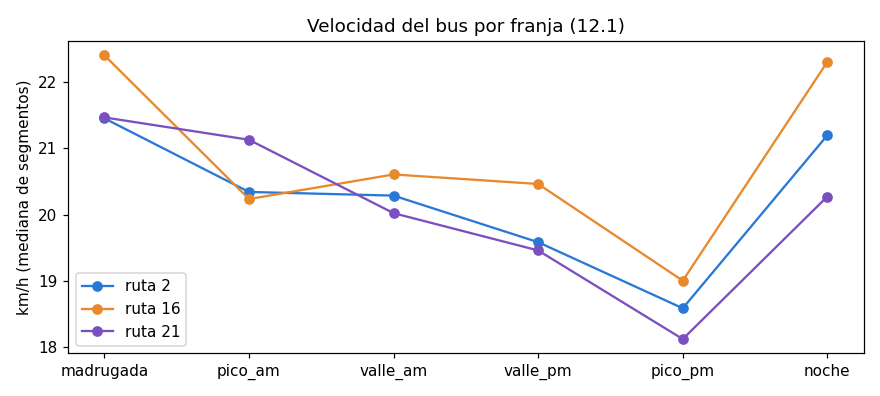

In [3]:
d = R.pasos_descartados
print(f"Pasos GPS del Módulo 11: {d['pasos_totales']:,}; descartados por > {d['v_max_kmh']:g} km/h: {d['descartados']:,} ({d['pct']:.1f} %)")
p_all = pd.read_parquet(gv.ruta_entrada("pasos_gps")).merge(gv.cargar_segmentos()[["idruta", "nro_segmento", "longitud_m"]])
p_all["v"] = p_all.longitud_m / p_all.duracion_s * 3.6
rap = p_all[p_all.v > 50]
por_seg = rap.groupby(["idruta", "nro_segmento"]).size().sort_values(ascending=False)
terminal = rap.nro_segmento.isin(list(range(1, 7))) | (rap.nro_segmento >= rap.idruta.map(p_all.groupby("idruta").nro_segmento.max()) - 5)
print(f"De esos pasos, {terminal.mean():.1%} están en los 6 primeros o 6 últimos segmentos (terminal); mediana {rap.duracion_s.median():.1f} s por paso "
      f"frente a {p_all[p_all.v <= 50].duracion_s.median():.0f} s de los válidos")
fuentes = R.tiempos.fuente.value_counts(normalize=True).rename("pct_celdas").mul(100)
display(fuentes.round(1).to_frame())
val = gv.validar_tiempos(gv.cargar_pasos(segmentos=gv.cargar_segmentos()), gv.cargar_segmentos())
val.to_csv(SALIDA / "validacion_tiempos_12_1.csv", index=False)
display(val.round(2))
R.tiempos.to_csv(SALIDA / "tiempos_segmento_12_1.csv", index=False)
v = R.tiempos.groupby(["idruta", "franja"]).v_kmh.median().unstack(0).reindex(gv.NOMBRES_FRANJA)
fig, ax = plt.subplots(figsize=(8, 3.6))
for r in v.columns:
    ax.plot(v.index, v[r], marker="o", color=COLOR[r], label=f"ruta {r}")
ax.set_ylabel("km/h (mediana de segmentos)"); ax.set_title("Velocidad del bus por franja (12.1)"); ax.legend()
figura("m12_velocidad_franja.png")
mej = val.set_index("estimador")["MdAPE_%"]
check("12.1 · la tabla por franja × día mejora a la línea base (MdAPE)", mej.iloc[0] < mej.iloc[1],
      f"{mej.iloc[0]:.1f} % vs {mej.iloc[1]:.1f} % en {int(val.pasos_prueba.iloc[0]):,} pasos de viajes reservados")
check("12.1 · pasos > 50 km/h descartados (hallazgo para el Módulo 11)", True, f"{d['descartados']:,} ({d['pct']:.1f} %), {terminal.mean():.0%} en la terminal", info=True)

**Conclusión 1 · Tiempos por tramo (12.1)**
- **Limpieza (hallazgo para el Módulo 11):** de los 158.835 pasos GPS del Módulo 11 se descartaron 19.850 (12,5 %) por superar 50 km/h, el límite urbano.
  - Duran una mediana de 5,0 s por segmento, frente a 95 s de los pasos válidos: son artefactos de ubicación, no buses.
  - El 37 % está en los 6 primeros o 6 últimos segmentos de cada circuito (la terminal). Ahí estaban todas las medianas imposibles, de hasta 786 km/h, que deformaban los pesos y la heurística.
  - La ablación del Módulo 11 usa estos mismos pasos como objetivo: conviene que su dueño lo revise.
- **Tabla:** 6.948 celdas (386 segmentos × 6 franjas × 3 tipos de día), sin huecos.
  - El 72,2 % sale del nivel más fino (segmento × franja × día); el 16,3 % de segmento × franja; el 9,7 % del segmento; el 1,8 % de la ruta.
- **Validación con 283 viajes reservados (27.342 pasos):** la tabla por franja × día mejora a la mediana simple del segmento.
  - MdAPE 18,2 % frente a 19,8 %; WAPE 28,1 % frente a 30,5 %; MAE 32,5 s frente a 35,3 s.
  - El error típico de un tramo de 500 m es de ~17 s: suficiente para comparar rutas, no para cronometrar paradas.

## 2 · Subfase 12.2 — Grafo vial y área de cobertura

,valor
osm_base,2026-10-28T04:12:51Z
ways_totales,16563
ways_corredor,7262
ways_excluidas_por_clase,"{'track': 18, 'footway': 1412, 'service': 1711, 'pedestrian': 96, 'path': 118, 'steps': 42, 'construction': 43, 'bus..."
nodos,33998
nodos_calle,26100
aristas,84975
aristas_calle,51627
aristas_ruta,7898
conectores,25450


,componentes_fuertes,nodos_componente_mayor,pct_nodos_en_mayor,pct_nodos_ruta_en_mayor
0,721,32845,96.61,100.0


franja,madrugada,pico_am,valle_am,valle_pm,pico_pm,noche
grupo,,,,,,
local,18.6,17.8,15.9,16.9,15.1,20.3
secundaria,24.2,20.3,20.5,18.3,15.9,22.3
terciaria,19.2,16.3,17.0,16.2,14.6,19.6
troncal,22.3,20.0,21.4,20.9,18.8,22.7


,segmentos,fuente
grupo,,
local,45,gps_bus
secundaria,114,gps_bus
terciaria,99,gps_bus
troncal,108,gps_bus


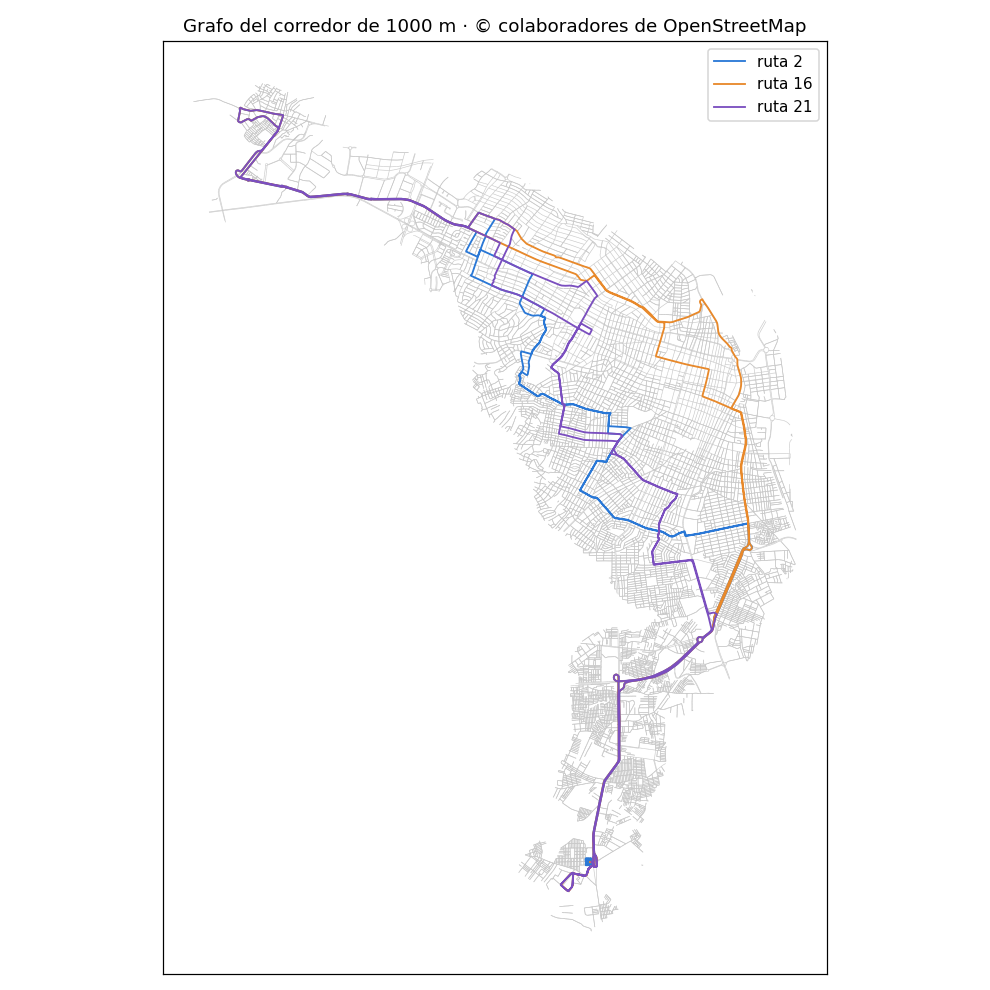

In [4]:
info = {k: v for k, v in G.info.items() if k not in ("config", "fuente_peso")}
display(pd.Series(info, dtype=object).to_frame("valor"))
res_g, en_mayor = gv.resumen_grafo(G)
display(res_g.round(2))
vel = R.velocidades
vel.to_csv(SALIDA / "velocidades_clase_12_2.csv", index=False)
display(vel[vel.tipo_dia == "laboral"].pivot(index="grupo", columns="franja", values="v_kmh")[list(gv.NOMBRES_FRANJA)].round(1))
display(vel.groupby("grupo").agg(segmentos=("segmentos", "max"), fuente=("fuente", "first")))
json.dump({**info, **res_g.iloc[0].to_dict()}, open(SALIDA / "grafo_resumen_12_2.json", "w"), indent=2, default=str)
fig, ax = plt.subplots(figsize=(9, 9))
eo = np.flatnonzero(G.tipo == gv.TIPO_OSM)
segs = np.stack([G.xy[G.org[eo]], G.xy[G.dst[eo]]], axis=1)
from matplotlib.collections import LineCollection
ax.add_collection(LineCollection(segs, colors="#c8c8c8", linewidths=0.4))
for r in G.nodos_ruta:
    X = G.xy[G.nodos_ruta[r]]; ax.plot(X[:, 0], X[:, 1], color=COLOR[r], lw=1.2, label=f"ruta {r}")
ax.set_aspect("equal"); ax.autoscale(); ax.legend(); ax.set_title(f"Grafo del corredor de {R.cfg.ancho_corredor_m:g} m · © colaboradores de OpenStreetMap")
ax.set_xticks([]); ax.set_yticks([])
figura("m12_grafo_corredor.png")
check("12.2 · todos los nodos de ruta en la componente fuertemente conexa principal", res_g.pct_nodos_ruta_en_mayor.iloc[0] == 100,
      f"{res_g.pct_nodos_ruta_en_mayor.iloc[0]:.1f} % · {res_g.pct_nodos_en_mayor.iloc[0]:.1f} % de todos los nodos")

**Conclusión 2 · Grafo vial (12.2)**
- **Sin descargas nuevas:** de las 16.563 calles del archivo de OpenStreetMap del Módulo 10, 7.262 caen en el corredor de 1 km. Se excluyen el carril exclusivo de Transmetro (`busway`), las vías de servicio, las peatonales y las que están en construcción.
- **Grafo:** 33.998 nodos (26.100 de calle) y 84.975 aristas: 51.627 de calle, 7.898 de ruta (los 386 segmentos cada 25 m) y 25.450 conectores ruta ↔ calle.
- **Conectividad:** el **100 % de los nodos de ruta** está en la componente fuertemente conexa principal (96,6 % de todos los nodos). Desde cualquier punto de una ruta se puede llegar a cualquier otro respetando los sentidos únicos.
- **Área de cobertura:** cada calle se recorta arista por arista al corredor, así que ninguna alterna puede salir de él (prueba c).
- **Velocidad del bus por tipo de vía** (calibrada con los segmentos de ruta; incluye paradas):
  - troncal 18,8–22,7 km/h; secundaria 15,9–24,2; terciaria 14,6–19,6; local 15,1–20,3;
  - el pico de la tarde es la franja más lenta en todas.
- **Límite:** el archivo de OSM del Módulo 10 solo trae **calles con nombre**. Faltan rampas y enlaces sin nombre, lo que pesa en los intercambiadores (Conclusión 6).

## 3 · Subfase 12.3 — Penalización por eventos (decisiones por defecto, configurables)

In [5]:
reglas = pd.DataFrame([{"severidad": s, "guia_conductor": g, "efecto": ("w = ∞ (bloqueo)" if s >= dr.UMBRAL_BLOQUEO else f"tiempo × {dr.FACTOR_SEVERIDAD[s]}")}
                       for s, g in [(1, "lento"), (2, "pare y siga"), (3, "un carril"), (4, "casi cerrada"), (5, "cerrada")]])
display(reglas)
display(pd.Series(dr.DURACION_DEFECTO_MIN, name="duracion_defecto_min").to_frame())
b = banco[(banco.alcance == "via") & ~banco.es_despeje]
print(f"Banco: {len(banco)} eventos · afectan la vía {len(b)} · solo_bus {int((banco.alcance == 'solo_bus').sum())} · despejes {int(banco.es_despeje.sum())}")
print(f"Duración dicha por el conductor en {b.duracion_estimada_min.notna().mean():.1%} de los eventos de vía; el resto usa la de su tipo")
print(f"Severidad ≥ {dr.UMBRAL_BLOQUEO} (bloqueo): {int((b.severidad >= dr.UMBRAL_BLOQUEO).sum())} eventos")
af = [len(R.aristas_afectadas(dr.Evento.desde_fila(f))[0]) for _, f in b.iterrows()]
print(f"Aristas afectadas por evento: mediana {np.median(af):.0f} (P10 {np.percentile(af, 10):.0f}, P90 {np.percentile(af, 90):.0f})")

,severidad,guia_conductor,efecto
0,1,lento,tiempo × 1.2
1,2,pare y siga,tiempo × 1.5
2,3,un carril,tiempo × 2.0
3,4,casi cerrada,w = ∞ (bloqueo)
4,5,cerrada,w = ∞ (bloqueo)


,duracion_defecto_min
trancon,30
choque,45
varado,30
obra,180
arroyo,60
bloqueo,90
evento,120
semaforo,20
otro,45


Banco: 580 eventos · afectan la vía 481 · solo_bus 41 · despejes 58
Duración dicha por el conductor en 49.5% de los eventos de vía; el resto usa la de su tipo
Severidad ≥ 4 (bloqueo): 188 eventos


Aristas afectadas por evento: mediana 59 (P10 33, P90 96)


**Conclusión 3 · Penalización por eventos (12.3)**
- **Pendientes de la `NOTA_PARA_MODULO_12.md` del Módulo 10**, resueltas con valores configurables, **confirmados por el dueño del módulo el 4-nov-2026**:
  1. «Severidad alta» = **4 y 5** (casi cerrada y cerrada) → w = ∞. Los niveles 3 / 2 / 1 multiplican el tiempo por 2,0 / 1,5 / 1,2.
  2. **Duración:** la que dijo el conductor (49,5 % de los eventos de vía). Si no la dijo, una por tipo: obra 180, evento masivo 120, bloqueo 90, arroyo 60, choque 45, trancón y varado 30, semáforo 20 min.
     - `fin_estimado` = recibido + duración (lo calcula el Módulo 12).
  3. `solo_bus` y despejes no tocan el grafo (99 de los 580 eventos del banco). Sin «ambos sentidos», solo se afecta el sentido del bus.
  4. El contrato 1.2 del Módulo 10 sirve tal como está: el Módulo 12 no pide cambios.
- **El bloqueo cubre la calle, no solo la línea de la ruta:** un evento afecta una mediana de 59 aristas (P10 33, P90 96), entre ellas la calle de OSM y las otras rutas que pasan encima. Sin eso, A* «esquivaría» el bloqueo por la misma calle.
- **En el banco:** 188 eventos llegan a bloqueo (nivel ≥ 4).

## 4 · Subfase 12.4 — A* y caso real: arroyo de la calle 85 con 49C (6-oct-2024)

,valor
estado,alterna
recomendacion,desviar
franja,valle_pm
tipo_dia,domingo_festivo
duracion_min,60.0
fuente_duracion,defecto_tipo
fin_estimado,2024-10-06 16:00:00
segmentos_bloqueados,[87]
segmento_origen,86
segmento_regreso,88


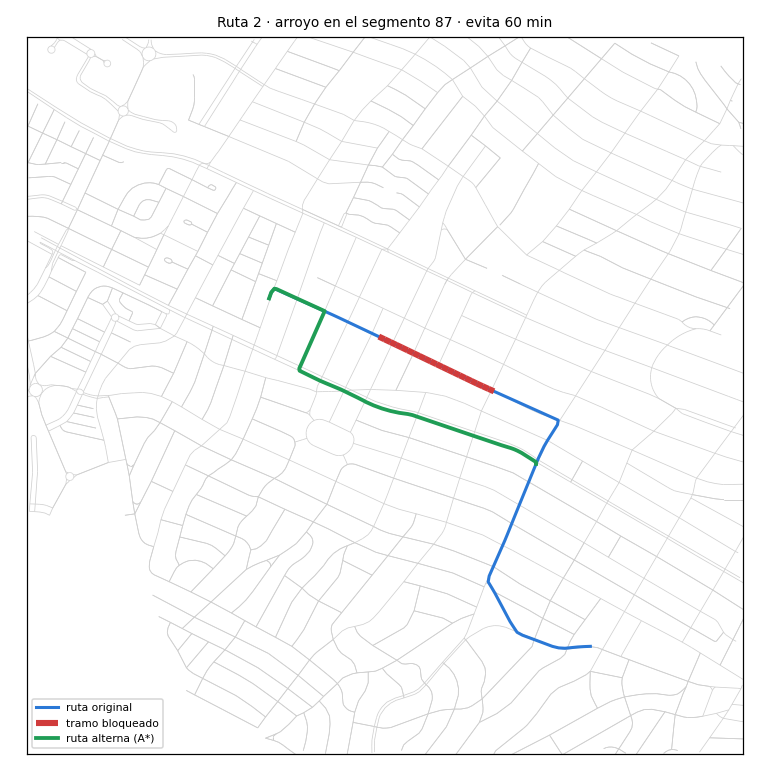

In [6]:
arroyo = dr.Evento("ARROYO-C85-C49C-20241006", 2, 87, "arroyo", 5, "via", "ambos", recibido=pd.Timestamp("2024-10-06 15:00"))
ra = R.reenrutar(arroyo, verificar_dijkstra=True)
vista = {k: ra[k] for k in ["estado", "recomendacion", "franja", "tipo_dia", "duracion_min", "fuente_duracion", "fin_estimado", "segmentos_bloqueados",
                            "segmento_origen", "segmento_regreso", "segmentos_saltados", "t_normal_s", "espera_s", "t_alterna_s", "costo_busqueda_s",
                            "costo_dijkstra_s", "minutos_evitados", "dif_recorrido_min", "km_ruta", "km_alterna", "calles", "nodos_expandidos",
                            "nodos_expandidos_dijkstra", "latencia_ms"]}
display(pd.Series(vista, dtype=object).to_frame("valor"))
guardar_geojson("arroyo_calle85_carrera49C_ruta2", R.geojson(ra))


def dibujar(ax, res, pts=None, caja=1800, titulo=""):
    cam = res.get("camino_nodos") or []
    ref = G.xy[cam].mean(0) if cam else G.xy[G.nodos_ruta[res["idruta"]][res["tramo_original"][0]]]
    m = (np.abs((G.xy[G.org] + G.xy[G.dst]) / 2 - ref) < caja).all(1) & (G.tipo == gv.TIPO_OSM)
    ax.add_collection(LineCollection(np.stack([G.xy[G.org[m]], G.xy[G.dst[m]]], 1), colors="#d0d0d0", linewidths=0.5))
    nodos = G.nodos_ruta[res["idruta"]]; n = len(nodos)
    if "tramo_original" in res:
        p0, p1 = res["tramo_original"]; X = G.xy[nodos[[(p0 + k) % n for k in range((p1 - p0) % n + 1)]]]
        ax.plot(X[:, 0], X[:, 1], color="#2a78d6", lw=2, label="ruta original")
    bl = res.get("aristas_bloqueadas_ruta", [])
    if len(bl):
        ax.add_collection(LineCollection(np.stack([G.xy[G.org[bl]], G.xy[G.dst[bl]]], 1), colors="#d03b3b", linewidths=4, label="tramo bloqueado"))
    if cam:
        Y = G.xy[cam]; ax.plot(Y[:, 0], Y[:, 1], color="#1f9d55", lw=2.5, label="ruta alterna (A*)")
    if pts is not None:
        ax.plot(pts[:, 0], pts[:, 1], "ko-", ms=3, lw=0.7, label="GPS real")
    ax.set_xlim(ref[0] - caja, ref[0] + caja); ax.set_ylim(ref[1] - caja, ref[1] + caja); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(titulo, fontsize=9); ax.legend(fontsize=7, loc="lower left")


fig, ax = plt.subplots(figsize=(7, 7))
dibujar(ax, ra, caja=1400, titulo=f"Ruta 2 · arroyo en el segmento 87 · evita {ra['minutos_evitados']:.0f} min")
figura("m12_arroyo_calle85.png")

In [7]:
# Latencia y optimalidad en todo el banco (la hora de cada evento elige sus pesos)
t1 = time.time()
tb = dr.evaluar_banco(R, banco, verificar_dijkstra=True)
consultas = tb[tb.estado != "sin_afectacion"]
ok = consultas.costo_dijkstra_s.notna()
iguales = np.isclose(consultas.loc[ok, "costo_busqueda_s"].replace(np.inf, -1), consultas.loc[ok, "costo_dijkstra_s"].replace(np.inf, -1), atol=1e-6).all()
lat = consultas.latencia_ms
print(f"{len(consultas)} consultas en {time.time() - t1:.1f} s · latencia mediana {lat.median():.1f} ms · P95 {lat.quantile(.95):.1f} ms · máx {lat.max():.1f} ms")
print(f"A* = Dijkstra: {iguales} · nodos expandidos A* {consultas.nodos_expandidos.median():.0f} vs Dijkstra {consultas.nodos_expandidos_dijkstra.median():.0f} (medianas)")
check("12.4 · latencia P95 < 100 ms (plan)", lat.quantile(.95) < 100, f"mediana {lat.median():.1f} ms · P95 {lat.quantile(.95):.1f} ms · máx {lat.max():.1f} ms")
check("12.4 · A* óptimo (= Dijkstra) en todas las consultas", bool(iguales), f"{int(ok.sum())} consultas")

480 consultas en 12.0 s · latencia mediana 10.5 ms · P95 18.8 ms · máx 91.5 ms
A* = Dijkstra: True · nodos expandidos A* 2183 vs Dijkstra 3798 (medianas)


**Conclusión 4 · A* y caso real (12.4)**
- **Arroyo de la calle 85 con 49C** (El Heraldo, 6-oct-2024; ruta 2, segmento 87; domingo, valle de la tarde; 60 min por defecto para un arroyo):
  - el bus se desvía por la Carrera 49C, la Calle 91 y la Avenida Carrera 46, y vuelve a su ruta en el segmento 88;
  - el desvío tarda 7,6 min frente a 7,4 min de la ruta normal (+0,2 min; 2,54 frente a 2,48 km), y **evita 59,8 min de espera**.
- **Optimalidad:** A* = Dijkstra en las 480 consultas del banco. A* expande una mediana de 2.183 nodos frente a 3.798 (en el arroyo, 2.621 frente a 5.463).
- **Latencia, criterio del plan < 100 ms:** mediana **10,5 ms**, **P95 18,8 ms**, máximo 91,5 ms. En la corrida de la prueba d hubo un pico aislado de 110 ms, con P95 de 19,9 ms.
- El grafo y los pesos se construyen una sola vez, en 10,2 s.

## 5 · Subfase 12.5 (a) — Escenarios simulados: banco de eventos del Módulo 10

In [8]:
tb.to_csv(SALIDA / "tb_rutas_alternas_12.csv", index=False)
tb.to_parquet(SALIDA / "tb_rutas_alternas_12.parquet", index=False)
display(pd.crosstab(tb.severidad, tb.estado, margins=True))
bloq = tb[(tb.severidad >= dr.UMBRAL_BLOQUEO) & (tb.estado != "sin_afectacion")]
alt = bloq[bloq.estado == "alterna"]
resumen = pd.DataFrame([{
    "eventos_bloqueo": len(bloq), "con_alterna": len(alt), "pct_con_alterna": 100 * len(alt) / len(bloq),
    "sin_alternativa": int((bloq.estado == "sin_alternativa").sum()),
    "min_evitados_mediana": alt.minutos_evitados.median(), "min_evitados_P90": alt.minutos_evitados.quantile(.9),
    "min_evitados_total": alt.minutos_evitados.sum(), "espera_evitada_mediana": alt.espera_evitada_min.median(),
    "dif_recorrido_mediana_min": alt.dif_recorrido_min.median(), "dif_recorrido_P90_min": alt.dif_recorrido_min.quantile(.9),
    "segmentos_saltados_mediana": alt.segmentos_saltados.map(lambda s: len(json.loads(s))).median(),
    "km_extra_mediana": (alt.km_alterna - alt.km_ruta).median()}])
display(resumen.round(2).T)
leves = tb[(tb.severidad < dr.UMBRAL_BLOQUEO) & (tb.estado != "sin_afectacion")]
print(f"Severidad 1–3 ({len(leves)} eventos): desviar en {(leves.estado == 'alterna').mean():.1%}; "
      f"minutos evitados mediana {leves.loc[leves.estado == 'alterna', 'minutos_evitados'].median():.1f}")
por_tipo = alt.groupby("tipo_evento").agg(n=("id_evento", "size"), min_evitados=("minutos_evitados", "median"),
                                          duracion=("duracion_min", "median"), dif_recorrido=("dif_recorrido_min", "median"))
display(por_tipo.round(1))
display(alt.groupby("idruta").agg(n=("id_evento", "size"), min_evitados=("minutos_evitados", "median"), km_extra=("km_alterna", "median")).round(2))

estado,alterna,seguir_con_demora,sin_alternativa,All
severidad,,,,
1.0,17,77,0,94
2.0,10,87,0,97
3.0,21,80,0,101
4.0,92,0,2,94
5.0,92,0,2,94
All,232,244,4,480


,0
eventos_bloqueo,188.00
con_alterna,184.00
pct_con_alterna,97.87
sin_alternativa,4.00
min_evitados_mediana,49.98
min_evitados_P90,178.13
min_evitados_total,13288.46
espera_evitada_mediana,45.00
dif_recorrido_mediana_min,0.81
dif_recorrido_P90_min,5.21


Severidad 1–3 (292 eventos): desviar en 16.4%; minutos evitados mediana 4.6


,n,min_evitados,duracion,dif_recorrido
tipo_evento,,,,
arroyo,19,59.6,60.0,1.4
bloqueo,20,87.4,90.0,1.1
choque,36,44.7,45.0,1.2
evento,9,119.7,120.0,0.2
obra,26,128.4,135.0,1.0
otro,22,44.1,45.0,1.0
semaforo,13,19.2,20.0,0.7
trancon,29,31.9,30.0,0.5
varado,10,32.4,30.0,0.4


,n,min_evitados,km_extra
idruta,,,
2,66,54.60,2.64
16,51,55.06,2.92
21,67,46.00,2.61


In [9]:
# Sensibilidad: cada fila cambia UNA decisión y vuelve a reenrutar los eventos de bloqueo del caso base
base_ids = set(bloq.id_evento)
sub = banco[banco.id_evento.isin(base_ids)]
def resumir(nombre, d):
    a = d[d.estado == "alterna"]
    return {"escenario": nombre, "pct_con_alterna": 100 * len(a) / len(d), "min_evitados_mediana": a.minutos_evitados.median(),
            "min_evitados_total": a.minutos_evitados.sum(), "dif_recorrido_mediana": a.dif_recorrido_min.median(), "latencia_P95": d.latencia_ms.quantile(.95)}
sens = [resumir("base", tb[tb.id_evento.isin(base_ids)])]
for k in (0.5, 2.0):
    sens.append(resumir(f"duración × {k:g}", pd.DataFrame([dr.resultado_a_fila(R.reenrutar(dr.Evento.desde_fila(f), espera_min=dr.duracion_min(dr.Evento.desde_fila(f))[0] * k)) for _, f in sub.iterrows()])))
for pen in (0.0, 180.0):
    R.penal_saltado_s = pen
    sens.append(resumir(f"penalización por segmento saltado = {pen:g} s", dr.evaluar_banco(R, sub)))
R.penal_saltado_s = dr.PENAL_SEGMENTO_SALTADO_S
cfg0 = R.cfg
R.cfg = replace(cfg0, factor_terciaria=1.0, factor_local=1.0)
sens.append(resumir("sin preferencia por vías principales", dr.evaluar_banco(R, sub)))
R.cfg = cfg0
R_g = dr.ReenrutadorDinamico(G, gv.calcular_pesos(G, R.tiempos, R.velocidades, R.cfg, usar_google=True), R.cfg, calendario=R.calendario)
sens.append(resumir("con índice de Google (Módulo 11) en calles sin GPS", dr.evaluar_banco(R_g, sub)))
for ancho in (500.0, 1500.0):
    Rc = dr.ReenrutadorDinamico.desde_insumos(replace(gv.CFG, ancho_corredor_m=ancho))
    sens.append(resumir(f"corredor de {ancho:g} m", dr.evaluar_banco(Rc, sub)))
sens = pd.DataFrame(sens)
sens.to_csv(SALIDA / "sensibilidad_12_5.csv", index=False)
display(sens.round(2))

,escenario,pct_con_alterna,min_evitados_mediana,min_evitados_total,dif_recorrido_mediana,latencia_P95
0,base,97.87,49.98,13288.46,0.81,20.60
1,duración × 0.5,97.34,25.97,6548.65,0.78,20.79
2,duración × 2,97.87,94.98,26773.46,0.81,20.31
3,penalización por segmento saltado = 0 s,97.87,49.98,13336.94,0.56,18.15
4,penalización por segmento saltado = 180 s,97.87,48.82,13121.06,1.32,25.98
5,sin preferencia por vías principales,97.87,50.74,13352.50,0.58,20.48
6,con índice de Google (Módulo 11) en calles sin GPS,97.87,49.96,13290.39,0.76,20.98
7,corredor de 500 m,82.98,47.08,11072.76,0.53,54.91
8,corredor de 1500 m,100.00,49.98,13534.16,0.90,23.55


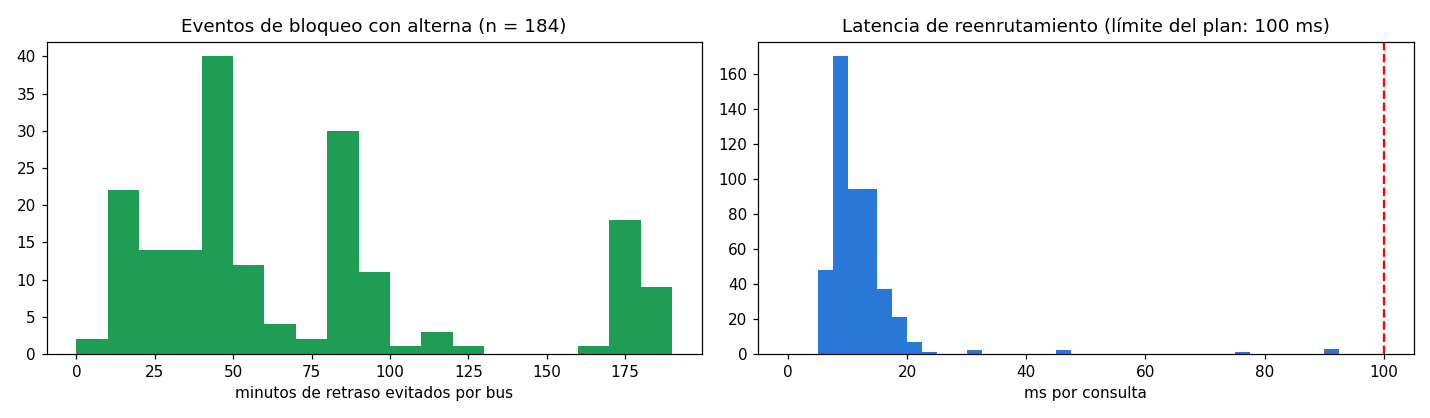

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(alt.minutos_evitados, bins=np.arange(0, 200, 10), color="#1f9d55")
ax[0].set_xlabel("minutos de retraso evitados por bus"); ax[0].set_title(f"Eventos de bloqueo con alterna (n = {len(alt)})")
ax[1].hist(lat, bins=np.arange(0, lat.max() + 5, 2.5), color="#2a78d6"); ax[1].axvline(100, color="r", ls="--")
ax[1].set_xlabel("ms por consulta"); ax[1].set_title("Latencia de reenrutamiento (límite del plan: 100 ms)")
figura("m12_minutos_latencia.png")
# GeoJSON de los ejemplos con más minutos evitados por ruta
for r, g in alt.groupby("idruta"):
    f = banco[banco.id_evento == g.sort_values("minutos_evitados").id_evento.iloc[-1]].iloc[0]
    guardar_geojson(f"ejemplo_ruta{r}_{f.id_evento}", R.geojson(R.reenrutar(dr.Evento.desde_fila(f))))
check("12.5a · eventos de bloqueo con ruta alterna", len(alt) / len(bloq) > 0.9,
      f"{len(alt)} de {len(bloq)} ({100 * len(alt) / len(bloq):.1f} %); mediana {alt.minutos_evitados.median():.1f} min evitados")

**Conclusión 5 · Escenarios simulados (12.5 a)**
- **Bloqueos (nivel 4–5): 184 de 188 eventos tienen ruta alterna (97,9 %).** Los 4 sin alternativa dentro del corredor están junto a las terminales (ruta 2, segmento 128; ruta 16, segmentos 8, 115 y 116): ahí la respuesta es esperar.
- **Minutos de retraso evitados por bus: mediana 50,0** (P90 178,1). Suman 13.288 min en los 184 eventos.
  - Casi todo es **espera evitada** (mediana 45 min).
  - El desvío cuesta una mediana de +0,8 min de recorrido (P90 +5,2), salta 2 segmentos y agrega 0,16 km.
- **Los minutos evitados dependen sobre todo de la duración supuesta.** Con la duración × 0,5 la mediana cae a 26,0 min; con × 2 sube a 95,0.
  - Suponen que el bus llega al inicio del evento y esperaría todo el resto: son una **cota superior** del beneficio por evento.
- **Por tipo (mediana):** obra 128,4 min, evento masivo 119,7, bloqueo 87,4, arroyo 59,6, choque 44,7, trancón 31,9, semáforo 19,2.
- **Severidad 1–3 (292 eventos):** desviar conviene solo en el 16,4 % (mediana 4,6 min). En el resto, seguir por la ruta lenta sigue siendo lo mejor.
- **Sensibilidad (eventos de bloqueo):**
  - penalización por segmento saltado de 0 o 180 s: mediana 50,0 / 48,8 min;
  - sin preferencia por vías principales: 50,7;
  - **con el índice de Google: 50,0 (sin cambio, igual que concluyó el Módulo 11)**;
  - **corredor de 500 m: solo 83,0 % con alterna**; de 1.500 m: 100 %. El corredor de 1 km cubre el 97,9 % sin agrandar el grafo.

## 6 · Subfase 12.5 (b) — Validación con desvíos reales del GPS

In [11]:
t1 = time.time()
lect = vd.cargar_trayectorias()
ep, pts = vd.episodios_desvio(lect, gv.cargar_segmentos())
print(f"{lect.idprogramacion.nunique():,} viajes con GPS · {len(ep)} episodios fuera de ruta con regreso ({time.time() - t1:.0f} s)")
display(ep.groupby("zona").agg(episodios=("episodio", "size"), metros_saltados=("metros_saltados", "median"),
                               dist_max_m=("dist_max_m", "median"), minutos_fuera=("minutos_fuera", "median"),
                               desde=("anio_mes", "min"), hasta=("anio_mes", "max")).sort_values("episodios", ascending=False).round(0))
cal, eva = ep[ep.idprogramacion % 2 == 0], ep[ep.idprogramacion % 2 == 1]
print(f"Calibración (idprogramacion par): {len(cal)} · Evaluación (impar, no se usa para elegir nada): {len(eva)}")
grilla = vd.calibrar_factores(R, cal, pts)
grilla.to_csv(SALIDA / "calibracion_factores_12_5.csv", index=False)
display(grilla.round(2))
mejor = grilla.iloc[0]
check("12.5b · factores del código = los mejores en calibración", (mejor.factor_terciaria, mejor.factor_local) == (R.cfg.factor_terciaria, R.cfg.factor_local),
      f"terciaria {mejor.factor_terciaria:g}, local {mejor.factor_local:g}")

1,673 viajes con GPS · 952 episodios fuera de ruta con regreso (47 s)


,episodios,metros_saltados,dist_max_m,minutos_fuera,desde,hasta
zona,,,,,,
Z3,353,2040.0,557.0,6.0,2023-01,2024-12
Z1,300,2025.0,820.0,6.0,2023-03,2025-10
Z4,128,2227.0,614.0,9.0,2024-03,2025-12
Z7,69,1170.0,247.0,9.0,2024-02,2025-10
sin_zona,18,1262.0,968.0,16.0,2023-01,2025-12
Z16,13,650.0,238.0,8.0,2024-02,2025-11
Z8,13,955.0,238.0,5.0,2024-03,2025-03
Z6,13,1225.0,459.0,8.0,2023-02,2025-11
Z10,10,832.0,302.0,7.0,2023-10,2025-09


Calibración (idprogramacion par): 483 · Evaluación (impar, no se usa para elegir nada): 469


,factor_terciaria,factor_local,episodios,cobertura_media_100m,pct_episodios_cob_50_a_100m
0,2.0,2.0,444,20.39,19.05
1,2.0,3.0,444,19.60,18.01
2,1.5,2.0,444,19.56,17.60
3,1.0,1.0,444,19.52,18.84
4,1.5,3.0,444,19.07,17.60
5,1.0,2.0,444,18.94,18.43
6,1.0,3.0,444,18.37,17.81
7,2.0,5.0,444,18.20,16.98
8,1.5,5.0,444,17.20,16.36
9,1.0,5.0,444,13.84,10.97


In [12]:
t1 = time.time()
ce = vd.comparar_con_alterna(R, eva, pts)
ce.drop(columns=["segmentos_saltados"]).to_csv(SALIDA / "desvios_reales_evaluacion_12_5.csv", index=False)
print(f"Evaluación: {len(ce)} episodios ({time.time() - t1:.0f} s); con camino {ce.t_pred_min.notna().sum()}")
filas = []
for rad in (50, 100, 200):
    a, b = ce[f"cob_tiempo_{rad}"], ce[f"cob_distancia_{rad}"]
    m = a.notna() & b.notna()
    w = wilcoxon(a[m], b[m]) if (a[m] != b[m]).any() else None
    filas.append({"radio_m": rad, "cobertura_media_tiempo": a.mean(), "cobertura_media_distancia": b.mean(),
                  "pct_cob50_tiempo": 100 * (a >= 50).mean(), "pct_cob50_distancia": 100 * (b >= 50).mean(),
                  "episodios_mejora_tiempo": int((a[m] > b[m]).sum()), "episodios_mejora_distancia": int((a[m] < b[m]).sum()),
                  "p_wilcoxon": w.pvalue if w else np.nan})
cob = pd.DataFrame(filas)
cob.to_csv(SALIDA / "cobertura_desvios_12_5.csv", index=False)
display(cob.round(3))
m = ce.t_pred_min.notna() & (ce.minutos_fuera > 0)
razon = ce.loc[m, "t_pred_min"] / ce.loc[m, "minutos_fuera"]
mdape = 100 * (np.abs(ce.loc[m, "t_pred_min"] - ce.loc[m, "minutos_fuera"]) / ce.loc[m, "minutos_fuera"]).median()
rho = spearmanr(ce.loc[m, "t_pred_min"], ce.loc[m, "minutos_fuera"])
tiempo = pd.DataFrame([{"episodios": int(m.sum()), "min_real_mediana": ce.loc[m, "minutos_fuera"].median(), "min_predicho_mediana": ce.loc[m, "t_pred_min"].median(),
                        "razon_mediana_pred_real": razon.median(), "MdAPE_%": mdape, "spearman": rho.statistic, "p_spearman": rho.pvalue}])
display(tiempo.round(3))
display(ce.groupby("zona").agg(n=("episodio", "size"), cob100_tiempo=("cob_tiempo_100", "mean"), cob100_distancia=("cob_distancia_100", "mean"),
                               min_real=("minutos_fuera", "median"), min_pred=("t_pred_min", "median")).sort_values("n", ascending=False).round(1))
c100 = cob.set_index("radio_m").loc[100]
check("12.5b · coincidencia con el camino real (100 m, evaluación)", True,
      f"tiempo {c100.cobertura_media_tiempo:.1f} % vs distancia {c100.cobertura_media_distancia:.1f} % (Wilcoxon p {c100.p_wilcoxon:.3f})", info=True)
check("12.5b · tiempo predicho vs tiempo real fuera de ruta", True,
      f"razón mediana {razon.median():.2f} · MdAPE {mdape:.1f} % · Spearman {rho.statistic:.2f}", info=True)

Evaluación: 469 episodios (16 s); con camino 434


,radio_m,cobertura_media_tiempo,cobertura_media_distancia,pct_cob50_tiempo,pct_cob50_distancia,episodios_mejora_tiempo,episodios_mejora_distancia,p_wilcoxon
0,50,16.315,15.812,14.286,13.220,36,14,0.280
1,100,20.710,19.801,18.550,16.631,39,14,0.020
2,200,26.285,25.947,21.109,19.829,26,11,0.182


,episodios,min_real_mediana,min_predicho_mediana,razon_mediana_pred_real,MdAPE_%,spearman,p_spearman
0,434,6.25,17.764,2.69,168.99,0.154,0.001


,n,cob100_tiempo,cob100_distancia,min_real,min_pred
zona,,,,,
Z3,169,10.1,10.1,5.6,17.9
Z1,159,4.4,3.9,6.2,18.6
Z4,53,49.4,31.4,9.0,12.9
Z7,38,78.0,79.5,9.0,6.7
sin_zona,10,44.1,44.1,12.4,6.3
Z16,9,73.8,94.9,7.4,4.4
Z8,8,35.6,61.5,5.9,5.4
Z6,6,58.7,54.1,9.4,14.2
Z10,5,58.3,62.5,5.9,5.0


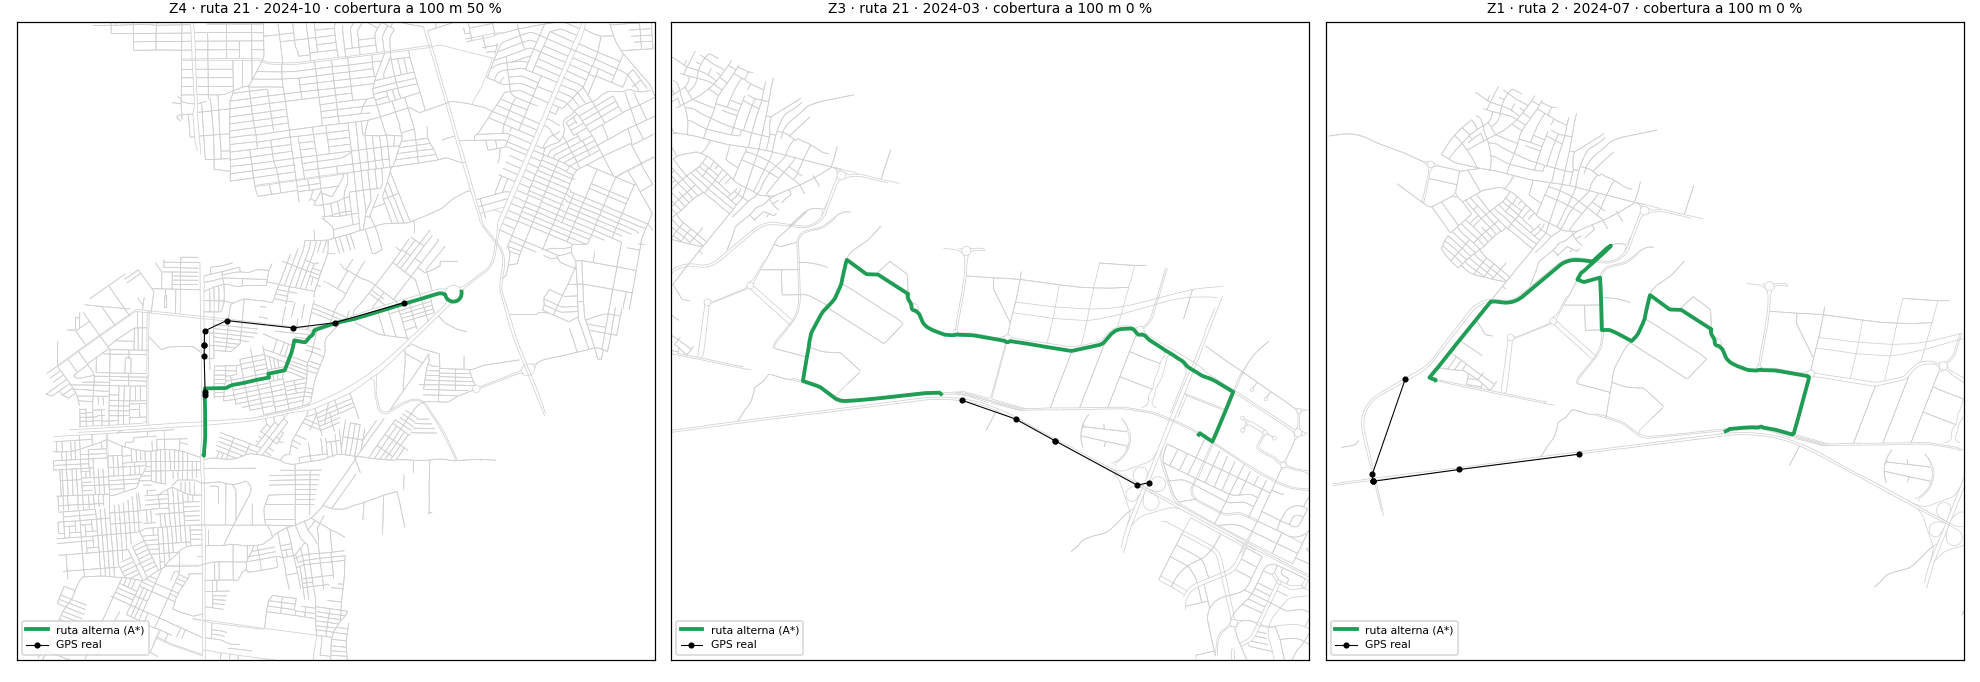

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(18, 6.2))
for ax, z in zip(axs, ["Z4", "Z3", "Z1"]):
    g = ce[(ce.zona == z) & ce.t_pred_min.notna()]
    if not len(g):
        ax.axis("off"); continue
    e = g.sort_values("cob_tiempo_100").iloc[len(g) // 2]           # episodio mediano de la zona
    a = vd.alterna_mismos_extremos(R, e)
    res = {"idruta": int(e.idruta), "camino_nodos": a["camino"]}
    dibujar(ax, res, pts[e.episodio], caja=2200, titulo=f"{z} · ruta {e.idruta} · {e.anio_mes} · cobertura a 100 m {e.cob_tiempo_100:.0f} %")
    gj = {"type": "FeatureCollection", "features": [
        dr._linea(G, a["camino"], {"capa": "ruta_alterna_modelo", "color": "#1f9d55"}),
        {"type": "Feature", "properties": {"capa": "gps_real", "color": "#000000"}, "geometry": {"type": "LineString", "coordinates":
            [[round(float(lo), 7), round(float(la), 7)] for la, lo in zip(*gv.rv.a_latlon(pts[e.episodio]))]}}]}
    guardar_geojson(f"desvio_real_{z}_episodio{e.episodio}", gj)
figura("m12_desvios_reales.png")

**Conclusión 6 · Desvíos reales del GPS (12.5 b)**
- **Episodios:** en 1.673 viajes con GPS hay **952 desvíos reales** (el bus sale de su ruta y vuelve más adelante). El 82 % está en las zonas Z3 (353), Z1 (300) y Z4 (128) del Módulo 10. Mediana: 2,0 km saltados y 6,4 min fuera.
- **Calibración** (483 episodios, viajes pares) del factor de preferencia por vías principales: terciaria × 2 y local × 2 da la mejor coincidencia a 100 m (20,4 % frente a 19,5 % sin factor). Es una mejora pequeña.
- **Evaluación** (469 episodios, viajes impares, con los mismos puntos de salida y regreso): coincidencia media con el camino real a 100 m de **20,7 % con tiempos, frente a 19,8 %** con la línea base de solo distancia.
  - Mejora en 39 episodios y empeora en 14 (Wilcoxon p = 0,020).
  - A 50 m: 16,3 % frente a 15,8 % (p = 0,28). A 200 m: 26,3 % frente a 25,9 % (p = 0,18).
- **Funciona en la ciudad, falla en los intercambiadores:**
  - **Z4: 49,4 % frente a 31,4 %; Z7: 78,0 %.** El tiempo predicho es del mismo orden que el real (Z4: 12,9 frente a 9,0 min; Z7: 6,7 frente a 9,0).
  - **Z3 (10,1 %) y Z1 (4,4 %)**, junto a la Circunvalar y la Vía al Mar: incluso el camino más corto del grafo mide 5,3–5,5 km, frente a los ~2,4–3,4 km que hizo el bus por la autopista, a 28–34 km/h.
    - **Al grafo le faltan las rampas sin nombre** (Conclusión 2), por eso ahí el modelo predice ~18 min frente a ~6 reales.
- **En total**, el tiempo predicho es 2,69 veces el real (mediana; Spearman 0,15).
  - En esas zonas los minutos evitados de la Conclusión 5 son **conservadores**: la alterna real es más corta.
  - Además, muchos episodios de Z1 y Z3 son **variantes de servicio** que duraron meses, no desvíos por un evento.
- **Siguiente paso natural:** completar el grafo con las vías sin nombre de OSM en una descarga única, que haría el dueño del Módulo 10.

## 7 · Pruebas y checks

In [14]:
pruebas = T.correr_todos(R, banco)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
check("Tiempo total de la ejecución", True, f"{(time.time() - T0) / 60:,.1f} min", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_12.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")
print("GeoJSON:", sorted(p.name for p in (SALIDA / "geojson").glob("*.geojson")))

,check,resultado,detalle
0,12.1 · la tabla por franja × día mejora a la línea base (MdAPE),PASS,"18.2 % vs 19.8 % en 27,342 pasos de viajes reservados"
1,12.1 · pasos > 50 km/h descartados (hallazgo para el Módulo 11),INFO,"19,850 (12.5 %), 37% en la terminal"
2,12.2 · todos los nodos de ruta en la componente fuertemente conexa principal,PASS,100.0 % · 96.6 % de todos los nodos
3,12.4 · latencia P95 < 100 ms (plan),PASS,mediana 10.5 ms · P95 18.8 ms · máx 91.5 ms
4,12.4 · A* óptimo (= Dijkstra) en todas las consultas,PASS,480 consultas
5,12.5a · eventos de bloqueo con ruta alterna,PASS,184 de 188 (97.9 %); mediana 50.0 min evitados
6,12.5b · factores del código = los mejores en calibración,PASS,"terciaria 2, local 2"
7,"12.5b · coincidencia con el camino real (100 m, evaluación)",INFO,tiempo 20.7 % vs distancia 19.8 % (Wilcoxon p 0.020)
8,12.5b · tiempo predicho vs tiempo real fuera de ruta,INFO,razón mediana 2.69 · MdAPE 169.0 % · Spearman 0.15
9,Test a · A* = Dijkstra,PASS,480 consultas: A* = Dijkstra (error < 1e-6 s); A* expande 37% menos nodos


PASS 16 · FAIL 0 · INFO 4
GeoJSON: ['arroyo_calle85_carrera49C_ruta2.geojson', 'desvio_real_Z1_episodio538.geojson', 'desvio_real_Z3_episodio397.geojson', 'desvio_real_Z4_episodio629.geojson', 'ejemplo_ruta16_EV-ebe96ef7e62c.geojson', 'ejemplo_ruta21_EV-c169adc757bd.geojson', 'ejemplo_ruta2_EV-d9de13829385.geojson']


**Conclusión 7 · Pruebas**
- **16 PASS, 0 FAIL, 4 INFO.** Pasan las **10 de 10 pruebas** (`py -3.10 tests_12.py`):
  - **a)** A* = Dijkstra en 480 consultas, con 37 % menos nodos expandidos;
  - **b)** ninguna alterna usa una arista bloqueada; `solo_bus` y despejes no tocan el grafo;
  - **c)** el grafo no sale del corredor;
  - **d)** latencia P95 < 100 ms;
  - **e)** heurística admisible en 2.000 nodos;
  - **f)** ningún archivo importa clientes de API;
  - **g)** determinismo;
  - **h)** tabla 12.1 sin huecos y ≤ 50 km/h;
  - **i)** el bus vuelve después del bloqueo;
  - **j)** duración y `fin_estimado`.
- **Ejecución:** 4,4 min. **Ninguna llamada a API** (Google, Claude ni OSM) durante el módulo.

## Síntesis para el jurado y pendientes

| Pregunta del plan | Respuesta |
|---|---|
| ¿Recalcula la ruta alterna cuando un evento bloquea la vía? | Sí: **97,9 %** de los 188 bloqueos del banco del Módulo 10 tienen alterna dentro del área de cobertura |
| ¿Cuántos minutos de retraso evita por bus? | **Mediana 50 min** por evento de bloqueo (cota superior: casi todo es la espera evitada); el desvío suma +0,8 min de recorrido |
| ¿Cumple < 100 ms por consulta? | Sí: **P95 18,8 ms**, mediana 10,5 ms |
| ¿Es óptimo? | A* = Dijkstra en las 480 consultas |
| ¿Se parece a lo que hacen los buses? | En zonas urbanas sí (Z4 49 %, Z7 78 % de coincidencia). En los intercambiadores no, porque al mapa le faltan las rampas sin nombre |

**Para los Módulos 13 y 14:**
- `ReenrutadorDinamico.desde_insumos()` construye todo en ~10 s, sin API.
- `reenrutar(evento, momento, idruta)` devuelve la alterna, los minutos evitados, los segmentos saltados y el GeoJSON en ~10 ms; el simulador puede llamarlo en cada evento.
- `datos_12/tb_rutas_alternas_12.csv` trae el resultado precalculado de los 580 eventos del banco.

**Decisiones confirmadas (4-nov-2026):** bloqueo con severidad ≥ 4; niveles 1–3 multiplican el tiempo por 1,2 / 1,5 / 2,0; duraciones por tipo; 60 s por segmento saltado.

**Pendientes del equipo:**
1. **Módulo 11:** revisar los 19.850 pasos > 50 km/h de su tabla de pasos (hallazgo 12.1).
2. **Módulo 10:** completar el grafo con las vías sin nombre de OSM (rampas de la Circunvalar y la Vía al Mar), en una sola descarga.
3. **Velocidades:** las calles sin GPS usan la velocidad del bus con paradas. En autopistas el bus va más rápido (28–34 km/h observados en Z1 y Z3).
4. **Producción:** el GPS en vivo y el WhatsApp real siguen pendientes del Módulo 10 (su §5).

---
# Parte 11 · Módulo 13 · Subfase 13.1 · Parámetros
*Notebook original: `modulo13/subfase_13_1_parametros.ipynb`*

# SOBUSA · Módulo 13 · Subfase 13.1 — Insumos y parámetros del simulador

**Persona 3.** Antes de escribir el simulador (13.2) hay que dejar fijo, con su fuente, todo lo que va a sortear, y fijar
**antes de simular** los días con que se va a validar. Alcance aprobado: `revisiones/alcance_13_1.md`.

| Parámetro | De dónde sale | Archivo (`datos_13/parametros/`) |
|---|---|---|
| Días de validación | 6 días completos de 2025 elegidos con criterios escritos y congelados con hash | `../dias_validacion_13_1.json` |
| Tiempo de cada segmento | Pasos GPS del Módulo 11 con la función del Módulo 12, sin los días de validación | `tiempos_segmento_13_1.csv`, `dispersion_tiempos_13_1.csv`, `tramos_lentos_segmento_13_1.csv` |
| Demanda | Predicción 04:00 del e1c (central) y pasajeros reales (alternativa), 2025 | `demanda_hora_13_1.csv`, `llegadas_segmento_hora_13_1.parquet` |
| Dónde suben y bajan | Muestra de lecturas al azar (calibración) ubicadas con el Viterbi del Módulo 10 | `reparto_segmento_13_1.csv`, `renovacion_13_1.csv` |
| Capacidad, descanso, vuelta | Maestra 2025 | `capacidad_bus_13_1.csv`, `descanso_terminal_13_1.csv`, `duracion_vuelta_13_1.csv` |
| Frecuencias del proyecto | Método de la carga máxima, factor de carga 100 / 85 / 70 % | `frecuencias_estimadas_13_1.csv`, `flota_por_plan_13_1.csv` |
| Incidentes | Señales de los datos (GPS, lluvia, Módulo 9, SOBUSA) y 3 supuestos | `incidentes_13_1.csv`, `varada_bus_13_1.csv` |
| Lo observado en validación | Lecturas nuevas de la base (consulta liviana del 4-nov) | `lecturas_validacion_13_1.parquet`, `ocupacion_observada_validacion_13_1.csv` |

Todo se construye con `py -m src.simulation.parametros` y queda en `manifiesto_parametros_13_1.json` con el hash de cada
insumo y de cada salida.

In [1]:
import hashlib, json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, ".")
from src.simulation import parametros as P

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
D = Path("datos_13"); PAR = D / "parametros"; FIG = Path("resultados_13"); FIG.mkdir(exist_ok=True)
COL = {2: "#2a78d6", 16: "#eb6834", 21: "#1baf7a"}          # una ruta, un color, siempre en este orden
GRIS = "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "font.size": 10, "figure.dpi": 110})
man = json.loads((PAR / "manifiesto_parametros_13_1.json").read_text(encoding="utf-8"))
leer = lambda n: pd.read_parquet(PAR / n) if n.endswith(".parquet") else pd.read_csv(PAR / n)
print("Manifiesto creado:", man["creado"], "·", len(man["salidas"]), "salidas ·", len(man["insumos"]), "insumos")
print("Salidas que cambiaron desde el manifiesto:", [n for n, d in man["salidas"].items() if P.sha(PAR / n) != d["sha256"]])

Manifiesto creado: 2026-11-04T20:17:54 · 20 salidas · 21 insumos
Salidas que cambiaron desde el manifiesto: []


## 1 · Días de validación, congelados antes de simular

In [2]:
reg = json.loads((D / "dias_validacion_13_1.json").read_text(encoding="utf-8"))
ids = pd.read_csv(D / "ids_validacion_13_1.csv", parse_dates=["fechasalida"])
print("Congelados el", reg["creado"], "· hash", reg["ids_sha256"][:16], "· coincide:",
      hashlib.sha256((D / "ids_validacion_13_1.csv").read_bytes()).hexdigest() == reg["ids_sha256"])
prop = pd.read_csv(D / "dias_validacion_propuesta_13_1.csv")
display(prop)
crit = pd.read_csv(D / "dias_2025_criterios_13_1.csv", parse_dates=["fecha"])
print("Días típicos disponibles en 2025:", crit[crit.tipico].tipo_dia_cal.value_counts().to_dict())
print(reg["criterios"])

Congelados el 2026-11-04T14:03:51 · hash b27d37843bab5372 · coincide: True


,rol,fecha,dia_semana,tipo_dia_cal,salidas_r2,salidas_r16,salidas_r21,desv_max,lluvia_4_21_mm,lluvia_hora_max_mm,receso_escolar,evento,viajes_en_muestra
0,laboral_1,2025-11-25,1,laboral,161,278,98,0.0512,0.77,1.0,False,NaN,0
1,laboral_2,2025-04-03,3,laboral,160,315,101,0.0751,0.00,0.0,False,NaN,0
2,sabado,2025-02-15,5,sabado,147,265,88,0.0222,0.53,0.9,False,NaN,0
3,domingo,2025-07-27,6,domingo,115,197,69,0.0534,0.47,0.8,False,NaN,0
4,lluvia_fuerte,2025-06-13,4,laboral,151,316,96,0.0785,29.47,8.6,False,NaN,3
5,evento_masivo,2025-03-25,1,laboral,144,282,95,0.0943,0.00,0.0,False,Partido de la Selección Colombia,1


Días típicos disponibles en 2025: {'laboral': 54, 'sabado': 7, 'domingo': 5}
(todos sobre datos ya guardados):
  típico     = sin festivo, sin Carnaval, sin evento masivo del calendario ampliado, sin día anómalo, clases en curso
               (fuera de receso escolar y del fin de semana que lo abre, como el Domingo de Ramos), lluvia ≤ 1 mm entre las 4 y las 21 h (promedio de los 3 puntos de Open-Meteo),
               salidas de cada ruta a ±10 % de la mediana 2025 de su tipo de día; se ordena por cercanía a la mediana
  laborales  = los 2 más típicos en días distintos de la semana (martes a jueves) y en meses distintos
  lluvia     = el día laboral de 2025 con más lluvia entre las 4 y las 21 h, sin evento y sin día anómalo
  evento     = un evento de SOBUSA de 2025 con hora (novedades_viales_fecha) y con lugar conocido (partido de la
               Selección en el Metropolitano), en laboral, seco; los conciertos de SOBUSA no dicen dónde fueron
  separación = se prefiere un día sin vi

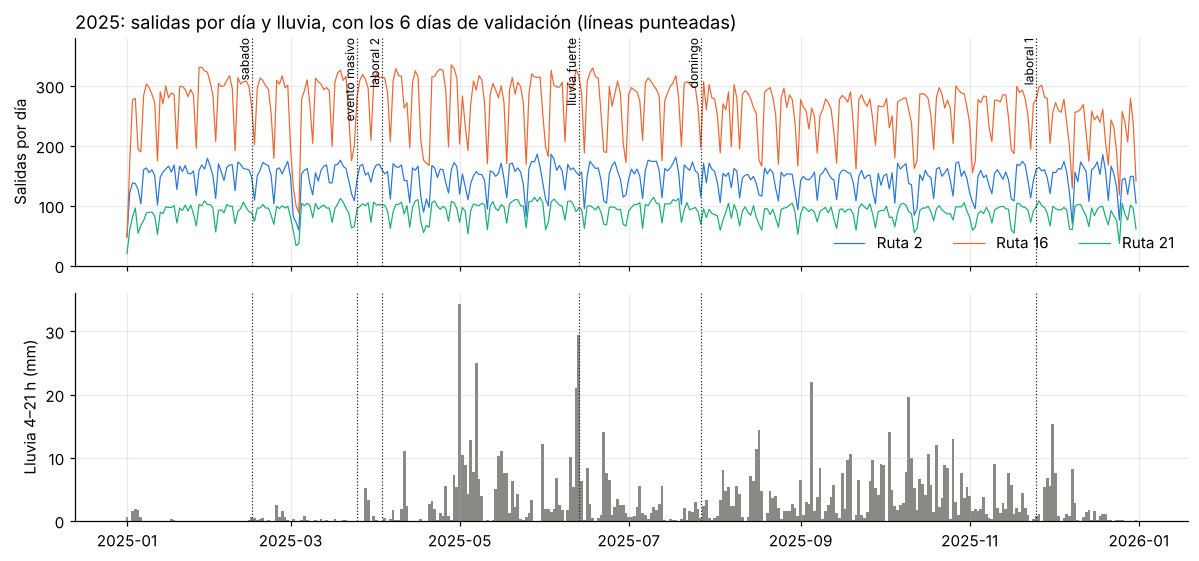

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
for r in (2, 16, 21):
    ax[0].plot(crit.fecha, crit[f"salidas_r{r}"], color=COL[r], lw=.8, label=f"Ruta {r}")
ax[0].set_ylabel("Salidas por día"); ax[0].legend(ncol=3, frameon=False, loc="lower right"); ax[0].set_ylim(0, 380)
ax[1].bar(crit.fecha, crit.lluvia_4_21_mm, color=GRIS, width=1)
ax[1].set_ylabel("Lluvia 4–21 h (mm)")
for d in reg["dias"]:
    f = pd.Timestamp(d["fecha"])
    for a in ax:
        a.axvline(f, color="#1f1f1d", lw=.8, ls=":")
    ax[0].annotate(d["rol"].replace("_", " "), (f, ax[0].get_ylim()[1]), rotation=90, va="top", ha="right", fontsize=8)
ax[0].set_title("2025: salidas por día y lluvia, con los 6 días de validación (líneas punteadas)", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_1_dias_validacion.png", dpi=200, bbox_inches="tight"); plt.show()

### Lo que se trajo de la base para esos días (consulta liviana del 4-nov-2026)

In [4]:
vv = leer("viajes_validacion_13_1.csv")
lv = leer("lecturas_validacion_13_1.parquet")
res = vv.groupby("rol").agg(viajes=("idprogramacion", "size"), con_lecturas=("n_lecturas", "count"),
                           lecturas=("n_lecturas", "sum"), carga_imposible=("carga_imposible", lambda s: int(s.fillna(False).sum())),
                           subidas_lecturas=("subidas_lecturas", "sum"), pasajeros_maestra=("numeropasajeros", "sum"))
res["pct_con_lecturas"] = (100 * res.con_lecturas / res.viajes).round(1)
display(res)
x = vv.dropna(subset=["numeropasajeros", "subidas_lecturas"])
print(f"Viajes con lecturas: {vv.n_lecturas.notna().sum():,} de {len(vv):,} ({100 * vv.n_lecturas.notna().mean():.1f} %)")
print(f"Subidas de las lecturas = pasajeros de la maestra en el {100 * (x.subidas_lecturas == x.numeropasajeros).mean():.1f} % de los viajes con ambos")
print(f"Lecturas fuera de la ruta (desvíos, terminal): {100 * lv.fuera_de_ruta.mean():.1f} %")
print("En calibración:", man["info"]["validacion"]["en_calibracion"], "viajes")

,viajes,con_lecturas,lecturas,carga_imposible,subidas_lecturas,pasajeros_maestra,pct_con_lecturas
rol,,,,,,,
domingo,381,376,96895.0,0,19858.0,16959.0,98.7
evento_masivo,521,514,177862.0,4,47471.0,43088.0,98.7
laboral_1,537,527,166126.0,0,41871.0,38916.0,98.1
laboral_2,576,563,196409.0,4,48775.0,44922.0,97.7
lluvia_fuerte,563,553,178732.0,1,41367.0,38496.0,98.2
sabado,500,489,160928.0,2,39065.0,36398.0,97.8


Viajes con lecturas: 3,022 de 3,078 (98.2 %)
Subidas de las lecturas = pasajeros de la maestra en el 88.3 % de los viajes con ambos
Lecturas fuera de la ruta (desvíos, terminal): 7.2 %
En calibración: 0 viajes


**Conclusión 1 · Seis días congelados antes de simular, con todas sus lecturas**
- **Los días** (elegidos con criterios escritos, aprobados y congelados el 4-nov-2026 a las 14:03, hash `b27d3784…`):

  | Rol | Fecha | Por qué |
  |---|---|---|
  | Laboral 1 | mar 25-nov-2025 | El laboral más típico: salidas a ±5 % de la mediana, 0,77 mm de lluvia |
  | Laboral 2 | jue 3-abr-2025 | Otro día de la semana y otro mes, seco |
  | Sábado | 15-feb-2025 | El sábado más típico (±2 %) |
  | Domingo | 27-jul-2025 | El Domingo de Ramos (13-abr) se descartó porque abre el receso de Semana Santa |
  | Lluvia fuerte | vie 13-jun-2025 | El laboral más lluvioso de 2025: 29,5 mm entre las 4 y las 21 h |
  | Evento masivo | mar 25-mar-2025 | Colombia vs. Paraguay, 19:00, Metropolitano; seco |

- **La consulta liviana** trajo **977.826 lecturas** de 3.055 de los 3.078 viajes.
  - Se limpiaron con la misma función del Módulo 1, que da resultados idénticos sobre la muestra (prueba i).
  - **Quedan ubicadas en su segmento 976.952 lecturas de 3.022 viajes (98,2 %).**
  - Los otros 33 viajes (25 de la ruta 16 y 8 de la 21) nunca salieron de la terminal: sus 874 lecturas están en un mismo punto, a 87–110 m del inicio de su ruta, más allá del umbral de 40 m. 32 de ellos no están en la maestra. No son recorridos.
- **Separación:** ningún viaje de esos días está en la calibración. Eran 4 viajes de la muestra de lecturas: los 2 que estaban entre los viajes al azar se sacaron de la calibración, y los pasos GPS de esos días se sacaron de los tiempos.
- **Para la 13.4:** 11 viajes tienen carga imposible y quedan fuera de la ocupación observada; el 7,2 % de las lecturas está fuera de la ruta (desvíos y terminal) y hereda el último segmento conocido.

## 2 · Tiempos por segmento y su dispersión

In [5]:
t = leer("tiempos_segmento_13_1.csv"); disp = leer("dispersion_tiempos_13_1.csv"); lentos = leer("tramos_lentos_segmento_13_1.csv")
print(json.dumps(man["info"]["tiempos"], indent=1, ensure_ascii=False))
print("Celdas:", len(t), "· fuentes:", t.fuente.value_counts().to_dict())
display(disp[["idruta", "franja", "n_pasos", "n_viajes", "sigma_segmento", "sigma_viaje", "pct_lentos_obs", "pct_lentos_esperado",
              "ratio_lento_mediana"]].round(3))
vt = leer("duracion_vuelta_13_1.csv")
suma = t.groupby(["idruta", "franja", "tipo_dia"]).t_s.sum().div(60).rename("suma_segmentos_min").reset_index()
cmp_ = suma.merge(vt, on=["idruta", "franja", "tipo_dia"])
cmp_["razon"] = cmp_.suma_segmentos_min / cmp_.mediana
print("Suma de los tiempos de los segmentos ÷ vuelta mediana de la maestra (por ruta × franja × día):",
      cmp_.razon.describe()[["min", "50%", "max"]].round(3).to_dict())

{
 "viajes_con_pasos": 1441,
 "viajes_usados": 1439,
 "pasos_usados": 138787,
 "descartados_50kmh": {
  "pasos_totales": 158835,
  "descartados": 19850,
  "pct": 12.497245569301477,
  "v_max_kmh": 50.0
 },
 "dif_max_vs_m12_s": 52.87052650004625,
 "dif_media_vs_m12_pct": 0.03883603038591318,
 "pct_pasos_lentos": 2.699820588383638,
 "puntos_recurrentes": 33,
 "pct_lentos_en_recurrentes": 29.997331198291967,
 "cola_lentos": {
  "probabilidades": [
   0.0,
   0.05,
   0.1,
   0.15,
   0.2,
   0.25,
   0.3,
   0.35,
   0.4,
   0.45,
   0.5,
   0.55,
   0.6,
   0.65,
   0.7,
   0.75,
   0.8,
   0.85,
   0.9,
   0.95,
   0.99
  ],
  "filas": 51
 }
}
Celdas: 6948 · fuentes: {'seg_franja_dia': 5016, 'seg_franja': 1134, 'seg': 672, 'ruta_franja': 126}


,idruta,franja,n_pasos,n_viajes,sigma_segmento,sigma_viaje,pct_lentos_obs,pct_lentos_esperado,ratio_lento_mediana
0,2,madrugada,1307,65,0.224,0.062,0.689,0.143,2.328
1,2,noche,8537,139,0.244,0.078,2.401,0.343,2.390
2,2,pico_am,5295,140,0.233,0.064,2.285,0.202,2.503
3,2,pico_pm,4928,155,0.239,0.074,2.334,0.277,2.496
4,2,valle_am,11362,231,0.242,0.063,1.584,0.275,2.412
5,2,valle_pm,14077,245,0.243,0.078,2.103,0.333,2.412
6,16,madrugada,995,47,0.193,0.060,0.603,0.031,2.144
7,16,noche,5527,122,0.252,0.067,2.045,0.388,2.358
8,16,pico_am,4208,123,0.238,0.074,1.759,0.268,2.425
9,16,pico_pm,5327,164,0.245,0.052,2.159,0.283,2.522


Suma de los tiempos de los segmentos ÷ vuelta mediana de la maestra (por ruta × franja × día): {'min': 0.794, '50%': 0.971, 'max': 1.205}


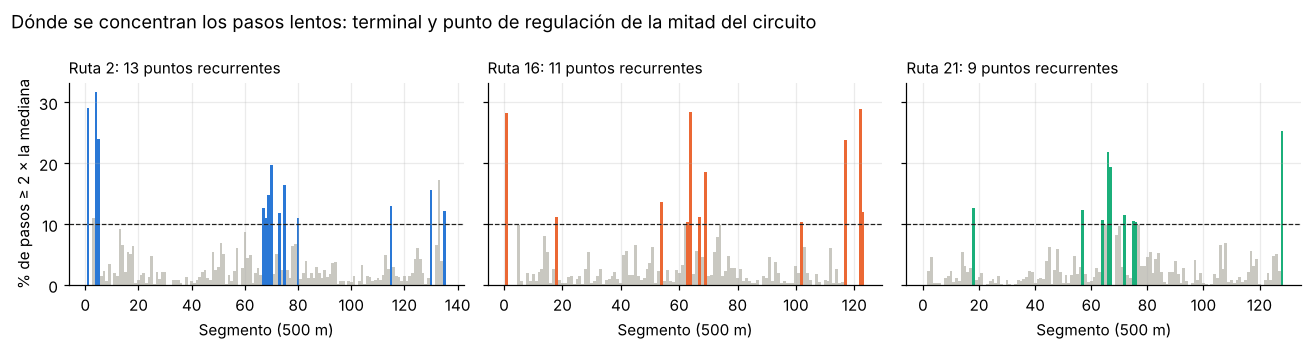

,puntos,segmentos
idruta,,
2,13,"1, 4, 5, 67, 68, 69, 70, 73, 75, 80, 115, 130,..."
16,11,"1, 18, 54, 63, 64, 67, 69, 102, 117, 122, 123"
21,9,"18, 57, 64, 66, 67, 72, 75, 76, 128"


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for a, r in zip(ax, (2, 16, 21)):
    g = lentos[lentos.idruta == r]
    a.bar(g.nro_segmento, g.pct_lentos, color=np.where(g.punto_recurrente, COL[r], "#c9c8c1"), width=1)
    a.axhline(10, color="#1f1f1d", lw=.8, ls="--")
    a.set_title(f"Ruta {r}: {int(g.punto_recurrente.sum())} puntos recurrentes", loc="left", fontsize=10)
    a.set_xlabel("Segmento (500 m)")
ax[0].set_ylabel("% de pasos ≥ 2 × la mediana")
fig.suptitle("Dónde se concentran los pasos lentos: terminal y punto de regulación de la mitad del circuito", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "m13_1_tramos_lentos.png", dpi=200, bbox_inches="tight"); plt.show()
display(lentos[lentos.punto_recurrente].groupby("idruta").agg(puntos=("nro_segmento", "size"),
        segmentos=("nro_segmento", lambda s: ", ".join(map(str, s)))))

**Conclusión 2 · Los tiempos del Módulo 12 sirven tal cual, y su variación tiene tres partes**
- **Cobertura completa:** 6.948 celdas (386 segmentos × 6 franjas × 3 tipos de día).
  - Recalculadas sin los 2 viajes de validación, difieren del Módulo 12 en un **0,039 %** en promedio.
  - La suma de los segmentos da el **97 %** de la vuelta mediana de la maestra (mediana; entre 79 % y 121 % según ruta × franja × día). La 13.2 la usa como chequeo.
- **La variación se sortea en tres partes:**
  - **Efecto de viaje:** hay viajes enteros más lentos (σ = 0,05–0,085 en escala logarítmica). Es lo que pega los buses unos con otros.
  - **Ruido por segmento:** σ = 0,19–0,25.
  - **La cola:** el 2,7 % de los pasos tarda ≥ 2 veces lo normal. De ellos, el **30 %** se concentra en **33 puntos recurrentes** (terminal y punto de regulación de la mitad del circuito): son esperas de la operación y se sortean en su segmento. El resto, **17 por cada 1.000 pasos** (unos 2 por vuelta), son trancones, que multiplican el tiempo del segmento por 2,4 en la mediana.

## 3 · Demanda: cuántos, a qué hora y dónde suben y bajan

In [7]:
print(json.dumps(man["info"]["calibracion"], indent=1, ensure_ascii=False))
dem = leer("demanda_hora_13_1.csv")
tot = dem.groupby(["idruta", "tipo_dia"]).agg(salidas=("salidas_dia", "sum"), pasajeros_pred=("pax_pred_dia", "sum"),
                                              pasajeros_real=("pax_real_dia", "sum"), dias=("n_dias", "first"))
tot["pred_vs_real_%"] = (100 * (tot.pasajeros_pred / tot.pasajeros_real - 1)).round(1)
display(tot.round(0))
ren = leer("renovacion_13_1.csv"); display(ren[ren.franja == "todas"].round(2))

{
 "viajes_muestra": 1673,
 "al_azar_con_pasos": 1441,
 "fuera_por_validacion": 2,
 "fuera_por_carga_imposible": 7,
 "viajes_calibracion": 1432,
 "pct_lecturas_fuera_ruta": 6.274277839097002,
 "pct_lecturas_ocupacion_mayor_1": 1.7355034240519065
}


salidas  pasajeros_pred  pasajeros_real  dias  pred_vs_real_%
idruta tipo_dia                                                                      
2      domingo_festivo    108.0          6279.0          5904.0    66             6.0
       laboral            159.0         13191.0         12755.0   239             3.0
       sabado             145.0         10260.0         10102.0    50             2.0
16     domingo_festivo    184.0         11123.0         10653.0    66             4.0
       laboral            290.0         25580.0         25423.0   239             1.0
       sabado             260.0         20437.0         20466.0    50            -0.0
21     domingo_festivo     65.0          4131.0          3811.0    66             8.0
       laboral             97.0          8653.0          8317.0   239             4.0
       sabado              91.0          6931.0          6670.0    50             4.0

,idruta,franja,n_viajes,factor_renovacion,carga_max_mediana,subidas_mediana
18,2,todas,471,2.48,32.0,79.0
19,16,todas,472,2.28,37.0,83.0
20,21,todas,489,2.56,32.0,83.0


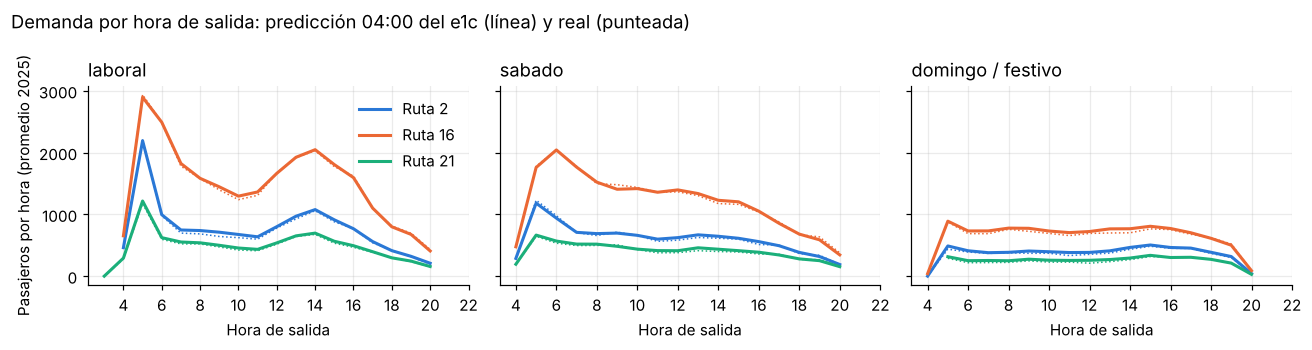

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for a, td in zip(ax, ("laboral", "sabado", "domingo_festivo")):
    for r in (2, 16, 21):
        g = dem[(dem.idruta == r) & (dem.tipo_dia == td)]
        a.plot(g.hora, g.pax_pred_dia, color=COL[r], lw=2, label=f"Ruta {r}")
        a.plot(g.hora, g.pax_real_dia, color=COL[r], lw=1, ls=":")
    a.set_title(td.replace("_", " / "), loc="left"); a.set_xlabel("Hora de salida"); a.set_xticks(range(4, 23, 2))
ax[0].set_ylabel("Pasajeros por hora (promedio 2025)"); ax[0].legend(frameon=False)
fig.suptitle("Demanda por hora de salida: predicción 04:00 del e1c (línea) y real (punteada)", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "m13_1_demanda_hora.png", dpi=200, bbox_inches="tight"); plt.show()

**¿Reproduce el modelo de subidas y bajadas la carga a bordo?** Con la fracción de subidas y la probabilidad de bajarse de cada segmento se calcula el perfil de carga esperado y se compara con el promedio de la muestra (en la misma muestra: es una prueba de consistencia, no de validación; la validación es la 13.4 con los días congelados).

,idruta,franja,viajes,correlacion,carga_media_modelo,carga_media_obs,error_media_%
0,2,madrugada,75,0.973,13.057,13.440,-2.851
1,2,noche,40,0.971,5.890,6.099,-3.414
2,2,pico_am,65,0.986,12.609,13.125,-3.932
3,2,pico_pm,40,0.970,9.082,9.062,0.225
4,2,valle_am,109,0.973,9.812,9.789,0.230
5,2,valle_pm,142,0.982,11.517,11.321,1.730
6,16,madrugada,51,0.963,13.870,14.515,-4.443
7,16,noche,21,0.979,7.543,7.627,-1.100
8,16,pico_am,74,0.984,12.800,13.563,-5.624
9,16,pico_pm,42,0.966,9.787,9.783,0.034


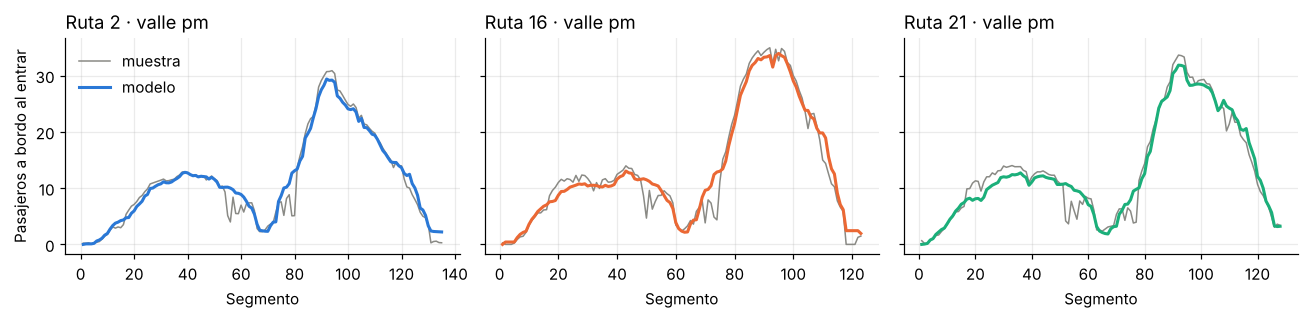

In [9]:
rep = leer("reparto_segmento_13_1.csv")
seg, red = P.red_segmentos(); reg_, ids_ = P.validacion()
mu = pd.read_parquet(P.ruta("lecturas_muestra"))
pids = set(pd.read_parquet(P.ruta("pasos_gps"), columns=["idprogramacion"]).idprogramacion)
cl, _ = P.calibracion(mu, pids, ids_)
ps = P.por_segmento(P.ubicar_lecturas(cl, red))
mm = pd.read_parquet(P.ruta("maestra"), columns=["idprogramacion", "fechasalida"])
ps = ps.merge(mm, on="idprogramacion"); ps["franja"] = P.gv.franja_de_hora(ps.fechasalida.dt.hour)
filas, perf = [], {}
for (r, fr), g in rep.groupby(["idruta", "franja"]):
    g = g.sort_values("nro_segmento"); c, prof = 0.0, []
    for sh, q in zip(g.fraccion_subidas, g.prob_bajada):
        prof.append(c); c = (c + sh) * (1 - q)
    o = ps[(ps.idruta == r) & (ps.franja == fr)]
    y = o.groupby("idprogramacion").subidas.sum().mean()
    ob = (o.groupby("nro_segmento").carga_in.sum() / o.idprogramacion.nunique() / y).reindex(g.nro_segmento).fillna(0).to_numpy()
    prof = np.array(prof); perf[(r, fr)] = (g.nro_segmento.to_numpy(), prof * y, ob * y)
    filas.append({"idruta": r, "franja": fr, "viajes": o.idprogramacion.nunique(), "correlacion": np.corrcoef(prof, ob)[0, 1],
                  "carga_media_modelo": prof.mean() * y, "carga_media_obs": ob.mean() * y})
chk = pd.DataFrame(filas); chk["error_media_%"] = 100 * (chk.carga_media_modelo / chk.carga_media_obs - 1)
display(chk.round(3))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.0), sharey=True)
for a, r in zip(ax, (2, 16, 21)):
    s, m_, o_ = perf[(r, "valle_pm")]
    a.plot(s, o_, color=GRIS, lw=1, label="muestra"); a.plot(s, m_, color=COL[r], lw=2, label="modelo")
    a.set_title(f"Ruta {r} · valle pm", loc="left"); a.set_xlabel("Segmento")
ax[0].set_ylabel("Pasajeros a bordo al entrar"); ax[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "m13_1_perfil_carga.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 3 · La demanda queda separada del plan: llegadas por segmento y hora**
- **Cuántos:** pasajeros por ruta × tipo de día × hora de salida, promedio de 355 días de 2025 (sin los de validación, sin Carnaval y sin días anómalos).
  - **Caso central:** la predicción 04:00 del e1c, entre **0 y 8 % por encima** de lo real según ruta y tipo de día.
  - **Alternativa:** los pasajeros reales.
  - **Salidas sin conteo:** las que operaron pero no quedaron como terminadas, o que el Módulo 1 dejó fuera de la maestra, llevan la media por salida de su hora. Son el 10–20 % de las salidas según ruta y tipo de día. La tabla guarda también la cota inferior sin ellas (`pax_*_solo_maestra_dia`), que la 13.4 usa como sensibilidad.
- **Dónde:** de los 1.432 viajes al azar de calibración, ubicados con el Viterbi del Módulo 10, salen la fracción de las subidas y la probabilidad de bajarse en cada segmento, por ruta × franja.
- **Llegadas:** juntando cuántos y dónde, quedan las llegadas por segmento × hora (pasajeros por hora). No dependen del plan de despachos, así que sirven para probar cualquier plan. Suman exactamente los pasajeros por día.
- **Consistencia:** con ese reparto, el perfil de carga a bordo reproduce el de la muestra:
  - correlación de 0,96 a 0,99 en las 18 combinaciones ruta × franja;
  - carga media entre −9,2 % y +1,7 %.

  Es una comprobación dentro de la misma muestra; la validación es la 13.4.
- **Factor de renovación** (subidas del viaje ÷ su carga máxima): 2,48 / 2,28 / 2,56 en las rutas 2 / 16 / 21.
- **Capacidad:** solo el 1,7 % de las lecturas tiene más pasajeros que la capacidad, así que la demanda observada casi no está recortada por buses llenos.

## 4 · Capacidad, descanso en la terminal y vuelta

In [10]:
cap = leer("capacidad_bus_13_1.csv")
display(cap.groupby("idruta_habitual").capacidad.describe().round(1))
print("Buses con más de una capacidad en 2025:", int((cap.capacidad_distintas > 1).sum()))
desc = leer("descanso_terminal_13_1.csv"); display(desc.round(1))
print("Encadenando todas las salidas de tb_despachos (no solo la maestra):", man["info"]["descanso"])
print("Salidas 2025 que operaron sin quedar terminadas:", f'{100 * (~pd.read_parquet(P.ruta("despachos"), columns=["fechasalida", "finalizado"]).query("fechasalida >= \'2025-01-01\' and fechasalida < \'2026-01-01\'").finalizado.astype(bool)).mean():.1f} %')
vt = leer("duracion_vuelta_13_1.csv"); display(vt[vt.tipo_dia == "laboral"].round(1))

,count,mean,std,min,25%,50%,75%,max
idruta_habitual,,,,,,,,
2,88.0,52.0,7.3,34.0,47.8,50.0,53.5,74.0
16,125.0,53.1,6.7,39.0,49.0,50.0,58.0,72.0
21,204.0,51.5,6.7,32.0,47.0,50.0,55.0,74.0


Buses con más de una capacidad en 2025: 0


,idruta,franja,n,p05,p25,mediana,p75,p95,media,pct_pausa,pct_negativo
0,2,noche,2229,10.3,15.5,23.3,37.6,65.4,28.8,9.4,0.0
1,2,pico_am,510,10.5,17.2,24.0,31.3,45.4,25.3,0.0,0.2
2,2,pico_pm,3220,9.9,16.8,27.4,42.0,71.9,32.2,15.0,0.0
3,2,valle_am,7479,13.0,22.0,30.8,42.7,65.5,34.0,0.8,0.0
4,2,valle_pm,9280,12.0,22.6,32.4,49.2,82.0,38.2,14.4,0.0
5,16,noche,3914,10.1,15.6,23.2,37.4,76.0,30.1,3.5,0.0
6,16,pico_am,1395,8.6,12.4,16.6,22.5,33.7,18.4,0.0,0.0
7,16,pico_pm,6900,9.8,15.5,23.1,35.2,66.9,28.8,7.6,0.0
8,16,valle_am,15221,12.7,21.2,30.0,41.4,64.9,33.0,0.8,0.0
9,16,valle_pm,21415,12.5,22.4,31.4,45.8,77.2,36.4,9.0,0.0


Encadenando todas las salidas de tb_despachos (no solo la maestra): {'pares_consecutivos': 87106, 'pares_solo_maestra': 91897, 'pares_que_saltaban_una_salida': 4791, 'pct_pausa_consecutivos': 9.959130255091498, 'pct_pausa_solo_maestra': 13.824172715104954}
Salidas 2025 que operaron sin quedar terminadas: 8.2 %


,idruta,tipo_dia,franja,n,p10,mediana,p90
6,2,laboral,madrugada,5143,174.7,223.6,270.7
7,2,laboral,noche,2004,165.2,180.3,196.4
8,2,laboral,pico_am,3955,234.4,262.5,289.5
9,2,laboral,pico_pm,2616,198.2,222.7,250.8
10,2,laboral,valle_am,7397,227.9,250.6,276.5
11,2,laboral,valle_pm,8471,242.7,272.5,304.0
24,16,laboral,madrugada,7703,161.7,197.8,246.4
25,16,laboral,noche,2989,153.6,166.8,180.8
26,16,laboral,pico_am,9939,217.6,247.7,271.6
27,16,laboral,pico_pm,5171,177.6,202.1,226.5


**Conclusión 4 · Descanso y vuelta salen de los datos, no de supuestos**
- **Descanso en la terminal** (inicio de una vuelta menos el fin de la anterior, mismo bus, día y ruta):

  | | Mediana | P5 (mínimo práctico) | Pausas > 2 h |
  |---|---|---|---|
  | Ruta 2 | 30,8 min | 11,6 min | 10 % |
  | Ruta 16 | 29,4 min | 11,4 min | 6 % |
  | Ruta 21 | 39,9 min | 19,3 min | 33 % |

  Las pausas (el bus sale de servicio un rato) se guardan aparte. Explican que la ruta 21 use 57 buses distintos al día para hacer el trabajo de unos 35 a la vez.
- **Salidas que no quedan como terminadas:** el 8,2 % de las salidas de 2025 operaron pero SOBUSA las marca como canceladas, por ejemplo cuando el bus parquea al final en un lugar alterno.
  - Por eso las vueltas se encadenan con todas las salidas de `tb_despachos`, no solo con las de la maestra.
  - Si no, el descanso saltaría por encima de la vuelta no terminada. Esto pasaba en 4.791 pares, que parecían pausas: las pausas eran 13,8 % en vez de 10,0 %.
  - Las medianas no cambian.
- **Vuelta:** entre 167 y 273 min de mediana en los laborales, según la franja. La más larga es la del valle de la tarde.
- **Capacidad:** 51,5–53,1 pasajeros por bus en promedio (sentados + de pie), fija para cada bus en todo 2025.

## 5 · Frecuencias del proyecto por el método de la carga máxima

**Fórmula** (Ceder, *Public Transit Planning and Operation*, método de la carga máxima):
`minutos entre salidas = 60 × capacidad × factor de carga ÷ pasajeros por hora en el punto de carga máxima`, con
pasajeros en el punto de carga máxima = pasajeros por hora de las salidas ÷ factor de renovación (subidas del viaje ÷ su
carga máxima, de la muestra). La **flota** que exige cada plan es el máximo de buses ocupados a la vez: cada salida ocupa un
bus durante su ciclo (vuelta mediana + descanso mediano). El mismo cálculo con las salidas reales da la flota del plan real.

In [11]:
frec = leer("frecuencias_estimadas_13_1.csv"); flo = leer("flota_por_plan_13_1.csv")
display(flo[flo.factor_carga == 0.85].round(1))
piv = flo.pivot_table(index=["idruta", "tipo_dia"], columns="factor_carga", values="flota_plan")
piv["real (estimada)"] = flo.groupby(["idruta", "tipo_dia"]).flota_real_estimada.first()
piv["buses reales/día"] = flo.groupby(["idruta", "tipo_dia"]).buses_real_dia_mediana.first()
display(piv)

,idruta,tipo_dia,factor_carga,flota_plan,flota_real_estimada,salidas_plan_dia,headway_plan_pico_min,horas_fuera_rango,buses_real_dia_mediana,salidas_real_dia_mediana
1,2,domingo_festivo,0.8,17,32,56.8,12.7,16,32.5,110.0
4,2,laboral,0.8,46,55,120.4,2.8,16,54.0,159.0
7,2,sabado,0.8,33,48,93.2,5.2,17,52.0,143.5
10,16,domingo_festivo,0.8,28,46,108.2,6.4,17,54.0,190.0
13,16,laboral,0.8,90,90,252.0,2.0,7,93.0,293.0
16,16,sabado,0.8,69,81,200.3,2.7,9,89.0,259.0
19,21,domingo_festivo,0.8,12,19,36.8,19.5,16,35.0,65.0
22,21,laboral,0.8,28,35,77.9,5.0,17,57.0,97.0
25,21,sabado,0.8,21,31,62.0,9.2,17,54.5,90.0


factor_carga              0.7  0.85   1.0  real (estimada)  buses reales/día
idruta tipo_dia                                                             
2      domingo_festivo   21.0  17.0  15.0               32              32.5
       laboral           56.0  46.0  39.0               55              54.0
       sabado            41.0  33.0  29.0               48              52.0
16     domingo_festivo   33.0  28.0  24.0               46              54.0
       laboral          109.0  90.0  76.0               90              93.0
       sabado            84.0  69.0  59.0               81              89.0
21     domingo_festivo   14.0  12.0  10.0               19              35.0
       laboral           34.0  28.0  24.0               35              57.0
       sabado            25.0  21.0  18.0               31              54.5

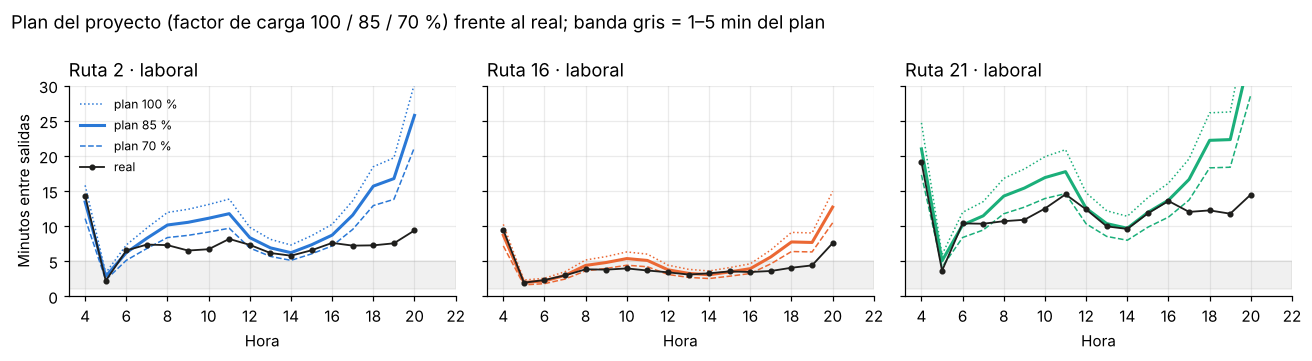

Horas del plan central fuera de 1–5 min: {'mayor_5_min': 132, 'dentro': 19, 'sin_demanda': 1}
Horas del plan REAL fuera de 1–5 min: 110 de 152


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
for a, r in zip(ax, (2, 16, 21)):
    g = frec[(frec.idruta == r) & (frec.tipo_dia == "laboral")]
    for f, ls in ((1.0, ":"), (0.85, "-"), (0.70, "--")):
        x = g[g.factor_carga == f]
        a.plot(x.hora, x.headway_min, color=COL[r], ls=ls, lw=2 if f == 0.85 else 1, label=f"plan {int(100*f)} %")
    x = g[g.factor_carga == 0.85]
    a.plot(x.hora, x.headway_real_min, color="#1f1f1d", lw=1.2, marker=".", label="real")
    a.axhspan(1, 5, color=GRIS, alpha=.12)
    a.set_title(f"Ruta {r} · laboral", loc="left"); a.set_xlabel("Hora"); a.set_ylim(0, 30); a.set_xticks(range(4, 23, 2))
ax[0].set_ylabel("Minutos entre salidas"); ax[0].legend(frameon=False, fontsize=8)
fig.suptitle("Plan del proyecto (factor de carga 100 / 85 / 70 %) frente al real; banda gris = 1–5 min del plan", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "m13_1_frecuencias.png", dpi=200, bbox_inches="tight"); plt.show()
x = frec[(frec.factor_carga == 0.85)]
print("Horas del plan central fuera de 1–5 min:", x.fuera_rango_plan.value_counts().to_dict())
print("Horas del plan REAL fuera de 1–5 min:", int(((x.headway_real_min < 1) | (x.headway_real_min > 5)).sum()), "de", len(x))

**Conclusión 5 · El proyecto ya tiene su propio plan de salidas, con la flota que exige**
- **El método de la carga máxima reproduce bien la operación de la ruta 16:** con factor de carga 85 %, en las horas pico da los mismos minutos entre salidas que hoy (2,0 vs 1,9 min a las 5 h; 3,0 vs 3,0 a las 7 h). En el valle y en la noche pide menos salidas.
- **Flota del plan central (85 %) frente a la del plan real**, en laboral (la del plan real se calcula con el mismo método, que da 55 y 90 buses en las rutas 2 y 16 frente a 54 y 93 que de verdad se usan):

  | | Plan 85 % | Plan real (mismo cálculo) | Salidas al día (plan / real) |
  |---|---|---|---|
  | Ruta 2 | 46 buses | 55 | 120 / 159 |
  | Ruta 16 | 90 | 90 | 252 / 293 |
  | Ruta 21 | 28 | 35 | 78 / 97 |

  **Los fines de semana la diferencia es mayor:** por ejemplo, la ruta 2 el domingo necesitaría 17 buses en lugar de 32. Hoy SOBUSA mantiene una frecuencia mínima que la demanda sola no pide.
- **El rango de 1 a 5 min del plan es solo una referencia:** el propio plan real queda por fuera en 110 de 152 horas. Se cumple en la ruta 16 de día, pero no en las rutas 2 y 21, que salen cada 6 a 12 min.
- **Los tres planes (100 / 85 / 70 %)** quedan listos para la 13.4. En ella, el simulador dirá cuánta espera y cuánto hacinamiento produce cada uno. Por ahora es un cálculo estático, sin buses pegados ni incidentes.

## 6 · Incidentes: señal, tasa e intervalo

In [13]:
inc = leer("incidentes_13_1.csv")
display(inc[["tipo", "unidad", "tasa_baja", "tasa_central", "tasa_alta", "efecto", "duracion_central_min", "rotulo"]].round(3))
print(json.dumps(man["info"]["incidentes"], indent=1, ensure_ascii=False))
vb = leer("varada_bus_13_1.csv"); print("Probabilidad de varada por bus:", vb.p_varada_jornada.describe().round(4).to_dict(),
                                        "· fuente:", vb.fuente.value_counts().to_dict())

,tipo,unidad,tasa_baja,tasa_central,tasa_alta,efecto,duracion_central_min,rotulo
0,trancon,por 1.000 pasos por segmento,16.403,17.145,17.915,× 2.40 el tiempo del segmento (mediana),30,dato
1,obra,por 1.000 viajes,32.075,41.201,52.782,8.6 min fuera de la ruta (mediana),180,dato
2,arroyo,por 1.000 días,0.913,21.903,161.533,bloqueo del tramo inundable (severidad 5) mien...,60,dato (lluvia) + supuesto (que la lluvia forme ...
3,varado,por 1.000 buses-día,9.737,12.333,14.708,el bus sale de servicio por el resto del día,30,dato (proxy del Módulo 9)
4,evento,por año,3.048,5.333,8.661,demanda e impacto según el porcentaje de SOBUS...,120,dato
5,choque,por ruta-día,0.100,0.300,0.600,colisión que bloquea un carril o la vía,45,supuesto
6,bloqueo,por ruta-día,0.010,0.030,0.080,protesta o cierre no programado,90,supuesto
7,semaforo,por ruta-día,0.050,0.150,0.300,semáforo apagado o intermitente en el corredor,20,supuesto


{
 "desvios": {
  "episodios_viajes_al_azar": 395,
  "episodios_transitorios": 64,
  "viajes_con_transitorio": 59,
  "zonas_transitorias": 13,
  "meses_activos_media": 2.923076923076923,
  "zonas_permanentes": [
   "Z1",
   "Z2",
   "Z3",
   "Z4"
  ],
  "minutos_fuera_p90": 16.155000000000005
 },
 "lluvia": {
  "dias_por_umbral": {
   "20.0": 1,
   "10.0": 24,
   "5.0": 177
  },
  "anios": 3,
  "horas_por_mes_10mm": {
   "3": 1,
   "5": 7,
   "6": 3,
   "7": 1,
   "9": 3,
   "10": 4,
   "11": 9
  }
 },
 "varada": {
  "por_anio": {
   "2023": 0.009736932012299283,
   "2024": 0.01263308324401572,
   "2025": 0.014708480565371026
  },
  "ic95_central": [
   11.867640304092394,
   12.816095276548772
  ]
 },
 "eventos": {
  "PARTIDO_SELECCION": 8,
  "GUACHERNA": 3,
  "BATALLA_FLORES": 3,
  "CONCIERTO": 2
 }
}
Probabilidad de varada por bus: {'count': 417.0, 'mean': 0.0185, 'std': 0.0143, 'min': 0.0059, '25%': 0.0116, '50%': 0.0138, '75%': 0.0193, 'max': 0.1063} · fuente: {'m9': 331, 'mediana

**Consulta de `vehiculos.ultimoevento` e `indexevento` (E1, aprobada por la Persona 3).**

In [14]:
e1 = pd.read_csv(D / "extraccion/e1_vehiculos_ultimoevento.csv")
print(f"{len(e1)} buses · {e1.ultimoevento.notna().sum()} con ultimoevento · {e1.ultimoevento.nunique()} códigos distintos")
display(e1.ultimoevento.value_counts().head(10).rename("buses").to_frame().T)
print("indexevento:", e1.indexevento.describe()[["min", "50%", "max"]].to_dict())

656 buses · 654 con ultimoevento · 29 códigos distintos


ultimoevento,3.0,2.0,109.0,6.0,349.0,10.0,69.0,21.0,119.0,0.0
buses,181,174,89,50,31,24,21,20,8,7


indexevento: {'min': 31359369.0, '50%': 3703161999.0, 'max': 3703169018.0}


**Conclusión 6 · Cinco de los ocho tipos de incidente tienen señal en los datos**
- **Con señal (tasa central e intervalo):**

  | Tipo | Señal | Tasa central (baja – alta) |
  |---|---|---|
  | Trancón | Exceso de pasos lentos (GPS) | 17,1 por 1.000 pasos (16,4 – 17,9) |
  | Obra o cierre | Desvíos del GPS fuera de las zonas permanentes Z1–Z4 | 41 por 1.000 viajes (32 – 53); 8,6 min fuera de la ruta |
  | Arroyo | Días con una hora de lluvia ≥ 10 mm (≥ 20 / ≥ 5 mm) | 21,9 por 1.000 días (0,9 – 162) |
  | Varada | Etiqueta del Módulo 9 | 12,3 por 1.000 buses-día (9,7 en 2023 – 14,7 en 2025) |
  | Evento masivo | Calendario de SOBUSA sin Carnaval | 5,3 por año (3,0 – 8,7) |

- **Sin señal: choque, bloqueo y semáforo.** La base registra 0 incidentes de esos tipos. Quedan como **supuestos rotulados** con un rango amplio (por ruta-día: choque 0,1–0,6, bloqueo 0,01–0,08, semáforo 0,05–0,30), que la 13.4 prueba como sensibilidad.
- **Varada por bus:** probabilidad del Módulo 9 para 331 buses; los 86 sin score llevan la mediana de la flota.
- **Diagnóstico del rótulo de varada:** se revisó en los días de validación sin cambiar ningún parámetro. Las 17 varadas del Módulo 9 de esos días son últimos viajes que en el GPS cubren a lo sumo el 42 % de los segmentos, y la mayoría termina junto a la terminal. El rótulo es coherente con el GPS. Lo que no puede distinguir es una varada de un bus que se retira temprano a un parqueadero alterno (H11).
- **`vehiculos.ultimoevento`** (consulta E1, aprobada) trae un código numérico del último evento del equipo a bordo (29 códigos distintos en 654 buses), sin catálogo ni historia. No sirve para contar incidentes. Queda documentado y cierra esa pregunta de la 13.1.

## 7 · Entorno y reproducibilidad

In [15]:
print("Python", sys.version.split()[0])
print(json.dumps(man["info"]["config"], indent=1, ensure_ascii=False))
print("Días que alimentan demanda, plan y descanso:", man["info"]["dias_parametros"])
display(pd.DataFrame([{"salida": n, "filas": d["filas"], "sha256": d["sha256"][:12]} for n, d in man["salidas"].items()]))

Python 3.13.16
{
 "anio": 2025,
 "ratio_lento": 2.0,
 "alfa_reparto": 500.0,
 "alfa_bajada": 200.0,
 "factores_carga": [
  1.0,
  0.85,
  0.7
 ],
 "factor_central": 0.85,
 "rango_plan_min": [
  1.0,
  5.0
 ],
 "descanso_max_min": 120.0,
 "hora_min": 4,
 "hora_max": 22,
 "lluvia_umbrales_mm_h": [
  20.0,
  10.0,
  5.0
 ],
 "zonas_permanentes": [
  "Z1",
  "Z2",
  "Z3",
  "Z4"
 ],
 "hora_limite_varada": 16,
 "min_viajes_sigma": 30,
 "min_pasos_recurrente": 30,
 "pct_recurrente": 10.0,
 "semilla": 42
}
Días que alimentan demanda, plan y descanso: {'domingo_festivo': 66, 'laboral': 239, 'sabado': 50}


,salida,filas,sha256
0,cola_lentos_13_1.csv,51,26e3e5feb04b
1,factor_lluvia_13_1.csv,5,0a2d2a6f1e93
2,tiempos_segmento_13_1.csv,6948,fbe1dc83d4bd
3,dispersion_tiempos_13_1.csv,18,4be416936275
4,tramos_lentos_segmento_13_1.csv,380,2e11dc27f986
5,reparto_segmento_13_1.csv,2316,0655d56a6ac3
6,renovacion_13_1.csv,21,298c2c74509f
7,demanda_hora_13_1.csv,153,ac94a5672207
8,llegadas_segmento_hora_13_1.parquet,19607,3bfb006412ce
9,capacidad_bus_13_1.csv,417,5a3e20ec9c58


**Conclusión 7 · Todo queda congelado y reproducible, también en Python 3.12**
- **Manifiesto** (`manifiesto_parametros_13_1.json`): 21 salidas y 21 insumos, cada uno con su hash. Tres tablas son enmiendas del 4-nov-2026: `cola_lentos_13_1.csv` (cuantiles de la razón de los pasos lentos, en la 13.2, E10), `factor_lluvia_13_1.csv` (cuánto se alargan los tiempos con lluvia, en la 13.3) y `variacion_dia_13_1.csv` (variación de la demanda entre días del mismo tipo, en la 13.4). Al agregar cada una, las demás tablas salieron con el mismo hash.
- **`tests_13_1.py`: 12/12.**
- **Python 3.12:**
  - Construir los parámetros en Python 3.12 da tablas con contenido idéntico al de Python 3.13.
  - El Módulo 12 carga y reenruta en Python 3.12 (11,5 s la carga, una vez), así que la 13.3 puede llamarlo directamente.
- **Sin APIs y sin base de datos:** la única consulta fue la Parte 1 (`extraer_13_1.py`, solo lectura), que corrió la Persona 3.

## Síntesis
La 13.1 deja al simulador todo lo que necesita, con fuente y hash:
- **Tiempos:** de los 386 segmentos, con su variación separada en viaje, segmento, esperas recurrentes y trancones.
- **Demanda:** independiente del plan, con dónde sube y dónde baja la gente.
- **Operación:** capacidad, descanso y vuelta, sacados de los datos.
- **Planes de salidas:** el real y uno del proyecto por carga máxima, en tres variantes con su flota.
- **Incidentes:** ocho tipos, cinco con señal en los datos y tres supuestos rotulados.

Los seis días de validación quedaron congelados antes de escribir una sola línea del motor, con sus casi un millón de lecturas limpias. **Siguiente: la 13.2, el motor de eventos discretos en SimPy**, que primero debe reproducir un día típico con el plan real antes de pasar a los imprevistos (13.3).

---
# Parte 12 · Módulo 13 · Subfase 13.2 · Motor de simulación
*Notebook original: `modulo13/subfase_13_2_motor.ipynb`*

# SOBUSA · Módulo 13 · Subfase 13.2 — Motor de eventos discretos (SimPy)

**Persona 3.** El motor simula un día completo de las rutas 2, 16 y 21 con buses, pasajeros y terminal, solo con los
parámetros congelados de la 13.1. Alcance aprobado: `revisiones/alcance_13_2.md`. Todavía sin imprevistos (13.3) y sin
tocar los días de validación (13.4).

| Pieza | Qué hace | Dónde |
|---|---|---|
| Motor | Buses que recorren su circuito segmento a segmento; pasajeros que llegan al azar y suben al primer bus con cupo; bajadas por segmento; descanso en la terminal | `src/simulation/motor.py` |
| Escenarios | Día, plan (real o del proyecto), demanda (e1c o real), semilla; carga los parámetros comprobando su hash | `src/simulation/escenario.py` |
| Calibración | Factor por ruta × tipo de día × franja de salida para que la vuelta simulada sea la de la maestra | `src/simulation/calibracion.py` |
| Evaluación | Criterios de aceptación del alcance | `src/simulation/evaluacion.py` |

**Días.** Se desarrolla y calibra con el tercer día más típico de 2025 de cada tipo, y se comprueba con el cuarto (días
de control). Ninguno es de validación.

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, ".")
from src.simulation import escenario as E, evaluacion as V
from src.simulation.motor import FRANJAS

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
SAL = E.SAL; FIG = Path("resultados_13"); FIG.mkdir(exist_ok=True)
COL = {2: "#2a78d6", 16: "#eb6834", 21: "#1baf7a"}; GRIS = "#8a8a85"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "font.size": 10, "figure.dpi": 110})
man = json.loads((SAL / "manifiesto_simulacion_13_2.json").read_text(encoding="utf-8"))
print("Corridas:", man["creado"], "·", man["replicas"], "réplicas por escenario · parámetros de la 13.1 del", man["manifiesto_13_1"])
print("Días de desarrollo (calibración):", man["dias_desarrollo"]); print("Días de control:", man["dias_control"])
print("Tablas que cambiaron desde el manifiesto:", [n for n, d in man["salidas"].items() if E._sha(SAL / n) != d["sha256"]])
R = V.resumen()

Corridas: 2026-11-04T20:57:56 · 30 réplicas por escenario · parámetros de la 13.1 del 2026-11-04T20:17:54
Días de desarrollo (calibración): {'laboral': '2025-02-27', 'sabado': '2025-03-22', 'domingo': '2025-03-23'}
Días de control: {'laboral': '2025-08-19', 'sabado': '2025-09-20', 'domingo': '2025-11-09'}
Tablas que cambiaron desde el manifiesto: []


## 1 · El plan real que se simula

Se simulan **todas** las salidas de `tb_despachos` del día, también las que operaron sin quedar terminadas.

**Asignación «mismo bus con reemplazo»** (por defecto): el conductor opera el mismo bus toda la jornada (Persona 3), así
que cada salida la hace su bus del día. Si a la hora de salida ese bus todavía no ha vuelto, la toma un bus libre de los
que operaron la ruta ese día, como un bus de reemplazo.

Hace falta el reemplazo porque el 4,3 % de las salidas de 2025 va seguida de otra del mismo bus antes de 150 min, menos de
lo que dura la vuelta más corta. Son vueltas cortadas o parciales que el motor no conoce. Se comparan las tres asignaciones.

In [2]:
from src.simulation import escenario as E
fil = []
for a in ("reemplazo", "secuencia", "dinamica"):
    for s in range(5):
        v = E.correr(E.Escenario(man["dias_desarrollo"]["laboral"], asignacion=a, semilla=2000 + s)).viajes
        fil.append({"asignacion": a, "semilla": s, "salidas": len(v), "retraso_>10_min_%": 100 * (v.retraso_salida_min > 10).mean(),
                    "con_su_bus_%": 100 * v.bus_propio.mean() if v.bus_propio.notna().any() else np.nan,
                    "retraso_p95_min": v.retraso_salida_min.quantile(.95), "veces_sin_cupo_por_100_subidas": 100 * v.negados.sum() / v.subidas.sum()})
display(pd.DataFrame(fil).groupby("asignacion").mean(numeric_only=True).round(2))
d = pd.read_parquet(E.SOBUSA / "maestras/tb_despachos.parquet", columns=["idvehiculo", "idruta", "fechasalida"])
d = d[(d.fechasalida >= "2025-01-01") & (d.fechasalida < "2026-01-01")].sort_values(["idvehiculo", "fechasalida"])
gap = (d.groupby([d.idvehiculo, d.fechasalida.dt.normalize()]).fechasalida.shift(-1) - d.fechasalida).dt.total_seconds() / 60
print(f"Salidas de 2025 seguidas de otra del mismo bus antes de 150 min: {100 * (gap < 150).sum() / gap.notna().sum():.1f} %")
print("Con su propio bus, en las 30 réplicas de cada día:", {n: round(100 * V.leer(n, "viajes").bus_propio.mean(), 1) for n in V.ESCENARIOS_REAL})
m = pd.read_parquet(E.SOBUSA / "maestras/tb_maestra_entrenamiento.parquet", columns=["idprogramacion", "fechafin"])
d2 = pd.read_parquet(E.SOBUSA / "maestras/tb_despachos.parquet", columns=["idprogramacion", "idvehiculo", "idruta", "fechasalida"])
d2 = d2[(d2.fechasalida >= "2025-01-01") & (d2.fechasalida < "2026-01-01")].merge(m, on="idprogramacion", how="left").sort_values(["idvehiculo", "fechasalida"])
g2 = d2.groupby([d2.idvehiculo, d2.fechasalida.dt.normalize()])
d2["descanso_hasta_salida_programada"] = (d2.fechasalida - g2.fechafin.shift()).dt.total_seconds() / 60
y = d2[(g2.idruta.shift() == d2.idruta) & d2.descanso_hasta_salida_programada.between(0, 120)]
print("Descanso hasta la salida programada (min, 2025):"); display(y.groupby("idruta").descanso_hasta_salida_programada.quantile([.05, .25, .5, .75, .95]).unstack().round(0))
print(f"Entre 40 y 90 min: {100 * y.descanso_hasta_salida_programada.between(40, 90).mean():.0f} %")

,semilla,salidas,retraso_>10_min_%,con_su_bus_%,retraso_p95_min,veces_sin_cupo_por_100_subidas
asignacion,,,,,,
dinamica,2.0,557.0,0.00,NaN,0.0,14.22
reemplazo,2.0,557.0,0.00,85.85,0.0,13.08
secuencia,2.0,557.0,14.33,NaN,71.3,12.94


Salidas de 2025 seguidas de otra del mismo bus antes de 150 min: 4.3 %
Con su propio bus, en las 30 réplicas de cada día: {'real_laboral': np.float64(85.1), 'real_sabado': np.float64(85.2), 'real_domingo': np.float64(87.2), 'control_laboral': np.float64(85.8), 'control_sabado': np.float64(89.5), 'control_domingo': np.float64(87.4)}


Descanso hasta la salida programada (min, 2025):


,0.05,0.25,0.50,0.75,0.95
idruta,,,,,
2,16.0,27.0,38.0,51.0,78.0
16,16.0,26.0,36.0,49.0,77.0
21,18.0,28.0,38.0,51.0,80.0


Entre 40 y 90 min: 40 %


**Conclusión 1 · El plan real se simula completo, cada salida con su bus del día**
- **Qué se simula:** todas las salidas de `tb_despachos` del día, también las que operaron sin quedar terminadas. En el laboral de desarrollo (27-feb-2025) son 557: 164 / 297 / 96 en las rutas 2 / 16 / 21, con 59 / 99 / 59 buses.
- **Mismo bus todo el día, con reemplazo:**
  - el conductor opera el mismo bus toda la jornada (Persona 3), así que cada salida la hace su bus;
  - si a la hora de salida ese bus todavía no ha vuelto, la toma un bus libre del día;
  - así, el 85–89 % de las salidas las hace su propio bus y ninguna sale con más de 10 min de retraso.
- **Por qué hace falta el reemplazo:** el 4,3 % de las salidas de 2025 va seguida de otra del mismo bus antes de 150 min, menos de lo que dura la vuelta más corta. Son vueltas cortadas o parciales que el motor no conoce. Si cada bus esperara siempre su secuencia, el 14,3 % de las salidas saldría con más de 10 min de retraso (P95: 72 min), porque los retrasos se encadenan.
- **Descanso:** el plan real ya trae los descansos en sus horas de salida. Hasta la salida programada, la mediana es de 36–38 min (P25–P75: 26–51 min); el 40 % de los descansos está entre 40 y 90 min, el rango que describen los conductores. El motor solo usa un mínimo (P5: 11–19 min) cuando un bus vuelve tarde.

## 2 · Calibración de la vuelta

Factores: {'min': 0.82, '50%': 0.947, 'max': 1.048}
Error antes de calibrar (|%|): {'50%': 5.0, 'max': 20.8} · después: {'50%': 0.7, 'max': 3.1}


franja_salida           madrugada  pico_am  valle_am  valle_pm  pico_pm  noche
tipo_dia        idruta                                                        
domingo_festivo 2           0.885    0.950     1.005     0.979    0.939  0.923
                16          0.820    0.909     0.945     0.950    0.929  0.893
                21          0.939    0.943     0.965     0.943    0.943  0.876
laboral         2           0.911    1.032     0.992     1.048    0.993  0.849
                16          0.891    1.007     0.975     1.021    0.929  0.857
                21          0.900    1.011     0.984     1.036    1.019  0.859
sabado          2           0.933    0.992     1.023     0.979    0.978  0.891
                16          0.934    1.009     1.037     0.951    0.972  0.916
                21          0.923    1.030     1.034     0.926    0.956  0.879

Variación de la vuelta (P90 − P10) simulada ÷ real, por ruta × franja (6 días): {'25%': 1.1, '50%': 1.17, '75%': 1.32}


real_laboral  real_sabado  real_domingo  control_laboral  control_sabado  control_domingo
idruta franja                                                                                              
2      madrugada          0.66         1.32          1.66             0.68            1.31             1.68
       noche              1.54         1.12          1.49             1.51            1.18             1.50
       pico_am            1.29         1.34          1.69             1.14            1.29             1.80
       pico_pm            1.15         1.23          1.25             1.17            1.19             1.16
       valle_am           1.12         1.10          1.19             1.21            1.10             1.18
       valle_pm           1.14         1.20          1.35             1.13            1.22             1.32
16     madrugada          0.76         1.07          1.45             0.77            1.08             1.41
       noche              1.48         1.16          1.12             1.46            1.12             1.00
       pico_am            1.15         1.18          1.72             1.15            1.13             1.72
       pico_pm            1.01         1.08          1.11             0.97            1.10             1.10
       valle_am           1.41         1.22          1.25             1.41            1.25             1.19
       valle_pm           1.14         1.19          1.17             1.13            1.14             1.16
21     madrugada          0.66         1.19          2.35             0.63            1.12             2.34
       noche              1.03         1.02          1.11             1.07            1.04             1.18
       pico_am            0.97         1.01          1.86             0.93            1.02             1.92
       pico_pm            1.09         1.32          1.36             1.05            1.40             1.32
       valle_am           1.17         1.03          1.28             1.10            1.10             1.22
       valle_pm           1.14         1.25          1.64             1.09            1.21             1.64

Celdas a ±5 % de la maestra: {'control_domingo': {'sum': 18, 'size': 18}, 'control_laboral': {'sum': 18, 'size': 18}, 'control_sabado': {'sum': 18, 'size': 18}, 'real_domingo': {'sum': 18, 'size': 18}, 'real_laboral': {'sum': 18, 'size': 18}, 'real_sabado': {'sum': 18, 'size': 18}}


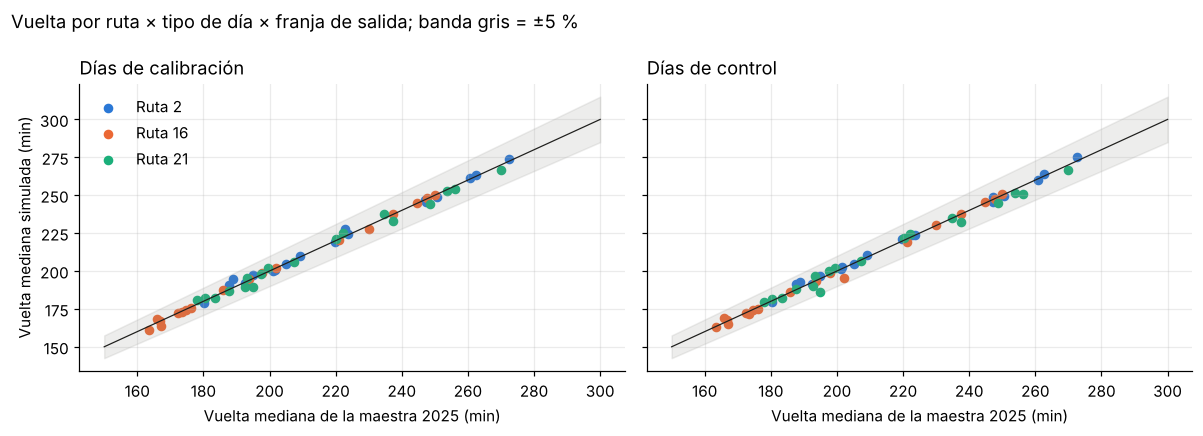

In [3]:
fac = pd.read_csv(SAL / "factores_vuelta_13_2.csv")
print("Factores:", fac.factor.describe()[["min", "50%", "max"]].round(3).to_dict())
print("Error antes de calibrar (|%|):", fac.error_antes_pct.abs().describe()[["50%", "max"]].round(1).to_dict(),
      "· después:", fac.error_despues_pct.abs().describe()[["50%", "max"]].round(1).to_dict())
display(fac.pivot_table(index=["tipo_dia", "idruta"], columns="franja_salida", values="factor").round(3)[list(FRANJAS)])
P = E.cargar_parametros(); vt = P["duracion_vuelta_13_1.csv"]; filas = []
for n in V.ESCENARIOS_REAL:
    v = V.leer(n, "viajes"); q = v.groupby(["idruta", "franja_salida"]).vuelta_min.quantile([.1, .9]).unstack()
    o = vt[vt.tipo_dia == V.tipo_de(n)].set_index(["idruta", "franja"])[["p10", "p90"]]; q.index.names = ["idruta", "franja"]
    x = q.join(o); filas.append(((x[0.9] - x[0.1]) / (x.p90 - x.p10)).rename(n))
anch = pd.concat(filas, axis=1)
print("Variación de la vuelta (P90 − P10) simulada ÷ real, por ruta × franja (6 días):",
      anch.stack().describe()[["25%", "50%", "75%"]].round(2).to_dict())
display(anch.round(2))
vu = R["vuelta"]
print("Celdas a ±5 % de la maestra:", vu.assign(ok=vu.error_pct.abs() <= 5).groupby("escenario").ok.agg(["sum", "size"]).to_dict("index"))
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, pref, tit in zip(ax, ("real_", "control_"), ("Días de calibración", "Días de control")):
    x = vu[vu.escenario.str.startswith(pref)]
    for r in (2, 16, 21):
        y = x[x.idruta == r]
        a.scatter(y.vuelta_maestra, y.vuelta_sim, color=COL[r], s=28, label=f"Ruta {r}")
    lo, hi = 150, 300
    a.plot([lo, hi], [lo, hi], color="#1f1f1d", lw=.8); a.fill_between([lo, hi], [lo * .95, hi * .95], [lo * 1.05, hi * 1.05], color=GRIS, alpha=.15)
    a.set_title(tit, loc="left"); a.set_xlabel("Vuelta mediana de la maestra 2025 (min)")
ax[0].set_ylabel("Vuelta mediana simulada (min)"); ax[0].legend(frameon=False)
fig.suptitle("Vuelta por ruta × tipo de día × franja de salida; banda gris = ±5 %", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "m13_2_vuelta.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 2 · La vuelta: su mediana y su variación, también en días que no se usaron para calibrar**
- **Dos correcciones a la variación de los tiempos**, encontradas al revisar la cola de las vueltas:
  - **Cola empírica de los pasos lentos:** la razón de un paso lento se sortea de sus cuantiles observados, de ×2 al P99 (`cola_lentos_13_1.csv`, enmienda E10 de la 13.1). Antes era una lognormal ajustada con dos valores, que daba vueltas de más de 8 h.
  - **Zona de terminal:** la espera del bus en los 6 primeros y 6 últimos segmentos es parte del descanso, no de la vuelta (E9).
- **Calibración:** sin ella, la vuelta queda a 5,0 % de la real en la mediana. Solo la madrugada y la noche se alejan, hasta 21 %, porque una vuelta de 3 a 4 h cruza franjas con ritmos distintos; los viajes que salen de noche ya iban ~9 % más rápido en los datos GPS.
  - El factor por ruta × tipo de día × franja de salida va de 0,82 a 1,05 (mediana 0,95).
  - En el día va de 0,91 a 1,05 y está cerca de 1; en la madrugada y la noche, su mediana es 0,91 y 0,88.
- **Resultado:** la vuelta mediana queda a ±5 % en **108/108** celdas: 54 de calibración y 54 en los días de control, con otro plan real.
- **Las vueltas varían:** la diferencia entre la vuelta rápida y la lenta (P10–P90) es un 17 % mayor que la real en la mediana de las 108 celdas. El motor varía un poco más de lo que pasa en la calle. En la 13.3 se le suman los imprevistos (trancones, bloqueos, lluvia), que son los que hacen las vueltas más largas.

## 3 · Pasajeros: cuántos suben, dónde va la gente y cuánto espera

In [4]:
display(R["pasajeros"].round(2))
display(R["perfil"].round(3))
sv = R["servicio"]
display(sv[["escenario", "idruta", "llegados_rep", "pct_sin_subir_con_servicio", "pct_sin_servicio", "pct_dejados_bus_lleno",
            "espera_media_min", "espera_p90_min", "pct_viajes_bus_lleno", "conserva"]].round(2))

,idruta,sim,esperado_dia,esperado_promedio,error_pct,dif_vs_promedio_pct,escenario
0,2,80.02,80.43,83.44,-0.51,-4.10,real_laboral
1,16,85.95,86.13,89.15,-0.21,-3.60,real_laboral
2,21,89.49,90.13,88.17,-0.71,1.49,real_laboral
0,2,71.96,72.25,71.94,-0.41,0.02,real_sabado
1,16,82.28,82.41,79.20,-0.16,3.89,real_sabado
2,21,78.08,78.77,75.52,-0.87,3.39,real_sabado
0,2,52.07,52.32,57.87,-0.49,-10.03,real_domingo
1,16,62.94,63.33,60.81,-0.61,3.51,real_domingo
2,21,64.78,65.57,63.40,-1.20,2.17,real_domingo
0,2,80.68,80.93,80.21,-0.31,0.58,control_laboral


,idruta,correlacion,carga_media_sim,carga_media_muestra,celdas,viajes_muestra,error_media_pct,escenario
0,2,0.929,9.648,11.053,810,345,-12.712,real_laboral
1,16,0.898,12.479,13.066,697,329,-4.491,real_laboral
2,21,0.929,10.955,11.344,768,368,-3.435,real_laboral
0,2,0.770,10.094,9.837,673,58,2.613,real_sabado
1,16,0.929,12.483,13.489,580,81,-7.457,real_sabado
2,21,0.919,10.396,9.760,638,64,6.517,real_sabado
0,2,0.880,6.797,6.663,536,58,2.022,real_domingo
1,16,0.884,9.531,8.963,464,57,6.339,real_domingo
2,21,0.841,7.925,8.723,640,54,-9.147,real_domingo
0,2,0.930,10.451,11.053,810,345,-5.444,control_laboral


,escenario,idruta,llegados_rep,pct_sin_subir_con_servicio,pct_sin_servicio,pct_dejados_bus_lleno,espera_media_min,espera_p90_min,pct_viajes_bus_lleno,conserva
0,real_laboral,2,13187.67,0.00,0.48,4.23,5.63,12.61,18.23,True
1,real_laboral,16,25608.70,0.00,0.32,7.26,3.79,8.51,26.12,True
2,real_laboral,21,8639.83,0.00,0.56,6.15,9.70,20.96,24.17,True
0,real_sabado,2,10278.87,0.01,0.58,3.77,6.95,15.27,11.85,True
1,real_sabado,16,20471.20,0.00,0.33,4.61,3.81,8.50,19.64,True
2,real_sabado,21,6929.97,0.00,0.85,2.72,9.09,20.16,12.95,True
0,real_domingo,2,6294.73,0.01,0.73,0.52,6.26,13.66,2.78,True
1,real_domingo,16,11115.53,0.04,0.87,1.69,4.38,9.52,7.52,True
2,real_domingo,21,4127.83,0.11,1.02,1.39,10.83,23.14,6.61,True
0,control_laboral,2,13187.67,0.00,0.28,5.76,6.14,14.06,20.70,True


**Techo de la comparación del perfil.** La muestra de fin de semana tiene pocos viajes (54 a 84 por ruta), así que su propio perfil es ruidoso. Partiéndola en dos mitades al azar se estima la correlación máxima que se puede esperar (Spearman-Brown).

In [5]:
from src.simulation import parametros as Pm
reg, ids = Pm.validacion(); seg, red = Pm.red_segmentos()
mu = pd.read_parquet(Pm.ruta("lecturas_muestra")); pids = set(pd.read_parquet(Pm.ruta("pasos_gps"), columns=["idprogramacion"]).idprogramacion)
cl, _ = Pm.calibracion(mu, pids, ids)
ps = Pm.por_segmento(Pm.ubicar_lecturas(cl, red))
m = pd.read_parquet(Pm.ruta("maestra"), columns=["idprogramacion", "fechasalida", "tipo_dia", "capacidad"])
ps = ps.merge(m, on="idprogramacion"); ps["fs"] = Pm.gv.franja_de_hora(ps.fechasalida.dt.hour)
rng = np.random.default_rng(0); filas = []
def prof(z):
    n = z.groupby("fs").idprogramacion.nunique(); g = z.groupby(["fs", "nro_segmento"]).carga_in.sum()
    return g / n.reindex(g.index.get_level_values(0)).to_numpy()
for td in ("laboral", "sabado", "domingo_festivo"):
    for r in (2, 16, 21):
        x = ps[(ps.tipo_dia == td) & (ps.idruta == r)]; u = x.idprogramacion.unique(); cs = []
        for b in range(50):
            h = set(rng.choice(u, len(u) // 2, replace=False))
            pa, pb = prof(x[x.idprogramacion.isin(h)]), prof(x[~x.idprogramacion.isin(h)]); j = pa.index.intersection(pb.index)
            cs.append(np.corrcoef(pa[j], pb[j])[0, 1])
        rh = np.mean(cs); filas.append({"tipo_dia": td, "idruta": r, "viajes_muestra": len(u), "techo_correlacion": np.sqrt(2 * rh / (1 + rh))})
techo = pd.DataFrame(filas)
pf = R["perfil"].assign(tipo_dia=lambda d: d.escenario.map(V.tipo_de))
display(pf.merge(techo, on=["tipo_dia", "idruta"])[["escenario", "idruta", "viajes_muestra_y", "correlacion", "techo_correlacion"]].round(3))
cm = ps.groupby("idprogramacion").agg(cmax=("carga_max", "max"), cap=("capacidad", "first"), tipo=("tipo_dia", "first"))
print("Muestra: % de viajes que llegan al cupo:", (100 * (cm.cmax >= cm.cap)).groupby(cm.tipo).mean().round(1).to_dict())

,escenario,idruta,viajes_muestra_y,correlacion,techo_correlacion
0,real_laboral,2,345,0.929,0.991
1,real_laboral,16,329,0.898,0.987
2,real_laboral,21,368,0.929,0.990
3,real_sabado,2,61,0.770,0.915
4,real_sabado,16,84,0.929,0.948
5,real_sabado,21,66,0.919,0.948
6,real_domingo,2,65,0.880,0.834
7,real_domingo,16,59,0.884,0.944
8,real_domingo,21,55,0.841,0.960
9,control_laboral,2,345,0.930,0.991


Muestra: % de viajes que llegan al cupo: {'domingo_festivo': 2.2, 'laboral': 20.2, 'sabado': 9.5}


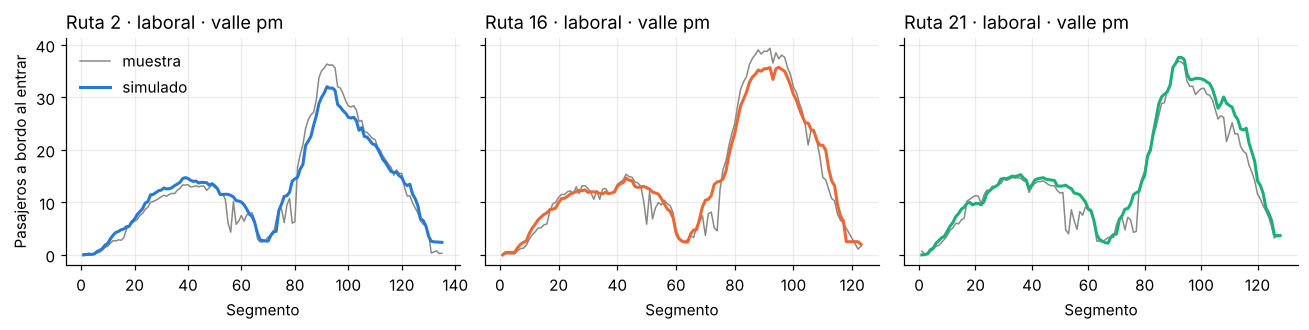

In [6]:
pm = V.perfil_muestra()
fig, ax = plt.subplots(1, 3, figsize=(12, 3.1), sharey=True)
for a, r in zip(ax, (2, 16, 21)):
    s = V.leer("real_laboral", "perfil").query("idruta == @r and franja_salida == 'valle_pm'").groupby("nro_segmento").carga_in_media.mean()
    o = pm.query("idruta == @r and franja_salida == 'valle_pm' and tipo_dia == 'laboral'").set_index("nro_segmento").carga_in_media
    a.plot(o.index, o.values, color=GRIS, lw=1, label="muestra"); a.plot(s.index, s.values, color=COL[r], lw=2, label="simulado")
    a.set_title(f"Ruta {r} · laboral · valle pm", loc="left"); a.set_xlabel("Segmento")
ax[0].set_ylabel("Pasajeros a bordo al entrar"); ax[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "m13_2_perfil.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 3 · La demanda llega a los buses y la carga a bordo se parece a la de la muestra**
- **Pasajeros por viaje:** a ±1,4 % de la demanda de la 13.1 repartida entre las salidas de cada día, en los 6 días y las 3 rutas.
  - Frente al día promedio de 2025, la diferencia llega a ±12 %. No es un error del motor: esos días tuvieron más o menos salidas que el promedio y los buses se reparten la misma demanda. Para validar el motor sirve la primera comparación; para planear, la segunda.
- **Servicio:**
  - casi nadie se queda sin subir habiendo pasado un bus (≤ 0,2 %);
  - el 0,3–1,3 % llega a su segmento después del último bus del día;
  - todo el que sube se baja.
- **Carga a bordo frente a la muestra del mismo tipo de día:**
  - **Laboral:** correlación de 0,90 a 0,96 en 5 de 6 casos; la ruta 16 en el día de calibración da 0,898. El techo que permite el ruido de la muestra es ~0,99.
  - **Fin de semana:** de 0,77 a 0,94, por debajo de 0,9 en 7 de 12 casos. La muestra de fin de semana tiene pocos viajes (54 a 84 por ruta) y su propio techo baja a 0,83–0,96. Además, el reparto por segmento de la 13.1 es el mismo para todos los tipos de día (D5).
- **Buses llenos, frente a la muestra:**

  | | Simulado | Muestra |
  |---|---|---|
  | Laboral | 18–26 % | 20,2 % |
  | Sábado | 11–23 % | 9,5 % |
  | Domingo | 3–8 % | 2,2 % |

- **Espera media:** 3,5–4,4 min en la ruta 16, 5,6–6,9 en la 2 y 9,0–10,8 en la 21. Es coherente con cada cuánto sale cada ruta.

## 4 · Buses pegados: lo que el motor produce solo

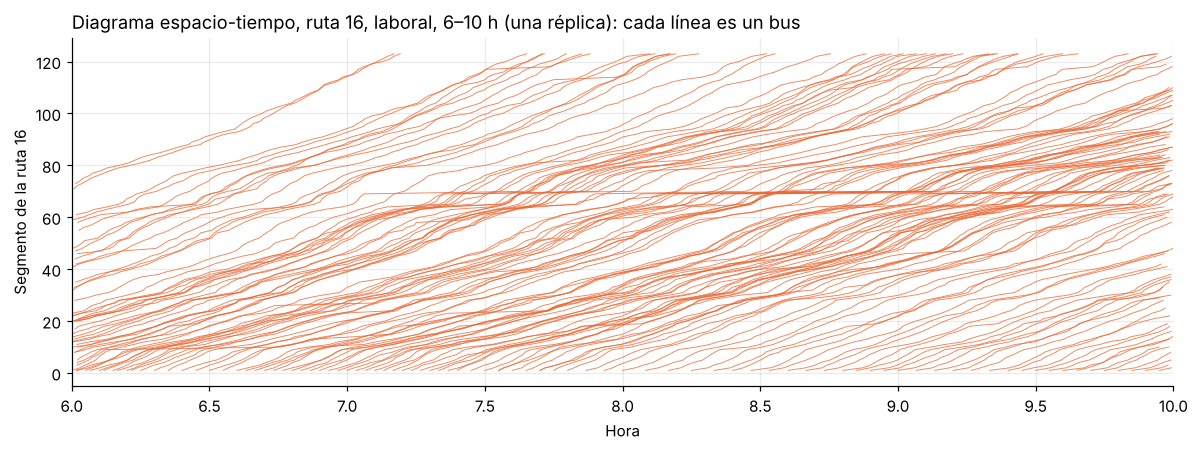

,idruta,lugar,minutos_entre_buses_mediana,cv,pct_menos_de_1_min
0,2,salida,8.00,0.24,4.17
1,2,mitad del circuito,2.84,1.21,28.21
2,16,salida,3.00,0.33,3.51
3,16,mitad del circuito,1.16,1.10,43.75
4,21,salida,12.00,0.25,0.00
5,21,mitad del circuito,5.04,0.95,20.83


In [7]:
p = pd.read_parquet(SAL / "real_laboral_pasos_replica0.parquet")
fig, ax = plt.subplots(figsize=(11, 4.2))
x = p[(p.idruta == 16) & (p.t_s >= 6 * 3600) & (p.t_s <= 10 * 3600)]
for i, g in x.groupby("id_salida"):
    ax.plot(g.t_s / 3600, g.k + 1, color=COL[16], lw=.6, alpha=.8)
ax.set_xlabel("Hora"); ax.set_ylabel("Segmento de la ruta 16"); ax.set_xlim(6, 10)
ax.set_title("Diagrama espacio-tiempo, ruta 16, laboral, 6–10 h (una réplica): cada línea es un bus", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_2_espacio_tiempo.png", dpi=200, bbox_inches="tight"); plt.show()
filas = []
for r in (2, 16, 21):
    y = p[p.idruta == r]; mid = y.k.max() // 2
    for k, lugar in ((0, "salida"), (mid, "mitad del circuito")):
        t = np.sort(y[(y.k == k) & (y.t_s >= 7 * 3600) & (y.t_s < 10 * 3600)].t_s.to_numpy()); h = np.diff(t) / 60
        filas.append({"idruta": r, "lugar": lugar, "minutos_entre_buses_mediana": np.median(h), "cv": h.std() / h.mean(),
                      "pct_menos_de_1_min": 100 * (h < 1).mean()})
display(pd.DataFrame(filas).round(2))

**Conclusión 4 · La irregularidad crece a lo largo del circuito, como en la operación real**
- **En la salida** (laboral, 7–10 h, una réplica), los buses salen regulares: coeficiente de variación de 0,24–0,33 entre buses.
- **A la mitad del circuito,** sube a 0,95–1,21, y el 21–44 % de los intervalos es de menos de 1 min: buses pegados.
- **Sale solo:** viene de que cada viaje tiene su efecto (viajes enteros más lentos) y de que el bus de adelante recoge más gente. No se impuso.
- **Lo que falta medir:** el motor no tiene regulación (un bus no espera a propósito para separarse). La 13.4 debe comparar estos intervalos con los del GPS de los días congelados. Si allá son más regulares, se agrega una regla de regulación.

## 5 · Primer vistazo al plan del proyecto (sin imprevistos)

In [8]:
cmp_ = sv[sv.escenario.isin(["real_laboral", "proyecto85_laboral"])][["escenario", "idruta", "espera_media_min", "espera_p90_min",
                                                                       "pct_dejados_bus_lleno", "pct_viajes_bus_lleno", "pct_sin_subir_con_servicio"]]
display(cmp_.round(2))
info = pd.concat([V.leer(n, "info") for n in ("real_laboral", "proyecto85_laboral")])
v1, v2 = V.leer("real_laboral", "viajes"), V.leer("proyecto85_laboral", "viajes")
print("Salidas por réplica (real / proyecto 85 %):", v1.groupby("idruta").size().div(30).to_dict(), "/", v2.groupby("idruta").size().div(30).to_dict())
print("Buses usados (real / proyecto):", v1.groupby(["replica", "idruta"]).bus.nunique().groupby("idruta").median().to_dict(), "/",
      v2.groupby(["replica", "idruta"]).bus.nunique().groupby("idruta").median().to_dict())

,escenario,idruta,espera_media_min,espera_p90_min,pct_dejados_bus_lleno,pct_viajes_bus_lleno,pct_sin_subir_con_servicio
0,real_laboral,2,5.63,12.61,4.23,18.23,0.00
1,real_laboral,16,3.79,8.51,7.26,26.12,0.00
2,real_laboral,21,9.70,20.96,6.15,24.17,0.00
0,proyecto85_laboral,2,7.29,16.30,7.68,39.86,0.20
1,proyecto85_laboral,16,4.04,9.10,7.79,35.49,0.04
2,proyecto85_laboral,21,10.56,23.24,7.24,38.16,0.30


Salidas por réplica (real / proyecto 85 %): {2: 164.0, 16: 297.0, 21: 96.0} / {2: 120.0, 16: 252.0, 21: 78.0}
Buses usados (real / proyecto): {2: 59.0, 16: 99.0, 21: 59.0} / {2: 46.0, 16: 90.0, 21: 28.0}


**Conclusión 5 · El plan del proyecto ahorra buses, pero llena más los buses**
- **El plan del proyecto con factor de carga 85 %**, frente al plan real (laboral, sin imprevistos):
  - usa 46 / 90 / 28 buses, frente a 59 / 99 / 59, con 120 / 252 / 78 salidas, frente a 164 / 297 / 96;
  - la espera media sube en 1,7 / 0,3 / 0,9 min;
  - los viajes que llegan al cupo pasan del 18–26 % al 35–40 %.
- **La razón:** la carga máxima se calculó con la carga media de cada hora, pero con buses pegados la carga varía de un bus a otro, y muchos se llenan.
- **La 13.4 lo compara con imprevistos y con los tres factores de carga (100 / 85 / 70 %).**

## 6 · Rapidez y reproducibilidad

In [9]:
info = pd.concat([V.leer(n, "info").assign(escenario=n) for n in V.ESCENARIOS_REAL + ("proyecto85_laboral",)])
print(f"{len(info)} réplicas · segundos por día de 3 rutas: mediana {info.segundos.median():.2f}, máximo {info.segundos.max():.2f}")
print("Python", sys.version.split()[0])

210 réplicas · segundos por día de 3 rutas: mediana 0.72, máximo 1.12
Python 3.13.16


**Conclusión 6 · Un día tarda alrededor de un segundo: la 13.4 puede hacer cientos de réplicas**
- **Rapidez:** 210 réplicas de un día completo de las 3 rutas, con mediana de 0,72 s y máximo de 1,12 s (el alcance pedía ≤ 30 s). Es la corrida del 4-nov-2026 con el motor de la 13.3, sin imprevistos: da las mismas tablas que la primera (0,64 s), y el tiempo sube un poco por los controles de imprevistos.
- **Reproducibilidad:** con la misma semilla el resultado es idéntico, en Python 3.12 y 3.13.
- **Seguridad:** el motor no arranca si un parámetro de la 13.1 cambió y no puede simular los días de validación.
- **`tests_13_2.py`: 12/12.**

## Síntesis
El motor ya reproduce un día típico con el plan real:
- **Buses y conductores:** cada salida la hace su bus del día (85–89 %), con reemplazo cuando el bus no ha vuelto.
- **Vuelta:** su mediana queda a ±5 % en 108 de 108 celdas, también en días que no se usaron para calibrar. Su variación es algo mayor que la real (+17 %).
- **Demanda:** llega a los buses (±1,4 %) y casi nadie se queda sin subir.
- **Carga a bordo:** se parece a la de la muestra en los laborales (0,90–0,96).
- **Buses llenos:** el laboral coincide con la muestra (18–26 % frente a 20 %).
- **Buses pegados:** aparecen solos a lo largo del circuito.
- **Rapidez:** alrededor de un segundo por día (mediana 0,72 s).

**Quedan para la 13.4:**
- la carga de los fines de semana, con una muestra pequeña;
- comprobar si los buses de verdad se pegan tanto como en la simulación, con el GPS de los días congelados.

**Siguiente: la 13.3, los imprevistos.** Son los eventos del Módulo 10 con el reenrutamiento del Módulo 12, los arroyos, los desvíos, las varadas y los eventos masivos, con las tasas de la 13.1.

---
# Parte 13 · Módulo 13 · Subfase 13.3 · Imprevistos
*Notebook original: `modulo13/subfase_13_3_imprevistos.ipynb`*

# SOBUSA · Módulo 13 · Subfase 13.3 — Imprevistos en el motor

**Persona 3.** El motor de la 13.2 ahora simula los imprevistos del día: obras y cierres, arroyos, varadas, eventos
masivos, choques, bloqueos y semáforos, con su comienzo, su efecto en los buses y los pasajeros, y su fin. Las tasas son
las de la 13.1 y el reenrutamiento es el del Módulo 12. Alcance aprobado: `revisiones/alcance_13_3.md`.

| Pieza | Qué hace | Dónde |
|---|---|---|
| Insumos | Tramos reales de desvío del GPS, tasa de desvíos por ruta, puntos inundables, segmentos del estadio | `preparar_13_3.py` → `datos_13/imprevistos_13_3/` |
| Imprevistos | Sortea los del día (tipo, lugar, hora, gravedad, duración) y calcula su efecto con el Módulo 12, una vez por evento y ruta | `src/simulation/imprevistos.py` |
| Motor | Desvío, espera, vía lenta, varada y lluvia dentro de la vuelta de cada bus; quién se entera y cuándo | `src/simulation/motor.py` |
| Calibración | Cuántas obras por día dan los viajes desviados que muestra el GPS | `src/simulation/calibracion.py` (`calibrar_obras`) |
| Chequeos y criterios | Corridas de chequeo y criterios de aceptación | `src/simulation/chequeos_13_3.py`, `evaluacion_13_3.py` |

**Días.** Los de desarrollo y control de la 13.2, más un día de lluvia fuerte (19-sep-2025, 13,3 mm/h a las 12 h) y uno de
evento masivo (6-jun-2025, partido de la Selección a las 15:30). Ninguno es un día de validación: esos se simulan en la 13.4.

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, ".")
from src.simulation import escenario as E, imprevistos as I, evaluacion_13_3 as V

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
SAL = I.SAL3; FIG = Path("resultados_13"); FIG.mkdir(exist_ok=True)
COL = {2: "#2a78d6", 16: "#eb6834", 21: "#1baf7a"}; GRIS = "#8a8a85"
CT = {"obra": "#2a78d6", "choque": "#eb6834", "semaforo": "#e8b51e", "bloqueo": "#7d5bbf", "arroyo": "#1baf7a",
      "evento": "#c2417a", "varado": "#5a5a55"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "font.size": 10, "figure.dpi": 110})
man = json.loads((SAL / "manifiesto_simulacion_13_3.json").read_text(encoding="utf-8"))
print("Corridas:", man["creado"], "· parámetros de la 13.1 del", man["manifiesto_13_1"])
print("Escenarios:", {k: v["replicas"] for k, v in man["escenarios"].items()})
print("Tablas que cambiaron desde el manifiesto:", [n for n, d in man["salidas"].items() if E._sha(SAL / n) != d["sha256"]])
P = E.cargar_parametros(); _ = I.reenrutador()

Corridas: 2026-11-04T20:46:32 · parámetros de la 13.1 del 2026-11-04T20:17:54
Escenarios: {'central_laboral': 100, 'baja_laboral': 30, 'alta_laboral': 30, 'central_sabado': 30, 'central_domingo': 30, 'control_laboral': 30, 'lluvia_2025-09-19': 30, 'evento_2025-06-06': 30}
Tablas que cambiaron desde el manifiesto: []


## 1 · Qué imprevistos, dónde y con qué gravedad

**Trancones:** ya están en la 13.2 como pasos lentos sacados de los datos y no se agregan otra vez.

**Obras y cierres:** cada obra es un tramo real de desvío del GPS (zonas transitorias Z5–Z17 del Módulo 10, episodios de la
12.5, sin los días de validación). Se cierran **los mismos segmentos que se saltó el bus real**, así que el Módulo 12 busca
la alterna para el mismo tramo. La tasa de cada ruta sale de la misma muestra de calibración que la 13.1.

**Gravedad:** la proporción del banco del Módulo 10 por tipo (supuesto con su rótulo). 4–5 cierra la vía; 1–3 la hace
lenta (× 1,2 / 1,5 / 2,0). **Duración:** lognormal centrada en la típica del Módulo 12, σ = 0,5.

In [2]:
z = pd.read_csv(I.D_IMP / "zonas_obra_13_3.csv"); t = pd.read_csv(I.D_IMP / "tasa_obra_ruta_13_3.csv")
print(f"Tramos reales de desvío: {len(z)} ({z.groupby('idruta').size().to_dict()}); segmentos por tramo:",
      z.n_segmentos.describe()[["50%", "mean", "max"]].round(1).to_dict(), "· minutos fuera de la ruta (mediana):", z.minutos_fuera.median())
display(t.round(3))
print("Zonas:", z.zona.value_counts().to_dict())
sev = I.insumos()["severidad_banco"].pivot(index="tipo_evento", columns="severidad", values="p").fillna(0)
display(sev.loc[["obra", "choque", "bloqueo", "semaforo"]].round(2))
print("Duración típica (min, Módulo 12):", {k: I.insumos()["duracion_defecto"][k] for k in ("obra", "evento", "bloqueo", "arroyo", "choque", "varado", "semaforo")})
display(pd.read_csv(I.D_IMP / "arroyos_puntos_13_3.csv")[["punto", "idruta", "nro_segmento", "fuente"]])
e = pd.read_csv(I.D_IMP / "segmentos_estadio_13_3.csv"); print("Estadio Metropolitano:", e.groupby(["idruta", "efecto"]).nro_segmento.apply(list).to_dict())
fl = P["factor_lluvia_13_1.csv"]; display(fl.round(3))

Tramos reales de desvío: 77 ({2: 30, 16: 15, 21: 32}); segmentos por tramo: {'50%': 2.0, 'mean': 2.6, 'max': 8.0} · minutos fuera de la ruta (mediana): 8.0


,idruta,viajes_muestra,viajes_con_desvio,tasa_por_1000,peso_ruta,minutos_fuera_mediana
0,2,471,20,42.463,1.031,7.550
1,16,472,9,19.068,0.463,8.700
2,21,489,30,61.350,1.489,9.075


Zonas: {'Z7': 38, 'Z16': 9, 'Z8': 7, 'Z6': 6, 'Z13': 5, 'Z10': 5, 'Z9': 2, 'Z17': 2, 'Z5': 1, 'Z12': 1, 'Z11': 1}


severidad,1.0,2.0,3.0,4.0,5.0
tipo_evento,,,,,
obra,0.19,0.19,0.19,0.19,0.23
choque,0.13,0.23,0.18,0.23,0.23
bloqueo,0.23,0.15,0.23,0.17,0.21
semaforo,0.19,0.33,0.17,0.24,0.07


Duración típica (min, Módulo 12): {'obra': 180, 'evento': 120, 'bloqueo': 90, 'arroyo': 60, 'choque': 45, 'varado': 30, 'semaforo': 20}


,punto,idruta,nro_segmento,fuente
0,Calle 85 con Carrera 49C,2,87,C3;C4;C5
1,Calle 85 con Carrera 51B,16,80,C4;C5


Estadio Metropolitano: {(2, 'cierre'): [121, 122], (2, 'lento'): [12, 13, 14, 120, 123], (16, 'cierre'): [108, 109, 110], (16, 'lento'): [12, 13, 14, 107], (21, 'cierre'): [114, 115], (21, 'lento'): [12, 13, 14, 113, 116]}


,clase,desde_mm_h,hasta_mm_h,pasos,viajes,factor,ic95_bajo,ic95_alto
0,seco,0.00,5.000000e-02,97220,1255,1.000,1.000,1.000
1,menos_2,0.05,2.000000e+00,36380,699,1.024,1.015,1.032
2,2_a_5,2.00,5.000000e+00,3590,136,1.024,1.007,1.039
3,5_a_10,5.00,1.000000e+01,1477,63,1.024,0.998,1.051
4,10_o_mas,10.00,1.000000e+09,120,6,1.081,1.007,1.204


**Conclusión 1 · Los imprevistos salen de los datos, salvo tres tipos que quedan como supuesto**
- **Obras y cierres:** 77 tramos reales de desvío del GPS (30 / 15 / 32 en las rutas 2 / 16 / 21), de 11 zonas transitorias. Cada obra cierra los mismos segmentos que se saltó el bus real: 2 en la mediana, 2,6 en promedio, hasta 8. En el GPS, el bus pasa 8,0 min fuera de la ruta en la mediana.
- **Cada ruta con su tasa:** en la muestra de calibración de la 13.1, la ruta 2 se desvía 42,5 veces por cada 1.000 viajes, la 16 19,1 y la 21 61,3. La ruta 16 casi no pasa por las zonas de obra.
- **Gravedad** (proporción del banco del Módulo 10, supuesto rotulado): cierran la vía (4–5) el 42 % de las obras, el 46 % de los choques, el 38 % de los bloqueos y el 31 % de los semáforos; el resto hace la vía lenta.
- **Arroyos:** 2 puntos en la calle 85, con carreras 49C (ruta 2) y 51B (ruta 16). Su canalización iba al ~40 % en noviembre de 2025 y seguía en obra en julio de 2026 (FUENTES C3–C6), así que en 2025 eran inundables.
- **Evento masivo:** se cierran los segmentos a ≤ 450 m del Estadio Metropolitano (2 / 3 / 2 por ruta) y quedan lentos los que están a ≤ 800 m.
- **Lluvia** (enmienda de la 13.1): con menos de 10 mm/h los tiempos se alargan × 1,024; con 10 mm/h o más, × 1,081 (IC95 % 1,007–1,204; solo 120 pasos de 6 viajes).
- **Supuestos:** choques, bloqueos y semáforos no tienen registro en la base; van con su rango bajo–alto (13.1).

## 2 · Cuántos: tasas de la 13.1 y lo que pasa en el motor

Para las obras, la tasa de la 13.1 está en **viajes desviados por 1.000 viajes**, que es lo que mide el GPS. Una obra
que cierra la vía desvía también los buses de las otras rutas que pasan por esa calle, y solo las de gravedad 4–5 cierran.
Por eso el número de obras por día se calibra para que los viajes desviados sean los del GPS: **un solo factor** para las
3 rutas, con una matriz de desvíos por obra estimada con muchas obras.

In [3]:
display(V.tasas().round(3))
cal = pd.read_csv(SAL / I.CAL_OBRA); mat = pd.read_csv(SAL / "matriz_obra_13_3.csv")
display(cal.round(3)); print("Viajes desviados de cada ruta por cada obra que nace en una ruta:"); display(mat.round(2))
display(V.tasas_motor().round(2))

,tipo,unidad,simulado,ic95_bajo,ic95_alto,tasa_13_1,baja_13_1,alta_13_1,dias,dentro_intervalo_13_1,central_en_ic95
0,choque,por día (3 rutas),0.893,0.834,0.952,0.900,0.300,1.800,1000,True,True
1,bloqueo,por día (3 rutas),0.101,0.081,0.121,0.090,0.030,0.240,1000,True,True
2,semaforo,por día (3 rutas),0.440,0.399,0.481,0.450,0.150,0.900,1000,True,True
3,varado (sorteadas),por 1.000 buses-día,12.558,12.086,13.029,12.333,9.737,14.708,1000,True,True


,idruta,obras_dia_conversion,obras_dia,factor,objetivo_por_1000,objetivo_bajo_wilson,objetivo_alto_wilson,viajes_dia,obras_estimacion,desviados_por_1000_esperado,desviados_por_1000_conversion
0,2,0.285,0.318,1.117,42.463,27.654,64.675,164.0,105,44.569,39.885
1,16,0.129,0.144,1.117,19.068,10.063,35.838,297.0,56,22.685,20.301
2,21,0.412,0.461,1.117,61.350,43.308,86.230,96.0,167,46.563,41.670


Viajes desviados de cada ruta por cada obra que nace en una ruta:


,ruta_obra,desviados_ruta_2,desviados_ruta_16,desviados_ruta_21
0,2,9.90,2.31,3.50
1,16,1.64,21.39,0.23
2,21,8.51,6.34,7.21


,tipo,idruta,unidad,simulado,baja_13_1,alta_13_1,tasa_13_1,eventos,base,replicas,dentro_intervalo
0,obra (viajes desviados),2,por 1.000 viajes,42.74,27.65,64.68,42.46,701,16400,100,True
1,obra (viajes desviados),16,por 1.000 viajes,20.17,10.06,35.84,19.07,599,29700,100,True
2,obra (viajes desviados),21,por 1.000 viajes,46.35,43.31,86.23,61.35,445,9600,100,True
3,obra (viajes desviados),total (composición de la muestra),por 1.000 viajes,36.54,32.08,52.78,41.20,1745,55700,100,True
4,obra (viajes desviados),total (composición del día),por 1.000 viajes,31.33,NaN,NaN,33.24,1745,55700,100,NaN
5,varado (ocurridas),total,por 1.000 buses-día,11.20,9.74,14.71,12.33,243,21700,100,True


**Conclusión 2 · Las tasas de la 13.1 se cumplen, también dentro del motor**
- **Sorteo de 1.000 laborales** (frente a la tasa central de la 13.1): 0,893 choques por día (0,9), 0,101 bloqueos (0,09), 0,440 semáforos (0,45) y 12,6 varadas sorteadas por 1.000 buses-día (12,3). La tasa central queda dentro del IC95 % en los 4 casos.
- **Obras: se calibra cuántas hay por día.** La tasa del GPS está en viajes desviados, y una obra cerrada también desvía a las otras rutas que pasan por esa calle: una obra en la ruta 21 desvía 8,5 viajes de la ruta 2, 6,3 de la 16 y 7,2 de la 21. Con **un solo factor (1,117)** para las 3 rutas, los viajes desviados quedan así (100 laborales):

  | Ruta | Simulado | GPS (intervalo) |
  |---|---|---|
  | 2 | 42,7 | 42,5 (27,7–64,7) |
  | 16 | 20,2 | 19,1 (10,1–35,8) |
  | 21 | 46,4 | 61,3 (43,3–86,2) |
  | Total, composición de la muestra | **36,5** | 41,2 (32,1–52,8) |

  Un factor por ruta dejaba a la ruta 2 sin obras propias (las de la 21 ya la desvían), un sobreajuste a tasas medidas con 9 a 30 episodios. En un día real hay más viajes de la ruta 16, que se desvía menos, así que el total del día baja a 31,3 por 1.000 (33,2 esperado).
- **Varadas que ocurren en el motor:** 11,2 por 1.000 buses-día (intervalo 9,7–14,7). Un bus solo se vara en un viaje que sale a más tardar a las 16 h, como en la etiqueta del Módulo 9.

## 3 · El reenrutamiento: cuánto dura un desvío, quién se entera y nadie pasa por un cierre

,grupo,desvios,mediana_sim,p25_sim,p75_sim,mediana_gps,mediana_gps_zonas,error_pct
0,total,1760,8.90,5.19,11.53,8.6,8.00,3.47
1,ruta 2,701,5.48,4.55,12.15,NaN,7.20,-36.24
2,ruta 16,599,11.01,8.04,11.53,NaN,7.82,28.02
3,ruta 21,460,8.53,7.22,11.02,NaN,9.02,-0.82


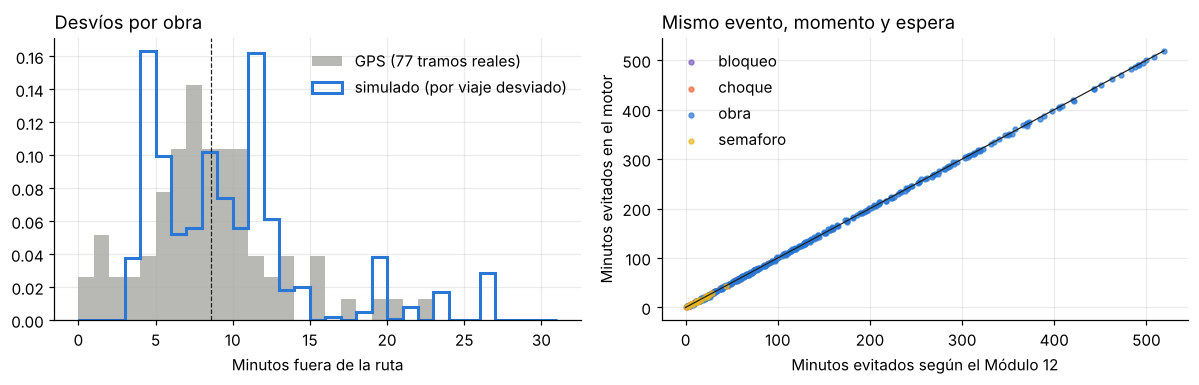

{'cierres_revisados': 44, 'replicas': 13, 'pasos_en_cierre': 0, 'pasos_tomando_alterna': 65, 'desvios_comparados': 400, 'recomendacion_desviar_pct': 99.75, 'dif_mediana_min': -0.0010830346893477998, 'dif_abs_p95_min': 2.9921932042892365, 'dif_abs_mediana_pct': 0.895889016262339, 'evitados_m12_mediana_min': 74.63156729129284}
Cierres reportados por un bus: 82; minutos desde el inicio hasta el reporte (mediana): 3.4
Acción de los buses ante un cierre: {'desvio': 2296, 'desvio_tras_reporte': 254, 'espera': 67}


In [4]:
o = V.obra_minutos(); display(o.round(2))
a = V.leer("central_laboral", "afectaciones"); d = a[(a.tipo == "obra") & a.accion.str.startswith("desvio")]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
b = np.arange(0, 32, 1)
ax[0].hist(z.minutos_fuera.clip(upper=31), bins=b, density=True, color=GRIS, alpha=.6, label="GPS (77 tramos reales)")
ax[0].hist(d.minutos_fuera_ruta.clip(upper=31), bins=b, density=True, histtype="step", lw=2, color=CT["obra"], label="simulado (por viaje desviado)")
ax[0].axvline(V.REF_OBRA_MIN, color="#1f1f1d", lw=.8, ls="--"); ax[0].set_xlabel("Minutos fuera de la ruta"); ax[0].legend(frameon=False)
ax[0].set_title("Desvíos por obra", loc="left")
cm = pd.read_csv(SAL / "consistencia_m12_13_3.csv")
for tp, g in cm.groupby("tipo"):
    ax[1].scatter(g.evitados_m12, g.evitados_sim, s=10, color=CT.get(tp, GRIS), label=tp, alpha=.7)
mx = cm[["evitados_m12", "evitados_sim"]].max().max(); ax[1].plot([0, mx], [0, mx], color="#1f1f1d", lw=.8)
ax[1].set_xlabel("Minutos evitados según el Módulo 12"); ax[1].set_ylabel("Minutos evitados en el motor"); ax[1].legend(frameon=False)
ax[1].set_title("Mismo evento, momento y espera", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_3_desvios.png", dpi=200, bbox_inches="tight"); plt.show()
print(V.reenrutamiento())
im = V.leer("central_laboral", "imprevistos")
cer = im[np.isfinite(im.conocido_s)]
print(f"Cierres reportados por un bus: {len(cer)}; minutos desde el inicio hasta el reporte (mediana): {((cer.conocido_s - cer.inicio_s) / 60 - 122 / 60).median():.1f}")
print("Acción de los buses ante un cierre:", a[a.accion.isin(["desvio", "desvio_tras_reporte", "espera"])].accion.value_counts().to_dict())

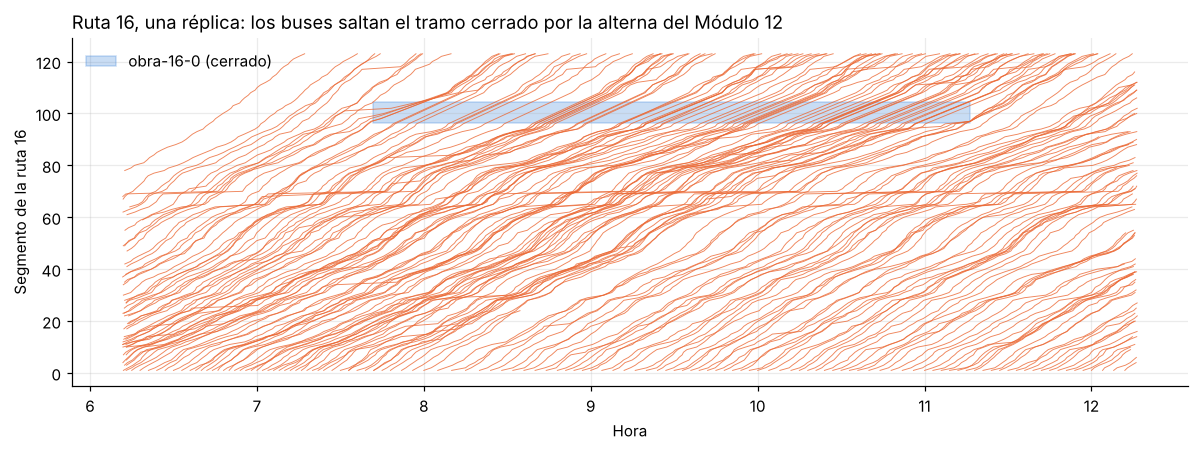

In [5]:
p = pd.read_parquet(SAL / "central_laboral_pasos_replica0.parquet")
ef = V.leer("central_laboral", "efectos").query("replica == 0"); im0 = im[im.replica == 0].set_index("id")
c = ef[np.isinf(ef.factor) & ef.desviar].merge(V.leer("central_laboral", "afectaciones").query("replica == 0").groupby(["id", "idruta"]).size()
                                             .rename("n").reset_index(), on=["id", "idruta"]).sort_values("n").iloc[-1]
r, kb = int(c.idruta), [int(x) for x in str(c.k_bloq).split(";")]
t0, t1 = im0.loc[c.id, "inicio_s"], im0.loc[c.id, "fin_s"]
x = p[(p.idruta == r) & (p.t_s >= t0 - 5400) & (p.t_s <= t1 + 3600)]
fig, ax = plt.subplots(figsize=(11, 4.2))
for i, g in x.groupby("id_salida"):
    ax.plot(g.t_s / 3600, g.k + 1, color=COL[r], lw=.6, alpha=.8)
ax.fill_between([t0 / 3600, t1 / 3600], min(kb) + .5, max(kb) + 1.5, color=CT[im0.loc[c.id, "tipo"]], alpha=.25, label=f"{c.id} (cerrado)")
ax.set_xlabel("Hora"); ax.set_ylabel(f"Segmento de la ruta {r}"); ax.legend(frameon=False, loc="upper left")
ax.set_title(f"Ruta {r}, una réplica: los buses saltan el tramo cerrado por la alterna del Módulo 12", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_3_espacio_tiempo.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 3 · Los desvíos duran lo que en la calle y el motor decide como el Módulo 12**
- **Minutos fuera de la ruta por obra:** mediana **8,9 min, frente a 8,6 del GPS (+3 %)**, en 1.760 viajes desviados; criterio ±25 %. Por ruta se aleja más (ruta 2: 5,5 frente a 7,2; ruta 16: 11,0 frente a 7,8; ruta 21: 8,5 frente a 9,0), porque con 15 a 32 tramos reales por ruta el tramo que toca pesa mucho.
- **Mismo resultado que el Módulo 12:** en 400 desvíos, los minutos evitados del motor y los del Módulo 12 para el mismo evento, momento y espera difieren 0,9 % en la mediana (P95 de la diferencia: 3,0 min). El Módulo 12 recomienda desviarse en el 99,8 % de esos casos.
- **Nadie pasa por un cierre:** en 44 cierres de las primeras 20 réplicas, 0 pasos de bus entran a un tramo cerrado mientras dura; 65 llegan a él solo para tomar la alterna.
- **Quién se entera:** el primer bus llega al cierre 3,4 min después de que empieza (mediana), espera 2 min mientras reporta y toma la alterna. En 100 laborales hay 2.296 desvíos de buses que ya sabían, 254 de buses que reportaron y 67 esperas, cuando el cierre acaba antes de que el desvío ahorre tiempo.
- **Simplificación:** para decidir, el motor usa el tiempo que de verdad le queda al cierre; en la calle solo se conoce lo que estimó el conductor (LIMITACIONES §13).

## 4 · El efecto en la operación

,escenario,tipo,imprevistos_dia,viajes_afectados_dia,desvios_dia,esperas_dia,lentos_dia,minutos_mediana_por_afectacion,minutos_total_dia,pasajeros_a_bordo_dia
0,alta_laboral,bloqueo,0.37,13.53,7.73,0.40,8.47,2.23,43.08,151.63
1,alta_laboral,choque,1.80,35.67,14.00,1.43,32.23,0.70,97.78,503.37
2,alta_laboral,obra,1.30,85.77,44.30,1.10,109.80,1.05,424.66,2176.43
3,alta_laboral,semaforo,0.77,7.90,4.37,0.37,4.27,1.15,21.98,71.77
4,alta_laboral,varado,3.13,3.13,0.00,0.00,0.00,NaN,0.00,38.10
0,baja_laboral,bloqueo,0.13,4.83,1.20,0.23,4.60,1.53,15.93,90.27
1,baja_laboral,choque,0.33,6.47,2.63,0.10,6.10,1.09,14.20,81.73
2,baja_laboral,obra,0.70,36.93,9.00,0.00,62.50,0.95,110.86,1240.40
3,baja_laboral,semaforo,0.13,0.73,0.00,0.17,0.57,0.82,1.39,4.77
4,baja_laboral,varado,2.07,2.07,0.00,0.00,0.00,NaN,0.00,26.80


Salidas que no se hacen por falta de bus (por día): {'alta_laboral': 0.0, 'baja_laboral': 0.0, 'central_domingo': 0.0, 'central_laboral': 0.0, 'central_sabado': 0.0, 'control_laboral': 0.0, 'evento_2025-06-06': 0.3, 'lluvia_2025-09-19': 0.0}


,idruta,franja_salida,sin_med,sin_p90,con_med,con_p90
0,2,madrugada,224.5,260.2,224.7,263.1
1,2,noche,179.1,209.0,180.1,207.4
2,2,pico_am,263.1,307.0,263.4,304.6
3,2,pico_pm,227.8,259.2,225.2,256.2
4,2,valle_am,249.0,279.8,252.9,287.3
5,2,valle_pm,274.0,310.5,276.4,312.1
6,16,madrugada,198.9,235.1,198.3,234.5
7,16,noche,167.0,191.3,168.2,194.5
8,16,pico_am,247.9,283.7,248.0,283.5
9,16,pico_pm,201.9,229.6,201.4,228.7


Viajes tocados por algún imprevisto: 12.5 % · minutos perdidos por viaje tocado (sin varadas): {'50%': 1.9, '90%': 9.1, 'max': 62.2}
Minutos perdidos por día en las 3 rutas: 208.6 · por viaje del día: 0.37
Celdas con la mediana a ±5 % y la P90 a ±10 % de la maestra: {'central_domingo': {'sum': 16, 'size': 18}, 'central_laboral': {'sum': 18, 'size': 18}, 'central_sabado': {'sum': 18, 'size': 18}, 'control_laboral': {'sum': 18, 'size': 18}}
Error máximo |%| (mediana / P90): {'central_domingo': {'error_pct': 2.5, 'error_p90_pct': 11.0}, 'central_laboral': {'error_pct': 1.9, 'error_p90_pct': 7.6}, 'central_sabado': {'error_pct': 2.6, 'error_p90_pct': 6.5}, 'control_laboral': {'error_pct': 2.2, 'error_p90_pct': 6.7}}


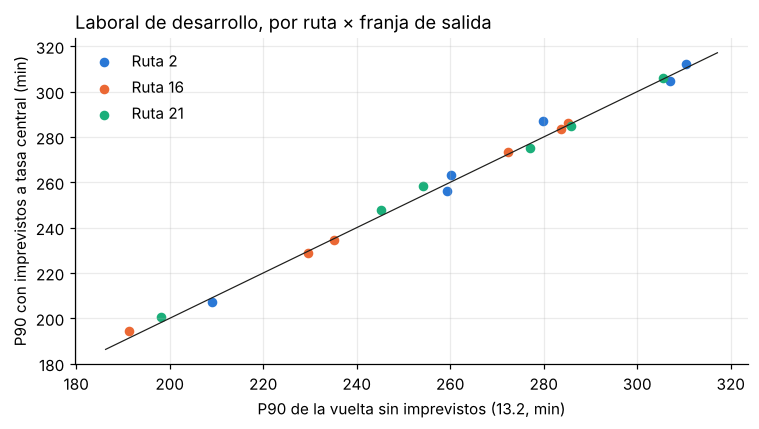

In [6]:
ef = pd.concat([V.efectos(n) for n in V.escenarios()])
display(ef[ef.escenario.isin(["central_laboral", "baja_laboral", "alta_laboral"])].round(2))
print("Salidas que no se hacen por falta de bus (por día):", {n: round(V.salidas_perdidas(n), 2) for n in V.escenarios()})
vs = V.vuelta_sin_con()
display(vs.round(1))
v = V.leer("central_laboral", "viajes"); a = V.leer("central_laboral", "afectaciones")
af = a.groupby(["replica", "idruta", "id_salida"]).minutos.sum(min_count=1).rename("min_imprevisto").reset_index()
v = v.merge(af, on=["replica", "idruta", "id_salida"], how="left")
v["afectado"] = v.min_imprevisto.notna() | v.varado
print(f"Viajes tocados por algún imprevisto: {100 * v.afectado.mean():.1f} % · minutos perdidos por viaje tocado (sin varadas):",
      v.min_imprevisto.dropna().clip(lower=0).describe(percentiles=[.5, .9])[["50%", "90%", "max"]].round(1).to_dict())
print("Minutos perdidos por día en las 3 rutas:", round(v.min_imprevisto.clip(lower=0).sum() / v.replica.nunique(), 1),
      "· por viaje del día:", round(v.min_imprevisto.clip(lower=0).sum() / len(v), 2))
vu = pd.concat([V.vuelta(n) for n in ("central_laboral", "central_sabado", "central_domingo", "control_laboral")])
print("Celdas con la mediana a ±5 % y la P90 a ±10 % de la maestra:",
      vu.assign(ok=(vu.error_pct.abs() <= 5) & (vu.error_p90_pct.abs() <= 10)).groupby("escenario").ok.agg(["sum", "size"]).to_dict("index"))
print("Error máximo |%| (mediana / P90):", vu.groupby("escenario")[["error_pct", "error_p90_pct"]].agg(lambda s: s.abs().max()).round(1).to_dict("index"))
fig, ax = plt.subplots(figsize=(7, 4))
for rr in (2, 16, 21):
    y = vs[vs.idruta == rr]; ax.scatter(y.sin_p90, y.con_p90, color=COL[rr], s=28, label=f"Ruta {rr}")
lo, hi = vs[["sin_p90", "con_p90"]].min().min() - 5, vs[["sin_p90", "con_p90"]].max().max() + 5
ax.plot([lo, hi], [lo, hi], color="#1f1f1d", lw=.8); ax.set_xlabel("P90 de la vuelta sin imprevistos (13.2, min)")
ax.set_ylabel("P90 con imprevistos a tasa central (min)"); ax.legend(frameon=False)
ax.set_title("Laboral de desarrollo, por ruta × franja de salida", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_3_vuelta.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 4 · Un imprevisto pesa mucho en el viaje que toca, poco en el día**
- **Un laboral a tasa central** tiene 2,2 imprevistos de vía y 2,4 varadas, y toca el **12,5 %** de los viajes (9,1 % a tasa baja y 24,6 % a tasa alta).
- **Por viaje tocado** (sin varadas), se pierden 1,9 min en la mediana, 9,1 en el P90 y hasta 62 min. En el día, son 210 min en las 3 rutas: el 79 % por obras.
- **La vuelta casi no cambia:** la mediana queda a ±5 % de la maestra en las 72 celdas (máx. 2,6 %), sin recalibrar.
- **La P90 de la vuelta** queda a ±10 % en 70 de 72 celdas. Las 2 que no cumplen son la madrugada del domingo de las rutas 2 y 21 (+11,0 % las dos), donde ya sin imprevistos daban +8,9 y +8,2 % en la 13.2: es la variación de más que la 13.2 dejó anotada (O6), no un efecto de los imprevistos.
- **Por qué es coherente:** las vueltas reales de la maestra ya incluyen los imprevistos y la 13.2 ya las reproducía. Los imprevistos se notan en el viaje que tocan, no en la mediana del día.

## 5 · Pasajeros: varadas, tramos saltados y eventos masivos

In [7]:
c = pd.concat([V.conservacion(n) for n in V.escenarios()])
display(c.groupby("escenario")[["subidos", "bajados", "esperan_tras_varada", "bajan_por_varada", "reabordan"]].sum()
        .assign(conserva=c.groupby("escenario").conserva.all()))
a = V.leer("central_laboral", "afectaciones"); nrep = V.leer("central_laboral", "info").replica.nunique()
var = a[a.accion == "varada"]
print(f"Varadas por día: {len(var) / nrep:.2f}; pasajeros a bordo al vararse (mediana): {var.pasajeros_a_bordo.median():.0f}; "
      f"hora (mediana): {var.t_s.median() / 3600:.1f} h")
sv = pd.concat([V.leer(n, "pasajeros").assign(escenario=n) for n in ("central_laboral", "alta_laboral")])
s0 = pd.read_parquet(E.SAL / "real_laboral_pasajeros.parquet").assign(escenario="sin imprevistos (13.2)")
x = pd.concat([s0, sv]); x["pct_sin_subir_con_servicio"] = 100 * x.sin_subir_con_servicio / x.llegados
display(x.groupby(["escenario", "idruta"])[["espera_media_min", "espera_p90_min", "pct_sin_subir_con_servicio"]].mean().round(2))
ev = V.leer("evento_2025-06-06", "imprevistos"); print("Evento masivo 6-jun:", ev[ev.tipo == "evento"].groupby("id").size().index.tolist()[:8])

,subidos,bajados,esperan_tras_varada,bajan_por_varada,reabordan,conserva
escenario,,,,,,
alta_laboral,1416614,1416614,0,1143,1143,True
baja_laboral,1417667,1417667,0,804,804,True
central_domingo,640104,640104,0,292,292,True
central_laboral,4722033,4722033,0,2870,2870,True
central_sabado,1124582,1124582,0,843,843,True
control_laboral,1418009,1418009,0,974,974,True
evento_2025-06-06,1434727,1434727,0,1256,1256,True
lluvia_2025-09-19,1417299,1417299,0,960,960,True


Varadas por día: 2.43; pasajeros a bordo al vararse (mediana): 10; hora (mediana): 10.6 h


espera_media_min  espera_p90_min  pct_sin_subir_con_servicio
escenario              idruta                                                              
alta_laboral           2                   6.25           13.17                        0.00
                       16                  3.92            8.56                        0.01
                       21                 10.76           22.28                        0.00
central_laboral        2                   6.00           13.03                        0.00
                       16                  3.86            8.50                        0.00
                       21                 10.32           21.81                        0.00
sin imprevistos (13.2) 2                   5.63           12.61                        0.00
                       16                  3.79            8.51                        0.00
                       21                  9.70           20.96                        0.00

Evento masivo 6-jun: ['evento-16-cierre-108', 'evento-16-lento-107', 'evento-16-lento-12', 'evento-2-cierre-121', 'evento-2-lento-12', 'evento-2-lento-120', 'evento-2-lento-123', 'evento-21-cierre-114']


**Conclusión 5 · Nadie se pierde: el que baja de un bus varado sube al siguiente**
- **Conservación exacta** en los 8 escenarios: 13,6 millones de pasajeros suben y todos se bajan; ninguno queda en la fila al final del día. Cada imprevisto tiene su fin.
- **Varadas:** 2,4 por laboral, a las 10,6 h en la mediana, con 10 pasajeros a bordo en la mediana. Todos (28,7 por día) reabordan el siguiente bus de su ruta, primeros en la fila.
- **No se pierden salidas:** el reemplazo de la 13.2 cubre las salidas de los buses varados. La excepción es el día del evento masivo, con 0,3 salidas por día sin bus.
- **Espera en el paradero:** sube poco con imprevistos a tasa central, de 5,6 a 6,0 min en la ruta 2, de 3,8 a 3,9 en la 16 y de 9,7 a 10,3 en la 21. Quien espera en un tramo que se salta un desvío aguarda al siguiente bus que pasa. Casi nadie se queda sin subir (≤ 0,01 %).

## 6 · Un día de lluvia y uno de evento masivo

,escenario,vuelta_mediana,vuelta_p90,imprevistos_dia,arroyos_dia,tramos_evento_dia,viajes_afectados_%
0,control_laboral,236.98,282.80,2.67,0.0,0.0,18.01
1,central_laboral,239.90,283.99,2.24,0.0,0.0,12.48
2,lluvia_2025-09-19,242.16,288.42,4.67,2.0,0.0,20.72
3,evento_2025-06-06,243.87,289.91,13.63,0.0,11.0,54.03


Lluvia del 19-sep (mm/h, 4–21 h): [0.0, 0.0, 0.0, 0.0, 0.0, 0.2, 0.2, 0.5, 13.3, 3.4, 0.1, 0.2, 0.1, 0.0, 0.0, 0.0, 0.0, 0.0]
Factor de los tiempos por hora: [1.0, 1.0, 1.0, 1.0, 1.0, 1.024, 1.024, 1.024, 1.081, 1.024, 1.024, 1.024, 1.024, 1.0, 1.0, 1.0, 1.0, 1.0]


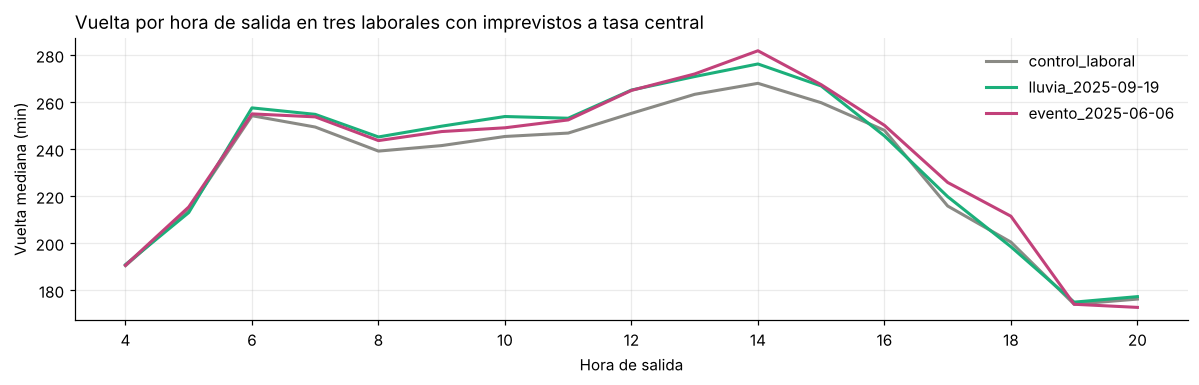

In [8]:
fil = []
for n in ("control_laboral", "central_laboral", "lluvia_2025-09-19", "evento_2025-06-06"):
    v = V.leer(n, "viajes"); im = V.leer(n, "imprevistos"); a = V.leer(n, "afectaciones"); nr = v.replica.nunique()
    fil.append({"escenario": n, "vuelta_mediana": v.vuelta_min.median(), "vuelta_p90": v.vuelta_min.quantile(.9),
                "imprevistos_dia": len(im) / nr, "arroyos_dia": (im.tipo == "arroyo").sum() / nr,
                "tramos_evento_dia": (im.tipo == "evento").sum() / nr,
                "viajes_afectados_%": 100 * a.drop_duplicates(["replica", "idruta", "id_salida"]).shape[0] / len(v)})
display(pd.DataFrame(fil).round(2))
print("Lluvia del 19-sep (mm/h, 4–21 h):", np.round(I.lluvia_del_dia("2025-09-19")[4:22], 1).tolist())
print("Factor de los tiempos por hora:", np.round(I.factores_lluvia("2025-09-19", P["factor_lluvia_13_1.csv"])[4:22], 3).tolist())
fig, ax = plt.subplots(figsize=(11, 3.6))
for n, col in (("control_laboral", GRIS), ("lluvia_2025-09-19", CT["arroyo"]), ("evento_2025-06-06", CT["evento"])):
    v = V.leer(n, "viajes"); g = v.groupby((v.salida_s // 3600).astype(int)).vuelta_min.median()
    ax.plot(g.index, g.values, color=col, lw=2, label=n)
ax.set_xlabel("Hora de salida"); ax.set_ylabel("Vuelta mediana (min)"); ax.legend(frameon=False)
ax.set_title("Vuelta por hora de salida en tres laborales con imprevistos a tasa central", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_3_dias_especiales.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 6 · La lluvia y el partido se notan en las horas en que ocurren**
- **Lluvia del 19-sep-2025** (13,3 mm/h a las 12 h): se forman los 2 arroyos de la calle 85 y los tiempos se alargan × 1,081 en esa hora (× 1,024 en las otras 7 horas con lluvia).
  - Toca el 20,7 % de los viajes, frente al 12,5 % del laboral de desarrollo y el 18,0 % del de control (cada día tiene su plan).
  - Vuelta mediana de 242 min, frente a 240 y 237.
  - El desvío por el arroyo cuesta poco (0,1 min de más en la mediana): la alterna de la calle 85 es casi igual de rápida.
- **Partido del 6-jun-2025** (15:30): 11 tramos cerca del estadio, cerrados o lentos de 1 h antes a 30 min después, y más demanda alrededor.
  - Toca el 54 % de los viajes, con vuelta mediana de 244 min y P90 de 290.
  - Es el único día con salidas sin bus (0,3 por día).
- **Para la 13.4:** el día de lluvia y el de evento de validación (13-jun y 25-mar) se simulan con lo que pasó ese día, igual que aquí.

## 7 · Rapidez y reproducibilidad

In [9]:
rp = V.rapidez()
display(rp.groupby("escenario").segundos.describe()[["count", "50%", "max"]].round(2))
print(f"{len(rp)} días · segundos por día de 3 rutas: mediana {rp.segundos.median():.2f}, máximo {rp.segundos.max():.2f}")
print("Python", sys.version.split()[0])

,count,50%,max
escenario,,,
alta_laboral,30.0,1.12,1.43
baja_laboral,30.0,1.00,1.22
central_domingo,30.0,0.68,0.93
central_laboral,100.0,0.99,1.40
central_sabado,30.0,0.90,1.09
control_laboral,30.0,1.02,1.28
evento_2025-06-06,30.0,1.64,1.90
lluvia_2025-09-19,30.0,1.02,1.41


310 días · segundos por día de 3 rutas: mediana 1.00, máximo 1.90
Python 3.13.16


**Conclusión 7 · Con imprevistos, un día sigue tardando alrededor de un segundo**
- **310 días simulados:** mediana de 1,00 s por día de las 3 rutas; el más lento, el día del evento masivo, 1,90 s. El objetivo era ≤ 30 s.
- **Por qué es rápido:** el resultado del Módulo 12 se calcula una sola vez por imprevisto y ruta, y lo usan todos los buses. El Módulo 12 se carga una vez por proceso (~10 s).
- **Reproducible:** misma semilla, mismo día. Los imprevistos tienen su propio flujo de azar, y sin imprevistos el motor da exactamente lo de la 13.2 (`tests_13_3.py` 14/14).

## Síntesis · Imprevistos en el motor
- **Qué hay:** obras sobre tramos reales del GPS, arroyos en la calle 85 con la lluvia del día, varadas por bus del Módulo 9, eventos masivos del calendario de SOBUSA, y choques, bloqueos y semáforos como supuestos. Cada uno tiene comienzo, efecto y fin.
- **Se cumplen los criterios del alcance:**
  - las tasas, en el sorteo y dentro del motor;
  - los desvíos duran lo que en el GPS (8,9 frente a 8,6 min);
  - los minutos evitados son los del Módulo 12 (0,9 %);
  - nadie pasa por un tramo cerrado;
  - la conservación es exacta;
  - la vuelta mediana queda a ±5 % en 72/72 celdas, sin recalibrar;
  - el motor tarda ≤ 1,9 s por día.
- **Con observación:** la P90 de la vuelta cumple en 70 de 72 celdas; las 2 de la madrugada del domingo ya venían de la 13.2.
- **Lo que dicen los resultados:** en un laboral típico, los imprevistos tocan el 12,5 % de los viajes, que pierden ~2 min en la mediana y ~9 en el P90. Casi no mueven la vuelta del día. Pesan más el día de un partido (54 % de los viajes) o de lluvia fuerte (21 %).
- **Decisiones de Claude I1–I9:** confirmadas por la Persona 3 (4-nov-2026, 22:03); detalle en `revisiones/revision_13_3.md`.
- **Siguiente:** la 13.4 corre el Monte Carlo y valida contra los 6 días congelados, con los imprevistos de lo que pasó cada día.

---
# Parte 14 · Módulo 13 · Subfase 13.4 · Monte Carlo
*Notebook original: `modulo13/subfase_13_4_montecarlo.ipynb`*

# SOBUSA · Módulo 13 · Subfase 13.4 — Monte Carlo y validación

**Persona 3.** Primero se valida el simulador contra los 6 días completos de 2025 que se congelaron en la 13.1, con una
sola evaluación y la configuración congelada antes. Después se corre el Monte Carlo de los escenarios: cada resultado
con su intervalo P5–P95 entre réplicas. Alcance aprobado: `revisiones/alcance_13_4.md`.

| Pieza | Qué hace | Dónde |
|---|---|---|
| Motor Monte Carlo | N réplicas hasta converger; indicadores con intervalo; réplica representativa | `src/simulation/monte_carlo_engine.py` |
| Factor de demanda del día | Variación entre días del mismo tipo (enmienda de la 13.1) | `variacion_dia_13_1.csv` |
| Validación | Configuración congelada y evaluación única de los 6 días | `validar_13_4.py`, `config_13_4.json`, `datos_13/validacion_13_4/` |
| Escenarios | Planes × tipos de día × imprevistos × demanda, y sensibilidades | `montecarlo_13_4.py`, `datos_13/montecarlo_13_4/` |
| Buses pegados con y sin regulación | 30 réplicas de 4 escenarios laborales con sus pasos | `intervalos_13_4.py` → `intervalos_regulacion_13_4.csv` |

Después de la evaluación única se agregaron al motor opciones de escenario (sensibilidades y regulación), inactivas por
defecto; el código enmendado reproduce la evaluación réplica a réplica (`datos_13/validacion_13_4/enmiendas_codigo_13_4.json`).

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, ".")
from src.simulation import escenario as E, monte_carlo_engine as M
import validar_13_4 as VA

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
VAL, MC = VA.OUT, Path("datos_13/montecarlo_13_4"); FIG = Path("resultados_13"); FIG.mkdir(exist_ok=True)
COL = {2: "#2a78d6", 16: "#eb6834", 21: "#1baf7a"}; GRIS = "#8a8a85"
CP = {"real": "#1f1f1d", "p100": "#2a78d6", "p85": "#eb6834", "p70": "#1baf7a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "font.size": 10, "figure.dpi": 110})
cfg = json.loads(VA.CONFIG.read_text(encoding="utf-8")); res = json.loads(VA.RESULTADOS.read_text(encoding="utf-8"))
man = json.loads((MC / "manifiesto_montecarlo_13_4.json").read_text(encoding="utf-8"))
print("Configuración congelada:", cfg["creado"], "· hash", VA.sha(VA.CONFIG)[:12], "· evaluación:", res["inicio"], "→", res["fin"])
print("Hash de la configuración en los resultados = el congelado:", res["config_sha256"] == VA.sha(VA.CONFIG))
print("Monte Carlo:", len(man["escenarios"]), "escenarios ·", man.get("completado"))
enm = json.loads((VAL / "enmiendas_codigo_13_4.json").read_text(encoding="utf-8"))
print("Código enmendado después de la evaluación:", ", ".join(enm["archivos"]), "·", enm["comprobacion"][:120], "…")
P = E.cargar_parametros()

Configuración congelada: 2026-11-04T22:23:05 · hash 3fd010acb523 · evaluación: 2026-11-04T22:23:06 → 2026-11-04T23:25:51
Hash de la configuración en los resultados = el congelado: True
Monte Carlo: 54 escenarios · 2026-11-05T08:14:50
Código enmendado después de la evaluación: src/simulation/motor.py, src/simulation/escenario.py, src/simulation/imprevistos.py · Con el código actual, las 2 primeras réplicas de los 6 días de validación (demanda pred) dan indicadores y MAE idénticos …


## 1 · Cuánto cambia la demanda de un día a otro

Cada réplica del Monte Carlo sortea un **factor de demanda del día**: uno común a las 3 rutas (días de más y de menos
gente) por uno propio de cada ruta, gammas con media 1. Su dispersión sale de los días de 2025 de cada tipo, sin los de
validación (enmienda de la 13.1). Incluye la variación del número de salidas de cada día.

In [2]:
display(P["variacion_dia_13_1.csv"].round(3))
r = pd.read_csv(MC / "resumen_13_4.csv")
x = r[(r.idruta == "total") & r.escenario.isin(["sens_sin_variacion_dia_real", "real_laboral_central"]) & r.indicador.isin(["pasajeros", "espera_media_min", "pct_viajes_cupo"])]
display(x.pivot(index="indicador", columns="escenario", values=["p5", "media", "p95"]).round(2))

,tipo_dia,idruta,n_dias,cv_comun,cv_propio,cv_total
0,domingo_festivo,2,66,0.120,0.050,0.118
1,domingo_festivo,16,66,0.120,0.038,0.122
2,domingo_festivo,21,66,0.120,0.050,0.141
3,laboral,2,239,0.099,0.030,0.109
4,laboral,16,239,0.099,0.027,0.101
5,laboral,21,239,0.099,0.030,0.099
6,sabado,2,50,0.080,0.024,0.082
7,sabado,16,50,0.080,0.027,0.090
8,sabado,21,50,0.080,0.030,0.081


p5                                            media                                              p95                            
escenario        real_laboral_central sens_sin_variacion_dia_real real_laboral_central sens_sin_variacion_dia_real real_laboral_central sens_sin_variacion_dia_real
indicador                                                                                                                                                          
espera_media_min                 4.99                        5.10                 5.72                        5.62                 7.06                        6.61
pasajeros                    39451.95                    46859.90             47188.81                    47221.60             55046.20                    47568.05
pct_viajes_cupo                 13.28                       21.18                24.07                       23.43                36.27                       25.50

**Conclusión 1 · La demanda cambia un 8–14 % de un día a otro del mismo tipo**
- **De dónde sale:** los días de 2025 de cada tipo, sin los de validación (239 laborales, 50 sábados y 66 domingos o festivos). La variación total por ruta va de 8–14 %: la mayor parte es común a las 3 rutas (CV 0,099 en laboral, 0,080 en sábado, 0,120 en domingo) y una parte pequeña es propia de cada ruta (0,024–0,050).
- **Lo que cambia en el Monte Carlo:** con el factor del día, los pasajeros de un laboral con el plan real van de 39.452–55.046 (P5–P95); sin él, de 46.860–47.568. El % de viajes que llegan al cupo va de 13,3–36,3 %, frente a 21,2–25,5 % sin el factor.
- **Las medias casi no se mueven** (espera 5,6 frente a 5,7 min): el factor no sesga, ensancha el intervalo hasta lo que de verdad varía un día.
- **Por eso no se llega al 1 % del IC95 %** en la espera y el cupo (conclusión 7): los días de verdad son distintos entre sí.

## 2 · Validación: la ocupación de los 6 días congelados

Cada día se simula con su plan real, la demanda que el modelo 04:00 predijo para ese día (lo que se sabía a las
04:00) y sus imprevistos (la lluvia del 13-jun, el partido del 25-mar y los de tasa central). Como diagnóstico, también
con la demanda real del día. Se compara la carga a bordo por ruta × segmento × hora con lo observado, y se pone al
lado el perfil histórico de la muestra de calibración del mismo tipo de día.

,rol,fecha,demanda,celdas,a_bordo_obs_media,mae_sim,mae_hist,mae_sim_rel,mae_hist_rel,cobertura_p5_p95,corr_sim,corr_hist
3,laboral_1,2025-11-25,pred,6345,13.718,3.921,3.900,0.286,0.284,49.913,0.849,0.864
7,laboral_1,2025-11-25,real,6344,13.715,3.976,3.899,0.290,0.284,50.016,0.851,0.864
11,laboral_2,2025-04-03,pred,6316,15.558,4.691,3.706,0.301,0.238,46.881,0.834,0.891
15,laboral_2,2025-04-03,real,6314,15.562,4.732,3.706,0.304,0.238,46.468,0.829,0.891
19,sabado,2025-02-15,pred,5789,13.749,3.915,4.627,0.285,0.337,48.679,0.865,0.769
23,sabado,2025-02-15,real,5800,13.731,3.658,4.621,0.266,0.337,51.500,0.867,0.769
27,domingo,2025-07-27,pred,5504,9.292,2.789,4.515,0.300,0.486,54.669,0.799,0.555
31,domingo,2025-07-27,real,5505,9.293,2.765,4.515,0.298,0.486,53.933,0.805,0.555
35,lluvia_fuerte,2025-06-13,pred,6268,12.813,3.453,3.937,0.269,0.307,54.308,0.870,0.874
39,lluvia_fuerte,2025-06-13,real,6277,12.808,3.465,3.935,0.271,0.307,54.516,0.870,0.874


{'laboral_1_pred': (500, False), 'laboral_1_real': (500, False), 'laboral_2_pred': (500, False), 'laboral_2_real': (500, False), 'sabado_pred': (500, False), 'sabado_real': (500, False), 'domingo_pred': (500, False), 'domingo_real': (500, False), 'lluvia_fuerte_pred': (500, False), 'lluvia_fuerte_real': (500, False), 'evento_masivo_pred': (500, False), 'evento_masivo_real': (500, False)}
Días en que el simulador no es peor que el perfil histórico (demanda 04:00): 3 de 6


mae_sim             mae_hist            
idruta             16     2    21       16     2    21
rol                                                   
domingo          2.84  2.44  3.12     3.85  4.95  4.62
evento_masivo    5.94  5.67  5.61     4.07  5.00  5.10
laboral_1        3.90  3.87  4.00     3.60  3.90  4.18
laboral_2        4.35  4.08  5.64     3.22  3.27  4.61
lluvia_fuerte    3.15  3.32  3.88     3.33  3.86  4.59
sabado           4.06  3.74  3.96     4.93  4.24  4.74

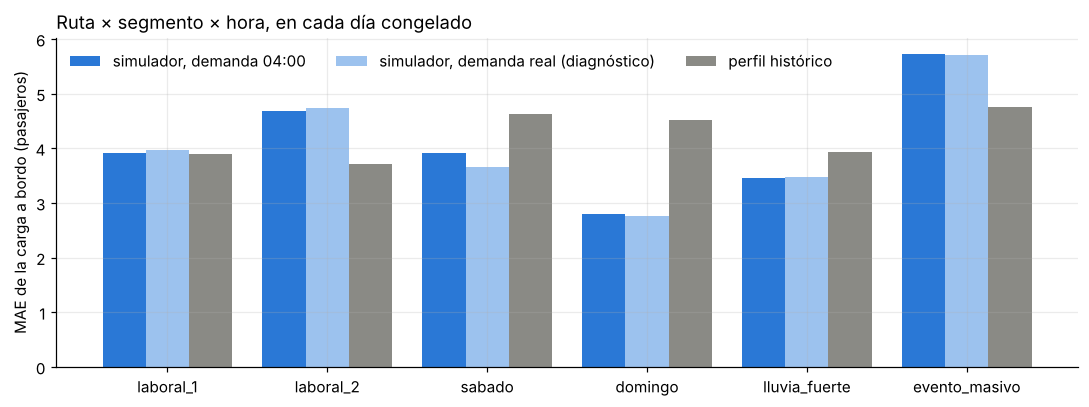

In [3]:
m = pd.read_csv(VAL / "mae_13_4.csv")
t = m[m.idruta == "total"]
display(t[["rol", "fecha", "demanda", "celdas", "a_bordo_obs_media", "mae_sim", "mae_hist", "mae_sim_rel", "mae_hist_rel",
           "cobertura_p5_p95", "corr_sim", "corr_hist"]].round(3))
print({k: (v["replicas"], v["convergio"]) for k, v in res["dias"].items()})
print("Días en que el simulador no es peor que el perfil histórico (demanda 04:00):", res["dias_sim_no_peor"], "de 6")
display(m[(m.idruta != "total") & (m.demanda == "pred")].pivot(index="rol", columns="idruta", values=["mae_sim", "mae_hist"]).round(2))
fig, ax = plt.subplots(figsize=(10, 3.8))
p = t[t.demanda == "pred"].reset_index(drop=True); q = t[t.demanda == "real"].reset_index(drop=True)
xx = np.arange(len(p))
ax.bar(xx - .27, p.mae_sim, .27, color="#2a78d6", label="simulador, demanda 04:00")
ax.bar(xx, q.mae_sim, .27, color="#9cc2ee", label="simulador, demanda real (diagnóstico)")
ax.bar(xx + .27, p.mae_hist, .27, color=GRIS, label="perfil histórico")
ax.set_xticks(xx, p.rol); ax.set_ylabel("MAE de la carga a bordo (pasajeros)"); ax.legend(frameon=False, ncols=3, loc="upper left")
ax.set_title("Ruta × segmento × hora, en cada día congelado", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_4_mae.png", dpi=200, bbox_inches="tight"); plt.show()

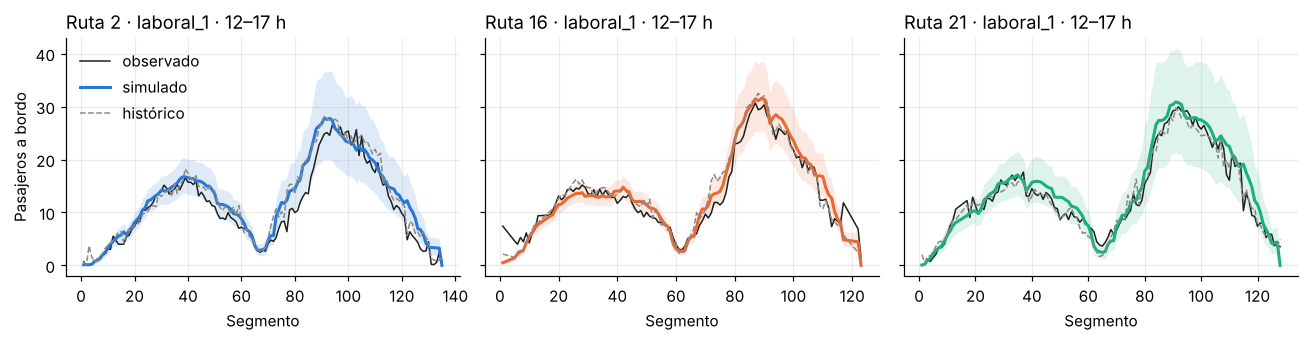

In [4]:
c = pd.read_parquet(VAL / "celdas_13_4.parquet")
c = c[(c.demanda == "pred") & (c.rol == "laboral_1")]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for a, r in zip(ax, (2, 16, 21)):
    y = c[(c.idruta == r) & (c.hora.between(12, 16))].groupby("nro_segmento")[["a_bordo_media", "a_bordo_sim", "a_bordo_hist", "p5", "p95"]].mean()
    a.fill_between(y.index, y.p5, y.p95, color=COL[r], alpha=.15, lw=0)
    a.plot(y.index, y.a_bordo_media, color="#1f1f1d", lw=1, label="observado")
    a.plot(y.index, y.a_bordo_sim, color=COL[r], lw=2, label="simulado")
    a.plot(y.index, y.a_bordo_hist, color=GRIS, lw=1, ls="--", label="histórico")
    a.set_title(f"Ruta {r} · laboral_1 · 12–17 h", loc="left"); a.set_xlabel("Segmento")
ax[0].set_ylabel("Pasajeros a bordo"); ax[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "m13_4_perfil_validacion.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 2 · La ocupación simulada frente a la de los días congelados**
- **Evaluación única, a ciegas:** configuración congelada el 4-nov-2026 a las 22:23 (hash `3fd010ac…`), evaluada a las 22:23–23:25, sin repetir. 6 días, 500 réplicas cada uno, 5.504–6.345 celdas ruta × segmento × hora por día.
- **MAE de la carga a bordo (demanda 04:00), simulador frente a perfil histórico:**

  | Día | MAE (pasajeros) | Resultado |
  |---|---|---|
  | laboral_1 (25-nov) | 3,92 frente a 3,90 | empate (+0,02) |
  | laboral_2 (3-abr) | 4,69 frente a 3,71 | peor |
  | sábado (15-feb) | 3,91 frente a 4,63 | mejor |
  | domingo (27-jul) | 2,79 frente a 4,51 | mejor |
  | lluvia fuerte (13-jun) | 3,45 frente a 3,94 | mejor |
  | evento masivo (25-mar) | 5,73 frente a 4,75 | peor |

- **Criterio del alcance (≤ en 5 de 6 días): no se cumple, 3 de 6.** Se reporta tal cual y no se recalibra mirando estos días (punto 8 del alcance).
- **Dónde gana:** en el fin de semana y la lluvia, donde el perfil histórico (promedio de muchos días) se aleja más del día concreto. **Dónde pierde:** en los laborales y el día del partido.
- **El error viene del motor, no del pronóstico:** con la demanda real del día el MAE queda en 2,77–5,71, casi igual.
- **Dónde está el error:** en la punta de la mañana (6–9 h) el simulador lleva menos gente a bordo de la observada: −7,9 y −9,5 pasajeros en laboral_2 y el día del partido. Esas horas son el 17 % de las celdas y el 26 % del error. Fuera de ellas, el simulador no es peor que el histórico en 4 de 6 días. Hipótesis (no comprobada con estos días): en temporada escolar los viajes de la mañana son más largos que en la muestra de calibración.
- **Forma del perfil:** correlación con lo observado 0,80–0,87, y MAE relativo de 27–34 % de la carga media de la celda.
- **Intervalo:** lo observado cae dentro del P5–P95 de las réplicas en el 44,1–54,7 % de las celdas, lejos de la meta cercana al 90 %. Las réplicas dan la incertidumbre de la media de la celda, no la de lo que se observa en un día con pocas lecturas por celda.

## 3 · Validación: vueltas, pasajeros, cupo y buses pegados

In [5]:
s = pd.read_csv(VAL / "secundarias_13_4.csv")
sp = s[s.demanda == "pred"]
display(sp[["rol", "idruta", "vuelta_mediana_min", "vuelta_mediana_real", "err_vuelta_pct", "pasajeros_por_viaje",
            "pasajeros_por_viaje_real", "err_pasajeros_pct", "pct_viajes_cupo", "pct_viajes_cupo_real"]].round(1))
print("Vuelta ±10 %:", int((sp.err_vuelta_pct.abs() <= 10).sum()), "de", len(sp), "· pasajeros ±10 %:", int((sp.err_pasajeros_pct.abs() <= 10).sum()), "de", len(sp))
display(sp[["rol", "idruta", "cv_intervalos", "cv_intervalos_real", "pct_intervalos_menos_1min", "pct_intervalos_menos_1min_real", "viajes_gps_mitad"]].round(2))
print("Media de los 6 días por ruta (simulado frente al GPS):")
display(sp.groupby("idruta")[["cv_intervalos", "cv_intervalos_real", "pct_intervalos_menos_1min", "pct_intervalos_menos_1min_real"]].mean().round(2))

,rol,idruta,vuelta_mediana_min,vuelta_mediana_real,err_vuelta_pct,pasajeros_por_viaje,pasajeros_por_viaje_real,err_pasajeros_pct,pct_viajes_cupo,pct_viajes_cupo_real
0,laboral_1,16,236.0,241.7,-2.4,92.6,85.8,8.0,32.1,23.4
1,laboral_1,2,250.2,259.0,-3.4,87.2,75.8,15.1,26.4,10.8
2,laboral_1,21,240.7,250.2,-3.8,90.9,85.4,6.5,23.0,14.6
6,laboral_2,16,234.2,233.3,0.4,91.1,91.2,-0.1,27.1,22.8
7,laboral_2,2,246.4,245.5,0.4,88.4,88.3,0.2,28.4,20.4
8,laboral_2,21,238.6,235.5,1.3,93.7,91.8,2.0,28.3,20.2
12,sabado,16,224.0,228.6,-2.0,81.8,85.9,-4.8,18.8,16.1
13,sabado,2,242.0,254.7,-5.0,73.5,81.8,-10.1,10.9,5.5
14,sabado,21,230.3,234.0,-1.6,79.0,78.3,0.9,14.1,8.0
18,domingo,16,172.7,177.7,-2.8,57.3,53.1,7.8,4.7,1.5


Vuelta ±10 %: 18 de 18 · pasajeros ±10 %: 14 de 18


,rol,idruta,cv_intervalos,cv_intervalos_real,pct_intervalos_menos_1min,pct_intervalos_menos_1min_real,viajes_gps_mitad
0,laboral_1,16,0.96,0.96,25.49,20.09,235
1,laboral_1,2,0.95,0.84,14.83,11.20,126
2,laboral_1,21,0.85,0.63,8.76,1.32,77
6,laboral_2,16,0.97,0.96,27.72,28.92,250
7,laboral_2,2,0.95,0.83,15.50,11.50,114
8,laboral_2,21,0.89,0.72,9.45,6.76,75
12,sabado,16,0.95,0.88,24.13,23.56,226
13,sabado,2,0.90,0.70,12.90,8.18,111
14,sabado,21,0.82,0.65,6.85,4.48,68
18,domingo,16,0.85,0.74,16.99,13.29,174


Media de los 6 días por ruta (simulado frente al GPS):


,cv_intervalos,cv_intervalos_real,pct_intervalos_menos_1min,pct_intervalos_menos_1min_real
idruta,,,,
2,0.93,0.77,13.91,7.67
16,0.95,0.90,24.71,21.51
21,0.84,0.64,7.66,4.23


**Escenario de regulación** (agregado tras la validación, punto 8 del alcance; Daganzo 2009, FUENTES B8): en el segmento
de la mitad del circuito, un bus que llega pegado al anterior espera hasta que pase el 60 % del intervalo programado, con un
máximo de 5 min. Es un escenario aparte: la validación no se vuelve a evaluar. Se mide en 30 réplicas de un laboral de
desarrollo (no de validación) y se compara con los 2 laborales de validación del GPS.

In [6]:
iv = pd.read_csv(MC / "intervalos_regulacion_13_4.csv")
q = iv.groupby(["escenario", "idruta"]).agg(cv=("cv_intervalos", "mean"), menos_1min=("pct_intervalos_menos_1min", "mean"),
                                            menos_1min_p5=("pct_intervalos_menos_1min", lambda s: s.quantile(.05)),
                                            menos_1min_p95=("pct_intervalos_menos_1min", lambda s: s.quantile(.95))).round(2)
display(q)
g = sp[sp.rol.isin(["laboral_1", "laboral_2"])].groupby("idruta")[["cv_intervalos_real", "pct_intervalos_menos_1min_real"]].agg(["min", "max"]).round(2)
print("GPS de los 2 laborales de validación (mín–máx):"); display(g)

cv  menos_1min  menos_1min_p5  menos_1min_p95
escenario            idruta                                                 
p85_laboral_central  2       0.90       11.31           8.29           14.86
                     16      0.95       22.79          19.14           27.20
                     21      0.78        6.36           2.99            9.61
real_laboral_central 2       0.94       15.13          10.84           18.98
                     16      0.97       27.57          24.16           32.42
                     21      0.85        8.06           4.42           11.98
sens_regulacion_p85  2       0.79        6.45           3.22            9.12
                     16      0.87       10.28           7.16           13.04
                     21      0.67        3.25           0.00            6.67
sens_regulacion_real 2       0.82        9.16           5.84           12.33
                     16      0.87       13.59          10.81           16.88
                     21      0.76        3.66           1.25            7.51

GPS de los 2 laborales de validación (mín–máx):


cv_intervalos_real       pct_intervalos_menos_1min_real       
                      min   max                            min    max
idruta                                                               
2                    0.83  0.84                          11.20  11.50
16                   0.96  0.96                          20.09  28.92
21                   0.63  0.72                           1.32   6.76

**Conclusión 3 · Vueltas, pasajeros y regularidad frente a lo real**
- **Vuelta mediana:** a ±5 % de la real en las 18 combinaciones de ruta × día (la mayor diferencia es 5,0 %). Meta ±10 %: cumple.
- **Pasajeros por viaje:** a ±10 % en 14 de 18 con la demanda 04:00. Fuera quedan laboral_1 ruta 2 (+15,1 %), sábado ruta 2 (−10,1 %), domingo ruta 21 (+11,1 %) y el partido en la ruta 2 (−11,6 %). Con la demanda real del día entran las 18: esas diferencias son del pronóstico del Entregable 1 para ese día, no del simulador.
- **Viajes que llegan al cupo:** el simulador da más que lo real, +6,2 puntos en la mediana (de −4,6 a +15,6). El simulador cuenta la carga máxima de cada segmento antes de que se baje la gente; en la calle se suben y se bajan a la vez.
- **Buses pegados** (intervalos < 1 min a la mitad del circuito, 6–20 h, media de los 6 días): ruta 2, 13,9 % frente a 7,7 % del GPS; ruta 16, 24,7 % frente a 21,5 %; ruta 21, 7,7 % frente a 4,2 %. En la calle los conductores se regulan; el motor no.
- **Escenario de regulación** (punto 8 del alcance, aparte de la validación): un bus pegado espera en la mitad del circuito hasta el 60 % del intervalo programado, máximo 5 min. En 30 réplicas de un laboral de desarrollo, los intervalos < 1 min pasan de 15,1 → 9,2 % en la ruta 2, 27,6 → 13,6 % en la 16 y 8,1 → 3,7 % en la 21. En los 2 laborales de validación, el GPS da 11,2–11,5 %, 20,1–28,9 % y 1,3–6,8 %: con la regulación el motor queda en el rango del GPS en las rutas 2 y 21, y algo por debajo en la 16.

## 4 · Monte Carlo: los planes con su intervalo

Réplicas por escenario: {'min': 350.0, '50%': 500.0, 'max': 500.0} · convergieron antes de 500: 2 de 54


,tipo,plan,espera_media_min,espera_p90_min,pct_dejados_bus_lleno,pct_viajes_cupo,vuelta_mediana_min,buses_a_la_vez,salidas
0,laboral,real,5.7 [5.0–7.1],12.3 [11.1–14.0],6.5 [3.5–9.9],24.1 [13.3–36.3],239.9 [237.5–242.6],175.5 [172.0–179.0],557.0 [557.0–557.0]
1,laboral,p100,8.4 [6.9–11.6],18.0 [15.4–22.6],12.3 [7.3–17.9],58.7 [35.3–84.8],242.7 [239.4–245.8],124.0 [122.0–127.0],382.0 [382.0–382.0]
2,laboral,p85,6.5 [5.8–7.9],14.2 [12.8–16.1],8.2 [4.6–12.4],38.5 [21.1–58.9],242.8 [240.0–245.9],145.4 [143.0–148.0],450.0 [450.0–450.0]
3,laboral,p70,5.2 [4.7–6.3],11.3 [10.5–12.3],4.7 [2.3–7.5],21.2 [10.6–33.5],242.6 [240.1–245.4],176.2 [173.0–180.0],547.0 [547.0–547.0]
4,sabado,real,5.9 [5.3–7.0],12.6 [11.8–13.8],4.1 [2.2–6.1],16.7 [9.4–24.7],229.3 [226.7–231.8],150.9 [147.0–154.0],478.0 [478.0–478.0]
5,sabado,p100,8.9 [8.0–10.4],19.3 [17.2–21.7],10.1 [6.3–14.3],54.8 [34.8–76.5],229.0 [226.1–232.1],95.8 [93.0–98.0],302.0 [302.0–302.0]
6,sabado,p85,7.3 [6.7–8.0],15.7 [14.5–17.1],6.4 [3.5–9.5],34.7 [20.3–50.4],229.0 [226.1–232.0],112.3 [110.0–115.0],355.0 [355.0–355.0]
7,sabado,p70,6.0 [5.5–7.0],12.9 [12.1–13.9],3.7 [2.1–5.7],19.0 [10.7–28.3],228.9 [226.4–231.9],135.4 [132.9–139.0],431.0 [431.0–431.0]
8,domingo,real,6.4 [6.0–7.3],13.6 [12.8–14.6],1.5 [0.4–3.0],6.3 [2.2–12.0],183.7 [181.5–185.7],89.1 [87.0–91.0],358.0 [358.0–358.0]
9,domingo,p100,12.9 [11.4–15.9],26.5 [23.1–31.4],8.7 [3.7–14.8],51.4 [22.2–84.2],182.2 [178.9–185.1],43.9 [42.0–45.0],171.0 [171.0–171.0]


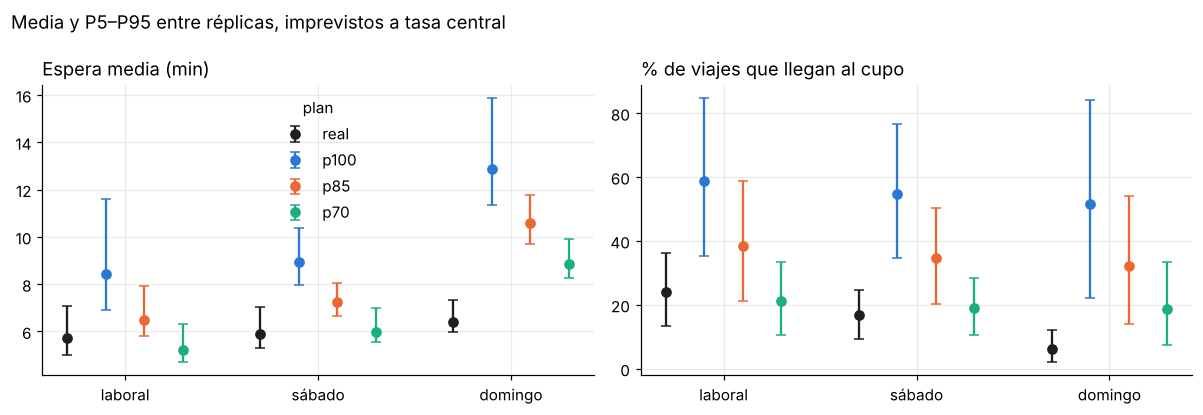

In [7]:
r = pd.read_csv(MC / "resumen_13_4.csv")
print("Réplicas por escenario:", pd.Series({k: v["replicas"] for k, v in man["escenarios"].items()}).describe()[["min", "50%", "max"]].to_dict(),
      "· convergieron antes de 500:", sum(v["convergio"] for v in man["escenarios"].values()), "de", len(man["escenarios"]))
ind = ["espera_media_min", "espera_p90_min", "pct_dejados_bus_lleno", "pct_viajes_cupo", "vuelta_mediana_min", "buses_a_la_vez", "salidas"]
filas = []
for t in ("laboral", "sabado", "domingo"):
    for p in ("real", "p100", "p85", "p70"):
        x = r[(r.escenario == f"{p}_{t}_central") & (r.idruta == "total") & r.indicador.isin(ind)].set_index("indicador")
        filas.append({"tipo": t, "plan": p, **{k: f"{x.media[k]:.1f} [{x.p5[k]:.1f}–{x.p95[k]:.1f}]" for k in ind}})
display(pd.DataFrame(filas))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, k, tit in zip(ax, ("espera_media_min", "pct_viajes_cupo"), ("Espera media (min)", "% de viajes que llegan al cupo")):
    for j, t in enumerate(("laboral", "sabado", "domingo")):
        for i, p in enumerate(("real", "p100", "p85", "p70")):
            x = r[(r.escenario == f"{p}_{t}_central") & (r.idruta == "total") & (r.indicador == k)].iloc[0]
            xx = j + (i - 1.5) * .2
            a.errorbar(xx, x.media, yerr=[[x.media - x.p5], [x.p95 - x.media]], fmt="o", color=CP[p], capsize=3, label=p if j == 0 else None)
    a.set_xticks(range(3), ("laboral", "sábado", "domingo")); a.set_title(tit, loc="left")
ax[0].legend(frameon=False, title="plan"); fig.suptitle("Media y P5–P95 entre réplicas, imprevistos a tasa central", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "m13_4_planes.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 4 · El plan del proyecto ahorra buses; el precio es más espera y más buses llenos**
- **Imprevistos a tasa central, 500 réplicas por escenario** (media de buses a la vez y de espera):

  | Plan | Laboral | Sábado | Domingo |
  |---|---|---|---|
  | Real (`tb_despachos`) | 175 buses · 5,7 min | 151 buses · 5,9 min | 89 buses · 6,4 min |
  | Proyecto al 100 % | 124 buses · 8,4 min | 96 buses · 8,9 min | 44 buses · 12,9 min |
  | Proyecto al 85 % (central) | 145 buses · 6,5 min | 112 buses · 7,3 min | 51 buses · 10,6 min |
  | Proyecto al 70 % | 176 buses · 5,2 min | 135 buses · 6,0 min | 62 buses · 8,8 min |

- **Al 85 %:** 17 % menos buses a la vez en el laboral (42 % en el domingo), con 0,8 min más de espera media y 38,5 % de viajes al cupo frente a 24,1 % del plan real.
- **Al 70 %, con los mismos buses a la vez que el plan real en el laboral,** la espera baja a 5,2 min y los viajes al cupo a 21,2 %: el plan por carga máxima reparte mejor las salidas en las horas de más gente.
- **El domingo es donde más se ahorra:** el plan real pone 1,7 veces los buses a la vez del proyecto al 85 %, para menos de la mitad de los pasajeros del laboral (21.299 frente a 47.189).
- **Se lee como comparación, no como nivel:** el % de viajes al cupo del simulador está por encima del real (conclusión 3), así que el valor absoluto es pesimista; la diferencia entre planes es lo que cuenta. Elegir el plan es del Módulo 14.

## 5 · Imprevistos y demanda: cuánto mueven los resultados

In [8]:
ind2 = ["espera_media_min", "pct_viajes_cupo", "vuelta_mediana_min", "vuelta_p90_min", "minutos_imprevistos", "pct_viajes_con_imprevisto"]
filas = []
for p in ("real", "p85"):
    for e in (f"{p}_laboral_baja", f"{p}_laboral_central", f"{p}_laboral_alta", f"{p}_laboral_demanda_real"):
        x = r[(r.escenario == e) & (r.idruta == "total") & r.indicador.isin(ind2)].set_index("indicador")
        filas.append({"escenario": e, **{k: f"{x.media[k]:.1f} [{x.p5[k]:.1f}–{x.p95[k]:.1f}]" for k in ind2}})
display(pd.DataFrame(filas))

,escenario,espera_media_min,pct_viajes_cupo,vuelta_mediana_min,vuelta_p90_min,minutos_imprevistos,pct_viajes_con_imprevisto
0,real_laboral_baja,5.6 [5.0–6.8],23.9 [13.1–36.6],239.8 [237.4–242.4],283.5 [279.1–287.7],145.8 [0.0–759.1],8.8 [0.2–32.0]
1,real_laboral_central,5.7 [5.0–7.1],24.1 [13.3–36.3],239.9 [237.5–242.6],283.6 [279.5–287.9],259.6 [0.0–1077.8],14.2 [0.4–39.7]
2,real_laboral_alta,5.8 [5.0–7.2],24.1 [13.5–36.5],240.1 [237.5–242.8],283.8 [279.2–288.9],385.0 [7.5–1260.2],19.4 [2.0–44.5]
3,real_laboral_demanda_real,5.6 [4.9–7.0],22.9 [12.6–34.7],239.9 [237.4–242.4],283.8 [279.8–287.9],260.5 [0.0–1077.4],14.3 [0.4–38.5]
4,p85_laboral_baja,6.5 [5.8–7.5],38.4 [21.8–57.3],242.6 [239.9–245.4],286.0 [281.3–291.1],121.2 [0.0–652.6],8.5 [0.0–28.5]
5,p85_laboral_central,6.5 [5.8–7.9],38.5 [21.1–58.9],242.8 [240.0–245.9],286.3 [281.6–291.2],210.7 [0.0–884.8],13.8 [0.4–38.2]
6,p85_laboral_alta,6.7 [5.8–8.5],38.6 [21.5–57.1],242.9 [240.0–246.1],286.4 [281.4–291.4],360.0 [6.0–1225.4],20.8 [2.9–49.3]
7,p85_laboral_demanda_real,6.4 [5.7–7.4],36.5 [20.4–54.5],242.8 [240.2–245.6],285.9 [281.4–291.0],211.8 [0.0–885.8],13.8 [0.4–37.8]


**Conclusión 5 · Las tasas de imprevistos y la demanda real**
- **Imprevistos baja, central y alta** (laboral, plan real): tocan el 8,8 %, el 14,2 % y el 19,4 % de los viajes, con 146 min, 260 min y 385 min perdidos en el día en las 3 rutas.
- **Casi no mueven el día:** la vuelta mediana va de 239,8 a 240,1 min y la espera media de 5,6 a 5,8 min. Igual que en la 13.3, un imprevisto pesa en el viaje que toca, no en la mediana del día.
- **Demanda real en vez de la del modelo 04:00:** los pasajeros del día cambian −2,0 % en el laboral, −1,1 % en el sábado y −5,4 % en el domingo, y la comparación entre planes no cambia de orden.

## 6 · Sensibilidades

In [9]:
base = {"real": "real_laboral_central", "p85": "p85_laboral_central"}
filas = []
for e in man["escenarios"]:
    if not e.startswith("sens_"):
        continue
    p = e.rsplit("_", 1)[1]
    b = "sens_lluvia_base_" + p if "umbral" in e else base[p]
    if e.startswith("sens_lluvia_base"):
        b = base[p]
    for k in ("espera_media_min", "pct_viajes_cupo", "vuelta_mediana_min", "minutos_imprevistos"):
        x = r[(r.escenario == e) & (r.idruta == "total") & (r.indicador == k)].iloc[0]
        y = r[(r.escenario == b) & (r.idruta == "total") & (r.indicador == k)].iloc[0]
        filas.append({"sensibilidad": e, "frente_a": b, "indicador": k, "valor": x.media, "base": y.media,
                      "cambio_pct": 100 * (x.media / y.media - 1) if y.media else np.nan})
sens = pd.DataFrame(filas)
display(sens.pivot_table(index=["sensibilidad", "frente_a"], columns="indicador", values="cambio_pct").round(1))
w = []
for e in ("real_laboral_central", "sens_sin_variacion_dia_real", "p85_laboral_central", "sens_sin_variacion_dia_p85"):
    x = r[(r.escenario == e) & (r.idruta == "total")].set_index("indicador")
    w.append({"escenario": e, **{k: f"{x.p5[k]:.1f}–{x.p95[k]:.1f}" for k in ("pasajeros", "espera_media_min", "pct_viajes_cupo", "pct_dejados_bus_lleno")}})
print("P5–P95 con y sin el factor de demanda del día:"); display(pd.DataFrame(w))

,indicador,espera_media_min,minutos_imprevistos,pct_viajes_cupo,vuelta_mediana_min
sensibilidad,frente_a,,,,
sens_cota_inferior_p85,p85_laboral_central,-6.7,1.5,-31.1,-0.0
sens_cota_inferior_real,real_laboral_central,-7.3,0.2,-32.5,0.0
sens_error_duracion_p85,p85_laboral_central,0.9,57.3,0.3,0.0
sens_error_duracion_real,real_laboral_central,0.8,57.5,0.1,0.1
sens_google_p85,p85_laboral_central,4.7,1.8,4.8,5.6
sens_google_real,real_laboral_central,2.8,0.7,2.0,5.2
sens_lluvia_base_p85,p85_laboral_central,3.9,9.0,0.5,1.4
sens_lluvia_base_real,real_laboral_central,13.0,21.4,14.7,0.7
sens_lluvia_umbral_20_p85,sens_lluvia_base_p85,-4.1,-6.3,-1.2,0.1


P5–P95 con y sin el factor de demanda del día:


,escenario,pasajeros,espera_media_min,pct_viajes_cupo,pct_dejados_bus_lleno
0,real_laboral_central,39451.9–55046.2,5.0–7.1,13.3–36.3,3.5–9.9
1,sens_sin_variacion_dia_real,46859.9–47568.1,5.1–6.6,21.2–25.5,5.3–7.4
2,p85_laboral_central,39350.9–54880.6,5.8–7.9,21.1–58.9,4.6–12.4
3,sens_sin_variacion_dia_p85,46790.8–47513.7,5.9–7.5,34.9–40.7,6.9–9.4


**Conclusión 6 · Los supuestos que más pesan**
- **La demanda pesa más que todo lo demás.** Con la cota inferior (las salidas que no quedaron en la maestra no llevan a nadie), los pasajeros cambian −11,3 % y los viajes al cupo bajan a 16,2 % (24,1 % central).
- **Los tiempos de Google** cambian la forma del día: la vuelta mediana sube +5,2 % con el plan real y +5,6 % con el del proyecto al 85 %. El Módulo 11 ya mostró que Google aporta poco al pronóstico; queda como sensibilidad.
- **Imprevistos:** con error en la duración estimada para decidir el desvío, los minutos perdidos suben +58 % (los buses esperan cierres que no acaban cuando se creía), pero la espera casi nada (+0,04 min). Con todas las obras como cierre, la espera sube +6,1 %. La σ de la duración (0,25 o 1,0) cambia los minutos perdidos y casi nada más.
- **Lluvia (19-sep-2025):** con umbral de arroyo de 20 mm/h no se forman los arroyos y los viajes con imprevisto bajan a 13,5 % (17,6 % con el umbral de 10). Con 5 mm/h el resultado es idéntico al de 10: ese día la única hora sobre 5 mm/h también pasó de 10.
- **Sin el factor de demanda del día:** las medias casi no cambian; los intervalos se estrechan (conclusión 1).
- **Regulación:** reduce los buses pegados a la mitad (conclusión 3) con poco costo, +0,6 min de vuelta mediana, y espera y cupo casi iguales.

## 7 · Rapidez, reproducibilidad y lo que queda para el gemelo digital

In [10]:
seg = pd.Series({k: v["segundos"] / v["replicas"] for k, v in man["escenarios"].items()})
print(f"Segundos de reloj por réplica: mediana {seg.median():.2f}, máximo {seg.max():.2f}")
print("Réplicas en total:", sum(v["replicas"] for v in man["escenarios"].values()) + sum(v["replicas"] for v in res["dias"].values()))
print("Pasos de la réplica representativa guardados para la 13.5:", len(list(MC.glob("*_pasos.parquet"))), "escenarios +",
      len(list(VAL.glob("pasos_*_representativa.parquet"))), "días de validación")
print("Python", sys.version.split()[0])

Segundos de reloj por réplica: mediana 1.04, máximo 1.27
Réplicas en total: 32750
Pasos de la réplica representativa guardados para la 13.5: 54 escenarios + 6 días de validación
Python 3.13.16


**Conclusión 7 · Cientos de réplicas por escenario, reproducibles**
- **54 escenarios, 26.750 réplicas** en el PC de la Persona 3 (10 procesos, 6,5 h de reloj); con la validación, 32.750 réplicas en total. Como mucho 1,27 s de reloj por réplica; meta ≤ 30 s por día.
- **Convergencia:** solo los 2 escenarios sin factor del día llegan al 1 % antes de 500 réplicas (350 y 400). Con el factor, a las 500 réplicas la mitad del IC95 % queda en 1,2 % de la media para la espera y 2,6 % para el % de viajes al cupo (mediana de los escenarios), y por debajo de 0,1 % para la vuelta. El criterio del alcance lo admite («o 500 réplicas»).
- **Reproducible:** misma semilla, mismos indicadores con 1 o 2 procesos (`tests_13_4.py` 13/13). Entre computadores cambia un poco: de 50 réplicas del Monte Carlo (corrido en el PC, Windows) repetidas en Linux, 44 y 45 salen idénticas; en las demás, una diferencia de redondeo en el último decimal hace que la réplica tome otro camino. Las medias coinciden dentro de su IC95 % (espera media 5,67 frente a 5,65 min). Después de la evaluación se agregaron al motor las opciones de las sensibilidades y la regulación, inactivas por defecto; con el código actual, los 6 días de validación dan las mismas réplicas que en la evaluación (`enmiendas_codigo_13_4.json`).
- **Para la 13.5:** se guardaron los pasos de la réplica más cercana a la mediana de cada escenario (54) y de cada día de validación (6), para el gemelo digital.

## Síntesis · Subfase 13.4
- **Monte Carlo listo:** `src/simulation/monte_carlo_engine.py` corre N réplicas hasta converger y da cada indicador con su media y su P5–P95, con el factor de demanda del día (8–14 % de variación entre días). 54 escenarios y 26.750 réplicas.
- **Validación en una sola evaluación, a ciegas:** la vuelta mediana queda a ±5 % de la real en 18/18 ruta × día. Los pasajeros por viaje cumplen en 14 de 18 con la demanda 04:00 y en 18/18 con la real.
- **Criterio principal, no cumplido:** el MAE de la ocupación es menor o igual al del perfil histórico en 3 de 6 días (5 exigidos). Gana en el fin de semana y la lluvia; pierde en los laborales y el partido, por la punta de la mañana.
- **Otros hallazgos:**
  - el intervalo P5–P95 cubre el 44,1–54,7 % de las celdas;
  - el motor exagera los viajes al cupo (+6,2 puntos);
  - el motor exagera los buses pegados; con la regulación queda en el rango del GPS en 2 de 3 rutas.
- **Lo que dicen los planes:** el del proyecto al 85 % usa 17 % menos buses a la vez en el laboral, con 0,8 min más de espera. Al 70 %, con los mismos buses que el plan real, espera menos. Lo que más pesa es la demanda.
- **Decisiones de la Persona 3:** reportar la validación tal cual y agregar la regulación como escenario; no se re-evalúan los días de validación. Las decisiones de Claude V1–V11 quedaron confirmadas al cerrar la subfase (5-nov-2026, 11:02; detalle en `revisiones/revision_13_4.md`).
- **Siguiente:** la 13.5 (gemelo digital) usa los pasos guardados de cada escenario.

---
# Parte 15 · Módulo 13 · Subfase 13.4b · Mejoras
*Notebook original: `modulo13/subfase_13_4b_mejoras.ipynb`*

# SOBUSA · Módulo 13 · Subfase 13.4b — Mejoras del simulador

**Persona 3.** La 13.4 cerró con su resultado oficial (3 de 6 días). Antes de la 13.5 se probaron **6 mejoras del
simulador, una por ronda**. Cada ronda tuvo su regla escrita y congelada (con hashes del código y de los insumos) antes
de simular, se probó **una sola vez** en los 3 días de control de la 13.2 (19-ago, 20-sep y 9-nov-2025) y se decidió
aplicando la regla tal cual. Los 6 días de validación nunca se usaron para calibrar. Al final: una reevaluación
«no ciega» de los días de validación y el Monte Carlo de los 54 escenarios con lo adoptado. Alcance aprobado:
`revisiones/alcance_13_4b.md`. Solo se tocó el simulador (Módulo 13); los módulos anteriores no cambian.

| Ronda | Mejora | Regla | Decisión |
|---|---|---|---|
| 1 | Subidas y bajadas por ruta × tipo de día × franja, con 5.400 viajes nuevos de 2025 (E3) | `regla_13_4b.json` | No se adopta |
| 2 | Tiempo de parada por pasajero + medir la carga como el sensor (por tiempo) | `regla_13_4b_r2.json` | Se adopta |
| 3 | Regulación de buses pegados | `regla_13_4b_r3.json` | No por la regla; opción, y central en el Monte Carlo por decisión de la Persona 3 |
| 4 | Primero bajan, luego suben | `regla_13_4b_r4.json` | Se adopta |
| 5 | Factor de velocidad del día | `regla_13_4b_r5.json` | Se adopta |
| 6 | Intervalo predictivo por celda | `regla_13_4b_r6.json` | No se adopta; opción |

Todas las mejoras son opciones del motor (`ajustes`), inactivas por defecto: sin ellas el motor da lo mismo que en las
subfases cerradas (pruebas c y f de `tests_13_4b.py`).

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, ".")
from src.simulation import escenario as E

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
SAL = Path("datos_13/mejoras_13_4b"); NC = SAL / "reevaluacion_no_ciega"
MC0, MC = Path("datos_13/montecarlo_13_4"), Path("datos_13/montecarlo_13_4b")
VAL = Path("datos_13/validacion_13_4"); FIG = Path("resultados_13"); FIG.mkdir(exist_ok=True)
COL = {2: "#2a78d6", 16: "#eb6834", 21: "#1baf7a"}; GRIS = "#8a8a85"
CP = {"real": "#1f1f1d", "p100": "#2a78d6", "p85": "#eb6834", "p70": "#1baf7a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
                     "font.size": 10, "figure.dpi": 110})
sha = lambda p: __import__("hashlib").sha256(Path(p).read_bytes()).hexdigest()
filas = []
for k, (regla, dec, col) in {"r1": ("regla_13_4b.json", "decision_13_4b.json", "adoptar_v2"),
                             "r2": ("regla_13_4b_r2.json", "decision_13_4b_r2.json", "adoptar_A"),
                             "r3": ("regla_13_4b_r3.json", "decision_13_4b_r3.json", "adoptar_regulacion"),
                             "r4": ("regla_13_4b_r4.json", "decision_13_4b_r4.json", "adoptar_bajan_primero"),
                             "r5": ("regla_13_4b_r5.json", "decision_13_4b_r5.json", "adoptar_velocidad"),
                             "r6": ("regla_13_4b_r6.json", "decision_13_4b_r6.json", "adoptar")}.items():
    rg, d = json.loads(Path(regla).read_text(encoding="utf-8")), json.loads((SAL / dec).read_text(encoding="utf-8"))
    filas.append({"ronda": k, "regla_congelada": rg["creado"], "decision": d["creado"], "hash_regla_coincide": d["regla_sha256"] == sha(regla),
                  "adopta": d[col], "criterios": d.get("criterios", d.get("dias_80_95"))})
display(pd.DataFrame(filas))

,ronda,regla_congelada,decision,hash_regla_coincide,adopta,criterios
0,r1,2026-11-05T11:26:38,2026-11-05T11:49:11,True,False,"{'a_mae_total': False, 'b_mae_6_9_laboral': Fa..."
1,r2,2026-11-05T12:47:04,2026-11-05T13:10:15,True,True,"{'a_mae_total': True, 'b_mae_6_9_laboral': Tru..."
2,r3,2026-11-05T13:13:53,2026-11-05T13:26:21,True,False,"{'a_mae_total': False, 'b_mae_6_9_laboral': Tr..."
3,r4,2026-11-05T13:30:57,2026-11-05T13:43:27,True,True,"{'a_mae_total': True, 'b_mae_6_9_laboral': Tru..."
4,r5,2026-11-05T13:47:57,2026-11-05T14:00:52,True,True,"{'a_cobertura': True, 'b_mejor_cv': True, 'c_m..."
5,r6,2026-11-05T14:02:21,2026-11-05T14:10:16,True,None,"{'muestreo': 0, 'muestreo_dia': 0}"


## 1 · Ronda 1: subidas y bajadas con más datos, por tipo de día

La hipótesis de la 13.4 era que en la punta de la mañana la gente viaja más lejos. Se extrajeron las lecturas de
5.400 viajes de 2025 (E3: 100 por ruta × tipo de día × franja, sin días de validación ni de control) y de todas las
salidas de los 3 días de control (E4: 1.406 salidas), y se armó un reparto por ruta × tipo × franja (parámetros v2).

In [2]:
d1 = json.loads((SAL / "decision_13_4b.json").read_text(encoding="utf-8"))["detalle"]
t1 = pd.DataFrame({"MAE v1": d1["mae_total"]["v1"], "MAE v2": d1["mae_total"]["v2"], "histórico": d1["mae_hist_v1"],
                   "MAE 6–9 h v1": d1["mae_6_9"]["v1"], "MAE 6–9 h v2": d1["mae_6_9"]["v2"]})
display(t1.round(2))
ext = json.loads(Path("datos_13/extraccion/ids_13_4b.json").read_text(encoding="utf-8"))
print("Muestra congelada:", ext.get("creado"), "· hash de los ids", ext["ids_sha256"][:12], "· E3", ext["e3_viajes"], "viajes elegidos · E4", ext["e4_viajes"], "salidas")
import pyarrow.parquet as pq, pyarrow.compute as pc
for f in ("e3_lecturas_13_4b", "e4_lecturas_control_13_4b"):
    tb = pq.read_table(f"datos_13/extraccion/{f}.parquet", columns=["idprogramacion"])
    print(f"  {f}: {tb.num_rows:,} lecturas de {len(pc.unique(tb['idprogramacion'])):,} viajes")

,MAE v1,MAE v2,histórico,MAE 6–9 h v1,MAE 6–9 h v2
control_laboral,5.28,5.89,4.17,9.31,10.81
control_sabado,4.05,4.79,4.93,5.48,7.14
control_domingo,2.96,3.06,4.35,2.83,3.08


Muestra congelada: 2026-11-05T11:11:29 · hash de los ids dceae6b19044 · E3 5400 viajes elegidos · E4 1406 salidas
  e3_lecturas_13_4b: 1,575,316 lecturas de 5,232 viajes
  e4_lecturas_control_13_4b: 455,905 lecturas de 1,400 viajes


**Conclusión 1 · Más datos de dónde se bajan no mejoran: la hipótesis de la mañana se descarta**
- **Muestra nueva:** 5.400 viajes de 2025 elegidos al azar, 100 por ruta × tipo de día × franja (E3: 1.575.316 lecturas de 5.232 viajes), y todas las salidas de los 3 días de control (E4: 455.905 lecturas de 1.400 viajes). Ninguno es de validación.
- **Con el reparto por tipo de día (v2) el simulador empeora en los 3 días de control:** MAE 5,28 → 5,89 en el laboral, 4,05 → 4,79 en el sábado y 2,96 → 3,06 en el domingo; de 6 a 9 h del laboral, 9,31 → 10,81. La regla dejó v1.
- **Lo que enseñó:** en el laboral de control, un pasajero de la mañana viaja casi lo mismo que en el reparto de siempre (18,8 segmentos frente a ~18; alcance, resultado de la ronda 1). La falta de gente a bordo no venía de dónde se bajan, y separar por tipo de día solo agregó ruido.

## 2 · Ronda 2: el tiempo de parada y medir como el sensor

En la calle, cada parada y cada pasajero que sube o baja alargan el tramo; el motor usaba el tiempo medio del tramo,
igual para un bus lleno que para uno vacío. Con E3 se estimó el costo de parar (c) y el de cada movimiento (b): el tramo
tarda t_mov + c × (hubo parada) + b × (suben + bajan), con t_mov = t_med − (c × prob. de parada + b × movimientos medios),
piso 0,3 × t_med, para no contar dos veces la parada que ya trae t_med. Además, el motor guarda la carga ponderada por el
tiempo en el tramo, que es como la mide el sensor (una lectura cada ~45 s); desde esta ronda es la medida principal.

In [3]:
pa = json.loads((SAL / "parada_13_4b.json").read_text(encoding="utf-8"))
print(f"c = {pa['c_s']} s (IC95 % {pa['ic95_bootstrap_viajes']['c_s']}), b = {pa['b_s']} s ({pa['ic95_bootstrap_viajes']['b_s']}) · "
      f"{pa['pares']:,} pares de segmentos de {pa['viajes']:,} viajes · parada = {pa['pct_tiempo_que_es_parada']} % del tiempo de los tramos")
display(pd.DataFrame(pa["dt_por_movimientos"]).T.rename_axis("movimientos en el segmento"))
display(pd.DataFrame(pa["por"]["ruta"], index=["c_s", "b_s"]).T.rename_axis("ruta"))
d2 = json.loads((SAL / "decision_13_4b_r2.json").read_text(encoding="utf-8"))["detalle"]
display(pd.concat({v: pd.DataFrame(d2[v]).T for v in ("v1", "A")}, axis=1).round(2))

c = 8.891 s (IC95 % [8.397, 9.258]), b = 8.6 s ([8.425, 8.797]) · 450,190 pares de segmentos de 5,223 viajes · parada = 14.02 % del tiempo de los tramos


,n,dt_mediana_s
movimientos en el segmento,,
"(-1, 0]",206983.0,60.0
"(0, 2]",162327.0,102.0
"(2, 5]",62883.0,128.0
"(5, 10]",15842.0,162.0
"(10, 20]",2069.0,208.0
"(20, 500]",86.0,270.0


,c_s,b_s
ruta,,
2,8.88,8.62
16,9.38,8.45
21,8.42,8.75


v1                                                                     A                                                           
                mae_tiempo mae_paso mae_hist mae_tiempo_6_9 mae_paso_6_9 sesgo_tiempo mae_tiempo mae_paso mae_hist mae_tiempo_6_9 mae_paso_6_9 sesgo_tiempo
control_laboral       5.26     5.28     4.17           9.27         9.31        -3.66       5.09     5.28     4.16           9.04         9.33        -3.12
control_sabado        4.05     4.05     4.93           5.45         5.48        -2.21       3.98     4.07     4.93           5.24         5.48        -1.72
control_domingo       2.96     2.96     4.35           2.83         2.83        -1.10       2.91     2.92     4.35           2.88         2.89        -0.80

**Conclusión 2 · Parar cuesta 8,9 s y cada pasajero 8,6 s: el motor gana física y algo de ocupación**
- **Medido en 450.190 pares de segmentos de 5.223 viajes (E3):** parar cuesta **8,9 s** (IC95 % 8,4–9,3) y cada pasajero que sube o baja, **8,6 s** (8,4–8,8). Un tramo sin movimientos tarda 60 s en la mediana; con 5–10 movimientos, 162 s. La parada es el 14 % del tiempo de los tramos.
- **Ocupación en los días de control (MAE por tiempo), sin → con parada:** laboral 5,26 → 5,09; sábado 4,05 → 3,98; domingo 2,96 → 2,91; 6–9 h del laboral 9,27 → 9,04. La falta de gente a bordo del laboral baja de −3,66 a −3,12 pasajeros.
- **Medir como el sensor** (carga ponderada por el tiempo en el tramo) es desde aquí la medida principal, decidida por principio antes de correr. Sin la parada casi no cambia nada (5,28 → 5,26); con ella, sí, porque los buses llenos ahora van más lento.
- **Efecto secundario:** los buses se pegan más (conclusión 3).

## 3 · Ronda 3: regulación de buses pegados

In [4]:
d3 = json.loads((SAL / "decision_13_4b_r3.json").read_text(encoding="utf-8"))
display(pd.concat({v: pd.DataFrame(d3["detalle"][v]).T[["mae_tiempo", "mae_tiempo_6_9", "sesgo_tiempo"]] for v in ("A", "AR")}, axis=1).round(3))
pg = pd.concat({v: pd.DataFrame(d3["pegados"][v]).set_index(["rol", "idruta"]) for v in ("A", "AR")}, axis=1)
display(pg.round(1))
print("Criterios:", d3["criterios"], "→ adoptar:", d3["adoptar_regulacion"])

A                                     AR                            
                mae_tiempo mae_tiempo_6_9 sesgo_tiempo mae_tiempo mae_tiempo_6_9 sesgo_tiempo
control_laboral      5.090          9.036       -3.122      5.109          9.030       -3.092
control_sabado       3.977          5.242       -1.720      3.965          5.217       -1.707
control_domingo      2.910          2.885       -0.796      2.927          2.870       -0.792

A                                                       AR                               
                       pct_intervalos_menos_1min pct_intervalos_menos_1min_real pct_intervalos_menos_1min pct_intervalos_menos_1min_real
rol             idruta                                                                                                                  
control_laboral 16                          35.1                           19.8                      21.2                           19.8
                2                           22.1                            8.8                      14.3                            8.8
                21                          15.4                            5.7                       8.9                            5.7
control_sabado  16                          31.2                           17.8                      16.3                           17.8
                2                           19.5                            6.5                      13.0                            6.5
                21                          12.4                            3.0                       6.9                            3.0
control_domingo 16                          26.6                            7.6                      15.7                            7.6
                2                           16.2                           10.0                      10.7                           10.0
                21                           8.3                            1.6                       3.6                            1.6

Criterios: {'a_mae_total': False, 'b_mae_6_9_laboral': True, 'c_pegados': True, 'd_vuelta': True, 'e_pasajeros': True} → adoptar: False


**Conclusión 3 · La regulación arregla los buses pegados, no la ocupación**
- **Con la parada, sin regulación,** un bus lleno se atrasa, encuentra más gente y se atrasa más: en el laboral de control, los intervalos < 1 min de la ruta 16 llegan a 35,1 % (GPS 19,8 %).
- **Con la regulación de la 13.4** (el bus pegado espera en la mitad del circuito hasta el 60 % de su intervalo, máximo 5 min; Daganzo, 2009) quedan más cerca del GPS en **9 de 9** ruta × día: ruta 16 del laboral 35,1 → 21,2 %, ruta 2 22,1 → 14,3 % (GPS 8,8), ruta 21 15,4 → 8,9 % (GPS 5,7).
- **La ocupación no cambia** (±0,02 pasajeros: 5,09 → 5,11 en el laboral). La regla pedía que el MAE bajara en 2 de 3 días y bajó en 1: **no se adoptó por la regla.**
- **Decisión de la Persona 3** (5-nov, 15:43, después de ver los resultados): entra al escenario central del Monte Carlo final, rotulada.

## 4 · Ronda 4: primero bajan, luego suben

In [5]:
d4 = json.loads((SAL / "decision_13_4b_r4.json").read_text(encoding="utf-8"))
cu = pd.concat({v: pd.DataFrame(d4["cupo"][v]).set_index(["rol", "idruta"]) for v in ("A", "AB")}, axis=1)
cu[("dif", "A")] = cu[("A", "pct_viajes_cupo")] - cu[("A", "pct_viajes_cupo_real")]
cu[("dif", "AB")] = cu[("AB", "pct_viajes_cupo")] - cu[("AB", "pct_viajes_cupo_real")]
display(cu.round(1))
print("Exceso mediano sobre lo real: A", round(cu[("dif", "A")].median(), 1), "· AB", round(cu[("dif", "AB")].median(), 1),
      "· más cerca del real en", d4["cupo_mas_cerca_real"], "de 9 · cambio del MAE:", d4["cambio_mae_total"])

A                                   AB                       dif     
                       pct_viajes_cupo pct_viajes_cupo_real pct_viajes_cupo pct_viajes_cupo_real    A   AB
rol             idruta                                                                                    
control_laboral 16                28.7                 25.0            25.7                 25.0  3.7  0.7
                2                 21.5                 21.0            19.6                 21.0  0.5 -1.4
                21                25.1                 21.5            22.9                 21.5  3.6  1.4
control_sabado  16                20.3                 18.0            17.9                 18.0  2.3 -0.1
                2                 13.9                  5.1            12.1                  5.1  8.8  7.0
                21                13.0                  8.2            11.6                  8.2  4.7  3.4
control_domingo 16                 4.5                  3.0             3.8                  3.0  1.5  0.9
                2                  3.9                  1.7             3.3                  1.7  2.2  1.6
                21                 6.2                  0.0             5.6                  0.0  6.2  5.6

Exceso mediano sobre lo real: A 3.6 · AB 1.4 · más cerca del real en 8 de 9 · cambio del MAE: {'control_laboral': 0.0035, 'control_sabado': -0.0017, 'control_domingo': 0.0045}


**Conclusión 4 · Bajar antes de subir corrige el cupo sin mover la ocupación**
- **Antes,** el motor subía a la gente antes de bajar a la que llegaba y contaba como lleno un bus que en la calle tenía cupo.
- **Con «primero bajan»** los viajes al cupo quedan más cerca del real en **8 de 9** ruta × día, y el exceso mediano sobre lo real baja de **+3,6 a +1,4 puntos** (ruta 16 del laboral: 28,7 → 25,7 %, real 25,0 %).
- **La ocupación no se mueve:** MAE +0,35 % en el laboral, −0,17 % en el sábado y +0,45 % en el domingo. Se adoptó.
- **Lo que queda:** donde lo real casi nunca llega al cupo, el simulador sigue por encima (sábado ruta 2 +7,0 puntos; domingo ruta 21 +5,5).

## 5 · Ronda 5: factor de velocidad del día

,cobertura base,cobertura con factor,CV sim base,CV sim con factor,CV real,media base,media con factor
domingo_festivo|2,52.308,90.769,0.017,0.036,0.035,198.898,199.513
domingo_festivo|16,64.615,83.077,0.018,0.038,0.034,170.614,171.249
domingo_festivo|21,72.308,92.308,0.021,0.041,0.036,191.628,191.682
laboral|2,42.437,87.395,0.018,0.050,0.049,248.285,249.052
laboral|16,34.034,90.336,0.014,0.051,0.051,232.126,232.435
laboral|21,39.076,93.698,0.019,0.055,0.052,238.596,238.404
sabado|2,36.735,91.837,0.014,0.054,0.052,240.294,241.507
sabado|16,32.653,91.837,0.014,0.054,0.061,221.799,221.991
sabado|21,42.857,93.878,0.017,0.058,0.051,230.526,231.400


Días de control dentro del P5–P95: {'base': 3, 'velocidad': 8}


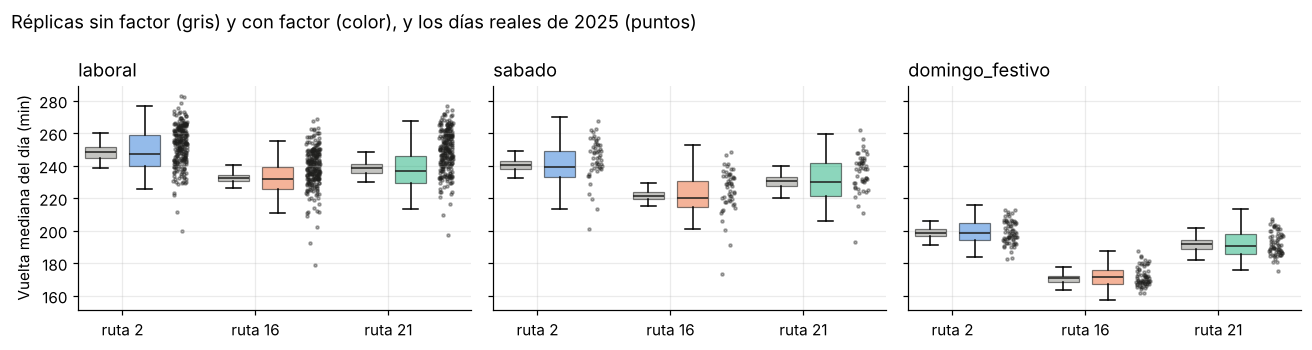

In [6]:
d5 = json.loads((SAL / "decision_13_4b_r5.json").read_text(encoding="utf-8"))
t5 = pd.DataFrame({k: {"cobertura base": v["cobertura"]["base"], "cobertura con factor": v["cobertura"]["velocidad"],
                       "CV sim base": v["cv_sim"]["base"], "CV sim con factor": v["cv_sim"]["velocidad"], "CV real": v["cv_real"]["base"],
                       "media base": v["media"]["base"], "media con factor": v["media"]["velocidad"]} for k, v in d5["tabla"].items()}).T
display(t5.round(3))
print("Días de control dentro del P5–P95:", d5["control_dentro"])
vr = pd.read_csv(SAL / "vuelta_dia_2025_13_4b.csv")
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
v5 = pd.read_csv(SAL / "r5" / "vueltas_r5.csv"); v5 = v5[v5.grupo == "desarrollo"]
for a, t in zip(ax, ("laboral", "sabado", "domingo_festivo")):
    for i, r in enumerate((2, 16, 21)):
        for j, (var, c) in enumerate((("base", GRIS), ("velocidad", COL[r]))):
            x = v5[(v5.tipo_dia == t) & (v5.idruta == r) & (v5.variante == var)].vuelta_mediana_min
            a.boxplot(x, positions=[i * 3 + j], widths=.7, showfliers=False, patch_artist=True,
                      boxprops=dict(facecolor=c, alpha=.5, lw=.8), medianprops=dict(color="#1f1f1d"))
        y = vr[(vr.tipo_dia == t) & (vr.idruta == r)]
        a.scatter(np.full(len(y), i * 3 + 1.8) + np.random.default_rng(0).uniform(-.15, .15, len(y)), y.d,
                  s=4, color="#1f1f1d", alpha=.35)
    a.set_xticks([.5, 3.5, 6.5], ["ruta 2", "ruta 16", "ruta 21"]); a.set_title(t, loc="left")
ax[0].set_ylabel("Vuelta mediana del día (min)")
fig.suptitle("Réplicas sin factor (gris) y con factor (color), y los días reales de 2025 (puntos)", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "m13_4b_velocidad.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 5 · El factor de velocidad hace que el intervalo cubra los días reales**
- **Antes,** el Monte Carlo solo variaba cada viaje por separado, y la vuelta mediana del día casi no cambiaba entre réplicas (CV 1,4–2,1 %), cuando en 2025 cambia 3,4–6,1 % entre días del mismo tipo.
- **Con un factor común × uno propio por ruta** (gammas con media 1, estimados en 2025 sin los días de validación ni de control): CV 3,6–5,8 %, más cerca del real en 9 de 9 tipo de día × ruta, y la media no cambia (< 1 %).
- **Cobertura de los días reales de 2025 dentro del P5–P95:** de 33–72 % a **83–94 %**. Fuera de muestra, los días de control quedan dentro en **8 de 9** (3 de 9 sin el factor). Se adoptó.
- **En el Monte Carlo final,** la vuelta mediana de un laboral con el plan real va de 219,8 a 257,7 min (P5–P95); en la 13.4, de 237,5 a 242,6.

## 6 · Ronda 6: intervalo predictivo por celda

In [7]:
d6 = json.loads((SAL / "decision_13_4b_r6.json").read_text(encoding="utf-8"))
display(pd.DataFrame(d6["cobertura"]).T.round(2))
print("Días con cobertura 80–95 %:", d6["dias_80_95"], "→ adoptar:", d6["adoptar"])
c6 = pd.read_csv(SAL / "r6" / "cobertura_r6.csv").dropna(subset=["p5", "p95"])
c6["fuera"] = np.where(c6.a_bordo_media < c6.p5, "debajo", np.where(c6.a_bordo_media > c6.p95, "encima", "dentro"))
display((100 * pd.crosstab([c6.variante, c6.rol], c6.fuera, normalize="index")).round(1))

,cobertura,ancho_medio
muestreo|control_domingo,73.18,8.69
muestreo|control_laboral,63.43,11.64
muestreo|control_sabado,71.40,11.06
muestreo_dia|control_domingo,77.45,9.46
muestreo_dia|control_laboral,67.86,12.64
muestreo_dia|control_sabado,75.01,11.82


Días con cobertura 80–95 %: {'muestreo': 0, 'muestreo_dia': 0} → adoptar: None


fuera                         debajo  dentro  encima
variante     rol                                    
muestreo     control_domingo     5.9    73.2    20.9
             control_laboral     5.6    63.4    30.9
             control_sabado      4.9    71.4    23.7
muestreo_dia control_domingo     4.8    77.5    17.8
             control_laboral     4.9    67.9    27.3
             control_sabado      4.3    75.0    20.7

**Conclusión 6 · El intervalo por celda sube la cobertura 20–25 puntos, pero no llega al 80 %**
- **Intervalo predictivo:** en cada réplica se sortean tantos pasos de bus como buses observados tiene la celda (mediana 7) y se promedia su carga, que es lo que de verdad se compara.
- **Cobertura en los días de control:** 63,4 / 71,4 / 73,2 % (laboral, sábado, domingo); con los factores del día, **67,9 / 75,0 / 77,5 %**. En la 13.4 era 42,5–52,7 %. La regla pedía 80–95 % en 2 de 3 días: no se adoptó.
- **Lo que falta es el sesgo, no el ancho:** con los factores del día, lo observado queda por encima del P95 en el 27,3 % de las celdas del laboral y por debajo del P5 en solo el 4,9 %. El simulador todavía lleva menos gente a bordo que lo observado.
- Queda como opción rotulada (`mejoras_13_4b_r6.muestras`), por decisión de la Persona 3.

## 7 · Reevaluación «no ciega» de los 6 días de validación

Una sola vez, al final de las rondas, con lo adoptado por las reglas (tiempo de parada y primero bajan; el factor de
velocidad solo actúa con la variación entre días, que la validación no usa), las mismas reglas y semillas de la 13.4.
Es «no ciega»: esos días ya se vieron en la 13.4. El resultado oficial (3 de 6) no cambia.

Demanda pred: días no peores que el histórico — por paso 3, por tiempo 3, oficial 13.4 3 · 2026-11-05T14:11:09 → 2026-11-05T15:19:18 · ajustes {'parada': {'c_s': 8.891, 'b_s': 8.6}, 'bajan_primero': True, 'velocidad_dia': True}


,rol,fecha,mae_oficial_13_4,mae_nuevo_paso,mae_nuevo_tiempo,mae_hist,mae_nuevo_tiempo_6_9,replicas
0,laboral_1,2025-11-25,3.92,4.16,4.19,3.89,5.58,500
1,laboral_2,2025-04-03,4.69,4.76,4.67,3.69,8.47,500
2,sabado,2025-02-15,3.91,3.90,3.76,4.63,5.11,500
3,domingo,2025-07-27,2.79,2.82,2.83,4.52,2.43,500
4,lluvia_fuerte,2025-06-13,3.45,3.67,3.68,3.93,5.04,500
5,evento_masivo,2025-03-25,5.73,5.70,5.56,4.73,10.39,500


Demanda real: días no peores que el histórico — por paso 3, por tiempo 3, oficial 13.4 3 · 2026-11-05T14:11:30 → 2026-11-05T15:20:01 · ajustes {'parada': {'c_s': 8.891, 'b_s': 8.6}, 'bajan_primero': True, 'velocidad_dia': True}


,rol,fecha,mae_oficial_13_4,mae_nuevo_paso,mae_nuevo_tiempo,mae_hist,mae_nuevo_tiempo_6_9,replicas
0,laboral_1,2025-11-25,3.98,4.09,4.06,3.89,5.48,500
1,laboral_2,2025-04-03,4.73,4.78,4.70,3.69,8.56,500
2,sabado,2025-02-15,3.66,3.67,3.57,4.63,4.52,500
3,domingo,2025-07-27,2.77,2.80,2.80,4.51,2.47,500
4,lluvia_fuerte,2025-06-13,3.46,3.61,3.59,3.94,5.29,500
5,evento_masivo,2025-03-25,5.71,5.69,5.61,4.72,9.55,500


Vuelta ±5 %: 17 de 18 (oficial 18 ) · pasajeros por viaje ±10 %: 13 de 18 (oficial 14 )
Exceso mediano de viajes al cupo sobre lo real: 4.9 puntos (oficial 6.2 )


,con mejoras,oficial 13.4,GPS
% intervalos < 1 min,,,
2,21.2,13.9,7.7
16,34.0,24.7,21.5
21,14.4,7.7,4.2


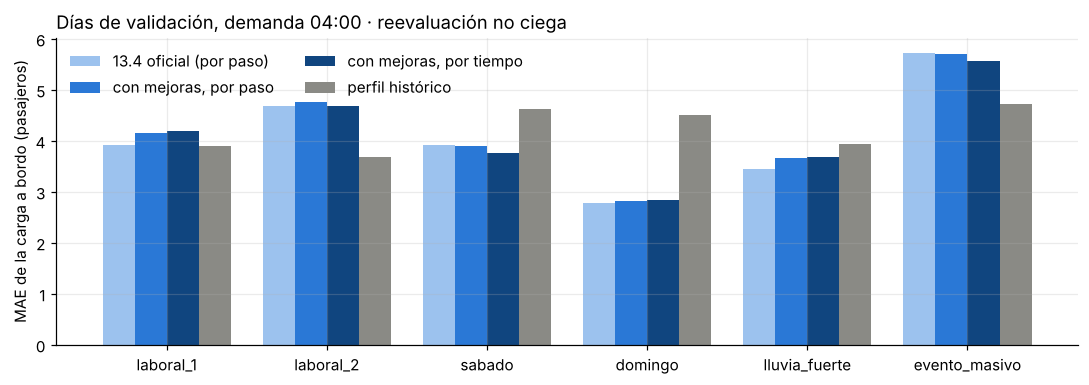

In [8]:
for dem in ("pred", "real"):
    t = pd.read_csv(NC / f"mae_no_ciego_{dem}.csv")
    rs = json.loads((NC / f"resultados_no_ciego_{dem}.json").read_text(encoding="utf-8"))
    print(f"Demanda {dem}: días no peores que el histórico — por paso {rs['dias_no_peor_que_hist_paso']}, por tiempo "
          f"{rs['dias_no_peor_que_hist_tiempo']}, oficial 13.4 {rs['dias_oficial_13_4']} · {rs['inicio']} → {rs['fin']} · ajustes {rs['ajustes']}")
    display(t[["rol", "fecha", "mae_oficial_13_4", "mae_nuevo_paso", "mae_nuevo_tiempo", "mae_hist", "mae_nuevo_tiempo_6_9", "replicas"]].round(2))
s = pd.read_csv(NC / "secundarias_no_ciego_pred.csv"); s0 = pd.read_csv(VAL / "secundarias_13_4.csv"); s0 = s0[s0.demanda == "pred"]
print("Vuelta ±5 %:", int((s.err_vuelta_pct.abs() <= 5).sum()), "de 18 (oficial", int((s0.err_vuelta_pct.abs() <= 5).sum()), ") · "
      "pasajeros por viaje ±10 %:", int((s.err_pasajeros_pct.abs() <= 10).sum()), "de 18 (oficial", int((s0.err_pasajeros_pct.abs() <= 10).sum()), ")")
print("Exceso mediano de viajes al cupo sobre lo real:", round((s.pct_viajes_cupo - s.pct_viajes_cupo_real).median(), 1),
      "puntos (oficial", round((s0.pct_viajes_cupo - s0.pct_viajes_cupo_real).median(), 1), ")")
display(pd.concat({"con mejoras": s.groupby("idruta").pct_intervalos_menos_1min.mean(), "oficial 13.4": s0.groupby("idruta").pct_intervalos_menos_1min.mean(),
                   "GPS": s0.groupby("idruta").pct_intervalos_menos_1min_real.mean()}, axis=1).round(1).rename_axis("% intervalos < 1 min"))
fig, ax = plt.subplots(figsize=(10, 3.6))
t = pd.read_csv(NC / "mae_no_ciego_pred.csv"); xx = np.arange(len(t))
ax.bar(xx - .3, t.mae_oficial_13_4, .2, color="#9cc2ee", label="13.4 oficial (por paso)")
ax.bar(xx - .1, t.mae_nuevo_paso, .2, color="#2a78d6", label="con mejoras, por paso")
ax.bar(xx + .1, t.mae_nuevo_tiempo, .2, color="#10457f", label="con mejoras, por tiempo")
ax.bar(xx + .3, t.mae_hist, .2, color=GRIS, label="perfil histórico")
ax.set_xticks(xx, t.rol); ax.set_ylabel("MAE de la carga a bordo (pasajeros)"); ax.legend(frameon=False, ncols=2, loc="upper left")
ax.set_title("Días de validación, demanda 04:00 · reevaluación no ciega", loc="left")
fig.tight_layout(); fig.savefig(FIG / "m13_4b_no_ciega.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 7 · En los días de validación sigue en 3 de 6**
- **Reevaluación «no ciega»** (una sola vez, con la parada y «primero bajan», mismas reglas y semillas de la 13.4; esos días ya se habían visto). El resultado oficial de la 13.4 no cambia.

  | Día (demanda 04:00) | 13.4 oficial | Con mejoras, por tiempo | Perfil histórico |
  |---|---|---|---|
  | laboral_1 | 3,92 | 4,19 | 3,89 |
  | laboral_2 | 4,69 | 4,67 | 3,69 |
  | sábado | 3,91 | 3,76 | 4,63 |
  | domingo | 2,79 | 2,83 | 4,52 |
  | lluvia fuerte | 3,45 | 3,68 | 3,93 |
  | evento masivo | 5,73 | 5,56 | 4,73 |

- **3 de 6 con las dos medidas y con las dos demandas.** Las mejoras bajan el error en el sábado y el partido y lo suben en laboral_1 y la lluvia: las ganancias de los días de control (−2 a −3 %) no se sostienen en otros días.
- **Secundarias:** vuelta mediana a ±5 % en 17 de 18 (oficial 18); pasajeros por viaje a ±10 % en 13 de 18 (oficial 14); exceso de viajes al cupo +4,9 puntos (oficial +6,2).
- **Sin regulación los buses se pegan más que en el GPS:** intervalos < 1 min de 21,2 / 34,0 / 14,4 % en las rutas 2 / 16 / 21 (oficial 13,9 / 24,7 / 7,7; GPS 7,7 / 21,5 / 4,2). Por eso la Persona 3 puso la regulación en el Monte Carlo final.

## 8 · Monte Carlo final con lo adoptado

Los mismos 54 escenarios, reglas y semillas de la 13.4, con el tiempo de parada, primero bajan y el factor de
velocidad del día (adoptados por las reglas) y la **regulación en el escenario central por decisión de la Persona 3**
(5-nov, 15:43, tomada después de ver los resultados; la regla de la ronda 3 no la había adoptado). La sensibilidad de la
regulación pasa a ser «sin regulación». Se corrió en el PC de la Persona 3 (10 procesos). El Monte Carlo de la 13.4 no
cambia; aquí se pone al lado.

In [9]:
man = json.loads((MC / "manifiesto_montecarlo_13_4.json").read_text(encoding="utf-8"))
man0 = json.loads((MC0 / "manifiesto_montecarlo_13_4.json").read_text(encoding="utf-8"))
print("Monte Carlo 13.4b:", man["creado"], "→", man["completado"], "·", len(man["escenarios"]), "escenarios · ajustes base:", man["ajustes_base"])
print("Regulación central:", man["regulacion_central"])
malos = [k for k, v in man["salidas"].items() if sha(MC / k) != v["sha256"]]
print("Salidas con el hash del manifiesto:", len(man["salidas"]) - len(malos), "de", len(man["salidas"]))
print("Réplicas:", sum(v["replicas"] for v in man["escenarios"].values()), "· convergieron antes de 500:",
      sorted(k for k, v in man["escenarios"].items() if v["convergio"]))
r0, r = pd.read_csv(MC0 / "resumen_13_4.csv"), pd.read_csv(MC / "resumen_13_4.csv")
T0, T = r0[r0.idruta == "total"], r[r.idruta == "total"]
ind = ["espera_media_min", "espera_p90_min", "pct_dejados_bus_lleno", "pct_viajes_cupo", "vuelta_mediana_min", "buses_a_la_vez", "salidas_sin_bus"]
filas = []
for t in ("laboral", "sabado", "domingo"):
    for p in ("real", "p100", "p85", "p70"):
        e = f"{p}_{t}_central"
        x0, x = T0[T0.escenario == e].set_index("indicador"), T[T.escenario == e].set_index("indicador")
        filas.append({"tipo": t, "plan": p, **{k: f"{x0.media[k]:.1f} → {x.media[k]:.1f} [{x.p5[k]:.1f}–{x.p95[k]:.1f}]" for k in ind}})
print("13.4 → 13.4b [P5–P95 de la 13.4b], imprevistos a tasa central:")
display(pd.DataFrame(filas))

Monte Carlo 13.4b: 2026-11-05T15:46:57 → 2026-11-05T17:30:07 · 54 escenarios · ajustes base: {'parada': {'c_s': 8.891, 'b_s': 8.6}, 'bajan_primero': True, 'velocidad_dia': True, 'regulacion': {'alfa': 0.6, 'max_min': 5.0}}
Regulación central: decisión de la Persona 3 (5-nov-2026, 15:43) después de ver los resultados; la regla de la ronda 3 no la adoptó
Salidas con el hash del manifiesto: 109 de 109
Réplicas: 26600 · convergieron antes de 500: ['sens_sin_variacion_dia_p85', 'sens_sin_variacion_dia_real']
13.4 → 13.4b [P5–P95 de la 13.4b], imprevistos a tasa central:


,tipo,plan,espera_media_min,espera_p90_min,pct_dejados_bus_lleno,pct_viajes_cupo,vuelta_mediana_min,buses_a_la_vez,salidas_sin_bus
0,laboral,real,5.7 → 7.2 [6.3–8.7],12.3 → 16.8 [14.8–19.6],6.5 → 7.3 [4.3–10.7],24.1 → 21.3 [11.3–32.9],239.9 → 238.0 [219.8–257.7],175.5 → 179.0 [168.0–189.0],0.0 → 0.3 [0.0–2.0]
1,laboral,p100,8.4 → 10.0 [8.5–12.6],18.0 → 23.1 [19.7–28.1],12.3 → 13.1 [7.8–19.1],58.7 → 53.0 [30.1–76.5],242.7 → 254.0 [235.1–273.4],124.0 → 131.7 [124.0–138.0],0.0 → 0.0 [0.0–0.0]
2,laboral,p85,6.5 → 8.1 [7.1–9.3],14.2 → 18.8 [16.6–21.3],8.2 → 9.0 [5.0–13.5],38.5 → 34.1 [18.0–52.9],242.8 → 248.0 [229.4–267.2],145.4 → 151.6 [141.0–161.0],0.0 → 0.0 [0.0–0.0]
3,laboral,p70,5.2 → 6.6 [5.9–7.7],11.3 → 15.1 [13.7–16.8],4.7 → 5.2 [2.5–8.2],21.2 → 18.5 [9.3–29.6],242.6 → 241.8 [222.7–261.2],176.2 → 179.1 [166.0–192.0],0.0 → 0.0 [0.0–0.0]
4,sabado,real,5.9 → 7.6 [6.8–8.8],12.6 → 17.5 [15.8–19.5],4.1 → 4.9 [2.9–7.2],16.7 → 15.1 [8.8–22.2],229.3 → 230.4 [210.7–250.8],150.9 → 156.1 [146.0–167.0],0.0 → 0.1 [0.0–0.0]
5,sabado,p100,8.9 → 10.9 [9.7–12.7],19.3 → 25.1 [21.9–28.9],10.1 → 11.0 [6.7–16.0],54.8 → 49.0 [31.1–68.9],229.0 → 244.1 [225.1–264.3],95.8 → 103.0 [97.0–106.0],0.0 → 0.0 [0.0–0.0]
6,sabado,p85,7.3 → 9.1 [8.3–10.2],15.7 → 20.8 [19.0–23.4],6.4 → 7.2 [3.9–10.8],34.7 → 30.7 [17.5–44.5],229.0 → 238.1 [219.0–258.0],112.3 → 118.0 [110.0–123.0],0.0 → 0.0 [0.0–0.0]
7,sabado,p70,6.0 → 7.5 [6.9–8.5],12.9 → 17.2 [15.7–18.9],3.7 → 4.0 [2.1–6.2],19.0 → 16.4 [9.0–25.3],228.9 → 231.8 [212.5–251.2],135.4 → 139.6 [130.0–149.0],0.0 → 0.0 [0.0–0.0]
8,domingo,real,6.4 → 7.6 [7.0–8.6],13.6 → 16.9 [15.4–18.3],1.5 → 1.4 [0.4–2.9],6.3 → 5.0 [1.7–9.2],183.7 → 184.3 [174.1–194.6],89.1 → 89.8 [86.0–94.0],0.0 → 0.0 [0.0–0.0]
9,domingo,p100,12.9 → 14.7 [12.8–17.9],26.5 → 32.1 [27.4–39.3],8.7 → 9.0 [3.9–15.3],51.4 → 46.2 [21.0–77.8],182.2 → 203.8 [192.0–216.4],43.9 → 47.6 [46.0–49.0],0.0 → 0.0 [0.0–0.0]


Diferencia de cada plan frente al plan real, réplica a réplica con la misma semilla (media ± IC95 %):


indicador    espera_media_min               pct_dejados_bus_lleno               pct_viajes_cupo              
mc                       13.4         13.4b                  13.4         13.4b            13.4         13.4b
tipo    plan                                                                                                 
domingo p100      6.48 ± 0.13   7.11 ± 0.13           7.27 ± 0.24   7.54 ± 0.26    45.14 ± 1.35  41.19 ± 1.32
        p70       2.43 ± 0.07   2.87 ± 0.08           2.03 ± 0.09   2.13 ± 0.11    12.31 ± 0.46  10.85 ± 0.44
        p85       4.18 ± 0.11   4.89 ± 0.11           4.21 ± 0.17   4.49 ± 0.17    25.88 ± 0.89  23.41 ± 0.83
laboral p100      2.71 ± 0.13    2.8 ± 0.12            5.8 ± 0.15   5.85 ± 0.16    34.58 ± 0.69  31.76 ± 0.69
        p70       -0.5 ± 0.09  -0.64 ± 0.09          -1.84 ± 0.09   -2.15 ± 0.1    -2.89 ± 0.17  -2.81 ± 0.17
        p85       0.78 ± 0.08   0.89 ± 0.09             1.7 ± 0.1   1.67 ± 0.11    14.46 ± 0.39  12.86 ± 0.38
sabado  p100      3.05 ± 0.11   3.36 ± 0.11           5.94 ± 0.16   6.16 ± 0.17    38.08 ± 0.74  33.89 ± 0.69
        p70         0.1 ± 0.1   -0.06 ± 0.1          -0.38 ± 0.09  -0.83 ± 0.08      2.3 ± 0.19   1.32 ± 0.18
        p85        1.36 ± 0.1    1.52 ± 0.1            2.3 ± 0.11   2.34 ± 0.12    18.04 ± 0.44    15.6 ± 0.4

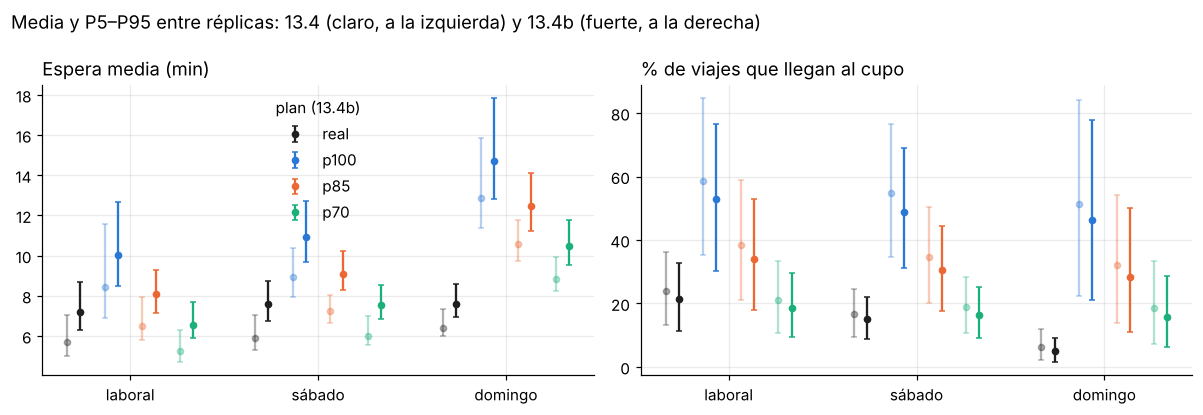

In [10]:
def tot(d, e):
    x = pd.read_parquet(d / f"{e}_indicadores.parquet")
    return x[x.idruta.astype(str) == "total"].set_index("semilla")
filas = []
for nom, d in (("13.4", MC0), ("13.4b", MC)):
    for t in ("laboral", "sabado", "domingo"):
        b = tot(d, f"real_{t}_central")
        for p in ("p100", "p85", "p70"):
            q = tot(d, f"{p}_{t}_central"); s = b.index.intersection(q.index)
            for k in ("espera_media_min", "pct_viajes_cupo", "pct_dejados_bus_lleno"):
                dd = q.loc[s, k] - b.loc[s, k]
                filas.append({"mc": nom, "tipo": t, "plan": p, "indicador": k, "dif": dd.mean(), "ic95": 1.96 * dd.std() / np.sqrt(len(dd))})
dp = pd.DataFrame(filas)
print("Diferencia de cada plan frente al plan real, réplica a réplica con la misma semilla (media ± IC95 %):")
display(dp.assign(v=dp.dif.round(2).astype(str) + " ± " + dp.ic95.round(2).astype(str))
          .pivot_table(index=["tipo", "plan"], columns=["indicador", "mc"], values="v", aggfunc="first"))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, k, tit in zip(ax, ("espera_media_min", "pct_viajes_cupo"), ("Espera media (min)", "% de viajes que llegan al cupo")):
    for j, t in enumerate(("laboral", "sabado", "domingo")):
        for i, p in enumerate(("real", "p100", "p85", "p70")):
            for m, (RR, mk, al) in enumerate(((T0, "o", .35), (T, "o", 1))):
                x = RR[(RR.escenario == f"{p}_{t}_central") & (RR.indicador == k)].iloc[0]
                xx = j + (i - 1.5) * .2 + (m - .5) * .07
                a.errorbar(xx, x.media, yerr=[[x.media - x.p5], [x.p95 - x.media]], fmt=mk, ms=4, color=CP[p], alpha=al, capsize=2,
                           label=(p if m else None) if j == 0 else None)
    a.set_xticks(range(3), ("laboral", "sábado", "domingo")); a.set_title(tit, loc="left")
ax[0].legend(frameon=False, title="plan (13.4b)")
fig.suptitle("Media y P5–P95 entre réplicas: 13.4 (claro, a la izquierda) y 13.4b (fuerte, a la derecha)", x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "m13_4b_planes.png", dpi=200, bbox_inches="tight"); plt.show()

**Conclusión 8 · Con un motor más fiel, la espera sube y el cupo baja; el orden de los planes no cambia**
- **54 escenarios, 26.600 réplicas,** las 109 salidas con el hash de su manifiesto.
- **Niveles, 13.4 → 13.4b** (laboral, plan real): espera media **5,7 → 7,2 min**, viajes al cupo **24,1 → 21,3 %**, dejados por bus lleno 6,5 → 7,3 %, vuelta mediana 239,9 → 238,0 min. En los 12 planes × tipo de día la espera sube 1,2–2,0 min y los viajes al cupo bajan 1,3–5,8 puntos. Con el plan del proyecto al 100 %, los buses van más llenos y paran más: la vuelta crece 11,3 min en el laboral y 21,6 en el domingo.
- **Por qué sube la espera:** con la parada, los buses se desordenan más. A la mitad del circuito, el CV de los intervalos del laboral pasa de 0,85–0,97 a 0,96–1,17 (con regulación). Con llegadas al azar, la espera media es el intervalo medio × (1 + CV²) / 2 (Osuna y Newell, 1972): eso explica entre la mitad y tres cuartos del aumento; el resto, probablemente, el desorden que sigue creciendo después de la mitad del circuito (no medido).
- **Diferencias entre planes, réplica a réplica con la misma semilla, casi iguales a las de la 13.4:**

  | Laboral, frente al plan real | Espera 13.4 | Espera 13.4b | Cupo 13.4 | Cupo 13.4b |
  |---|---|---|---|---|
  | Proyecto al 100 % | +2,71 min | +2,80 min | +34,6 puntos | +31,8 puntos |
  | Proyecto al 85 % | +0,78 min | +0,89 min | +14,5 puntos | +12,9 puntos |
  | Proyecto al 70 % | −0,50 min | −0,64 min | −2,9 puntos | −2,8 puntos |

- **Al 85 %:** 15 % menos buses a la vez en el laboral (13.4: 17 %) y 39 % en el domingo (13.4: 42 %). **Al 70 %** sigue esperando menos que el plan real en el laboral; en el sábado pasa a empate (−0,06 ± 0,10 min; en la 13.4, +0,10 ± 0,10).
- **Se lee como comparación:** la espera absoluta del simulador probablemente es pesimista, porque sus buses siguen más desordenados que en el GPS (conclusión 9). Elegir el plan es del Módulo 14.

## 9 · Sensibilidades y el efecto de la regulación

In [11]:
g = lambda RR, e, k: float(RR[(RR.escenario == e) & (RR.indicador == k)].media.iat[0])   # noqa: E731
ks = ("espera_media_min", "pct_viajes_cupo", "pct_dejados_bus_lleno", "vuelta_mediana_min", "minutos_imprevistos", "salidas_sin_bus")
filas = []
for s in ("sigma_duracion_025", "sigma_duracion_100", "error_duracion", "obras_cierre", "google", "cota_inferior", "sin_variacion_dia",
          "regulacion", "sin_regulacion"):
    for p in ("real", "p85"):
        for nom, RR in (("13.4", T0), ("13.4b", T)):
            e = f"sens_{s}_{p}"
            if e in set(RR.escenario):
                filas.append({"sensibilidad": s, "plan": p, "mc": nom, **{k: g(RR, e, k) - g(RR, f"{p}_laboral_central", k) for k in ks}})
print("Cambio frente al escenario central del mismo Monte Carlo (laboral):")
display(pd.DataFrame(filas).set_index(["sensibilidad", "plan", "mc"]).round(2))
iv0, iv = pd.read_csv(MC0 / "intervalos_regulacion_13_4.csv"), pd.read_csv(MC / "intervalos_regulacion_13_4b.csv")
q = pd.concat({"13.4": iv0.groupby(["escenario", "idruta"])[["cv_intervalos", "pct_intervalos_menos_1min"]].mean(),
               "13.4b": iv.groupby(["escenario", "idruta"])[["cv_intervalos", "pct_intervalos_menos_1min"]].mean()}).round(2)
print("Buses pegados a la mitad del circuito, 6–20 h, 30 réplicas de un laboral de desarrollo:")
display(q)
sv = pd.read_csv(VAL / "secundarias_13_4.csv"); sv = sv[(sv.demanda == "pred") & sv.rol.isin(["laboral_1", "laboral_2"])]
print("GPS de los 2 laborales de validación (mín–máx):")
display(sv.groupby("idruta")[["cv_intervalos_real", "pct_intervalos_menos_1min_real"]].agg(["min", "max"]).round(2))

Cambio frente al escenario central del mismo Monte Carlo (laboral):


espera_media_min  pct_viajes_cupo  pct_dejados_bus_lleno  vuelta_mediana_min  minutos_imprevistos  salidas_sin_bus
sensibilidad       plan mc                                                                                                                       
sigma_duracion_025 real 13.4              -0.04            -0.02                  -0.04               -0.00               -21.31             0.00
                        13.4b             -0.02            -0.05                  -0.03               -0.02               -24.22             0.00
                   p85  13.4              -0.02             0.05                   0.01               -0.05               -14.49             0.00
                        13.4b             -0.05            -0.05                  -0.02                0.00               -16.34             0.00
sigma_duracion_100 real 13.4               0.09            -0.06                  -0.01                0.12                59.18             0.00
                        13.4b              0.07            -0.08                  -0.01                0.16                63.85             0.02
                   p85  13.4               0.03            -0.12                  -0.02                0.06                56.12             0.00
                        13.4b              0.02            -0.12                  -0.03                0.20                58.04             0.00
error_duracion     real 13.4               0.04             0.03                   0.04                0.15               149.29             0.14
                        13.4b              0.03            -0.01                  -0.05                0.18               152.52             0.17
                   p85  13.4               0.06             0.11                   0.09                0.09               120.77             0.00
                        13.4b              0.08             0.02                   0.04                0.16               125.96             0.00
obras_cierre       real 13.4               0.35             0.23                   0.18               -0.28               -33.84             0.00
                        13.4b              0.34             0.29                   0.17               -0.17               -13.62            -0.01
                   p85  13.4               0.42             0.19                   0.18               -0.36               -43.58             0.00
                        13.4b              0.41             0.27                   0.16               -0.19               -26.22             0.00
google             real 13.4               0.16             0.48                   0.18               12.45                 1.78             0.00
                        13.4b              0.12             0.64                   0.11               12.73                 1.28             0.17
                   p85  13.4               0.30             1.84                   0.70               13.60                 3.73             0.00
                        13.4b              0.18             1.82                   0.38               14.45                 2.65             0.00
cota_inferior      real 13.4              -0.42            -7.83                  -2.11                0.03                 0.61             0.00
                        13.4b             -0.57            -6.93                  -2.30               -2.77                -1.43            -0.15
                   p85  13.4              -0.43           -11.98                  -2.65               -0.08                 3.19             0.00
                        13.4b             -0.54           -10.85                  -2.92               -3.62                -1.47             0.00
sin_variacion_dia  real 13.4              -0.11            -0.64                  -0.17                0.05                 0.59             0.00
                        13.4b             -0.12            -0.57                  -0.19  

Buses pegados a la mitad del circuito, 6–20 h, 30 réplicas de un laboral de desarrollo:


cv_intervalos  pct_intervalos_menos_1min
      escenario                idruta                                          
13.4  p85_laboral_central      2                0.90                      11.31
                               16               0.95                      22.79
                               21               0.78                       6.36
      real_laboral_central     2                0.94                      15.13
                               16               0.97                      27.57
                               21               0.85                       8.06
      sens_regulacion_p85      2                0.79                       6.45
                               16               0.87                      10.28
                               21               0.67                       3.25
      sens_regulacion_real     2                0.82                       9.16
                               16               0.87                      13.59
                               21               0.76                       3.66
13.4b p85_laboral_central      2                1.06                      14.18
                               16               1.15                      16.42
                               21               0.86                       7.34
      real_laboral_central     2                1.08                      14.08
                               16               1.17                      21.30
                               21               0.96                       8.73
      sens_sin_regulacion_p85  2                1.15                      18.66
                               16               1.28                      33.56
                               21               0.98                      13.47
      sens_sin_regulacion_real 2                1.19                      21.92
                               16               1.28                      35.02
                               21               1.10                      16.41

GPS de los 2 laborales de validación (mín–máx):


cv_intervalos_real       pct_intervalos_menos_1min_real       
                      min   max                            min    max
idruta                                                               
2                    0.83  0.84                          11.20  11.50
16                   0.96  0.96                          20.09  28.92
21                   0.63  0.72                           1.32   6.76

**Conclusión 9 · Los supuestos pesan lo mismo que en la 13.4; la regulación ordena el paso de los buses**
- **Las sensibilidades cambian casi igual que en la 13.4:** la demanda sigue pesando más que todo (cota inferior: −11,3 % de pasajeros y 14,3 % de viajes al cupo frente a 21,3 %); los tiempos de Google alargan la vuelta +5,3 % con el plan real y +5,8 % con el del proyecto al 85 %; con error en la duración estimada, los minutos perdidos en imprevistos suben +54 %; con todas las obras como cierre, la espera sube +4,8 %.
- **Nuevo, por la parada:** con la cota inferior (menos gente) la vuelta se acorta 2,8 min, porque los buses paran menos. En la 13.4 no cambiaba.
- **Sin regulación,** los indicadores del día casi no cambian (espera +0,02 min, cupo −0,09 puntos, vuelta −0,9 min), pero los buses se pegan mucho más. En 30 réplicas de un laboral de desarrollo, intervalos < 1 min:

  | Ruta | Con regulación (central) | Sin regulación | GPS de los 2 laborales de validación |
  |---|---|---|---|
  | 2 | 14,1 % | 21,9 % | 11,2–11,5 % |
  | 16 | 21,3 % | 35,0 % | 20,1–28,9 % |
  | 21 | 8,7 % | 16,4 % | 1,3–6,8 % |

- **Con regulación,** la ruta 16 queda en el rango del GPS y las otras dos cerca. El CV de los intervalos sigue por encima del GPS (1,08 / 1,17 / 0,96 frente a 0,83–0,84 / 0,96 / 0,63–0,72): en la calle los conductores se regulan en más puntos que uno.

## 10 · Reproducibilidad y lo que pasa a la 13.5

In [12]:
seg = pd.Series({k: v["segundos"] / v["replicas"] for k, v in man["escenarios"].items()})
print(f"Segundos de reloj por réplica (10 procesos): mediana {seg.median():.2f}, máximo {seg.max():.2f} · "
      f"{sum(v['segundos'] for v in man['escenarios'].values()) / 3600:.2f} h de reloj en total")
print("Pasos de la réplica representativa guardados para el gemelo digital:", len(list(MC.glob("*_pasos.parquet"))), "escenarios")
enm = json.loads((VAL / "enmiendas_codigo_13_4.json").read_text(encoding="utf-8"))
print("Enmiendas registradas del código de la 13.4:", len(enm.get("historial", [])), "·", ", ".join(enm["archivos"]))
print("Python", sys.version.split()[0])

Segundos de reloj por réplica (10 procesos): mediana 0.24, máximo 0.30 · 1.72 h de reloj en total
Pasos de la réplica representativa guardados para el gemelo digital: 54 escenarios
Enmiendas registradas del código de la 13.4: 4 · src/simulation/motor.py, src/simulation/escenario.py, src/simulation/imprevistos.py, src/simulation/monte_carlo_engine.py
Python 3.13.16


**Conclusión 10 · Todo queda reproducible y con sus opciones rotuladas para el gemelo**
- **Rapidez:** el Monte Carlo final corrió en el PC de la Persona 3 en 1,7 h de reloj con 10 procesos (0,24 s por réplica en la mediana).
- **Convergencia:** como en la 13.4, solo los 2 escenarios sin factor del día llegan al 1 % antes de 500 réplicas (aquí, a las 300). A las 500, la mitad del IC95 % queda en 1,0 % de la media para la espera, 2,6 % para el cupo y 0,4 % para la vuelta (mediana de los escenarios).
- **Reglas congeladas y verificables:** cada ronda tiene su regla con los hashes del código y de los insumos, escrita antes de simular, y su decisión con el hash de la regla; repetir una evaluación o una decisión se rechaza (`tests_13_4b.py` 7/7).
- **Las subfases cerradas no cambian:** sin `ajustes`, el motor da las mismas réplicas que la 13.2 (pruebas c y f) y la 13.4 reproduce su evaluación (`enmiendas_codigo_13_4.json`, 4 enmiendas registradas).
- **Para la 13.5:** los pasos de la réplica representativa de los 54 escenarios; la regulación en el central; el intervalo por celda como opción rotulada.

## Síntesis · Subfase 13.4b
- **6 rondas, cada una con su regla congelada antes de simular y una sola evaluación en los 3 días de control.** Se adoptaron el tiempo de parada (8,9 s por parada y 8,6 s por pasajero), «primero bajan» y el factor de velocidad del día. No se adoptaron el reparto por tipo de día ni, por la regla, la regulación y el intervalo por celda.
- **El simulador es más fiel a la calle en su física:**
  - los buses llenos van más lento;
  - el cupo queda a +1,4 puntos de lo real (antes +3,6 en los días de control);
  - la vuelta del día varía como en 2025: el intervalo cubre el 83–94 % de los días reales (antes 33–72 %);
  - con la regulación, los buses pegados quedan cerca del GPS.
- **La ocupación casi no mejora:** −2 a −3 % de MAE en los días de control, y en los días de validación sigue en 3 de 6 frente al perfil histórico (reevaluación «no ciega»; el oficial de la 13.4 no cambia). Lo que sigue abierto es que en los laborales el simulador lleva menos gente a bordo que lo observado (−3,1 pasajeros), y no viene de dónde se bajan.
- **Monte Carlo final:** la espera sube 1,2–2,0 min porque los buses se desordenan más y el cupo baja 1,3–5,8 puntos. **Las diferencias entre planes quedan casi iguales a las de la 13.4:** las conclusiones de la 13.4 sobre los planes se sostienen con un motor más fiel.
- **Decisiones de la Persona 3, rotuladas «después de ver los resultados»:** la regulación en el escenario central del Monte Carlo y el intervalo por celda como opción. Las decisiones de Claude W1–W8 las confirmó la Persona 3 al cerrar la subfase (5-nov, 20:05; `revisiones/revision_13_4b.md`).
- **Siguiente:** la 13.5 (gemelo digital) parte de los pasos guardados de los 54 escenarios.

---
# Parte 16 · Módulo 13 · Subfase 13.5 · Gemelo digital
*Notebook original: `modulo13/subfase_13_5_gemelo.ipynb`*

# SOBUSA · Módulo 13 · Subfase 13.5 — Gemelo digital

**Persona 3.** Una aplicación local (Streamlit + Pydeck) que muestra un día de operación de las rutas 2, 16 y 21 con lo que
produjeron la 13.4 y la 13.4b, y deja probar un escenario y marcar un imprevisto en vivo con el mismo motor y las mismas
semillas. Alcance aprobado: `revisiones/alcance_13_5.md` (5-nov-2026, 22:52). Se abre con
`py -m streamlit run gemelo_13_5.py`.

| Pantalla | Qué muestra |
|---|---|
| Mapa del día | Los buses de la réplica representativa moviéndose minuto a minuto, con su ocupación |
| Indicadores | Media y P5–P95 entre réplicas de cada escenario; gente a bordo por segmento y hora |
| Comparar planes | Diferencia réplica a réplica (misma semilla) entre dos escenarios, con su IC95 % |
| Validación | Los 6 días congelados: simulado frente a observado (oficial 13.4 y «no ciego» 13.4b) |
| Probar un escenario | Plan, demanda, lluvia, imprevistos, regulación y un imprevisto marcado a mano, corridos en vivo |
| Supuestos y límites | Lo que el gemelo sabe y lo que no, con las decisiones rotuladas |

In [1]:
import hashlib, json, sys, time
from dataclasses import asdict
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, ".")
from src.gemelo import datos as D, en_vivo as V
from src.simulation import escenario as E
import montecarlo_13_4b as MO

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None)
FIG = Path("resultados_13")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "font.size": 10, "figure.dpi": 110})
sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
P = E.cargar_parametros()

## 1 · Insumos: lo que ya se simuló, sin volver a calcularlo

In [2]:
man = json.loads((D.GEM / "manifiesto_gemelo_13_5.json").read_text(encoding="utf-8"))
print("Preparado:", man["creado"], "· salidas con su hash:",
      sum(sha(D.GEM / k) == v for k, v in man["salidas"].items()), "de", len(man["salidas"]))
print("Entradas: Monte Carlo 13.4b", man["entradas"]["manifiesto_montecarlo_13_4b"][:12], "= actual:",
      man["entradas"]["manifiesto_montecarlo_13_4b"] == sha(D.MC / "manifiesto_montecarlo_13_4.json"),
      "· red de segmentos", man["entradas"]["red_vial_segmentos.geojson"][:12])
es = pd.DataFrame(man["escenarios"]).T
print(f"{len(es)} escenarios · {es.posiciones.sum():,} posiciones de bus por minuto · sin capacidad conocida: {es.sin_capacidad.sum()}")
cat = D.catalogo()
display(cat.groupby("grupo").escenario.count().rename("escenarios"))
print("Tamaño en disco:", round(sum(f.stat().st_size for f in D.GEM.glob("*")) / 1e6, 1), "MB")

Preparado: 2026-11-05T22:57:32 · salidas con su hash: 55 de 55
Entradas: Monte Carlo 13.4b 018877ecedc9 = actual: True · red de segmentos f78a2d8a426b
54 escenarios · 5,653,409 posiciones de bus por minuto · sin capacidad conocida: 0


grupo
principal       12
sensibilidad    22
variante        20
Name: escenarios, dtype: int64

Tamaño en disco: 40.7 MB


**Conclusión 1 · El gemelo lee los 54 escenarios del Monte Carlo final sin recalcularlos**
- **54 escenarios:** 12 de planes por tipo de día, 20 variantes (tasas de imprevistos y demanda real) y 22 sensibilidades.
- **Preparación una sola vez** (`preparar_gemelo_13_5.py`, ~40 s): 5.653.409 posiciones de bus por minuto en 40,7 MB; las 55 salidas tienen su hash, y el manifiesto guarda el del Monte Carlo de la 13.4b del que salen.
- Todos los buses tienen su capacidad, la misma que usa el motor.

## 2 · Del paso por segmento a un bus en el mapa

El motor guarda, por cada bus y vuelta, la hora en que entra a cada segmento de 500 m, cuánto tarda y con cuánta gente
va. El gemelo interpola la posición entre la entrada y la salida del segmento, sobre la geometría de `rutas_segmentos`
(Módulo 10). Si el bus espera por la regulación, se queda quieto al final de su segmento.

Puntos de la geometría: 4632 · {2: 135, 16: 123, 21: 128} segmentos por ruta


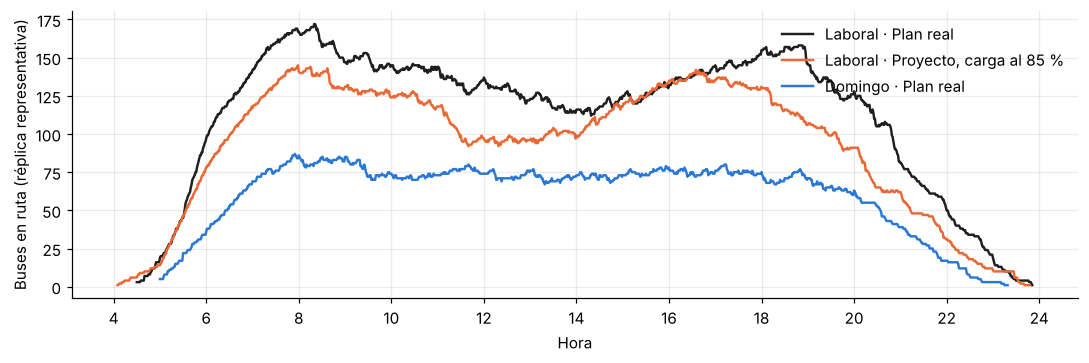

Laboral, plan real: 132,011 posiciones de 217 buses en 557 vueltas · máximo 172 buses a la vez a las 8 h · buses llenos en algún minuto: 96


In [3]:
g = D.geometria()
print("Puntos de la geometría:", len(g), "·", g.groupby("idruta").nro_segmento.max().to_dict(), "segmentos por ruta")
pos = {n: D.posiciones_guardadas(n) for n in ("real_laboral_central", "p85_laboral_central", "real_domingo_central")}
fig, ax = plt.subplots(figsize=(10, 3.4))
col = {"real_laboral_central": "#1f1f1d", "p85_laboral_central": "#eb6834", "real_domingo_central": "#2a78d6"}
for n, p in pos.items():
    b = p.groupby(p.t_s // 60).bus.size()
    ax.plot(b.index / 60, b.values, color=col[n], lw=1.6, label=D.etiqueta(n).replace(" · Imprevistos a tasa central", ""))
ax.set_xlabel("Hora"); ax.set_ylabel("Buses en ruta (réplica representativa)"); ax.set_xticks(range(4, 25, 2))
ax.legend(frameon=False, loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "m13_5_buses_en_ruta.png", dpi=200, bbox_inches="tight"); plt.show()
p = pos["real_laboral_central"]
pa = D.pasos("real_laboral_central")
print(f"Laboral, plan real: {len(p):,} posiciones de {p.bus.nunique()} buses en {pa.id_salida.nunique()} vueltas · "
      f"máximo {p.groupby('t_s').size().max()} buses a la vez a las {int(p.groupby('t_s').size().idxmax() // 3600)} h · "
      f"buses llenos en algún minuto: {p[p.ocupacion >= 1].bus.nunique()}")

**Conclusión 2 · Cada bus está donde dicen sus pasos**
- **Geometría:** 4.632 puntos sobre los 135 / 123 / 128 segmentos de las rutas 2 / 16 / 21, sin huecos entre un segmento y el siguiente.
- **Posición:** cada minuto, cada bus queda sobre el segmento que estaba recorriendo, entre su entrada y su salida. Las 542 posiciones en que el bus espera por la regulación (laboral, plan real) quedan quietas al final de su segmento (`tests_13_5.py` b).
- **Laboral con el plan real:** 132.011 posiciones de 217 buses en 557 vueltas; a las 8 h hay 172 buses en ruta a la vez, y 96 buses van llenos en algún momento del día.
- El indicador «buses a la vez» del Monte Carlo (179) suma el máximo de cada ruta, que no ocurre en el mismo minuto; el mapa cuenta los buses de las tres rutas en cada minuto.

## 3 · Indicadores y comparación de planes

In [4]:
r = D.resumen()
n_ok = 0
for e in cat.escenario:
    t = D.tabla_resumen(D.indicadores(e)).set_index("clave")
    x = r[(r.escenario == e) & (r.idruta == "total")].set_index("indicador")
    n_ok += int(all(np.isclose(t.media[k], x.media[k]) and np.isclose(t.p5[k], x.p5[k]) for k in t.index))
print(f"Indicadores de la app iguales al resumen del Monte Carlo: {n_ok} de {len(cat)} escenarios")
d = D.diferencia_pareada(D.indicadores("real_laboral_central"), D.indicadores("p85_laboral_central"))
display(d[["indicador", "a", "b", "dif", "ic95", "pct_b_menor"]].round(2))

Indicadores de la app iguales al resumen del Monte Carlo: 54 de 54 escenarios


,indicador,a,b,dif,ic95,pct_b_menor
0,Espera media,7.21,8.09,0.89,0.09,7.2
1,Espera P90,16.83,18.83,2.01,0.13,6.0
2,Viajes que llegan al cupo,21.28,34.14,12.86,0.38,0.0
3,Dejados por bus lleno,7.30,8.97,1.67,0.11,9.8
4,Vuelta mediana,238.00,248.00,10.00,0.20,0.0
5,Buses a la vez,178.96,151.57,-27.39,0.26,100.0
6,Pasajeros del día,47169.25,47213.05,43.80,7.85,22.6
7,Salidas,556.72,450.00,-106.72,0.08,100.0
8,Minutos perdidos en imprevistos,283.46,230.33,-53.12,44.23,55.6


**Conclusión 3 · Las cifras que muestra la app son las del Monte Carlo**
- **Iguales al resumen de la 13.4b en los 54 escenarios** (1.944 medias y P5–P95 de 9 indicadores × 4 rutas).
- **Comparar planes** reproduce la diferencia réplica a réplica de la 13.4b: el plan del proyecto al 85 % frente al real en el laboral espera +0,89 min (± 0,09), llega al cupo en +12,9 puntos (± 0,4) y usa 27,4 buses menos a la vez.
- La validación muestra el resultado oficial de la 13.4 (3 de 6 días) y, aparte y rotulado, el «no ciego» de la 13.4b.

## 4 · Probar un escenario y un imprevisto en vivo

In [5]:
cfg = V.Configuracion()
vistos = {c.nombre_guardado() for c in (V.Configuracion(t, p, d, ll, i, rg) for t in D.TIPOS for p in D.PLANES
          for d in ("pred", "real", "cota_inferior") for i in ("central", "baja", "alta") for ll in (False, True) for rg in (True, False)
          if not (ll and t != "laboral"))} - {None}
print("Escenarios del Monte Carlo que se pueden armar en vivo:", len(vistos), "de 54")
t0 = time.time(); r0 = V.correr(cfg, n=10, P=P); s0 = time.time() - t0
EV = dict(tipo="choque", idruta=16, nro_segmento=40, inicio_s=7.5 * 3600, duracion_min=60, severidad=5)
t0 = time.time(); r1 = V.correr(cfg, n=10, eventos=[EV], P=P); s1 = time.time() - t0
g = D.indicadores("real_laboral_central").query("replica < 10").sort_values(["semilla", "idruta"]).reset_index(drop=True)
a = r0["indicadores"].sort_values(["semilla", "idruta"]).reset_index(drop=True)[g.columns]
num = [c for c in g.columns if c not in ("idruta", "replica", "semilla")]
iguales = pd.Series(np.isclose(a[num].astype(float), g[num].astype(float)).all(axis=1), index=a.semilla).groupby(level=0).all()
print(f"10 réplicas en vivo del laboral con el plan real: {int(iguales.sum())} de 10 idénticas a las guardadas en el PC (Windows)")
print(f"Tiempo en este equipo, 1 proceso: {s0:.0f} s sin imprevisto y {s1:.0f} s con él ({(s0 + s1) / 22:.1f} s por réplica)")
dv = V.desvio(EV, E.dias_desarrollo(3)["laboral"])
for k, x in dv.items():
    print(f"Ruta {k}: {x['recomendacion']} · segmentos {x['segmentos_bloqueados']} · alterna por {', '.join(x['calles'][:5])}")
dd = D.diferencia_pareada(r0["indicadores"], r1["indicadores"], ruta="16")
display(dd[["indicador", "a", "b", "dif", "ic95"]].round(2))
pp = r1["pasos"]
dsv = pp[(pp.idruta == 16) & pp.alterna]
print(f"Réplica representativa con el cierre: {dsv.id_salida.nunique()} vueltas de la ruta 16 en desvío entre las "
      f"{int(dsv.t_s.min() // 3600)}:{int(dsv.t_s.min() % 3600 // 60):02d} y las {int(dsv.t_s.max() // 3600)}:{int(dsv.t_s.max() % 3600 // 60):02d}")

Escenarios del Monte Carlo que se pueden armar en vivo: 38 de 54


10 réplicas en vivo del laboral con el plan real: 10 de 10 idénticas a las guardadas en el PC (Windows)
Tiempo en este equipo, 1 proceso: 25 s sin imprevisto y 13 s con él (1.7 s por réplica)
Ruta 16: desviar · segmentos [40] · alterna por Carrera 54, Calle 72, Avenida Carrera 46, Carrera 46, Avenida Carrera 46


,indicador,a,b,dif,ic95
0,Espera media,5.10,5.15,0.05,0.25
1,Espera P90,12.06,12.39,0.33,0.77
2,Viajes que llegan al cupo,21.28,21.45,0.17,1.58
3,Dejados por bus lleno,7.38,7.89,0.51,0.78
4,Vuelta mediana,232.86,233.85,0.99,0.87
5,Buses a la vez,90.80,91.70,0.90,1.22
6,Pasajeros del día,24495.30,24504.60,9.30,25.97
7,Salidas,297.00,297.00,0.00,0.00
8,Minutos perdidos en imprevistos,233.93,373.62,139.70,15.29


Réplica representativa con el cierre: 28 vueltas de la ruta 16 en desvío entre las 7:40 y las 8:21


**Conclusión 4 · En vivo da lo mismo que el Monte Carlo, y el cierre se desvía por la alterna del Módulo 12**
- **Se pueden armar 38 de los 54 escenarios** desde la app (plan, tipo de día, demanda, tasa de imprevistos, lluvia y regulación); los otros 16 son sensibilidades de supuestos (σ de duración, error del centro de control, obras, Google, sin variación entre días, umbral del arroyo).
- **Mismas semillas, mismo resultado:** 10 réplicas en vivo del laboral con el plan real salen idénticas a las 10 primeras guardadas, aunque esas se corrieron en el PC (Windows) y estas en Linux.
- **Rapidez:** 1,7 s por réplica con un proceso en el entorno de trabajo. En varios procesos, cada proceso carga una vez el grafo del Módulo 12 (~10 s) y queda abierto para las corridas siguientes; sin y con el imprevisto van en una sola tanda (`tests_13_5.py` j: 2 procesos dan lo mismo que en serie).
- **Imprevistos marcados a mano:** hasta 5 en el mismo día, además de los que sortea la tasa (`tests_13_5.py` h y k). Con uno (choque de gravedad 5 en el segmento 40 de la ruta 16, a las 7:30, 60 min):
  - el Módulo 12 recomienda desviar por la Carrera 54, la Calle 72 y la Avenida Carrera 46;
  - en la réplica representativa, 28 vueltas de la ruta 16 se desvían entre las 7:40 y las 8:21;
  - en la ruta 16, los minutos perdidos en imprevistos suben de 233,9 a 373,6 (+139,7 ± 15,3);
  - la espera casi no cambia (+0,05 ± 0,25 min): una hora de cierre en un punto con alterna pesa poco en el día.

## 5 · Las pantallas

Capturas tomadas con Playwright (Chromium) sobre la app corriendo en el entorno de trabajo, **sin internet: por eso sin mapa de fondo**. En el PC, con internet, se ve el mapa de CARTO debajo de las rutas.

Mapa del día (laboral, plan real, 7:00)


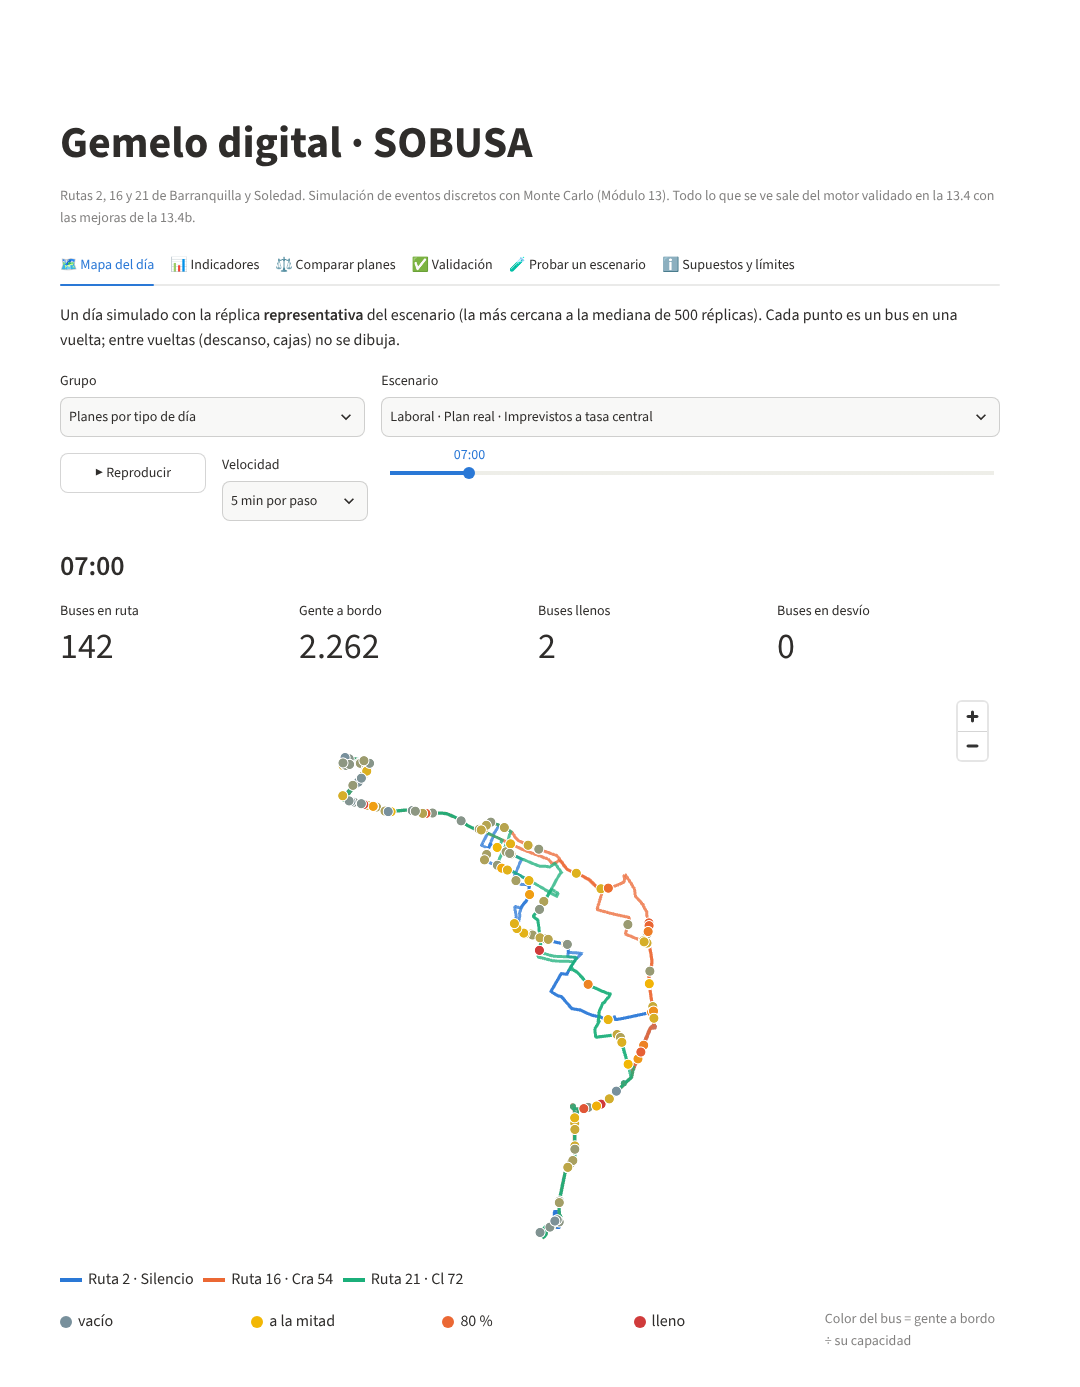

Indicadores


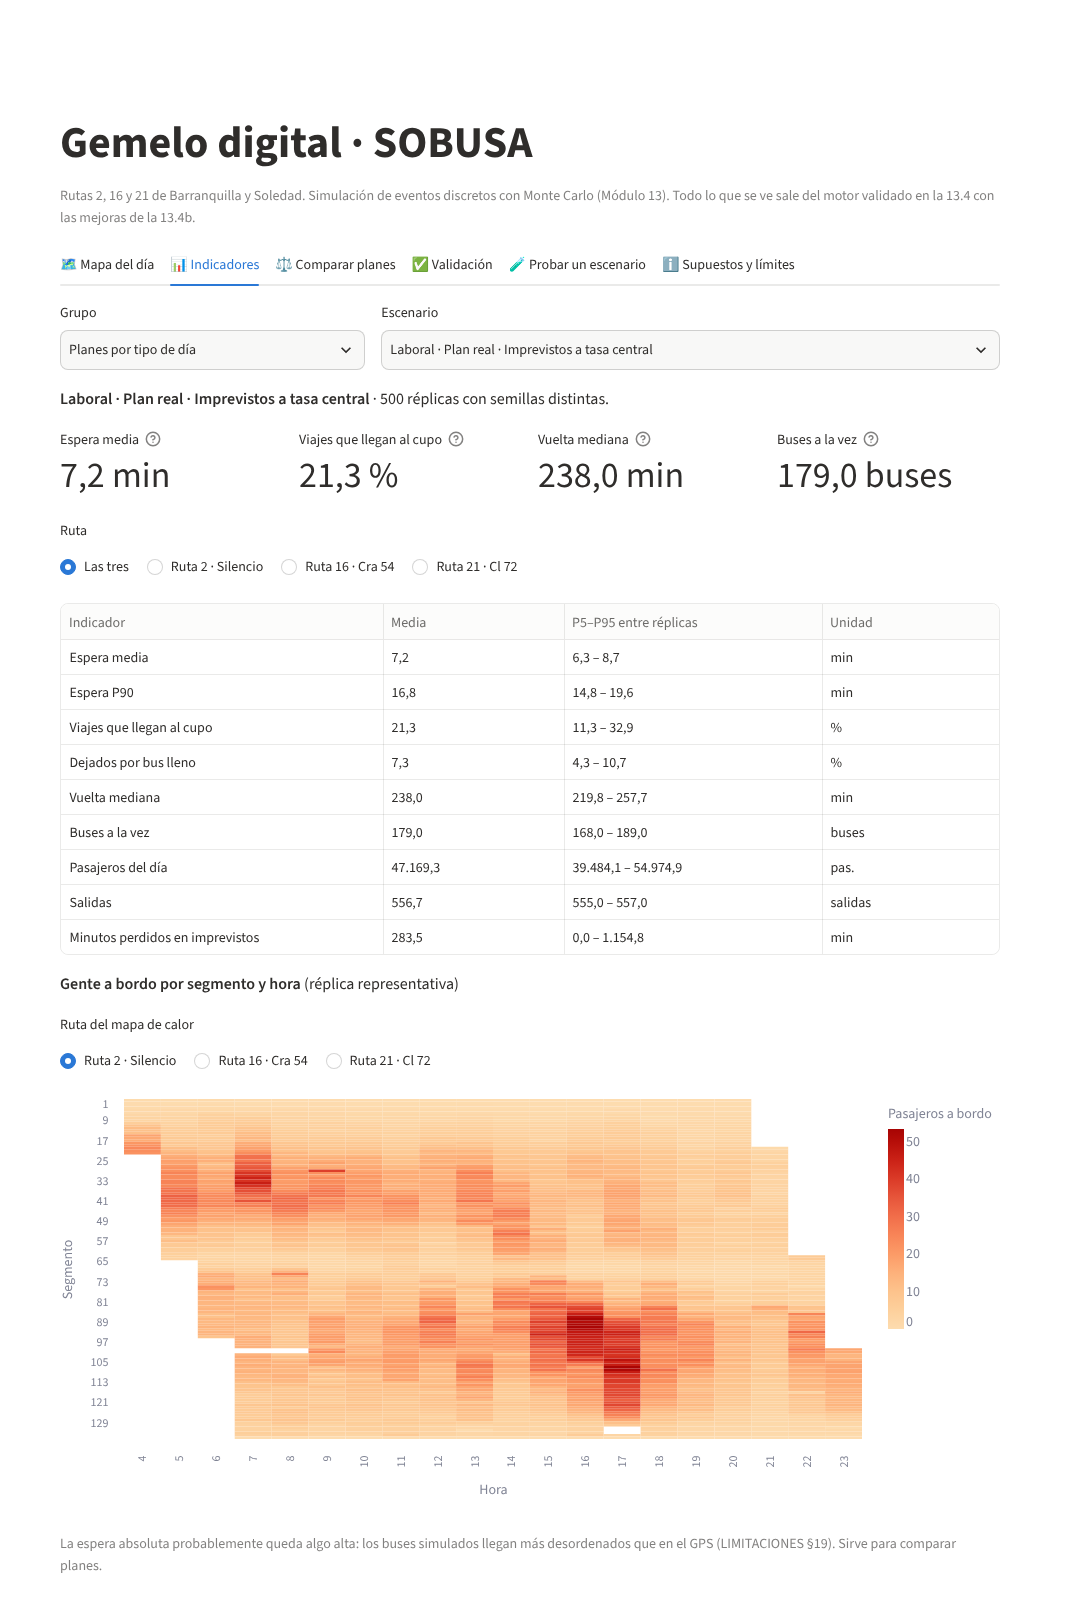

Comparar planes


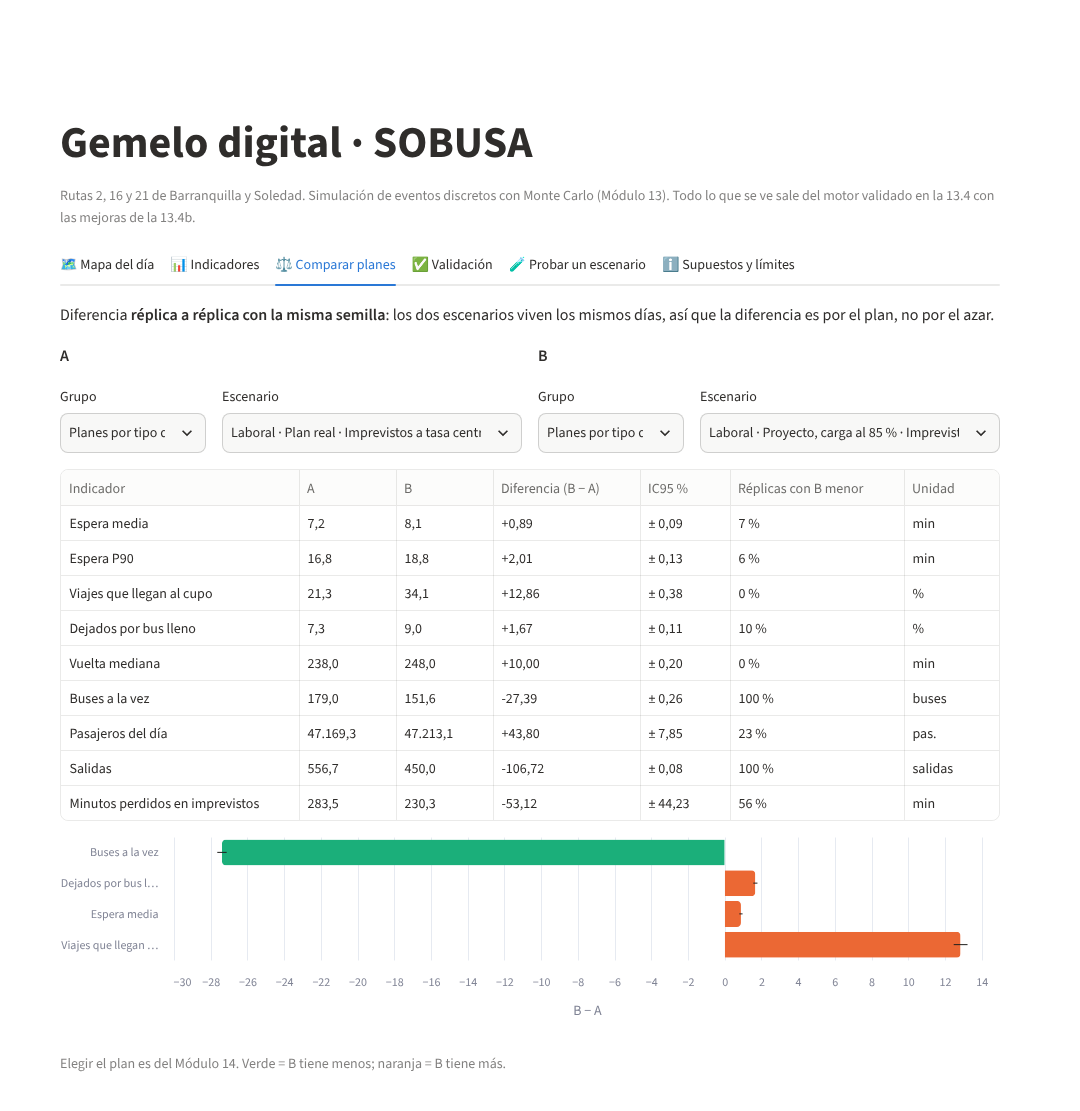

Validación


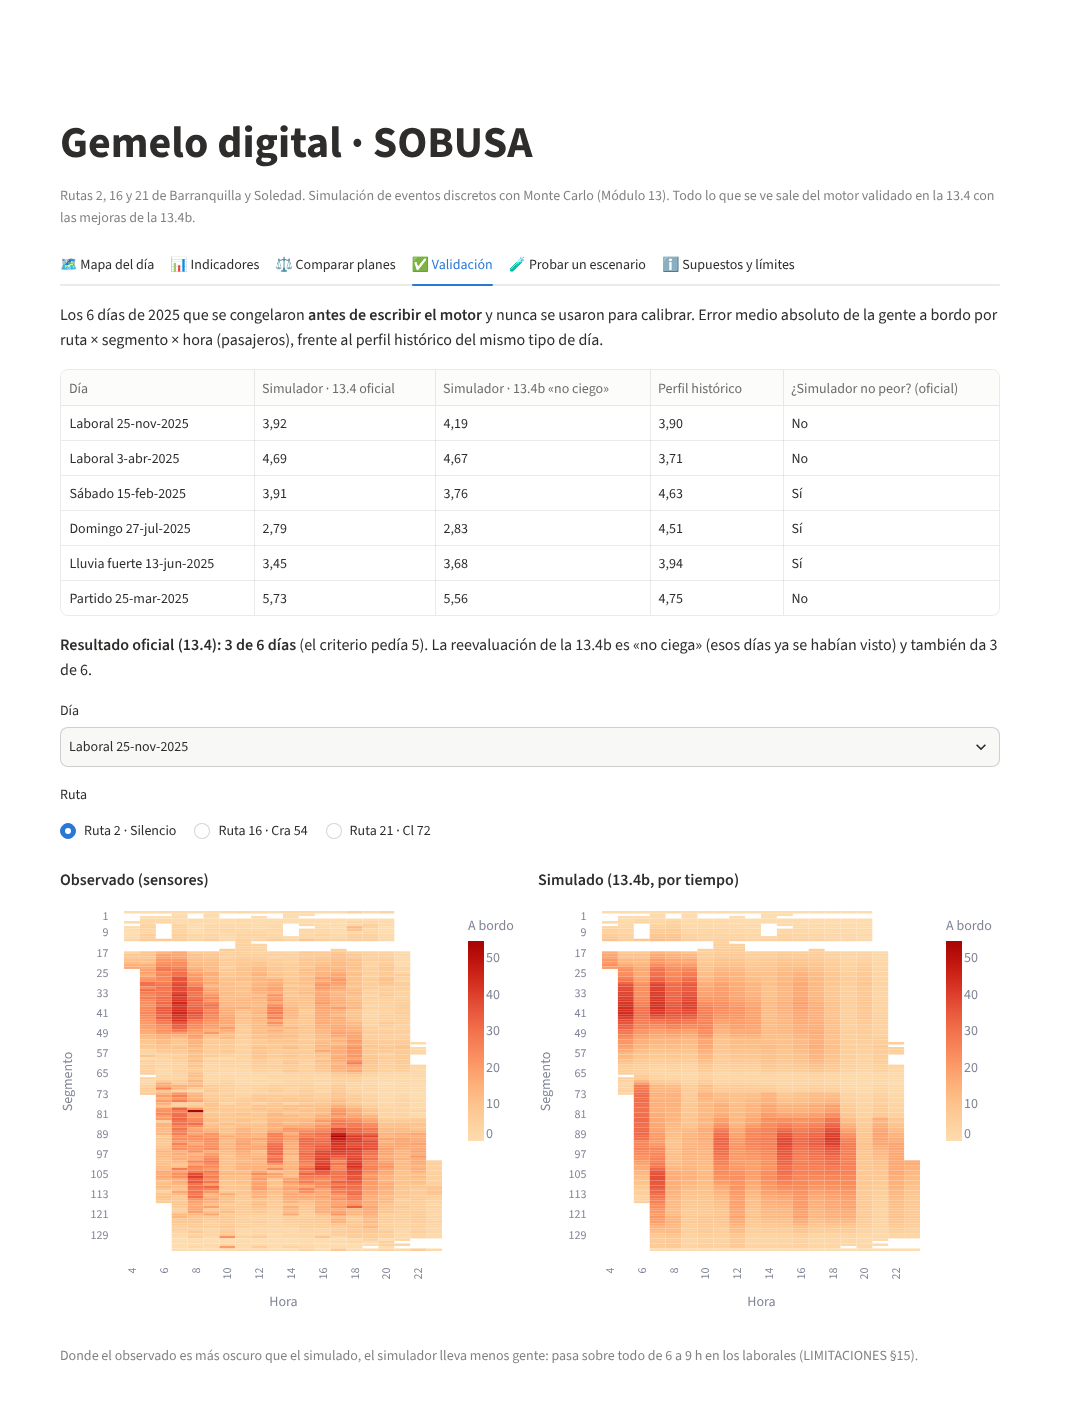

Probar un escenario: cierre en el segmento 40 de la ruta 16


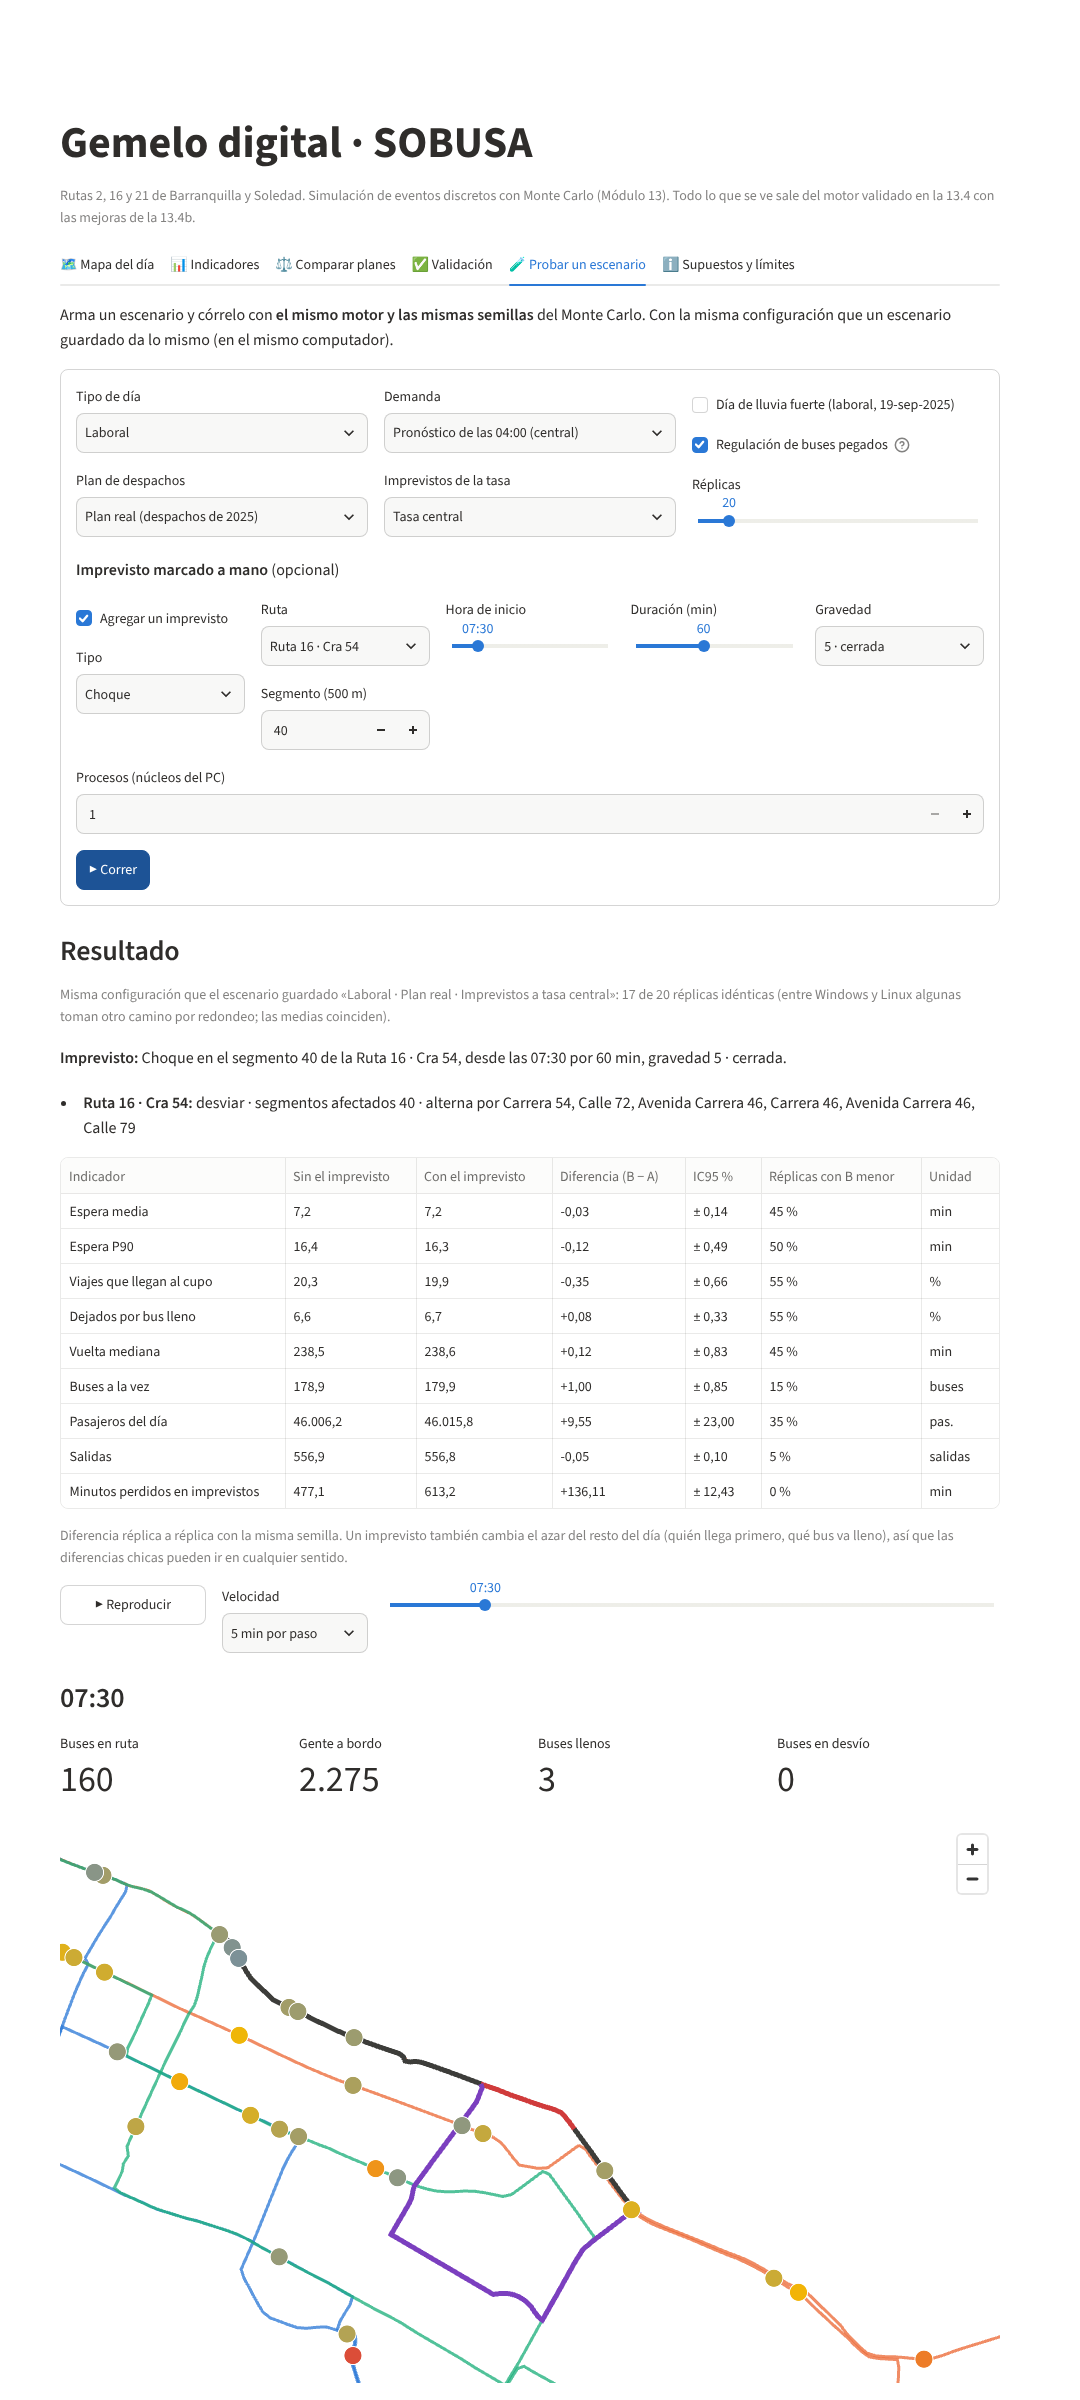

Supuestos y límites


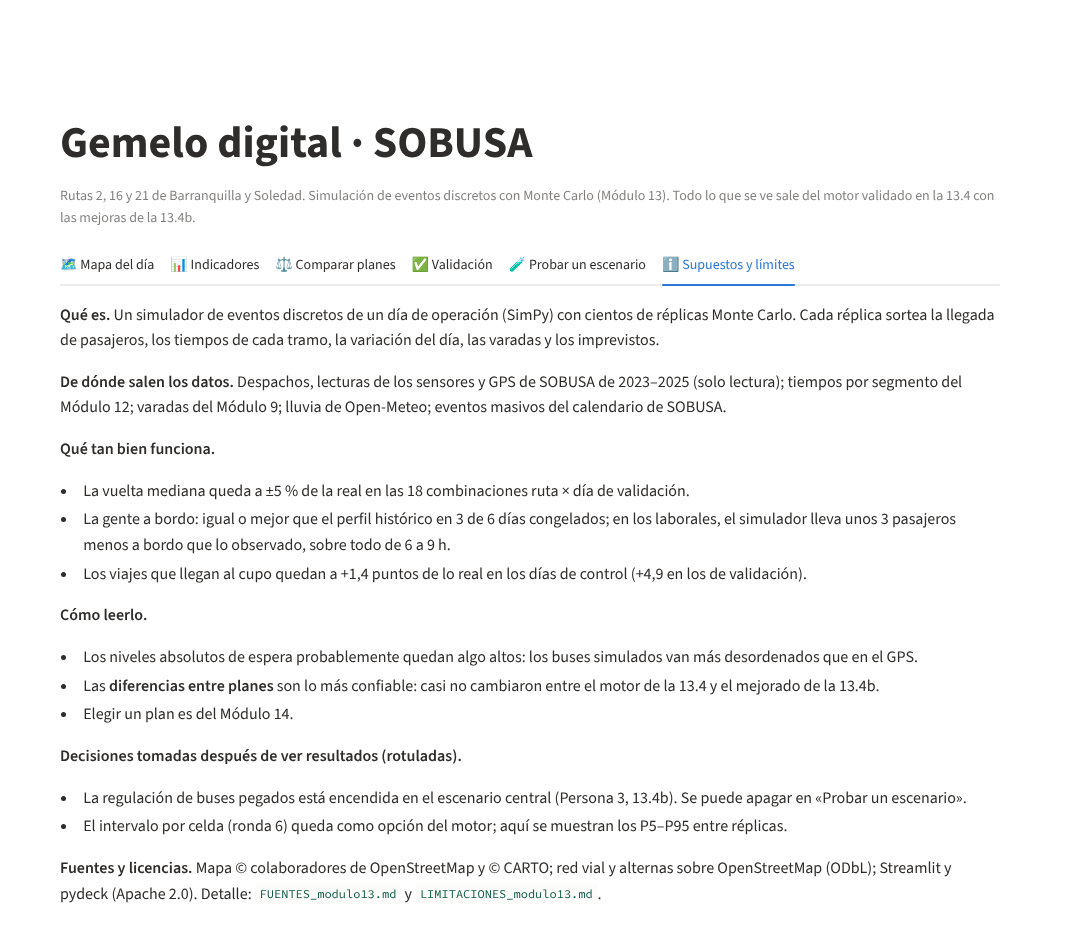

In [6]:
for n, t in (("mapa", "Mapa del día (laboral, plan real, 7:00)"), ("indicadores", "Indicadores"), ("comparar", "Comparar planes"),
             ("validacion", "Validación"), ("probar", "Probar un escenario: cierre en el segmento 40 de la ruta 16"),
             ("supuestos", "Supuestos y límites")):
    print(t); display(Image(filename=str(FIG / f"m13_5_{n}.png"), width=900))

**Conclusión 5 · Seis pantallas para quien no lee notebooks**
- **Mapa del día, indicadores, comparar planes, validación, probar un escenario y supuestos y límites**, en español sencillo, con la leyenda de colores y los rótulos de las decisiones tomadas después de ver los resultados.
- **La app abre sin errores en las 6 pestañas y corre en vivo con un imprevisto** (prueba sin navegador, `tests_13_5.py` h, y capturas con Chromium).
- **Sin llamadas a la base ni a APIs:** Streamlit no envía estadísticas de uso (`gatherUsageStats = false`). El mapa de fondo de CARTO lo pide el navegador y se puede apagar. Es gratis para uso no comercial; un uso comercial de SOBUSA exige revisar sus condiciones (FUENTES C7).

## Síntesis · Subfase 13.5
- **El gemelo digital ya muestra un día de operación de las rutas 2, 16 y 21** con lo que validó la 13.4 y mejoró la 13.4b: buses moviéndose con su ocupación, indicadores con su P5–P95, comparación de planes réplica a réplica y la validación con sus 3 de 6 días, sin esconderla.
- **No es otro modelo:** las cifras de la app son las del Monte Carlo (54 de 54 escenarios), y en vivo usa el mismo motor y las mismas semillas, así que reproduce lo guardado (10 de 10 réplicas).
- **Deja probar lo que pide el plan del Entregable 3:** cambiar el plan de despachos, la demanda, la lluvia o la regulación, y marcar un imprevisto para ver el desvío del Módulo 12 y su efecto en el día.
- **Se usa para comparar escenarios, no para predecir un día concreto:** la espera absoluta probablemente queda algo alta y en los laborales el simulador lleva unos 3 pasajeros menos a bordo (LIMITACIONES §15–19).
- **Se abre en el PC** con `py -m streamlit run gemelo_13_5.py`.
- **Siguiente:** la 13.6, el cierre del Módulo 13.

---
# Parte 17 · Módulo 13 · Subfase 13.6 · Cierre
*Notebook original: `modulo13/subfase_13_6_cierre.ipynb`*

# SOBUSA · Módulo 13 · Subfase 13.6 — Cierre y entrega

**Persona 3.** Deja el Módulo 13 listo para entregar:
- se compara con el texto completo del plan del Entregable 3, frase por frase;
- se cierran las brechas que salieron de esa comparación (B1–B5: fluidez, acelerador, barras de capacidad, imprevistos en el mapa y nombre del entregable);
- se comprueba que todo corre en el PC;
- queda el paquete del zip, el texto para el informe final y la nota para el Módulo 14.

Alcance aprobado: `revisiones/alcance_13_6.md` (6-nov-2026, 12:12).

In [1]:
import json, os, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

sys.path.insert(0, ".")
from src.gemelo import animado as A, datos as D

pd.set_option("display.width", 220); pd.set_option("display.max_columns", None); pd.set_option("display.max_colwidth", 120)
FIG, REV = Path("resultados_13"), Path("revisiones")
def correr(*a):
    p = subprocess.run([sys.executable, *a], capture_output=True, text=True, encoding="utf-8", errors="replace",
                       env={**os.environ, "PYTHONIOENCODING": "utf-8", "PYTHONUTF8": "1"})
    return p.stdout

## 1 · El plan completo, frase por frase

La R1 de la 13.5 se hizo con los fragmentos del plan citados en los alcances. Esta vez se leyó el PDF completo
(`ENTREGABLE3Plan_Modulos_9_en_adelante_SOBUSA-v2.pdf`, FUENTES A11), y aparecieron cinco puntos sin cubrir. Se dice
explícitamente, como corrección de la 13.5. La tabla completa está en `revisiones/revision_13_6.md` (R1).

In [2]:
brechas = pd.DataFrame([
    ("B1", "«Rendimiento visual fluido ≥ 30 FPS»", "Nunca se midió; el mapa se redibujaba desde Python cada 0,6 s (≤ 1,7 cuadros/s)", "Animación en el navegador (deck.gl) y botón «Medir fluidez»"),
    ("B2", "«aceleración 1x a 60x»", "Pasos de 1 a 10 min cada 0,6 s (≈ 100x a 1.000x)", "1x, 2x, 5x, 10x, 30x, 60x (+ 300x y 600x)"),
    ("B3", "«barras de capacidad»", "Color por ocupación y contadores de la red", "Barra por bus = gente a bordo ÷ capacidad"),
    ("B4", "«presencia de arroyos/bloqueos»", "Solo el bus en desvío", "Imprevistos de la réplica, tramos cerrados y varadas mientras duran"),
    ("B5", "«app/gemelo_digital.py»", "La app se llamaba gemelo_13_5.py", "app/gemelo_digital.py (misma app + pestaña animada)"),
], columns=["Brecha", "Texto del plan", "Antes (13.5)", "13.6"])
brechas

,Brecha,Texto del plan,Antes (13.5),13.6
0,B1,«Rendimiento visual fluido ≥ 30 FPS»,"Nunca se midió; el mapa se redibujaba desde Python cada 0,6 s (≤ 1,7 cuadros/s)",Animación en el navegador (deck.gl) y botón «Medir fluidez»
1,B2,«aceleración 1x a 60x»,"Pasos de 1 a 10 min cada 0,6 s (≈ 100x a 1.000x)","1x, 2x, 5x, 10x, 30x, 60x (+ 300x y 600x)"
2,B3,«barras de capacidad»,Color por ocupación y contadores de la red,Barra por bus = gente a bordo ÷ capacidad
3,B4,«presencia de arroyos/bloqueos»,Solo el bus en desvío,"Imprevistos de la réplica, tramos cerrados y varadas mientras duran"
4,B5,«app/gemelo_digital.py»,La app se llamaba gemelo_13_5.py,app/gemelo_digital.py (misma app + pestaña animada)


**Conclusión 1 · El plan completo, con cinco brechas del gemelo cerradas**
- **Por primera vez, el Módulo 13 se comparó con el PDF completo del plan:** 22 frases. Todas quedan cubiertas, salvo el pitch, que se trata aparte (decisión 6 del alcance).
- **Corrección de la 13.5:** su revisión dio por cubierto el gemelo sin comparar cinco puntos del plan. Ahora están cerrados:
  - fluidez ≥ 30 cuadros por segundo;
  - aceleración de 1x a 60x;
  - barras de capacidad;
  - arroyos y bloqueos en el mapa;
  - el nombre `app/gemelo_digital.py`.
- **Lo que se dice con matices:**
  - el Módulo 4 entra de forma indirecta, por el pronóstico de demanda con el lag espacial entre rutas;
  - el MAE frente a los conteos se reporta tal cual: 3 de 6 días, frente al criterio propio de 5.

## 2 · El mapa animado: lo mismo que la 13.5, ahora fluido

Python manda una sola vez la posición de cada bus por minuto sobre su ruta (la coordenada u de la 13.5) y el navegador
interpola en cada cuadro. `tests_13_6.py` compara lo que dibuja el navegador con la 13.5.

In [3]:
out = correr("tests_13_6.py")
print(out)

a. [PASS] app/gemelo_digital.py abre las 7 pestañas sin errores (la primera, «Mapa animado») y gemelo_13_5.py sigue con 6 (3.2 s)
     7 pestañas: 🎬 Mapa animado, 🗺️ Mapa del día, 📊 Indicadores, ⚖️ Comparar planes, ✅ Validación, 🧪 Probar un escenario, ℹ️ Supuestos y límites; gemelo_13_5.py: 6
b. [PASS] Las posiciones con u que recibe el navegador son las mismas de la 13.5 (lon, lat, carga, capacidad, desvío) (1.8 s)
     iguales en real_laboral_central 132.011 · p85_sabado_central 84.488 · real_domingo_central 67.249
c. [PASS] En cada minuto exacto el navegador dibuja los mismos buses, posiciones, barras y contadores que la 13.5 (2.4 s)
     7:00 142 buses, 2262 a bordo, 2 llenos; 12:00 137 buses, 1560 a bordo, 0 llenos; 17:30 145 buses, 2636 a bordo, 13 llenos
d. [PASS] Entre dos minutos el bus avanza sobre su ruta (nunca se sale de la vía) y entre vueltas no se dibuja (0.4 s)
     424 buses a mitad de minuto; el más lejano queda a 22.7 m del punto más cercano de su ruta
e. [PASS] Pla

In [4]:
man = json.loads((A.ANIM / "manifiesto_animado_13_6.json").read_text(encoding="utf-8"))
ev = pd.read_parquet(A.ANIM / "imprevistos_13_6.parquet"); va = pd.read_parquet(A.ANIM / "varadas_13_6.parquet")
print(f"Imprevistos de la réplica representativa: {len(ev)} en {ev.escenario.nunique()} escenarios; varadas: {len(va)}")
print(f"Generados en {man['sistema']} (Python {man['python']}); pasos iguales a los guardados: {man['pasos_iguales']}")
display(ev.groupby("tipo").agg(imprevistos=("id", "size"), cierran_la_via=("severidad", lambda s: int((s >= 4).sum()))))

Imprevistos de la réplica representativa: 196 en 53 escenarios; varadas: 85
Generados en Windows (Python 3.12.0); pasos iguales a los guardados: 54/54


,imprevistos,cierran_la_via
tipo,,
arroyo,8,8
bloqueo,6,2
choque,62,28
obra,80,42
semaforo,40,18


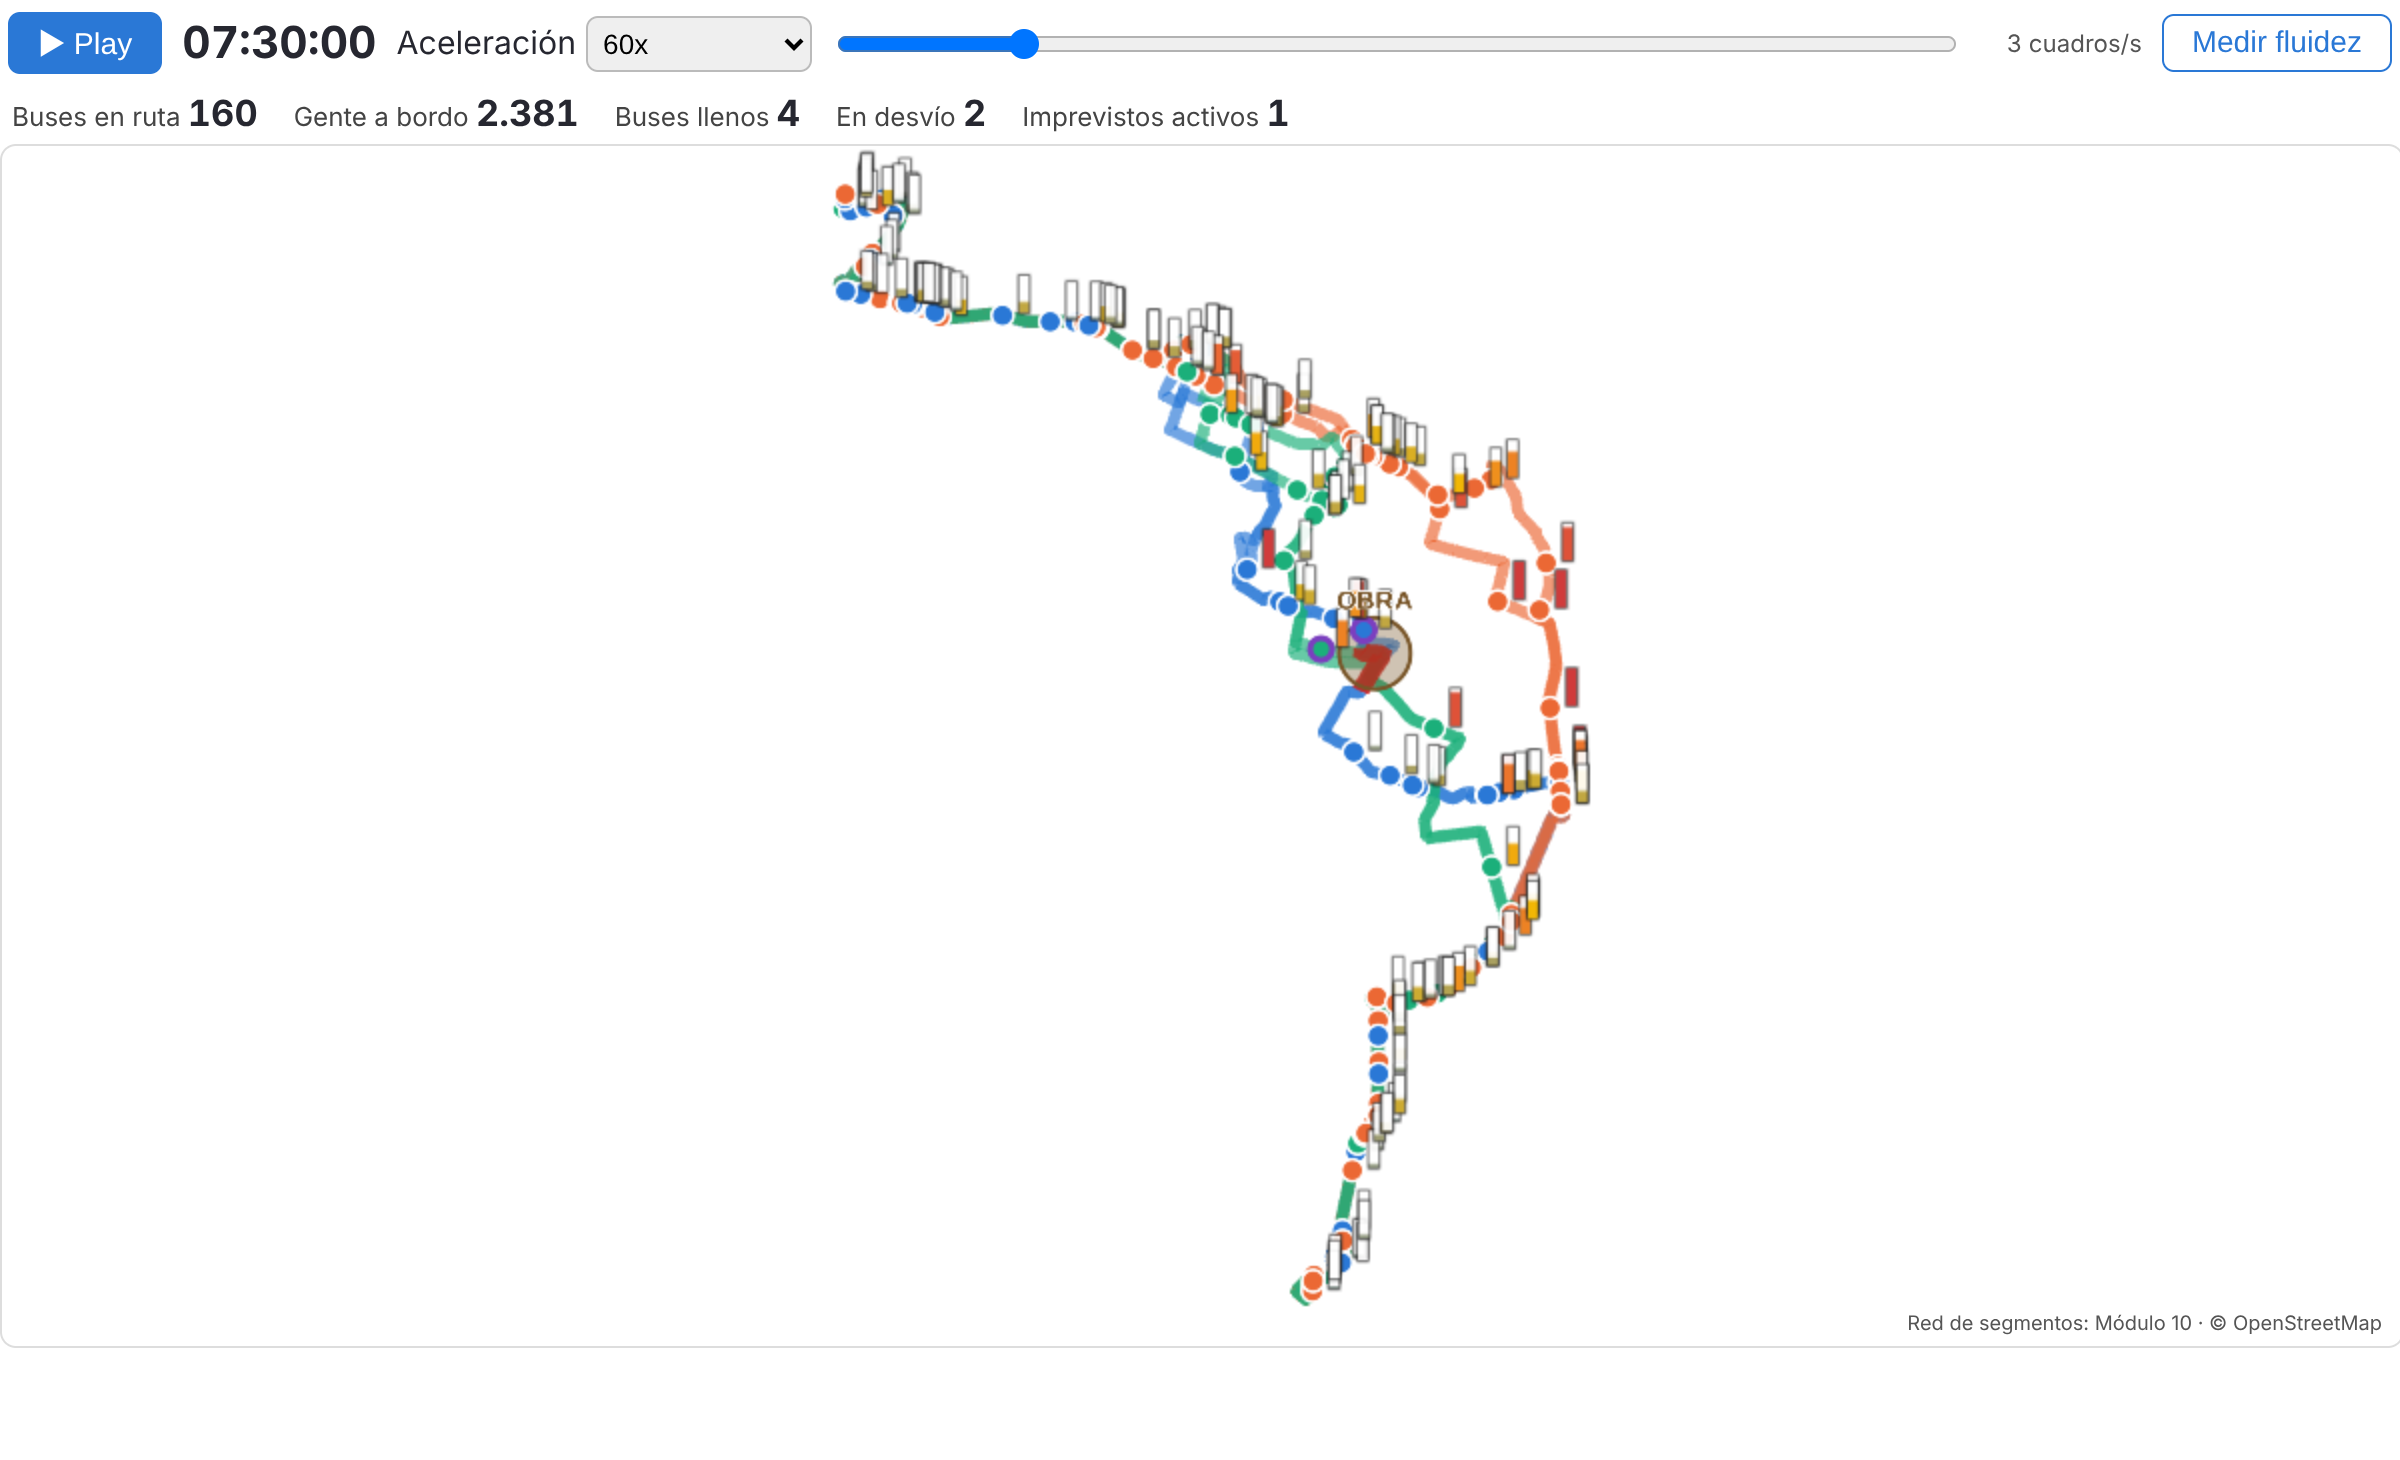

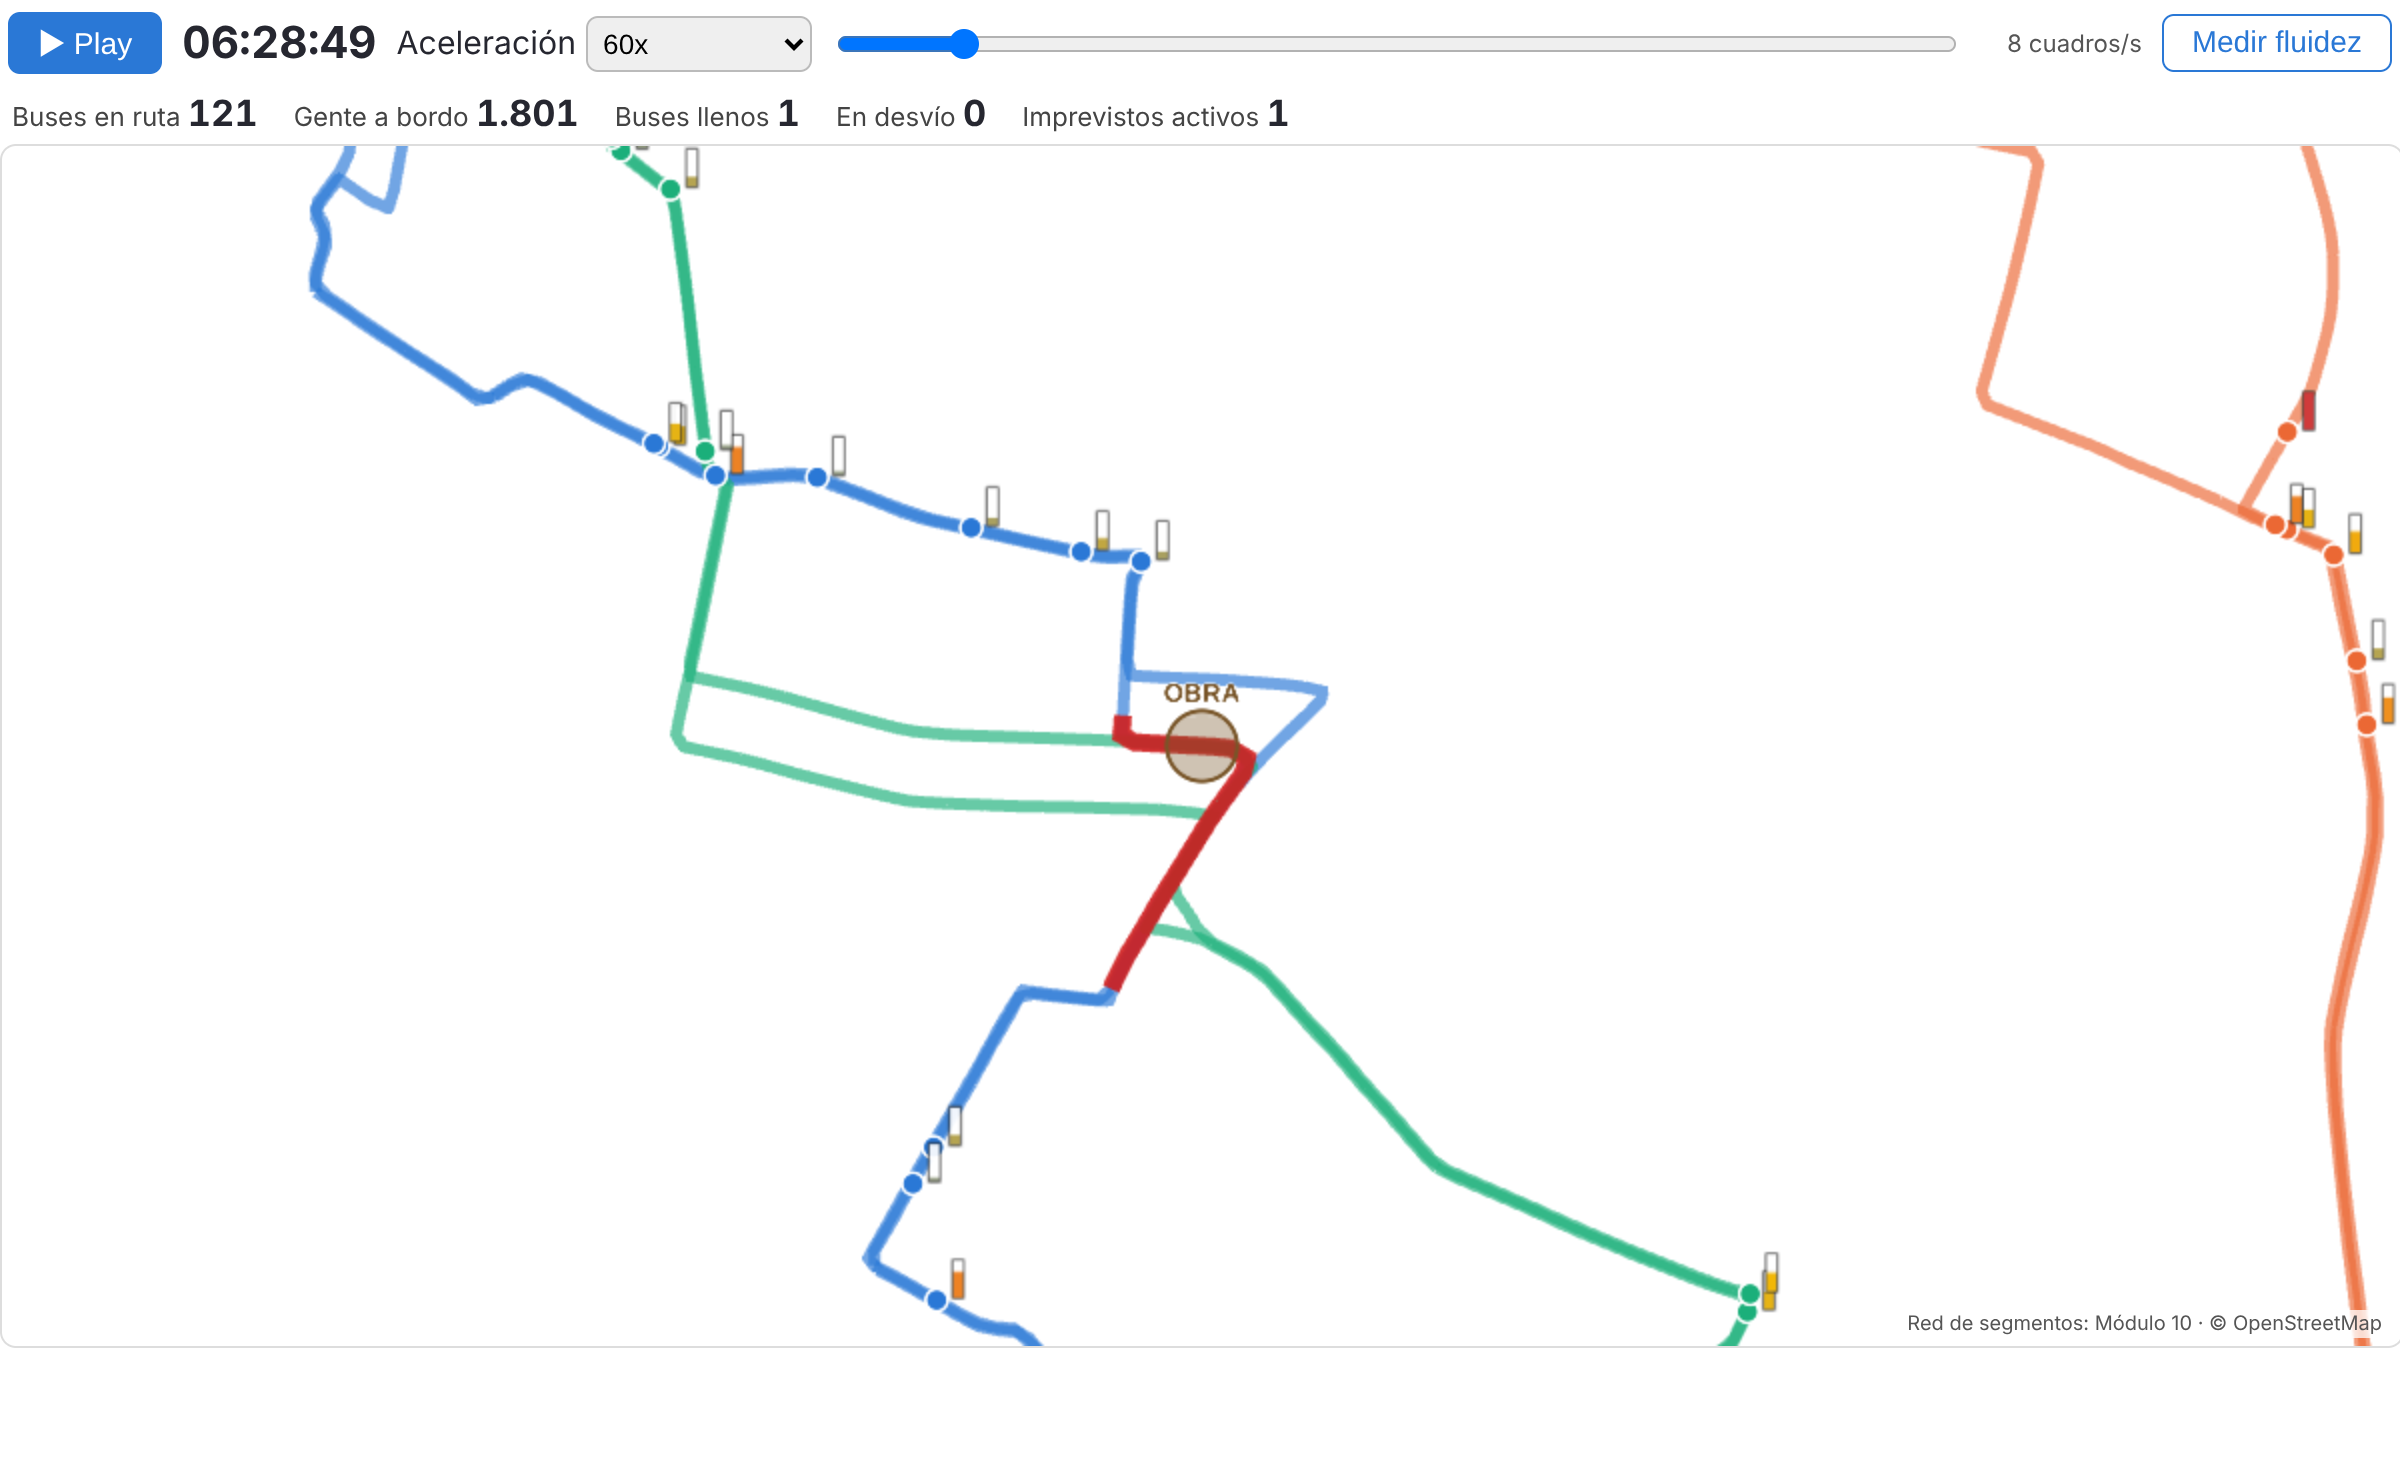

m13_6_pc_comparar.png


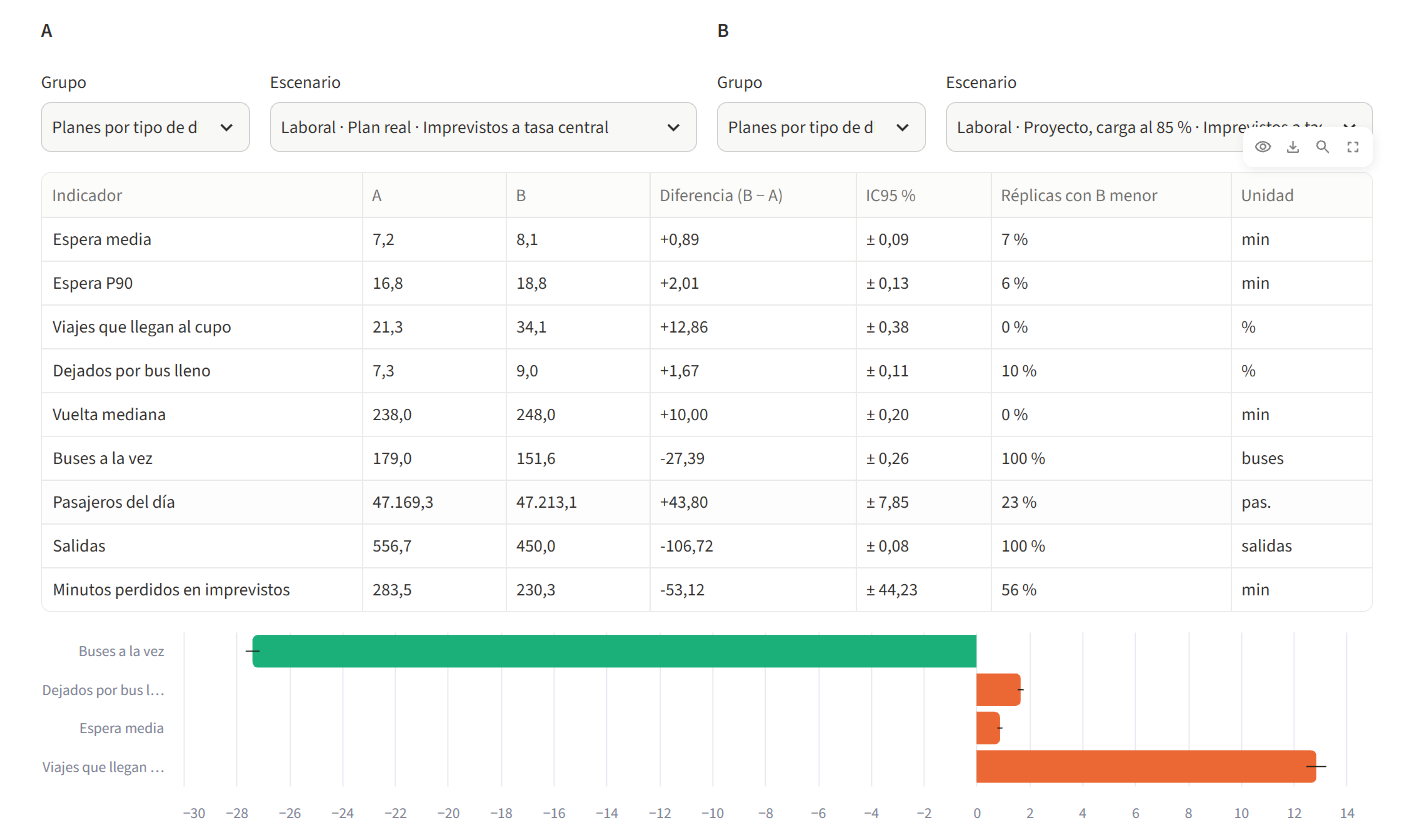

m13_6_pc_fluidez.png


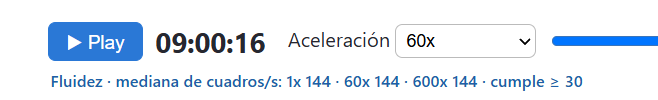

m13_6_pc_probar.png


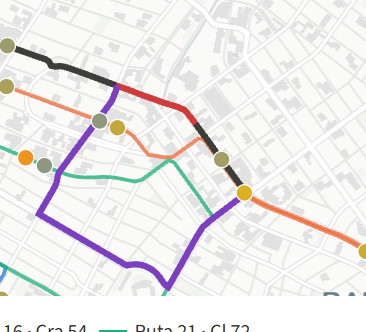

In [5]:
display(Image(str(FIG / "m13_6_animado.png"), width=900))
display(Image(str(FIG / "m13_6_animado_zoom.png"), width=900))
for f in sorted(FIG.glob("m13_6_pc_*.png")):
    print(f.name); display(Image(str(f), width=900))

**Conclusión 2 · El navegador dibuja lo mismo que la 13.5, sobre la vía, a la velocidad pedida**
- **Mismas posiciones que la 13.5** en 3 escenarios (132.011, 84.488 y 67.249 posiciones).
- **En cada minuto exacto,** los buses, la barra de cada uno (gente a bordo ÷ capacidad) y los contadores coinciden con la 13.5. A las 17:30 del laboral con el plan real: 145 buses, 2.636 personas a bordo y 13 buses llenos.
- **Entre un minuto y el siguiente,** el bus avanza sobre la geometría de su ruta: de 424 buses a mitad de minuto, el más lejano queda a 22,7 m del punto más cercano de la vía.
- **El reloj va a la velocidad elegida:** 1x → 0,97x, 60x → 60,00x y 600x → 600,00x. En pausa, el reloj queda quieto.
- **Imprevistos de la réplica representativa:** 196 en 53 de los 54 escenarios, más 85 varadas. Se generaron en el PC, y en los 54 escenarios sus pasos son iguales a los guardados.
  - En el laboral con el plan real hay 7 imprevistos (choques, obras y semáforos), de los que 3 cierran la vía con su tramo en rojo, y 3 varadas.
- **El mapa de fondo es el mismo estilo de CARTO de las otras pantallas** y no pide clave. Dentro de la app carga todas sus teselas, cada una con el «Referer» de la app (`tests_13_6.py` k). Sin el mapa de fondo, la página no pide nada a internet.

## 3 · En el PC: pruebas y fluidez

In [6]:
f = REV / "pruebas_pc_13_6.txt"
print(f.read_text(encoding="utf-8") if f.exists() else "Falta revisiones/pruebas_pc_13_6.txt")
fl = REV / "fluidez_pc_13_6.json"
if fl.exists():
    x = json.loads(fl.read_text(encoding="utf-8"))
    display(pd.DataFrame(x["fases"]).rename(columns={"velocidad": "aceleración (x)", "mediana": "mediana cuadros/s", "minimo": "mínimo", "muestras": "segundos medidos"}))
    print("Buses a la vez en la medición:", x["buses_max"], "· recuadro", x["ancho"], "×", x["alto"], "px ·", x.get("equipo", ""))

Pruebas del Módulo 13 · 2026-11-06T16:24:57
Sistema: Windows 11 · AMD64 · Python 3.12.0
Paquetes: numpy 2.5.2, pandas 3.0.5, scipy 1.18.0, pyarrow 25.0.1, simpy 4.1.1, networkx no instalado, matplotlib 3.11.1, streamlit 1.67.0, pydeck 0.9.3, altair 6.3.0, playwright no instalado

tests_13_1.py    12/12 PASS · 75 s · Python 3.12.0  (1.3 min; se esperaban 12 casos)
tests_13_2.py    12/12 PASS · 18 s · Python 3.12.0  (0.3 min; se esperaban 12 casos)
tests_13_3.py    14/14 PASS · 44 s · Python 3.12.0  (0.8 min; se esperaban 14 casos)
tests_13_4.py    13/13 PASS · 122 s · Python 3.12.0  (2.1 min; se esperaban 13 casos)
tests_13_4b.py   7/7 PASS · 5 s · Python 3.12.0  (0.1 min; se esperaban 7 casos)
tests_13_5.py    11/11 PASS · 304 s · Python 3.12.0  (5.1 min; se esperaban 11 casos)
tests_13_6.py    5/10 PASS · 5 OMITIDA · 14 s · Python 3.12.0  (0.3 min; se esperaban 10 casos)
    c. [OMITIDA] En cada minuto exacto el navegador dibuja los mismos buses, posiciones, barras y contadores que la

,aceleración (x),mediana cuadros/s,mínimo,segundos medidos
0,1,144,None,11
1,60,144,None,11
2,600,144,None,11


Buses a la vez en la medición: 172 · recuadro None × 600 px · PC de la Persona 3 (Windows 11, navegador del sistema)


**Conclusión 3 · Todo corre en el PC, y el mapa animado es fluido**
- **Las 69 pruebas de la 13.1 a la 13.5 pasan en Windows** (Python 3.12, 9,9 min). La primera corrida se cayó al imprimir por la codificación de Windows, sin fallar ningún cálculo; quedó corregido.
- **Una prueba de la 13.4 se ajustó:** la igualdad exacta con la validación solo se exige en Linux, donde se corrió la evaluación (O9 de la 13.4).
- **Fluidez en el navegador del PC:** mediana de 144 cuadros por segundo a 1x, 60x y 600x, con hasta 172 buses a la vez; el plan pide 30.
  - 144 es lo máximo que muestra esa pantalla.
  - En un equipo sin tarjeta de video (el entorno de trabajo de Claude) da 4–5.

## 4 · El paquete del zip

In [7]:
print(correr("paquete_13_6.py"))
print("\n".join(l for l in Path("lista_zip_13_6.txt").read_text(encoding="utf-8").splitlines() if l.startswith("#"))[:2500])
print(correr("revisar_paquete_13_6.py"))

617 archivos, 382,8 MB → lista_zip_13_6.txt

# Zip del Módulo 13 · modo completo · 617 archivos · 382,8 MB sin comprimir
# Por carpeta:
#   datos_13/montecarlo_13_4                     86,0 MB
#   datos_13/montecarlo_13_4b                    85,8 MB
#   datos_13/extraccion                          59,3 MB
#   datos_13/mejoras_13_4b                       45,0 MB
#   datos_13/parametros_v2                       27,2 MB
#   datos_13/parametros                          26,9 MB
#   datos_13/validacion_13_4                     15,4 MB
#   datos_13/simulacion_13_2                     11,6 MB
#   datos_13/simulacion_13_3                      9,8 MB
#   resultados_13                                 7,1 MB
#   (raíz)                                        5,8 MB
#   app                                           2,5 MB
#   src                                           0,2 MB
#   revisiones                                    0,2 MB
#   datos_13/ids_validacion_13_1.csv              0,2 MB
#   datos

617 archivos revisados (444 tablas con sus columnas): 0 hallazgos



**Conclusión 4 · Un zip sin datos sensibles, que se puede volver a armar**
- **Modo completo** (decisión de la Persona 3): 617 archivos y 383,8 MB sin comprimir. Con eso, las pruebas corren desde el zip.
- **Qué no va:** el gemelo, que se regenera en ~1 min con `preparar_gemelo_13_5.py`; `.env`; audios; `__pycache__`.
- **Revisión de datos sensibles:** 0 hallazgos en 617 archivos y 444 tablas (columnas personales, claves, contraseñas, audios).
- **Para instalar:** `requirements.txt` con versiones mínimas.
- **Para usarlo:** el LEEME tiene el orden de ejecución completo y lo que tarda cada paso.

## 5 · Informe y nota para el Módulo 14

In [8]:
print(correr("verificar_informe_13_6.py"))
v = pd.read_csv(REV / "verificar_informe_13_6.csv")
display(v.groupby(["tipo", "archivo"]).ok.agg(["sum", "size"]))

75/75 cifras verificadas (55 recalculadas, 20 trazadas) → verificar_informe_13_6.csv



sum  size
tipo archivo                       
R    datos                  1     1
     informe               22    22
     nota                  31    31
     pruebas_pc_13_6.txt    1     1
T    informe               20    20

**Conclusión 5 · El informe y la nota dicen lo mismo que los datos**
- **`INFORME_modulo13.md`** (2–3 páginas para el informe final) y **`NOTA_PARA_MODULO_14.md`**: 75 de 75 cifras verificadas.
  - 55 se recalculan de los datos guardados, después de comprobar el sha256 de las 109 salidas del Monte Carlo final.
  - 20 se trazan a las conclusiones ya verificadas de cada subfase.
- **La nota para el Módulo 14 explica:**
  - qué archivos usar y qué significa cada indicador;
  - cómo comparar dos planes réplica a réplica;
  - que la espera sirve para comparar, no como nivel;
  - lo que el simulador no hace: no elige el plan y no tiene una entrada para un plan propio.
- **El verificador ya sirvió:** encontró un redondeo mal hecho en la nota (sábado al 70 %: −16,5 buses, no −16,6), y se corrigió.

## Síntesis · Subfase 13.6
- **El Módulo 13 queda listo para entregar.** Se comparó con el plan completo y se cerraron las cinco brechas que la 13.5 había pasado por alto.
- **El gemelo hace lo que pide el plan:** mapa animado fluido (144 cuadros por segundo) con aceleración de 1x a 60x, barras de capacidad, contadores, e imprevistos y desvíos en el mapa. Se abre con `py -m streamlit run app/gemelo_digital.py`.
- **Todo corre en el PC:** 69 de 69 pruebas en Windows.
- **El paquete no lleva datos sensibles:** 0 hallazgos.
- **Las cifras del informe y de la nota están verificadas:** 75 de 75.
- **Lo que no cambia:** la validación sigue en 3 de 6 días, con el sesgo de la mañana laboral para después del Entregable 3. Las comparaciones entre planes son lo más sólido del módulo y son lo que recibe el Módulo 14.
- **El zip completo se arma en el PC:** `py paquete_13_6.py --zip ..\modulo13.zip` y luego `py revisar_paquete_13_6.py`.

---
# Parte 18 · Módulo 14 · Redespacho dinámico de flota (MILP)
*Notebook original: `modulo14/modulo_14_redespacho.ipynb`*

# SOBUSA · Módulo 14 — Redespacho dinámico de flota (MILP) en cabecera y La Playa

Notebook de ejecución del Módulo 14 (Entregable 2). Corre, sin internet ni APIs: la verificación de insumos, la demostración del pipeline 14.4 (arroyo de la calle 85, ruta 2), el reporte de la evaluación 14.3 a partir de sus 2.500 pares simulados (la corrida completa tarda horas y se hizo el 8-nov-2026, su salida está en `data/outputs/`) y las 39 pruebas del módulo. Documentación: `LEEME_modulo14.md` e `INFORME_modulo14.md`.

In [1]:
%matplotlib inline
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display, Markdown
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)
OUT = Path("data/outputs")

import os, subprocess, sys
def correr(*args, timeout=1800, ultimas=None):
    """Ejecuta un script del módulo con el mismo Python del notebook y muestra su salida."""
    env = {**os.environ, "PYTHONUTF8": "1", "PYTHONIOENCODING": "utf-8"}
    r = subprocess.run([sys.executable, *args], capture_output=True, text=True, encoding="utf-8", errors="replace",
                       env=env, timeout=timeout)
    salida = (r.stdout + ("\n" + r.stderr if r.returncode else "")).rstrip().splitlines()
    print("\n".join(salida if ultimas is None else salida[-ultimas:]))
    print(f"\n[código de salida {r.returncode}]")
    return r.returncode

## 1 · Verificación de los insumos de los Módulos 10–13 (sha256)

In [2]:
correr("verificar_insumos_14_3.py", ultimas=30)

Python 3.12.0 · C:\Users\samit\AppData\Local\Programs\Python\Python312\python.exe
  numpy     2.5.3
  pandas    2.3.3
  scipy     1.18.1
  pyarrow   25.0.1
  pydantic  2.14.3
  yaml      6.0.3
  simpy     4.1.1
  pulp      3.3.2
  psutil    7.2.2
  CBC resuelve un MILP de prueba: OK
Insumos: 49/49 presentes e idénticos al original
Memoria libre: 8.3 GB → caben 5 procesos · núcleos: 12
AVISO: la carpeta está en una nube sincronizada: muévala a una carpeta local (más rápido y estable)
TODO LISTO

[código de salida 0]


0

## 2 · Formulación (14.1): parámetros principales del MILP

In [3]:
cfg = yaml.safe_load(open("config/milp_config.yaml", encoding="utf-8"))
print("Secciones de milp_config.yaml:", list(cfg))
for k in ("solver", "horizonte", "redespacho", "zona_intermedia", "reglas", "pesos"):
    if k in cfg:
        print(f"\n[{k}]"); print(yaml.safe_dump(cfg[k], allow_unicode=True, sort_keys=False)[:900])

Secciones de milp_config.yaml: ['version', 'subfase', 'tiempo', 'franjas', 'multiplicador_headway_tipo_dia', 'headway_max_absoluto_min', 'rutas', 'cabeceras', 'zona_intermedia', 'permutacion', 'tramos', 'demanda', 'tiempos_ciclo', 'flota', 'objetivo', 'antileakage', 'arrastre', 'tramos_cerrados', 'factibilidad', 'redespacho', 'solver']

[solver]
nombre: PULP_CBC_CMD
tiempo_limite_s: 10
margen_s: 1.0
gap_relativo: 0.01
hilos: 1
msg: false


[redespacho]
salidas_totales: igual_plan


[zona_intermedia]
activa: true
id: la_playa
nombre: La Playa
descripcion: Punto lejano común de las rutas 2, 16 y 21 en el barrio La Playa (zona
  de redespacho intermedia)
primer_segmento_regreso:
  2: 68
  16: 62
  21: 64
segmentos_por_ruta:
  2: 135
  16: 123
  21: 128
desfase_id_regreso: 1000
descanso_llegada_min: 0.0
espera_max_min: 10.0
capacidad_espera: 4
costo_retener_bus_cop_ventana: 5000
pares:
- desde: 2
  hacia: 16
  max_por_horizonte: 5
  max_por_dia: 15
- desde: 2
  hacia: 21
  max_por_horizont

## 3 · Pipeline 14.4: redespacho para un instante (demo: arroyo de la calle 85, ruta 2)

In [4]:
correr("-m", "src.pipelines.redispatch_pipeline", "--fecha", "2025-02-27", "--hora", "07:00", "--demo", "--exportar", ultimas=40)
p = OUT / "pipeline_14_4"
res = json.load(open(p / "pipeline_2025-02-27_0700_resumen.json", encoding="utf-8"))
print(json.dumps(res, ensure_ascii=False, indent=1)[:3000])
display(pd.read_csv(p / "pipeline_2025-02-27_0700_ordenes.csv"))
display(pd.read_csv(p / "pipeline_2025-02-27_0700_alertas.csv"))

2025-02-27 07:00 · 1 evento(s) · 2 desvío(s) · 16.5 s
                                                                  accion
 Ruta 2 -> Ruta 16 | Buses a mover: 2 | Cabecera: La Playa | Hora: 07:00
Ruta 21 -> Ruta 16 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:00
 Ruta 2 -> Ruta 21 | Buses a mover: 2 | Cabecera: terminal | Hora: 07:15
 Ruta 2 -> Ruta 16 | Buses a mover: 3 | Cabecera: La Playa | Hora: 07:15
 Ruta 16 -> Ruta 2 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:30
 Ruta 21 -> Ruta 2 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:30
 Ruta 2 -> Ruta 21 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:45
                                                                        accion
Ruta 16 | Retener: 2 bus(es) | Cabecera: La Playa | Hasta: 07:15 | Hora: 07:00
Ruta 21 | Retener: 2 bus(es) | Cabecera: La Playa | Hasta: 07:15 | Hora: 07:00
Ruta 16 | Retener: 2 bus(es) | Cabecera: La Playa | Hasta: 07:45 | Hora: 07:30
 tramo  idruta sentido               segmentos

,timestamp,hora,cabecera_id,ruta_origen,ruta_destino,buses,inmediata,accion
0,2025-02-27 07:00:00,07:00,la_playa,2,16,2,True,Ruta 2 -> Ruta 16 | Buses a mover: 2 | Cabecera: La Playa | Hora: 07:00
1,2025-02-27 07:00:00,07:00,la_playa,21,16,1,True,Ruta 21 -> Ruta 16 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:00
2,2025-02-27 07:15:00,07:15,terminal,2,21,2,False,Ruta 2 -> Ruta 21 | Buses a mover: 2 | Cabecera: terminal | Hora: 07:15
3,2025-02-27 07:15:00,07:15,la_playa,2,16,3,False,Ruta 2 -> Ruta 16 | Buses a mover: 3 | Cabecera: La Playa | Hora: 07:15
4,2025-02-27 07:30:00,07:30,la_playa,16,2,1,False,Ruta 16 -> Ruta 2 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:30
5,2025-02-27 07:30:00,07:30,la_playa,21,2,1,False,Ruta 21 -> Ruta 2 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:30
6,2025-02-27 07:45:00,07:45,la_playa,2,21,1,False,Ruta 2 -> Ruta 21 | Buses a mover: 1 | Cabecera: La Playa | Hora: 07:45


,tramo,idruta,sentido,segmentos,pasajeros_espera_rigido,pasajeros_espera_milp,hora_pico,antes_de_corte,tramo_cerrado,critico
0,E16_79,16,regreso,79;80;81;82;83;84;85;86,67.6,67.5,07:45,False,False,True
1,E16_87,16,regreso,87;88;89;90;91;92;93;94,66.1,69.1,10:45,False,False,True
2,E2_23,2,ida,23;24;25;26;27;28;29;30,46.2,46.2,07:30,False,False,True
3,E21_19,21,ida,19;20;21;22;23;24;25;26,45.4,17.4,08:15,False,False,True
4,E21_27,21,ida,27;28;29;30;31;32;33;34,40.9,9.0,08:30,False,False,True
5,E16_95,16,regreso,95;96;97;98,22.5,22.5,07:30,False,False,False
6,E21_85,21,regreso,85;86;87;88;89;90;91;92,19.3,6.1,10:30,False,False,False
7,E2_89,2,regreso,89;90;91;92;93;94;95;96,13.0,13.0,08:45,False,False,False


## 4 · Evaluación 14.3: operación rígida vs MILP (2.500 pares, Wilcoxon + Holm)

,estrato,indicador,n_pares,media_rigido,media_milp,cambio_pct,p_holm,pct_pares_milp_mejor,conclusion
0,domingo_central,espera_cautiva_media_min,300,8.206,8.154,-0.638,0.052,55.667,sin diferencia significativa
1,domingo_central,dejados_bus_lleno,300,326.297,432.370,32.508,1.000,23.000,"MILP empeora (p < 0,05)"
2,domingo_central,km_vacio_total,300,1617.835,1747.733,8.029,1.000,9.000,"MILP empeora (p < 0,05)"
3,domingo_central,var_headway_min2,300,49.798,42.456,-14.744,0.000,89.667,"MILP mejora (p < 0,05)"
19,laboral_alta,espera_cautiva_media_min,500,8.218,7.617,-7.310,0.000,86.800,"MILP mejora (p < 0,05)"
20,laboral_alta,dejados_bus_lleno,500,3480.180,3293.836,-5.354,0.000,64.800,"MILP mejora (p < 0,05)"
21,laboral_alta,km_vacio_total,500,1762.165,1873.363,6.310,1.000,9.400,"MILP empeora (p < 0,05)"
22,laboral_alta,var_headway_min2,500,40.820,31.161,-23.662,0.000,97.800,"MILP mejora (p < 0,05)"
38,laboral_central,espera_cautiva_media_min,750,8.138,7.532,-7.445,0.000,86.800,"MILP mejora (p < 0,05)"
39,laboral_central,dejados_bus_lleno,750,3481.233,3321.869,-4.578,0.000,63.600,"MILP mejora (p < 0,05)"


Réplicas: 5,000 simulaciones ({'rigido': 2500, 'milp': 2500}) en 6 estratos


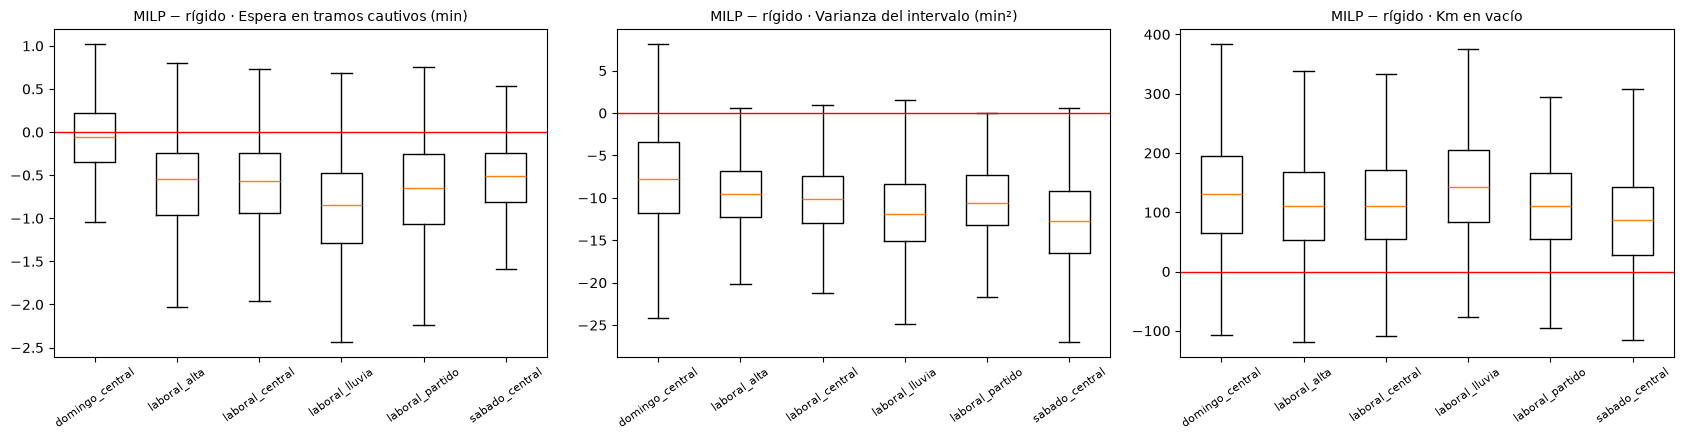

In [5]:
ev = pd.read_csv(OUT / "evaluacion_milp_vs_rigido.csv")
kpi = ev[ev.principal]
display(kpi[["estrato", "indicador", "n_pares", "media_rigido", "media_milp", "cambio_pct", "p_holm", "pct_pares_milp_mejor", "conclusion"]].round(3))
rep = pd.read_csv(OUT / "evaluacion_milp_vs_rigido_replicas.csv")
print(f"Réplicas: {len(rep):,} simulaciones ({rep.brazo.value_counts().to_dict()}) en {rep.estrato.nunique()} estratos")
ancho = rep.pivot_table(index=["estrato", "replica"], columns="brazo", values=["espera_cautiva_media_min", "var_headway_min2", "km_vacio_total"])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, (col, tit) in zip(ax, [("espera_cautiva_media_min", "Espera en tramos cautivos (min)"), ("var_headway_min2", "Varianza del intervalo (min²)"), ("km_vacio_total", "Km en vacío")]):
    dif = (ancho[(col, "milp")] - ancho[(col, "rigido")]).rename("dif").reset_index()
    est = sorted(dif.estrato.unique())
    a.boxplot([dif[dif.estrato == e].dif for e in est], tick_labels=est, showfliers=False); a.axhline(0, color="r", lw=1)
    a.set_title(f"MILP − rígido · {tit}", fontsize=10); a.tick_params(axis="x", rotation=35, labelsize=8)
plt.tight_layout(); plt.show()

## 5 · P&L y reporte final de la 14.3

In [6]:
pyl = pd.read_csv(OUT / "pyl_milp_vs_rigido.csv")
display(pyl[["estrato", "etiqueta", "unidad", "rigido", "milp", "dif_milp_menos_rigido", "ic95_inf", "ic95_sup", "milp_mejor", "ic95_excluye_cero"]].round(1))
correr("-m", "src.optimization.reporte_14_3", ultimas=20)
display(Markdown(open(OUT / "INFORME_14_3.md", encoding="utf-8").read()))

,estrato,etiqueta,unidad,rigido,milp,dif_milp_menos_rigido,ic95_inf,ic95_sup,milp_mejor,ic95_excluye_cero
0,domingo_central,Recaudo por tarifa,COP/día,78972121.7,78986329.7,14208.0,-10792.6,40639.3,True,False
1,domingo_central,Costo por km recorrido,COP/día,68132853.6,68188762.5,55908.9,46665.2,64868.5,False,True
2,domingo_central,"· del cual, km en vacío",COP/día,4853504.8,5243198.5,389693.7,358203.7,423366.6,False,True
3,domingo_central,Costo de permutar en cabecera,COP/día,0.0,483933.3,483933.3,476599.2,491669.2,False,True
4,domingo_central,Margen operativo,COP/día,10839268.0,10313633.8,-525634.2,-553210.5,-496758.2,False,True
...,...,...,...,...,...,...,...,...,...,...
58,todos,Margen operativo,COP/día,60160350.8,59416419.4,-743931.4,-756395.8,-731627.1,False,True
59,todos,Recaudo por km,COP/km,4767.5,4769.0,1.5,1.1,2.0,True,True
60,todos,Costo del tiempo de espera de los usuarios,COP/día,32623166.9,30531717.0,-2091449.8,-2169951.6,-2006883.8,True,True
61,todos,"· del cual, pasajeros cautivos",COP/día,18228377.5,16835471.2,-1392906.3,-1451336.1,-1330493.0,True,True


pyl: C:\Users\samit\OneDrive\Escritorio\UNIVERSIDAD\2026\2026-3\MACHINE LEARNING\04_Data_Challenge_SOBUSA\_e2\Sobusa\modulo14\data\outputs\pyl_milp_vs_rigido.csv
informe: C:\Users\samit\OneDrive\Escritorio\UNIVERSIDAD\2026\2026-3\MACHINE LEARNING\04_Data_Challenge_SOBUSA\_e2\Sobusa\modulo14\data\outputs\INFORME_14_3.md

[código de salida 0]


# Subfase 14.3 · Operación rígida vs. redespacho MILP (opción B)

**Pares completos:** 2.500 (5.000 simulaciones) en 6 estratos. **Computador:** DESKTOP-BR1OR1H · Windows 11 · Python 3.12.0.
**Huella de la versión:** `b16973cb1db3b0a6` · regla de salidas: `igual_plan` · creado 2026-11-08T11:56:45.

Cada par vive el mismo día simulado (misma semilla: mismas llegadas, factor de demanda, imprevistos y varadas); solo cambia la regla de control. Con la opción B las dos operaciones hacen el mismo número de salidas: el MILP decide a qué ruta va cada una y qué buses se permutan en la terminal.

## KPI principales (Wilcoxon pareado, Holm sobre los 4 KPI de cada estrato, α = 0,05)

| Estrato | KPI | Rígido | MILP | Cambio | p (Holm) | % pares MILP mejor | Conclusión |
|---|---|---:|---:|---:|---:|---:|---|
| domingo_central | Espera en tramos cautivos (min) | 8,21 | 8,15 | -0,6 % | 0.0516 | 55,7 % | sin diferencia significativa |
| domingo_central | Pasajeros dejados por bus lleno | 326,30 | 432,37 | 32,5 % | 1.0000 | 23,0 % | MILP empeora (p < 0,05) |
| domingo_central | Km en vacío (bus vacío + reposicionamiento) | 1.617,83 | 1.747,73 | 8,0 % | 1.0000 | 9,0 % | MILP empeora (p < 0,05) |
| domingo_central | Varianza del intervalo entre buses (min²) | 49,80 | 42,46 | -14,7 % | 0.0000 | 89,7 % | MILP mejora (p < 0,05) |
| laboral_alta | Espera en tramos cautivos (min) | 8,22 | 7,62 | -7,3 % | 0.0000 | 86,8 % | MILP mejora (p < 0,05) |
| laboral_alta | Pasajeros dejados por bus lleno | 3.480,18 | 3.293,84 | -5,4 % | 0.0000 | 64,8 % | MILP mejora (p < 0,05) |
| laboral_alta | Km en vacío (bus vacío + reposicionamiento) | 1.762,16 | 1.873,36 | 6,3 % | 1.0000 | 9,4 % | MILP empeora (p < 0,05) |
| laboral_alta | Varianza del intervalo entre buses (min²) | 40,82 | 31,16 | -23,7 % | 0.0000 | 97,8 % | MILP mejora (p < 0,05) |
| laboral_central | Espera en tramos cautivos (min) | 8,14 | 7,53 | -7,4 % | 0.0000 | 86,8 % | MILP mejora (p < 0,05) |
| laboral_central | Pasajeros dejados por bus lleno | 3.481,23 | 3.321,87 | -4,6 % | 0.0000 | 63,6 % | MILP mejora (p < 0,05) |
| laboral_central | Km en vacío (bus vacío + reposicionamiento) | 1.744,91 | 1.860,19 | 6,6 % | 1.0000 | 8,7 % | MILP empeora (p < 0,05) |
| laboral_central | Varianza del intervalo entre buses (min²) | 38,83 | 28,75 | -26,0 % | 0.0000 | 98,5 % | MILP mejora (p < 0,05) |
| laboral_lluvia | Espera en tramos cautivos (min) | 9,22 | 8,31 | -9,8 % | 0.0000 | 93,8 % | MILP mejora (p < 0,05) |
| laboral_lluvia | Pasajeros dejados por bus lleno | 4.238,06 | 4.111,70 | -3,0 % | 0.0000 | 61,3 % | MILP mejora (p < 0,05) |
| laboral_lluvia | Km en vacío (bus vacío + reposicionamiento) | 1.719,53 | 1.862,38 | 8,3 % | 1.0000 | 5,0 % | MILP empeora (p < 0,05) |
| laboral_lluvia | Varianza del intervalo entre buses (min²) | 46,68 | 34,69 | -25,7 % | 0.0000 | 99,5 % | MILP mejora (p < 0,05) |
| laboral_partido | Espera en tramos cautivos (min) | 8,19 | 7,46 | -8,9 % | 0.0000 | 90,0 % | MILP mejora (p < 0,05) |
| laboral_partido | Pasajeros dejados por bus lleno | 3.935,55 | 3.778,36 | -4,0 % | 0.0000 | 62,0 % | MILP mejora (p < 0,05) |
| laboral_partido | Km en vacío (bus vacío + reposicionamiento) | 1.796,02 | 1.905,13 | 6,1 % | 1.0000 | 8,4 % | MILP empeora (p < 0,05) |
| laboral_partido | Varianza del intervalo entre buses (min²) | 39,91 | 29,29 | -26,6 % | 0.0000 | 99,2 % | MILP mejora (p < 0,05) |
| sabado_central | Espera en tramos cautivos (min) | 8,12 | 7,59 | -6,5 % | 0.0000 | 89,0 % | MILP mejora (p < 0,05) |
| sabado_central | Pasajeros dejados por bus lleno | 1.820,70 | 1.578,57 | -13,3 % | 0.0000 | 78,3 % | MILP mejora (p < 0,05) |
| sabado_central | Km en vacío (bus vacío + reposicionamiento) | 1.572,89 | 1.656,83 | 5,3 % | 1.0000 | 15,7 % | MILP empeora (p < 0,05) |
| sabado_central | Varianza del intervalo entre buses (min²) | 49,32 | 36,29 | -26,4 % | 0.0000 | 99,0 % | MILP mejora (p < 0,05) |
| todos | Espera en tramos cautivos (min) | 8,34 | 7,75 | -7,1 % | 0.0000 | 84,8 % | MILP mejora (p < 0,05) |
| todos | Pasajeros dejados por bus lleno | 3.069,69 | 2.932,35 | -4,5 % | 0.0000 | 60,2 % | MILP mejora (p < 0,05) |
| todos | Km en vacío (bus vacío + reposicionamiento) | 1.713,52 | 1.829,77 | 6,8 % | 1.0000 | 9,1 % | MILP empeora (p < 0,05) |
| todos | Varianza del intervalo entre buses (min²) | 43,17 | 32,78 | -24,1 % | 0.0000 | 97,6 % | MILP mejora (p < 0,05) |

## P&L por día típico (COP; precios supuestos de `milp_config.yaml`)

| Estrato | Concepto | Rígido | MILP | MILP − rígido | IC95 % | ¿Mejora? |
|---|---|---:|---:|---:|---|---|
| domingo_central | Recaudo por tarifa | 78.972.122 | 78.986.330 | 14.208 | [-10.793; 40.639] | sí (no significativo) |
| domingo_central | Costo por km recorrido | 68.132.854 | 68.188.763 | 55.909 | [46.665; 64.869] | no |
| domingo_central | · del cual, km en vacío | 4.853.505 | 5.243.199 | 389.694 | [358.204; 423.367] | no |
| domingo_central | Costo de permutar en cabecera | 0 | 483.933 | 483.933 | [476.599; 491.669] | no |
| domingo_central | Margen operativo | 10.839.268 | 10.313.634 | -525.634 | [-553.210; -496.758] | no |
| domingo_central | Recaudo por km | 3.477,30 | 3.475,08 | -2,22 | [-3,44; -0,95] | no |
| domingo_central | Costo del tiempo de espera de los usuarios | 16.408.474 | 16.237.800 | -170.673 | [-257.065; -79.207] | sí |
| domingo_central | · del cual, pasajeros cautivos | 9.058.187 | 9.010.482 | -47.705 | [-99.043; 10.769] | sí (no significativo) |
| domingo_central | Beneficio neto (margen − costo de la espera) | -5.569.206 | -5.924.166 | -354.961 | [-445.414; -272.217] | no |
| laboral_alta | Recaudo por tarifa | 173.554.346 | 173.490.366 | -63.980 | [-85.271; -43.600] | no |
| laboral_alta | Costo por km recorrido | 105.425.985 | 105.371.806 | -54.180 | [-66.218; -43.503] | sí |
| laboral_alta | · del cual, km en vacío | 5.286.495 | 5.620.089 | 333.594 | [312.025; 356.409] | no |
| laboral_alta | Costo de permutar en cabecera | 0 | 818.180 | 818.180 | [812.718; 823.582] | no |
| laboral_alta | Margen operativo | 68.128.361 | 67.300.380 | -827.981 | [-853.450; -803.688] | no |
| laboral_alta | Recaudo por km | 4.938,81 | 4.939,45 | 0,64 | [-0,14; 1,41] | sí (no significativo) |
| laboral_alta | Costo del tiempo de espera de los usuarios | 34.185.788 | 32.034.555 | -2.151.233 | [-2.341.726; -1.962.096] | sí |
| laboral_alta | · del cual, pasajeros cautivos | 19.596.056 | 18.144.793 | -1.451.263 | [-1.596.474; -1.308.298] | sí |
| laboral_alta | Beneficio neto (margen − costo de la espera) | 33.942.573 | 35.265.825 | 1.323.252 | [1.133.834; 1.512.603] | sí |
| laboral_central | Recaudo por tarifa | 174.361.804 | 174.307.518 | -54.286 | [-71.389; -36.126] | no |
| laboral_central | Costo por km recorrido | 105.537.258 | 105.493.266 | -43.992 | [-52.416; -35.419] | sí |
| laboral_central | · del cual, km en vacío | 5.234.726 | 5.580.557 | 345.831 | [328.242; 364.069] | no |
| laboral_central | Costo de permutar en cabecera | 0 | 816.813 | 816.813 | [812.465; 820.880] | no |
| laboral_central | Margen operativo | 68.824.546 | 67.997.438 | -827.108 | [-846.705; -806.326] | no |
| laboral_central | Recaudo por km | 4.956,43 | 4.956,88 | 0,45 | [-0,16; 1,09] | sí (no significativo) |
| laboral_central | Costo del tiempo de espera de los usuarios | 34.020.603 | 31.801.129 | -2.219.474 | [-2.357.447; -2.078.962] | sí |
| laboral_central | · del cual, pasajeros cautivos | 19.489.890 | 18.012.399 | -1.477.491 | [-1.579.810; -1.372.982] | sí |
| laboral_central | Beneficio neto (margen − costo de la espera) | 34.803.943 | 36.196.309 | 1.392.366 | [1.256.196; 1.528.674] | sí |
| laboral_lluvia | Recaudo por tarifa | 175.429.284 | 175.372.100 | -57.184 | [-81.925; -31.883] | no |
| laboral_lluvia | Costo por km recorrido | 101.813.433 | 101.794.068 | -19.365 | [-44.323; -2.256] | sí |
| laboral_lluvia | · del cual, km en vacío | 5.158.585 | 5.587.138 | 428.553 | [401.160; 455.098] | no |
| laboral_lluvia | Costo de permutar en cabecera | 0 | 837.850 | 837.850 | [831.549; 844.351] | no |
| laboral_lluvia | Margen operativo | 73.615.851 | 72.740.183 | -875.669 | [-906.905; -842.924] | no |
| laboral_lluvia | Recaudo por km | 5.169,20 | 5.168,53 | -0,68 | [-1,92; 0,87] | no (no significativo) |
| laboral_lluvia | Costo del tiempo de espera de los usuarios | 38.515.646 | 35.483.952 | -3.031.695 | [-3.252.700; -2.824.196] | sí |
| laboral_lluvia | · del cual, pasajeros cautivos | 22.227.328 | 20.003.880 | -2.223.448 | [-2.385.356; -2.066.794] | sí |
| laboral_lluvia | Beneficio neto (margen − costo de la espera) | 35.100.205 | 37.256.231 | 2.156.026 | [1.950.324; 2.369.770] | sí |
| laboral_partido | Recaudo por tarifa | 177.600.429 | 177.702.801 | 102.372 | [73.643; 132.296] | sí |
| laboral_partido | Costo por km recorrido | 106.792.974 | 106.691.341 | -101.632 | [-115.870; -86.953] | sí |
| laboral_partido | · del cual, km en vacío | 5.388.073 | 5.715.399 | 327.325 | [296.860; 357.586] | no |
| laboral_partido | Costo de permutar en cabecera | 0 | 817.920 | 817.920 | [809.879; 825.721] | no |
| laboral_partido | Margen operativo | 70.807.456 | 70.193.539 | -613.916 | [-650.064; -577.876] | no |
| laboral_partido | Recaudo por km | 4.989,02 | 4.996,66 | 7,64 | [6,53; 8,72] | sí |
| laboral_partido | Costo del tiempo de espera de los usuarios | 40.774.051 | 38.283.785 | -2.490.266 | [-2.782.413; -2.195.819] | sí |
| laboral_partido | · del cual, pasajeros cautivos | 19.696.104 | 17.912.938 | -1.783.166 | [-2.000.349; -1.569.884] | sí |
| laboral_partido | Beneficio neto (margen − costo de la espera) | 30.033.405 | 31.909.755 | 1.876.350 | [1.580.575; 2.170.809] | sí |
| sabado_central | Recaudo por tarifa | 138.375.609 | 138.413.090 | 37.481 | [15.614; 59.657] | sí |
| sabado_central | Costo por km recorrido | 90.647.935 | 90.531.951 | -115.985 | [-129.563; -102.084] | sí |
| sabado_central | · del cual, km en vacío | 4.718.663 | 4.970.479 | 251.815 | [223.941; 280.258] | no |
| sabado_central | Costo de permutar en cabecera | 0 | 700.367 | 700.367 | [693.467; 707.202] | no |
| sabado_central | Margen operativo | 47.727.674 | 47.180.773 | -546.901 | [-576.115; -516.760] | no |
| sabado_central | Recaudo por km | 4.579,60 | 4.586,67 | 7,07 | [6,02; 8,12] | sí |
| sabado_central | Costo del tiempo de espera de los usuarios | 28.090.859 | 26.084.338 | -2.006.521 | [-2.158.459; -1.855.067] | sí |
| sabado_central | · del cual, pasajeros cautivos | 15.410.282 | 14.413.504 | -996.778 | [-1.099.024; -901.434] | sí |
| sabado_central | Beneficio neto (margen − costo de la espera) | 19.636.815 | 21.096.435 | 1.459.620 | [1.307.287; 1.611.686] | sí |
| todos | Recaudo por tarifa | 158.929.867 | 158.908.075 | -21.792 | [-31.394; -12.138] | no |
| todos | Costo por km recorrido | 98.769.516 | 98.725.012 | -44.504 | [-50.759; -38.770] | sí |
| todos | · del cual, km en vacío | 5.140.558 | 5.489.308 | 348.750 | [338.052; 359.195] | no |
| todos | Costo de permutar en cabecera | 0 | 766.644 | 766.644 | [761.679; 771.776] | no |
| todos | Margen operativo | 60.160.351 | 59.416.419 | -743.931 | [-756.396; -731.627] | no |
| todos | Recaudo por km | 4.767,49 | 4.769,00 | 1,50 | [1,08; 1,95] | sí |
| todos | Costo del tiempo de espera de los usuarios | 32.623.167 | 30.531.717 | -2.091.450 | [-2.169.952; -2.006.884] | sí |
| todos | · del cual, pasajeros cautivos | 18.228.377 | 16.835.471 | -1.392.906 | [-1.451.336; -1.330.493] | sí |
| todos | Beneficio neto (margen − costo de la espera) | 27.537.184 | 28.884.702 | 1.347.518 | [1.265.620; 1.422.900] | sí |

## Estado del solver en el brazo MILP

- Ventanas resueltas: 170.000; relajadas (faltan buses para el plan): 50; con plan de respaldo: 0; con límite de tiempo: 562.
- cbc.exe reiniciado por el vigía: 0 vez/veces.
- Tiempo del MILP por ventana: mediana de las medianas 0,86 s; máximo 11,60 s.
- Permutaciones por día: mediana 80, máximo 109.
- La Playa por día: cambios de ruta del regreso, mediana 79; buses retenidos, mediana 119 (espera máxima observada 10,0 min); buses que quedaron en La Playa al final del día: 0.

## Cómo leerlo

- Los KPI y el P&L salen del simulador del Módulo 13 (no del modelo del MILP). La espera y el cupo sirven para **comparar** operaciones, no como nivel absoluto (Módulo 13, `NOTA_PARA_MODULO_14.md` §5).
- En el simulador cada pasajero solo sube a su ruta: el beneficio de los corredores compartidos (tomar cualquier ruta que pase) no se mide aquí.
- Los precios del P&L son supuestos metodológicos; el recaudo usa la tarifa fija de 3.700 COP del Entregable 1.
- Una diferencia es significativa si p (Holm) < 0.05 (KPI) o si el IC95 % no incluye el cero (P&L).


## 6 · Pruebas del módulo (esperado: 20/20, 10/10 y 9/9)

In [7]:
correr("tests_14_2.py", ultimas=8)

r. [PASS] Retención en La Playa: buses que llegan pegados se retienen ≤ espera máxima (R16) y ≤ capacidad (R17) (1.1 s)
     4 buses de la 2 llegan juntos a La Playa entre 07:01 y 07:04 (el plan del regreso: 2 cada 15 min): retiene 1 hasta las 07:15; con capacidad 1 retiene 1; con capacidad 0, 0
s. [PASS] Cambio de ruta en La Playa: sin buses para el regreso de la 21 y sus cautivos esperando, se pasan buses del regreso de la 16 (0.9 s)
     6 buses cambian del regreso 16 al 21 en La Playa; cautiva atendida (horizonte) 72.0 % → 86.3 %
t. [PASS] Cierre de jornada: de 22:30 a 00:15 ningún bus se queda en La Playa y todos terminan libres en la terminal (2.9 s)
     20 buses: 10 llegan a La Playa entre 22:35 y 00:05 y siguen a la terminal (máx. 1 ventana de espera); a las 03:30 los 20 están libres en la terminal; 4 cambios de ruta

20/20 PASS · 23 s · Python 3.12.0 · PuLP 3.3.2

[código de salida 0]


0

In [8]:
correr("tests_14_3.py", ultimas=8)

h. [PASS] Brazo MILP (04:00–06:15, inicio del servicio y ráfagas del plan) sin red: todo óptimo, salidas = plan, flota conservada y KPI completos (5.0 s)
     estados {'optimo': 9}, MILP 0.38 s/ventana (máx 0.46), 0 permutaciones en la terminal y 0 cambios de ruta y 2 retenciones en La Playa (máx. 10.0 min), salidas = plan en cada ventana (opción B), espera cautiva 7.24 min
i. [PASS] Reporte P&L y tabla final: cuentas correctas, IC95 % pareado e informe en Markdown (réplicas sintéticas) (0.1 s)
     recaudo = pasajeros × 3,700; permutar 10 buses = 100,000 COP/día; espera de cautivos −450,000 COP/día (IC95 % sin cero); informe con KPI y P&L
j. [PASS] La Playa sin órdenes ≡ rígido: la vuelta con la parada de despacho da el mismo día, número por número (2.5 s)
     557 viajes, 51,443 pasajeros y 70,748 pasos idénticos con la parada de La Playa (sin órdenes)

10/10 PASS · 37 s · Python 3.12.0

[código de salida 0]


0

In [9]:
correr("tests_14_4.py", ultimas=8)

g. [PASS] App de Streamlit sin red: carga, calcula el redespacho y muestra alertas, acciones y badge sin errores (21.2 s)
     4 métricas, 5 tarjetas rojas, 5 tablas
h. [PASS] Integración con la app del Módulo 13: el panel carga aunque esa app ya tenga su propio paquete «src» (1.1 s)
     src del Módulo 13 intacto; panel cargado como m14src.ui.components.redispatch_panel
i. [PASS] Pestaña dentro de una app que ya cargó src.gemelo del Módulo 13 (como gemelo_13_5.py con el diff): calcula sin errores (21.8 s)
     proceso limpio con src del Módulo 13 (modulo13): pestaña calculada sin red, 5 tarjetas rojas; diff de 7 líneas

9/9 PASS · 62 s · Python 3.12.0

[código de salida 0]


0